In [2]:
# ============================================================
# CELLULE 1 — CONFIGURATION DE L'ENVIRONNEMENT
# ============================================================
# Projet : Detection d'anomalies dans le trafic reseau
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Reproduire le protocole experimental du DDAE
# pour permettre une comparaison equitable.
# ============================================================

# ------------------------------------------------------------
# 1. Bibliotheques systeme
# ------------------------------------------------------------

import os
import sys
import json
import platform
import warnings

from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 2. Manipulation des donnees
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from scipy import sparse

# ------------------------------------------------------------
# 3. Visualisation scientifique
# ------------------------------------------------------------

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# ------------------------------------------------------------
# 4. Separation des donnees
# ------------------------------------------------------------

from sklearn.model_selection import (
    GroupShuffleSplit
)

# ------------------------------------------------------------
# 5. Pretraitement
# ------------------------------------------------------------

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# 6. Modele Isolation Forest
# ------------------------------------------------------------

from sklearn.ensemble import IsolationForest

# ------------------------------------------------------------
# 7. Metriques d'evaluation
# ------------------------------------------------------------

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 8. Sauvegarde des objets
# ------------------------------------------------------------

import joblib

# ------------------------------------------------------------
# 9. Reproductibilite
# ------------------------------------------------------------

IF_RANDOM_STATE = 42

np.random.seed(IF_RANDOM_STATE)

# ------------------------------------------------------------
# 10. Configuration de la police scientifique
# ------------------------------------------------------------

available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

if "Consolas" in available_fonts:

    IF_SCIENTIFIC_FONT = "Consolas"

else:

    IF_SCIENTIFIC_FONT = "DejaVu Sans Mono"

    warnings.warn(
        "Police Consolas indisponible. "
        "Utilisation de DejaVu Sans Mono."
    )

# ------------------------------------------------------------
# 11. Configuration graphique
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid"
)

plt.rcParams.update({
    "font.family": IF_SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

# ------------------------------------------------------------
# 12. Repertoire principal du projet
# ------------------------------------------------------------

# Le notebook Isolation Forest doit de preference
# etre place dans le meme dossier de travail
# que le notebook DDAE et le dataset.

IF_PROJECT_DIR = Path.cwd().resolve()

# ------------------------------------------------------------
# 13. Repertoires des resultats
# ------------------------------------------------------------

IF_RESULTS_DIR = (
    IF_PROJECT_DIR / "resultats_Isolation_Forest"
)

IF_FIGURES_DIR = (
    IF_RESULTS_DIR / "figures"
)

IF_MODELS_DIR = (
    IF_RESULTS_DIR / "modeles"
)

IF_TABLES_DIR = (
    IF_RESULTS_DIR / "tableaux"
)

IF_ARTIFACTS_DIR = (
    IF_RESULTS_DIR / "artefacts"
)

IF_SCORES_DIR = (
    IF_RESULTS_DIR / "scores"
)

IF_AUDIT_DIR = (
    IF_RESULTS_DIR / "audit"
)

IF_DIRECTORIES = [
    IF_RESULTS_DIR,
    IF_FIGURES_DIR,
    IF_MODELS_DIR,
    IF_TABLES_DIR,
    IF_ARTIFACTS_DIR,
    IF_SCORES_DIR,
    IF_AUDIT_DIR
]

for directory in IF_DIRECTORIES:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 14. Identification de l'environnement
# ------------------------------------------------------------

IF_ENVIRONMENT_INFO = {
    "modele": "Isolation Forest",
    "dataset": "UNSW-NB15",
    "protocole": "one-class",
    "comparaison_prevue": "DDAE",
    "random_state": IF_RANDOM_STATE,
    "python_version": sys.version.split()[0],
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": __import__(
        "sklearn"
    ).__version__,
    "matplotlib_version": matplotlib.__version__,
    "platforme": platform.platform(),
    "police": IF_SCIENTIFIC_FONT,
    "repertoire_projet": str(IF_PROJECT_DIR),
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

# ------------------------------------------------------------
# 15. Sauvegarde de la configuration
# ------------------------------------------------------------

IF_CONFIG_PATH = (
    IF_ARTIFACTS_DIR /
    "configuration_environnement_IF.json"
)

with open(
    IF_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_ENVIRONMENT_INFO,
        file,
        indent=4,
        ensure_ascii=False
    )



In [4]:

# ============================================================
# CELLULE 2 — CHARGEMENT ET VERIFICATION DU DATASET
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15_1.csv
# Protocole : One-Class Learning
#
# Objectif :
# Charger le dataset brut sans modification
# et preparer la reutilisation du protocole DDAE.
# ============================================================

import hashlib
import json
import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# 1. Verification de la cellule precedente
# ------------------------------------------------------------

if not globals().get("IF_ENVIRONMENT_READY", False):
    raise RuntimeError(
        "L'environnement n'est pas initialise. "
        "Executer d'abord la cellule 1."
    )

# ------------------------------------------------------------
# 2. Chemin du dataset
# ------------------------------------------------------------

IF_DATASET_NAME = "UNSW-NB15_1.csv"

IF_DATASET_PATH = (
    IF_PROJECT_DIR / IF_DATASET_NAME
)

print("\nChemin du dataset :")
print(IF_DATASET_PATH)

# ------------------------------------------------------------
# 3. Verification de l'existence
# ------------------------------------------------------------

if not IF_DATASET_PATH.is_file():

    raise FileNotFoundError(
        f"\nDataset introuvable : {IF_DATASET_PATH}\n"
        "Placer UNSW-NB15_1.csv dans le meme "
        "dossier que le notebook, ou corriger "
        "IF_DATASET_PATH."
    )

print("\nDataset trouve : OUI")

# ------------------------------------------------------------
# 4. Calcul de l'empreinte du fichier
# ------------------------------------------------------------

def if_sha256_file(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):

            sha256.update(block)

    return sha256.hexdigest()


IF_DATASET_SHA256 = if_sha256_file(
    IF_DATASET_PATH
)

IF_DATASET_SIZE_MB = (
    IF_DATASET_PATH.stat().st_size
    / (1024 ** 2)
)

print("\nINFORMATIONS DU FICHIER")

print(
    "Taille :",
    f"{IF_DATASET_SIZE_MB:.2f} Mo"
)

print(
    "SHA-256 :",
    IF_DATASET_SHA256
)

# ------------------------------------------------------------
# 5. Chargement des donnees brutes
# ------------------------------------------------------------

# Le fichier UNSW-NB15_1.csv utilise dans
# notre protocole ne contient pas d'en-tete.
#
# header=None conserve la premiere ligne
# comme une observation.
#
# Aucun tri, filtre ou melange n'est realise.

IF_df = pd.read_csv(
    IF_DATASET_PATH,
    header=None,
    low_memory=False
)

# ------------------------------------------------------------
# 6. Dimensions du dataset
# ------------------------------------------------------------

IF_N_ROWS, IF_N_COLUMNS = IF_df.shape

print("\nDIMENSIONS DU DATASET")

print(
    "Nombre d'observations :",
    f"{IF_N_ROWS:,}"
)

print(
    "Nombre de colonnes :",
    IF_N_COLUMNS
)

# ------------------------------------------------------------
# 7. Verification de la structure attendue
# ------------------------------------------------------------

IF_EXPECTED_COLUMNS = 49

if IF_N_COLUMNS != IF_EXPECTED_COLUMNS:

    raise ValueError(
        f"Structure inattendue : {IF_N_COLUMNS} colonnes. "
        f"Attendu : {IF_EXPECTED_COLUMNS}."
    )

print("\nStructure de 49 colonnes : VALIDEE")

# ------------------------------------------------------------
# 8. Verification du nombre d'observations
# ------------------------------------------------------------

# Pour le fichier utilise precedemment
# dans le notebook DDAE, nous avions :
#
# 700001 observations.
#
# Ce controle confirme la taille attendue,
# mais ne suffit pas a prouver que les deux
# fichiers sont strictement identiques.

IF_EXPECTED_ROWS = 700001

IF_ROW_COUNT_MATCH = (
    IF_N_ROWS == IF_EXPECTED_ROWS
)

print("\nCOMPARAISON AVEC LE DDAE")

print(
    "Observations attendues :",
    f"{IF_EXPECTED_ROWS:,}"
)

print(
    "Observations obtenues :",
    f"{IF_N_ROWS:,}"
)

if not IF_ROW_COUNT_MATCH:

    raise ValueError(
        "Le nombre de lignes differe de celui "
        "utilise dans le protocole DDAE. "
        "Ne pas reutiliser les indices avant "
        "d'avoir identifie cette difference."
    )

print("Nombre de lignes coherent : OUI")

# ------------------------------------------------------------
# 9. Verification de l'index des observations
# ------------------------------------------------------------

IF_OBSERVATION_IDS = np.arange(
    IF_N_ROWS,
    dtype=np.int64
)

assert np.array_equal(
    IF_df.index.to_numpy(),
    IF_OBSERVATION_IDS
)

print("\nOrdre initial des observations : CONSERVE")

# ------------------------------------------------------------
# 10. Apercu des premieres observations
# ------------------------------------------------------------

print("\nCINQ PREMIERES OBSERVATIONS")

display(
    IF_df.head(5)
)

# ------------------------------------------------------------
# 11. Apercu des dernieres observations
# ------------------------------------------------------------

print("\nCINQ DERNIERES OBSERVATIONS")

display(
    IF_df.tail(5)
)

# ------------------------------------------------------------
# 12. Types des colonnes
# ------------------------------------------------------------

IF_TYPES_TABLE = pd.DataFrame({
    "Colonne": IF_df.columns.astype(str),
    "Type": IF_df.dtypes.astype(str).values,
    "Valeurs_non_nulles": (
        IF_df.notna().sum().values
    )
})

print("\nTYPES DES COLONNES")

display(
    IF_TYPES_TABLE
)

# ------------------------------------------------------------
# 13. Verification des identifiants
# ------------------------------------------------------------

assert len(IF_OBSERVATION_IDS) == IF_N_ROWS

assert IF_OBSERVATION_IDS[0] == 0

assert IF_OBSERVATION_IDS[-1] == IF_N_ROWS - 1

assert IF_df.shape == (
    IF_EXPECTED_ROWS,
    IF_EXPECTED_COLUMNS
)

# ------------------------------------------------------------
# 14. Rapport de chargement
# ------------------------------------------------------------

IF_LOADING_REPORT = {
    "dataset": IF_DATASET_NAME,
    "dataset_path": str(IF_DATASET_PATH),
    "sha256": IF_DATASET_SHA256,
    "size_mb": float(IF_DATASET_SIZE_MB),
    "nombre_observations": int(IF_N_ROWS),
    "nombre_colonnes": int(IF_N_COLUMNS),
    "observations_attendues": int(
        IF_EXPECTED_ROWS
    ),
    "colonnes_attendues": int(
        IF_EXPECTED_COLUMNS
    ),
    "header": None,
    "ordre_original_conserve": True,
    "donnees_modifiees": False,
    "pretraitement_effectue": False,
    "separation_effectuee": False,
    "identite_avec_dataset_DDAE_verifiee": False
}

IF_LOADING_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_chargement_dataset_IF.json"
)

with open(
    IF_LOADING_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_LOADING_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 15. Export des types de colonnes
# ------------------------------------------------------------

IF_TYPES_TABLE.to_csv(
    IF_TABLES_DIR /
    "types_colonnes_dataset_IF.csv",
    index=False,
    encoding="utf-8-sig"
)


Chemin du dataset :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\UNSW-NB15_1.csv

Dataset trouve : OUI

INFORMATIONS DU FICHIER
Taille : 161.15 Mo
SHA-256 : 7d851bbeabd27894ce39c8e78835c73341fc946652fb7743b9eff193b55eb511

DIMENSIONS DU DATASET
Nombre d'observations : 700,001
Nombre de colonnes : 49

Structure de 49 colonnes : VALIDEE

COMPARAISON AVEC LE DDAE
Observations attendues : 700,001
Observations obtenues : 700,001
Nombre de lignes coherent : OUI

Ordre initial des observations : CONSERVE

CINQ PREMIERES OBSERVATIONS


,0,1,2,3,4,5,6,7,8,9,...,39,40,41,42,43,44,45,46,47,48
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0



CINQ DERNIERES OBSERVATIONS


,0,1,2,3,4,5,6,7,8,9,...,39,40,41,42,43,44,45,46,47,48
699996,59.166.0.8,12520,149.171.126.6,31010,tcp,FIN,0.020383,320,1874,31,...,0,8,20,7,5,1,1,4,NaN,0
699997,59.166.0.0,18895,149.171.126.9,80,tcp,FIN,1.402957,19410,1087890,31,...,0,1,1,2,7,2,2,2,NaN,0
699998,59.166.0.0,30103,149.171.126.5,5190,tcp,FIN,0.007108,2158,2464,31,...,0,13,13,6,7,2,1,2,NaN,0
699999,59.166.0.6,30388,149.171.126.5,111,udp,CON,0.004435,568,304,31,...,0,10,13,6,5,1,1,3,NaN,0
700000,59.166.0.0,6055,149.171.126.5,54145,tcp,FIN,0.072974,4238,60788,31,...,0,13,13,6,7,1,1,2,NaN,0



TYPES DES COLONNES


,Colonne,Type,Valeurs_non_nulles
0,0,object,700001
1,1,object,700001
2,2,object,700001
3,3,object,700001
4,4,object,700001
5,5,object,700001
6,6,float64,700001
7,7,int64,700001
8,8,int64,700001
9,9,int64,700001


In [7]:
# ============================================================
# CELLULE 3 — NOMMAGE ET IDENTIFICATION DES VARIABLES
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15_1.csv
# Protocole : One-Class Learning
#
# Objectif :
# Reproduire exactement le nommage des colonnes
# du notebook DDAE.
#
# Aucun encodage, aucune normalisation.
# ============================================================

import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("IF_DATASET_LOADED", False):
    raise RuntimeError(
        "Le dataset n'a pas ete charge. "
        "Executer la cellule 2."
    )

if IF_df.shape[1] != 49:
    raise ValueError(
        "Le dataset doit contenir exactement 49 colonnes."
    )

# ------------------------------------------------------------
# 2. Definition des noms des colonnes
# ------------------------------------------------------------

# Liste identique a celle du notebook DDAE.
# L'ordre des variables doit etre conserve.

IF_COLUMN_NAMES = [
    "srcip",
    "sport",
    "dstip",
    "dsport",
    "proto",
    "state",
    "dur",
    "sbytes",
    "dbytes",
    "sttl",
    "dttl",
    "sloss",
    "dloss",
    "service",
    "Sload",
    "Dload",
    "Spkts",
    "Dpkts",
    "swin",
    "dwin",
    "stcpb",
    "dtcpb",
    "smeansz",
    "dmeansz",
    "trans_depth",
    "res_bdy_len",
    "Sjit",
    "Djit",
    "Stime",
    "Ltime",
    "Sintpkt",
    "Dintpkt",
    "tcprtt",
    "synack",
    "ackdat",
    "is_sm_ips_ports",
    "ct_state_ttl",
    "ct_flw_http_mthd",
    "is_ftp_login",
    "ct_ftp_cmd",
    "ct_srv_src",
    "ct_srv_dst",
    "ct_dst_ltm",
    "ct_src_ltm",
    "ct_src_dport_ltm",
    "ct_dst_sport_ltm",
    "ct_dst_src_ltm",
    "attack_cat",
    "label"
]

# ------------------------------------------------------------
# 3. Verification de la liste
# ------------------------------------------------------------

assert len(IF_COLUMN_NAMES) == 49

assert len(set(IF_COLUMN_NAMES)) == 49

assert IF_COLUMN_NAMES[-2] == "attack_cat"

assert IF_COLUMN_NAMES[-1] == "label"

# ------------------------------------------------------------
# 4. Attribution des noms
# ------------------------------------------------------------

# Les valeurs restent inchangees.
# Seuls les noms des colonnes sont attribues.

IF_df.columns = IF_COLUMN_NAMES

print("\nNommage des colonnes : TERMINE")

print("Nombre de colonnes :", len(IF_df.columns))

# ------------------------------------------------------------
# 5. Identification de la cible
# ------------------------------------------------------------

IF_TARGET_COLUMN = "label"

IF_ATTACK_COLUMN = "attack_cat"

IF_EXCLUDED_COLUMNS = [
    IF_TARGET_COLUMN,
    IF_ATTACK_COLUMN
]

# ------------------------------------------------------------
# 6. Caracteristiques candidates
# ------------------------------------------------------------

IF_FEATURE_COLUMNS = [
    column
    for column in IF_df.columns
    if column not in IF_EXCLUDED_COLUMNS
]

assert len(IF_FEATURE_COLUMNS) == 47

assert IF_TARGET_COLUMN not in IF_FEATURE_COLUMNS

assert IF_ATTACK_COLUMN not in IF_FEATURE_COLUMNS

print("\nVARIABLES IDENTIFIEES")

print(
    "Variable cible :",
    IF_TARGET_COLUMN
)

print(
    "Categorie d'attaque :",
    IF_ATTACK_COLUMN
)

print(
    "Caracteristiques candidates :",
    len(IF_FEATURE_COLUMNS)
)

# ------------------------------------------------------------
# 7. Verification des classes
# ------------------------------------------------------------

# Cette operation n'entraine pas le modele.
# Elle sert uniquement au controle du dataset.

IF_LABEL_VALUES = pd.to_numeric(
    IF_df[IF_TARGET_COLUMN],
    errors="coerce"
)

IF_UNIQUE_LABELS = set(
    IF_LABEL_VALUES.dropna().unique()
)

if IF_LABEL_VALUES.isna().any():
    raise ValueError(
        "La colonne label contient des valeurs "
        "manquantes ou non numeriques."
    )

if IF_UNIQUE_LABELS != {0, 1}:
    raise ValueError(
        "La colonne label doit contenir "
        "les classes 0 et 1."
    )

print("\nClasses detectees :", sorted(IF_UNIQUE_LABELS))

print("0 = Trafic normal")
print("1 = Attaque")

# ------------------------------------------------------------
# 8. Dictionnaire des variables
# ------------------------------------------------------------

IF_VARIABLE_DICTIONARY = pd.DataFrame({
    "Position": np.arange(
        1,
        len(IF_COLUMN_NAMES) + 1
    ),
    "Variable": IF_COLUMN_NAMES,
    "Type_brut": [
        str(IF_df[column].dtype)
        for column in IF_COLUMN_NAMES
    ],
    "Role": [
        (
            "Cible binaire — evaluation uniquement"
            if column == IF_TARGET_COLUMN
            else (
                "Categorie d'attaque — analyse uniquement"
                if column == IF_ATTACK_COLUMN
                else "Caracteristique candidate"
            )
        )
        for column in IF_COLUMN_NAMES
    ]
})

print("\nDICTIONNAIRE DES VARIABLES")

display(IF_VARIABLE_DICTIONARY)

# ------------------------------------------------------------
# 9. Apercu du dataset
# ------------------------------------------------------------

print("\nAPERÇU DES DONNEES NOMMEES")

display(IF_df.head(5))

# ------------------------------------------------------------
# 10. Controle de la structure
# ------------------------------------------------------------

assert IF_df.shape == (
    IF_N_ROWS,
    IF_N_COLUMNS
)

assert IF_df.columns.tolist() == IF_COLUMN_NAMES

assert np.array_equal(
    IF_df.index.to_numpy(),
    IF_OBSERVATION_IDS
)


# ------------------------------------------------------------
# 11. Export du dictionnaire
# ------------------------------------------------------------

IF_VARIABLE_DICTIONARY_PATH = (
    IF_TABLES_DIR /
    "dictionnaire_variables_UNSW_NB15_IF.csv"
)

IF_VARIABLE_DICTIONARY.to_csv(
    IF_VARIABLE_DICTIONARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. Rapport de tracabilite
# ------------------------------------------------------------

IF_COLUMNS_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "nombre_observations": int(IF_N_ROWS),
    "nombre_colonnes": int(IF_N_COLUMNS),
    "noms_colonnes": IF_COLUMN_NAMES,
    "variable_cible": IF_TARGET_COLUMN,
    "variable_categorie_attaque": IF_ATTACK_COLUMN,
    "colonnes_exclues": IF_EXCLUDED_COLUMNS,
    "nombre_caracteristiques_candidates": int(
        len(IF_FEATURE_COLUMNS)
    ),
    "caracteristiques_candidates": IF_FEATURE_COLUMNS,
    "ordre_observations_conserve": True,
    "encodage_effectue": False,
    "normalisation_effectuee": False,
    "selection_finale_effectuee": False,
    "compatibilite_artefacts_DDAE": "a_verifier"
}

IF_COLUMNS_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_variables_UNSW_NB15_IF.json"
)

with open(
    IF_COLUMNS_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        IF_COLUMNS_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )


Nommage des colonnes : TERMINE
Nombre de colonnes : 49

VARIABLES IDENTIFIEES
Variable cible : label
Categorie d'attaque : attack_cat
Caracteristiques candidates : 47

Classes detectees : [0, 1]
0 = Trafic normal
1 = Attaque

DICTIONNAIRE DES VARIABLES


,Position,Variable,Type_brut,Role
0,1,srcip,object,Caracteristique candidate
1,2,sport,object,Caracteristique candidate
2,3,dstip,object,Caracteristique candidate
3,4,dsport,object,Caracteristique candidate
4,5,proto,object,Caracteristique candidate
5,6,state,object,Caracteristique candidate
6,7,dur,float64,Caracteristique candidate
7,8,sbytes,int64,Caracteristique candidate
8,9,dbytes,int64,Caracteristique candidate
9,10,sttl,int64,Caracteristique candidate



APERÇU DES DONNEES NOMMEES


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


In [9]:

# ============================================================
# CELLULE 4 — AUDIT DE LA QUALITE DES DONNEES BRUTES
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15_1.csv
# Protocole : One-Class Learning
#
# Objectif :
# Examiner la qualite des caracteristiques brutes
# sans modifier le dataset.
#
# Aucun nettoyage, encodage ou ajustement.
# ============================================================

import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("IF_COLUMNS_READY", False):
    raise RuntimeError(
        "Les colonnes ne sont pas identifiees. "
        "Executer d'abord la cellule 3."
    )

if IF_df.shape[1] != 49:
    raise ValueError(
        "Structure du dataset incorrecte."
    )

if IF_df.columns.tolist() != IF_COLUMN_NAMES:
    raise ValueError(
        "L'ordre des colonnes a ete modifie."
    )

# ------------------------------------------------------------
# 2. Memorisation de la structure initiale
# ------------------------------------------------------------

IF_AUDIT_INITIAL_SHAPE = IF_df.shape

IF_AUDIT_INITIAL_IDS = (
    IF_df.index.to_numpy(copy=True)
)

print("\nSTRUCTURE DU DATASET")

print(
    "Observations :",
    f"{IF_df.shape[0]:,}"
)

print(
    "Colonnes :",
    IF_df.shape[1]
)

print(
    "Caracteristiques candidates :",
    len(IF_FEATURE_COLUMNS)
)

# ------------------------------------------------------------
# 3. Types de caracteristiques
# ------------------------------------------------------------

# Ces variables correspondent au protocole
# du DDAE et seront reutilisees ulterieurement.

IF_CATEGORICAL_FEATURES = [
    "proto",
    "state",
    "service"
]

IF_DDAE_EXCLUDED_FEATURES = [
    "srcip",
    "dstip",
    "Stime",
    "Ltime"
]

IF_SELECTED_FEATURES_EXPECTED = [
    column
    for column in IF_FEATURE_COLUMNS
    if column not in IF_DDAE_EXCLUDED_FEATURES
]

IF_NUMERIC_FEATURES_EXPECTED = [
    column
    for column in IF_SELECTED_FEATURES_EXPECTED
    if column not in IF_CATEGORICAL_FEATURES
]

assert len(IF_FEATURE_COLUMNS) == 47
assert len(IF_SELECTED_FEATURES_EXPECTED) == 43
assert len(IF_NUMERIC_FEATURES_EXPECTED) == 40



# ------------------------------------------------------------
# 4. Configuration des valeurs assimilables
#    a des donnees manquantes
# ------------------------------------------------------------

IF_MISSING_STRINGS = {
    "",
    "nan",
    "none",
    "null",
    "na",
    "n/a"
}

# Cette liste est utilisee pour l'audit
# uniquement. Aucun remplacement n'est effectue.

# ------------------------------------------------------------
# 5. Analyse colonne par colonne
# ------------------------------------------------------------

IF_AUDIT_ROWS = []

for column in IF_df.columns:

    series = IF_df[column]

    missing_count = int(
        series.isna().sum()
    )

    # Normalisation temporaire pour inspection.
    # La colonne originale n'est pas modifiee.

    text_values = (
        series.astype("string")
        .str.strip()
    )

    normalized_text = text_values.str.lower()

    missing_text_mask = (
        normalized_text.isin(
            IF_MISSING_STRINGS
        )
    ).fillna(False)

    missing_text_count = int(
        missing_text_mask.sum()
    )

    unique_count = int(
        series.nunique(
            dropna=True
        )
    )

    # Audit de conversion numerique uniquement
    # pour les colonnes attendues comme numeriques.

    numeric_conversion_failures = 0
    infinite_count = 0

    if column in IF_NUMERIC_FEATURES_EXPECTED:

        # Reprise du principe utilise dans le DDAE :
        # convertir les textes numeriques en nombres.
        # Aucune transformation n'est conservee.

        numeric_values = pd.to_numeric(
            text_values,
            errors="coerce"
        )

        numeric_array = numeric_values.to_numpy(
            dtype=np.float64,
            na_value=np.nan
        )

        non_missing_text = (
            series.notna()
            & ~missing_text_mask
        )

        numeric_conversion_failures = int(
            (
                non_missing_text
                & numeric_values.isna()
            ).sum()
        )

        infinite_count = int(
            np.isinf(
                numeric_array
            ).sum()
        )

    non_missing_count = int(
        series.notna().sum()
    )

    missing_total = int(
        (
            series.isna()
            | missing_text_mask
        ).sum()
    )

    missing_percentage = (
        100 * missing_total / len(series)
    )

    unique_percentage = (
        100 * unique_count / len(series)
    )

    is_constant = (
        unique_count <= 1
    )

    IF_AUDIT_ROWS.append({
        "Variable": column,
        "Type_brut": str(series.dtype),
        "Valeurs_non_nulles": non_missing_count,
        "Valeurs_manquantes_NaN": missing_count,
        "Valeurs_manquantes_textuelles": missing_text_count,
        "Valeurs_manquantes_total": missing_total,
        "Taux_manquant_pct": missing_percentage,
        "Valeurs_infinies": infinite_count,
        "Echecs_conversion_numerique": (
            numeric_conversion_failures
        ),
        "Valeurs_distinctes": unique_count,
        "Taux_valeurs_distinctes_pct": unique_percentage,
        "Variable_constante": is_constant,
        "Role": (
            "Cible"
            if column == IF_TARGET_COLUMN
            else (
                "Categorie_attaque"
                if column == IF_ATTACK_COLUMN
                else (
                    "Exclue_protocole_DDAE"
                    if column in IF_DDAE_EXCLUDED_FEATURES
                    else "Caracteristique_selectionnee"
                )
            )
        )
    })

# ------------------------------------------------------------
# 6. Construction du tableau d'audit
# ------------------------------------------------------------

IF_QUALITY_REPORT = pd.DataFrame(
    IF_AUDIT_ROWS
)

print("\nRAPPORT DE QUALITE DES 49 COLONNES")

display(
    IF_QUALITY_REPORT
)

# ------------------------------------------------------------
# 7. Colonnes contenant des valeurs manquantes
# ------------------------------------------------------------

IF_MISSING_COLUMNS_TABLE = (
    IF_QUALITY_REPORT.loc[
        IF_QUALITY_REPORT[
            "Valeurs_manquantes_total"
        ] > 0
    ]
    .sort_values(
        "Valeurs_manquantes_total",
        ascending=False
    )
    .copy()
)

print("\nCOLONNES AVEC VALEURS MANQUANTES")

if IF_MISSING_COLUMNS_TABLE.empty:

    print(
        "Aucune valeur manquante detectee "
        "selon les criteres d'audit."
    )

else:

    display(
        IF_MISSING_COLUMNS_TABLE[
            [
                "Variable",
                "Valeurs_manquantes_total",
                "Taux_manquant_pct"
            ]
        ]
    )

# ------------------------------------------------------------
# 8. Colonnes avec valeurs infinies
# ------------------------------------------------------------

IF_INFINITE_COLUMNS_TABLE = (
    IF_QUALITY_REPORT.loc[
        IF_QUALITY_REPORT["Valeurs_infinies"] > 0
    ]
    .copy()
)

print("\nCOLONNES NUMERIQUES AVEC VALEURS INFINIES")

if IF_INFINITE_COLUMNS_TABLE.empty:

    print("Aucune valeur infinie detectee.")

else:

    display(
        IF_INFINITE_COLUMNS_TABLE[
            [
                "Variable",
                "Valeurs_infinies"
            ]
        ]
    )

# ------------------------------------------------------------
# 9. Echecs de conversion numerique
# ------------------------------------------------------------

IF_CONVERSION_ERRORS_TABLE = (
    IF_QUALITY_REPORT.loc[
        IF_QUALITY_REPORT[
            "Echecs_conversion_numerique"
        ] > 0
    ]
    .copy()
)

print("\nCARACTERISTIQUES AVEC ECHECS DE CONVERSION")

if IF_CONVERSION_ERRORS_TABLE.empty:

    print(
        "Aucun echec de conversion numerique "
        "sur les 40 caracteristiques attendues."
    )

else:

    display(
        IF_CONVERSION_ERRORS_TABLE[
            [
                "Variable",
                "Echecs_conversion_numerique"
            ]
        ]
    )

# ------------------------------------------------------------
# 10. Variables constantes
# ------------------------------------------------------------

IF_CONSTANT_COLUMNS_TABLE = (
    IF_QUALITY_REPORT.loc[
        IF_QUALITY_REPORT["Variable_constante"]
    ]
    .copy()
)

print("\nVARIABLES CONSTANTES")

if IF_CONSTANT_COLUMNS_TABLE.empty:

    print("Aucune variable constante detectee.")

else:

    display(
        IF_CONSTANT_COLUMNS_TABLE[
            [
                "Variable",
                "Valeurs_distinctes",
                "Role"
            ]
        ]
    )

# ------------------------------------------------------------
# 11. Variables presque constantes
# ------------------------------------------------------------

# Critere descriptif :
# la modalite la plus frequente couvre
# au moins 99 % des observations non manquantes.
#
# Aucune caracteristique n'est exclue.

IF_NEAR_CONSTANT_ROWS = []

for column in IF_FEATURE_COLUMNS:

    value_frequencies = (
        IF_df[column]
        .value_counts(
            dropna=True,
            normalize=True
        )
    )

    dominant_frequency = (
        float(value_frequencies.iloc[0])
        if not value_frequencies.empty
        else np.nan
    )

    if (
        np.isfinite(dominant_frequency)
        and dominant_frequency >= 0.99
    ):

        IF_NEAR_CONSTANT_ROWS.append({
            "Variable": column,
            "Frequence_dominante_pct": (
                dominant_frequency * 100
            ),
            "Exclue_automatiquement": False
        })

IF_NEAR_CONSTANT_TABLE = pd.DataFrame(
    IF_NEAR_CONSTANT_ROWS,
    columns=[
        "Variable",
        "Frequence_dominante_pct",
        "Exclue_automatiquement"
    ]
)

print("\nVARIABLES PRESQUE CONSTANTES (>= 99 %)")

if IF_NEAR_CONSTANT_TABLE.empty:

    print(
        "Aucune variable presque constante "
        "selon le critere retenu."
    )

else:

    display(IF_NEAR_CONSTANT_TABLE)

# ------------------------------------------------------------
# 12. Synthese globale
# ------------------------------------------------------------

IF_QUALITY_SUMMARY = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "nombre_observations": int(IF_df.shape[0]),
    "nombre_colonnes": int(IF_df.shape[1]),
    "caracteristiques_candidates": int(
        len(IF_FEATURE_COLUMNS)
    ),
    "caracteristiques_brutes_selectionnees": int(
        len(IF_SELECTED_FEATURES_EXPECTED)
    ),
    "caracteristiques_numeriques": int(
        len(IF_NUMERIC_FEATURES_EXPECTED)
    ),
    "caracteristiques_categorielles": int(
        len(IF_CATEGORICAL_FEATURES)
    ),
    "colonnes_avec_valeurs_manquantes": int(
        len(IF_MISSING_COLUMNS_TABLE)
    ),
    "colonnes_avec_valeurs_infinies": int(
        len(IF_INFINITE_COLUMNS_TABLE)
    ),
    "colonnes_avec_echecs_numeriques": int(
        len(IF_CONVERSION_ERRORS_TABLE)
    ),
    "variables_constantes": int(
        len(IF_CONSTANT_COLUMNS_TABLE)
    ),
    "variables_presque_constantes": int(
        len(IF_NEAR_CONSTANT_TABLE)
    ),
    "donnees_supprimees": False,
    "donnees_modifiees": False,
    "nettoyage_effectue": False,
    "encodage_effectue": False,
    "normalisation_effectuee": False
}

print("\nSYNTHESE DE L'AUDIT")

for key, value in IF_QUALITY_SUMMARY.items():

    print(f"{key} : {value}")

# ------------------------------------------------------------
# 13. Verification de la structure initiale
# ------------------------------------------------------------

assert IF_df.shape == IF_AUDIT_INITIAL_SHAPE

assert np.array_equal(
    IF_df.index.to_numpy(),
    IF_AUDIT_INITIAL_IDS
)

assert IF_df.columns.tolist() == IF_COLUMN_NAMES

assert len(IF_QUALITY_REPORT) == 49

print("\nStructure et ordre des donnees : CONSERVES")

# ------------------------------------------------------------
# 14. Export des tableaux
# ------------------------------------------------------------

IF_QUALITY_REPORT_PATH = (
    IF_TABLES_DIR /
    "audit_qualite_variables_IF.csv"
)

IF_QUALITY_REPORT.to_csv(
    IF_QUALITY_REPORT_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_MISSING_COLUMNS_TABLE.to_csv(
    IF_TABLES_DIR /
    "variables_manquantes_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_INFINITE_COLUMNS_TABLE.to_csv(
    IF_TABLES_DIR /
    "variables_infinies_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_CONVERSION_ERRORS_TABLE.to_csv(
    IF_TABLES_DIR /
    "erreurs_conversion_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_CONSTANT_COLUMNS_TABLE.to_csv(
    IF_TABLES_DIR /
    "variables_constantes_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_NEAR_CONSTANT_TABLE.to_csv(
    IF_TABLES_DIR /
    "variables_presque_constantes_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. Export du rapport JSON
# ------------------------------------------------------------

IF_QUALITY_SUMMARY_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_qualite_donnees_IF.json"
)

with open(
    IF_QUALITY_SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_QUALITY_SUMMARY,
        file,
        indent=4,
        ensure_ascii=False
    )


STRUCTURE DU DATASET
Observations : 700,001
Colonnes : 49
Caracteristiques candidates : 47

RAPPORT DE QUALITE DES 49 COLONNES


,Variable,Type_brut,Valeurs_non_nulles,Valeurs_manquantes_NaN,Valeurs_manquantes_textuelles,Valeurs_manquantes_total,Taux_manquant_pct,Valeurs_infinies,Echecs_conversion_numerique,Valeurs_distinctes,Taux_valeurs_distinctes_pct,Variable_constante,Role
0,srcip,object,700001,0,0,0,0.000000,0,0,40,0.005714,False,Exclue_protocole_DDAE
1,sport,object,700001,0,0,0,0.000000,0,8,64541,9.220130,False,Caracteristique_selectionnee
2,dstip,object,700001,0,0,0,0.000000,0,0,44,0.006286,False,Exclue_protocole_DDAE
3,dsport,object,700001,0,0,0,0.000000,0,63,62222,8.888844,False,Caracteristique_selectionnee
4,proto,object,700001,0,0,0,0.000000,0,0,135,0.019286,False,Caracteristique_selectionnee
5,state,object,700001,0,0,0,0.000000,0,0,16,0.002286,False,Caracteristique_selectionnee
6,dur,float64,700001,0,0,0,0.000000,0,0,243828,34.832522,False,Caracteristique_selectionnee
7,sbytes,int64,700001,0,0,0,0.000000,0,0,7948,1.135427,False,Caracteristique_selectionnee
8,dbytes,int64,700001,0,0,0,0.000000,0,0,11898,1.699712,False,Caracteristique_selectionnee
9,sttl,int64,700001,0,0,0,0.000000,0,0,13,0.001857,False,Caracteristique_selectionnee



COLONNES AVEC VALEURS MANQUANTES


,Variable,Valeurs_manquantes_total,Taux_manquant_pct
47,attack_cat,677786,96.826433



COLONNES NUMERIQUES AVEC VALEURS INFINIES
Aucune valeur infinie detectee.

CARACTERISTIQUES AVEC ECHECS DE CONVERSION


,Variable,Echecs_conversion_numerique
1,sport,8
3,dsport,63



VARIABLES CONSTANTES
Aucune variable constante detectee.

VARIABLES PRESQUE CONSTANTES (>= 99 %)


,Variable,Frequence_dominante_pct,Exclue_automatiquement
0,is_sm_ips_ports,99.750143,False



SYNTHESE DE L'AUDIT
dataset : UNSW-NB15_1.csv
modele : Isolation Forest
nombre_observations : 700001
nombre_colonnes : 49
caracteristiques_candidates : 47
caracteristiques_brutes_selectionnees : 43
caracteristiques_numeriques : 40
caracteristiques_categorielles : 3
colonnes_avec_valeurs_manquantes : 1
colonnes_avec_valeurs_infinies : 0
colonnes_avec_echecs_numeriques : 2
variables_constantes : 0
variables_presque_constantes : 1
donnees_supprimees : False
donnees_modifiees : False
nettoyage_effectue : False
encodage_effectue : False
normalisation_effectuee : False

Structure et ordre des donnees : CONSERVES



TABLEAU DE DISTRIBUTION


,Classe,Type_trafic,Effectif,Pourcentage
0,0,Trafic normal,"677,786",96.8264 %
1,1,Attaques,"22,215",3.1736 %


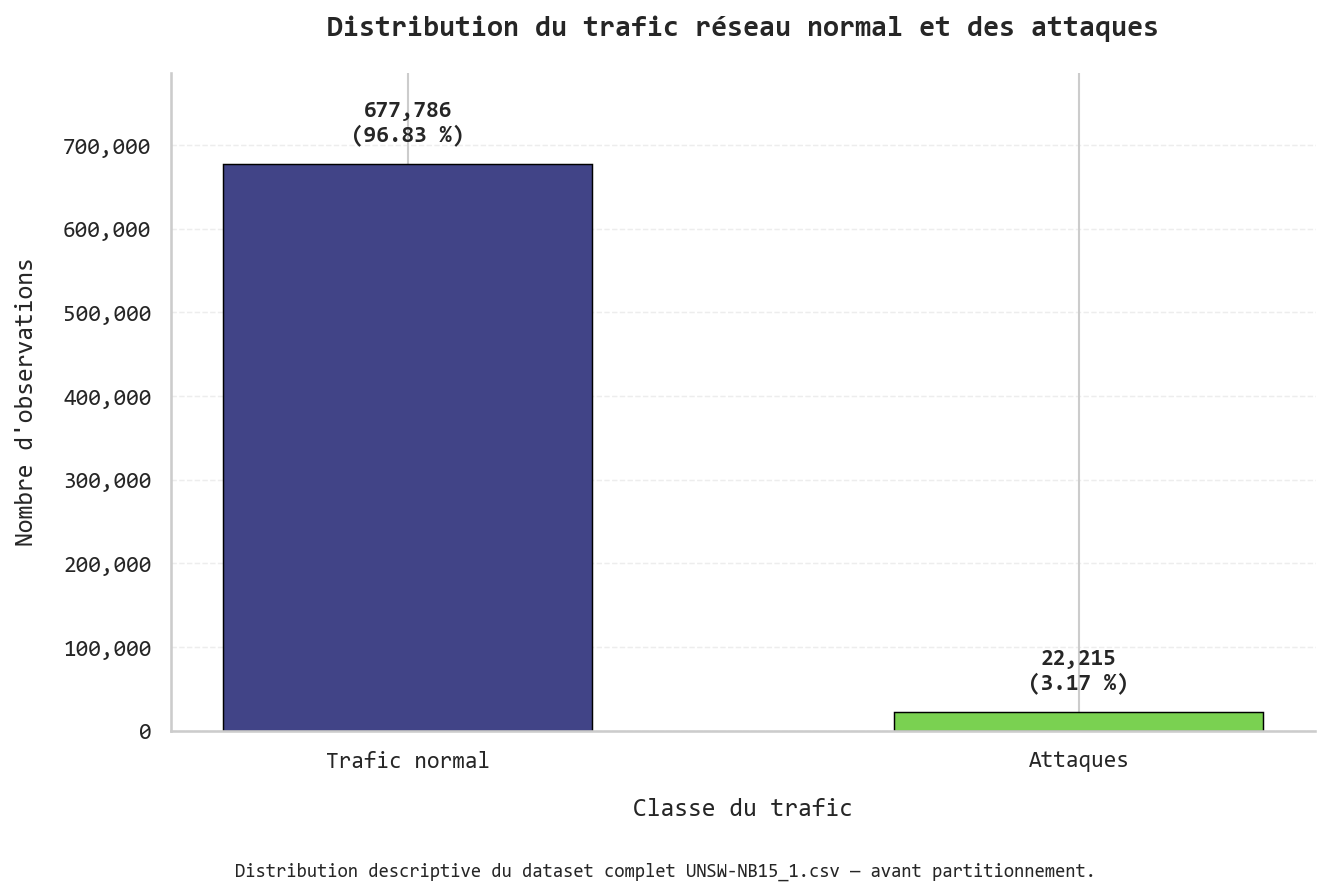

In [11]:

# ============================================================
# CELLULE 5 — DISTRIBUTION DU TRAFIC NORMAL ET DES ATTAQUES
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15_1.csv
# Protocole : One-Class Learning
#
# Objectif :
# Analyser la distribution de la variable cible
# sans modifier le dataset.
#
# 0 = Trafic normal
# 1 = Attaque
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns



# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("IF_DATA_QUALITY_AUDITED", False):
    raise RuntimeError(
        "L'audit de qualite n'est pas termine. "
        "Executer d'abord la cellule 4."
    )

if not globals().get("IF_COLUMNS_READY", False):
    raise RuntimeError(
        "Les colonnes du dataset ne sont pas identifiees."
    )

if IF_TARGET_COLUMN not in IF_df.columns:
    raise ValueError(
        "La variable cible 'label' est absente."
    )

# ------------------------------------------------------------
# 2. Extraction de la variable cible
# ------------------------------------------------------------

# Conversion temporaire pour analyse.
# Le dataframe original n'est pas modifie.

IF_y_descriptive = pd.to_numeric(
    IF_df[IF_TARGET_COLUMN],
    errors="coerce"
)

if IF_y_descriptive.isna().any():
    raise ValueError(
        "La cible contient des valeurs manquantes "
        "ou non numeriques."
    )

IF_UNIQUE_CLASSES = set(
    IF_y_descriptive.unique()
)

if IF_UNIQUE_CLASSES != {0, 1}:
    raise ValueError(
        "Les classes attendues sont 0 et 1."
    )



# ------------------------------------------------------------
# 3. Calcul des effectifs
# ------------------------------------------------------------

IF_CLASS_COUNTS = (
    IF_y_descriptive
    .value_counts()
    .reindex(
        [0, 1],
        fill_value=0
    )
    .astype(np.int64)
)

IF_N_NORMAL = int(
    IF_CLASS_COUNTS.loc[0]
)

IF_N_ATTACK = int(
    IF_CLASS_COUNTS.loc[1]
)

IF_N_TOTAL = int(
    IF_CLASS_COUNTS.sum()
)

assert IF_N_TOTAL == len(IF_df)

# ------------------------------------------------------------
# 4. Calcul des proportions
# ------------------------------------------------------------

IF_NORMAL_PERCENT = (
    IF_N_NORMAL / IF_N_TOTAL * 100
)

IF_ATTACK_PERCENT = (
    IF_N_ATTACK / IF_N_TOTAL * 100
)

IF_IMBALANCE_RATIO = (
    IF_N_NORMAL / IF_N_ATTACK
)


# ------------------------------------------------------------
# 5. Construction du tableau descriptif
# ------------------------------------------------------------

IF_CLASS_DISTRIBUTION = pd.DataFrame({
    "Classe": [0, 1],
    "Type_trafic": [
        "Trafic normal",
        "Attaques"
    ],
    "Effectif": [
        IF_N_NORMAL,
        IF_N_ATTACK
    ],
    "Pourcentage": [
        IF_NORMAL_PERCENT,
        IF_ATTACK_PERCENT
    ]
})

print("\nTABLEAU DE DISTRIBUTION")

display(
    IF_CLASS_DISTRIBUTION.style.format({
        "Effectif": "{:,.0f}",
        "Pourcentage": "{:.4f} %"
    })
)

# ------------------------------------------------------------
# 6. Configuration graphique scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": IF_SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

# Palette scientifique viridis

IF_COLORS = plt.cm.viridis(
    np.linspace(
        0.20,
        0.80,
        2
    )
)

# ------------------------------------------------------------
# 7. Creation du diagramme
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 6),
    dpi=150
)

bars = ax.bar(
    IF_CLASS_DISTRIBUTION["Type_trafic"],
    IF_CLASS_DISTRIBUTION["Effectif"],
    color=IF_COLORS,
    width=0.55,
    edgecolor="black",
    linewidth=0.7
)

# ------------------------------------------------------------
# 8. Ajout des effectifs et pourcentages
# ------------------------------------------------------------

for bar, effectif, pourcentage in zip(
    bars,
    IF_CLASS_DISTRIBUTION["Effectif"],
    IF_CLASS_DISTRIBUTION["Pourcentage"]
):

    ax.annotate(
        (
            f"{effectif:,}\n"
            f"({pourcentage:.2f} %)"
        ),
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        fontfamily=IF_SCIENTIFIC_FONT
    )

# ------------------------------------------------------------
# 9. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Distribution du trafic réseau normal et des attaques",
    fontsize=14,
    fontweight="bold",
    fontfamily=IF_SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Classe du trafic",
    fontsize=12,
    fontfamily=IF_SCIENTIFIC_FONT,
    labelpad=12
)

ax.set_ylabel(
    "Nombre d'observations",
    fontsize=12,
    fontfamily=IF_SCIENTIFIC_FONT,
    labelpad=12
)

# ------------------------------------------------------------
# 10. Configuration des axes
# ------------------------------------------------------------

ax.set_ylim(
    0,
    max(IF_N_NORMAL, IF_N_ATTACK) * 1.16
)

ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda value, position: f"{value:,.0f}"
    )
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

# ------------------------------------------------------------
# 11. Note methodologique
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    (
        "Distribution descriptive du dataset complet "
        "UNSW-NB15_1.csv — avant partitionnement."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_SCIENTIFIC_FONT
)

plt.tight_layout(
    rect=(0, 0.05, 1, 1)
)

# ------------------------------------------------------------
# 12. Sauvegarde des figures
# ------------------------------------------------------------

IF_FIGURE_NAME = (
    "distribution_trafic_normal_attaques_UNSW_NB15"
)

IF_PNG_PATH = (
    IF_FIGURES_DIR / f"{IF_FIGURE_NAME}.png"
)

IF_PDF_PATH = (
    IF_FIGURES_DIR / f"{IF_FIGURE_NAME}.pdf"
)

IF_SVG_PATH = (
    IF_FIGURES_DIR / f"{IF_FIGURE_NAME}.svg"
)

fig.savefig(
    IF_PNG_PATH,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    IF_PDF_PATH,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    IF_SVG_PATH,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 13. Export du tableau
# ------------------------------------------------------------

IF_DISTRIBUTION_TABLE_PATH = (
    IF_TABLES_DIR /
    "distribution_classes_UNSW_NB15_IF.csv"
)

IF_CLASS_DISTRIBUTION.to_csv(
    IF_DISTRIBUTION_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. Rapport de tracabilite
# ------------------------------------------------------------

IF_DISTRIBUTION_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "analyse": "descriptive_avant_partitionnement",
    "variable_cible": IF_TARGET_COLUMN,
    "nombre_observations": IF_N_TOTAL,
    "nombre_normaux": IF_N_NORMAL,
    "nombre_attaques": IF_N_ATTACK,
    "proportion_normaux_pct": float(
        IF_NORMAL_PERCENT
    ),
    "proportion_attaques_pct": float(
        IF_ATTACK_PERCENT
    ),
    "rapport_normal_attaque": float(
        IF_IMBALANCE_RATIO
    ),
    "donnees_modifiees": False,
    "pretraitement_effectue": False,
    "seuil_calcule": False,
    "modele_entraine": False
}

IF_DISTRIBUTION_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_distribution_classes_IF.json"
)

with open(
    IF_DISTRIBUTION_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_DISTRIBUTION_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )


CATEGORIES PRESENTES DANS LE DATASET


,Categorie_attaque,Effectif,Pourcentage_pct
0,Non renseignée,677786,96.826433
1,Generic,7522,1.07457
2,Exploits,5409,0.772713
3,Fuzzers,5051,0.72157
4,Reconnaissance,1759,0.251285
5,DoS,1167,0.166714
6,Backdoors,534,0.076286
7,Analysis,526,0.075143
8,Shellcode,223,0.031857
9,Worms,24,0.003429



REPARTITION DES CATEGORIES PARMI LES ATTAQUES


,Categorie_attaque,Effectif,Pourcentage_pct
0,Generic,"7,522",33.86 %
1,Exploits,"5,409",24.35 %
2,Fuzzers,"5,051",22.74 %
3,Reconnaissance,"1,759",7.92 %
4,DoS,"1,167",5.25 %
5,Backdoors,534,2.40 %
6,Analysis,526,2.37 %
7,Shellcode,223,1.00 %
8,Worms,24,0.11 %



TABLEAU CROISE : CATEGORIE ET CLASSE BINAIRE


,Trafic_normal,Attaques,Total
attack_cat,,,
Analysis,0,526,526
Backdoors,0,534,534
DoS,0,1167,1167
Exploits,0,5409,5409
Fuzzers,0,5051,5051
Generic,0,7522,7522
Non renseignée,677786,0,677786
Reconnaissance,0,1759,1759
Shellcode,0,223,223


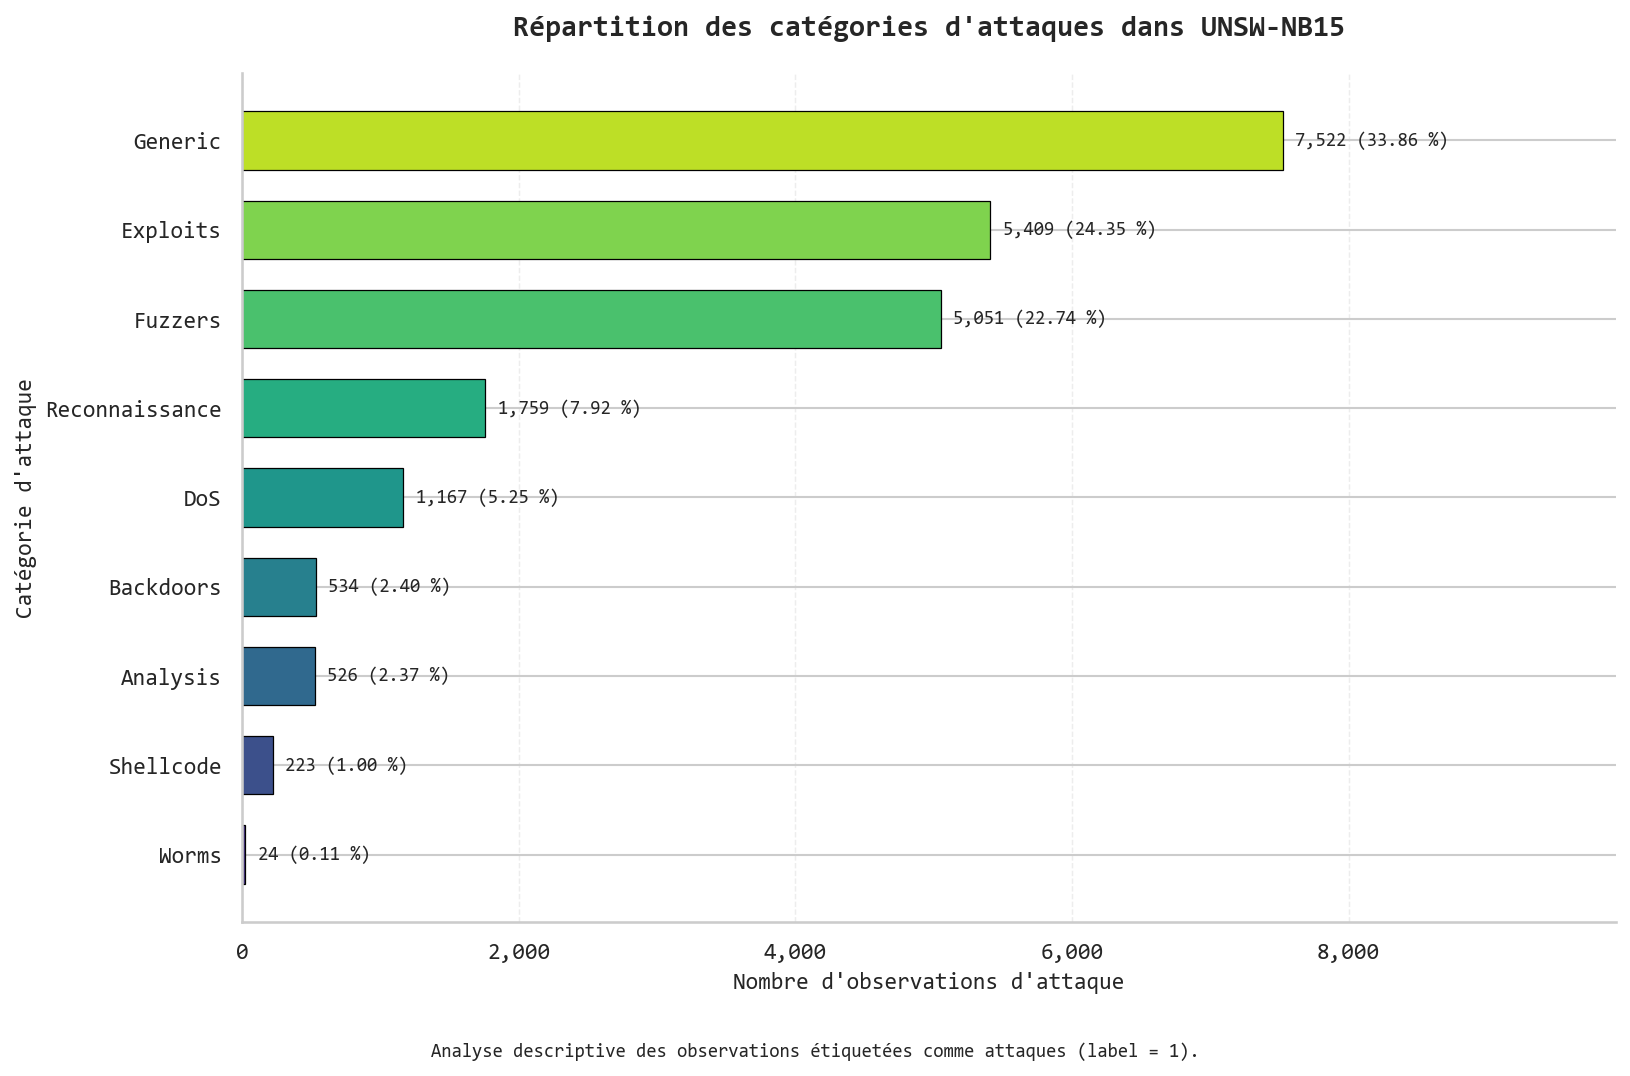

In [14]:

# ============================================================
# CELLULE 6 — ANALYSE DES CATEGORIES D'ATTAQUES
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15_1.csv
# Protocole : One-Class Learning
#
# Objectif :
# Analyser attack_cat et verifier sa coherence
# avec la variable binaire label.
#
# Aucune modification du dataset original.
# Aucun entrainement ou pretraitement.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get(
    "IF_CLASS_DISTRIBUTION_READY",
    False
):
    raise RuntimeError(
        "Executer et valider la cellule 5."
    )

if not globals().get(
    "IF_COLUMNS_READY",
    False
):
    raise RuntimeError(
        "Les noms des colonnes sont indisponibles."
    )

for column in [
    IF_ATTACK_COLUMN,
    IF_TARGET_COLUMN
]:
    if column not in IF_df.columns:
        raise ValueError(
            f"Colonne absente : {column}"
        )

# ------------------------------------------------------------
# 2. Memorisation de la structure
# ------------------------------------------------------------

IF_ATTACK_INITIAL_SHAPE = IF_df.shape

IF_ATTACK_INITIAL_IDS = (
    IF_df.index.to_numpy(copy=True)
)

# ------------------------------------------------------------
# 3. Extraction des metadonnees
# ------------------------------------------------------------

# Aucune modification de IF_df.
# Les traitements suivants servent uniquement
# a l'analyse descriptive.

IF_ATTACK_LABELS = pd.to_numeric(
    IF_df[IF_TARGET_COLUMN],
    errors="coerce"
)

if IF_ATTACK_LABELS.isna().any():
    raise ValueError(
        "Valeurs invalides dans label."
    )

if set(IF_ATTACK_LABELS.unique()) != {0, 1}:
    raise ValueError(
        "Les classes attendues sont 0 et 1."
    )

IF_ATTACK_LABELS = (
    IF_ATTACK_LABELS.astype(np.int8)
)

# ------------------------------------------------------------
# 4. Nettoyage descriptif des noms de categories
# ------------------------------------------------------------

# Les noms sont normalises uniquement
# dans une variable temporaire.
#
# Les cellules originales ne sont pas modifiees.

IF_ATTACK_CATEGORIES_RAW = (
    IF_df[IF_ATTACK_COLUMN]
    .astype("string")
)

IF_ATTACK_CATEGORIES_STRIPPED = (
    IF_ATTACK_CATEGORIES_RAW
    .str.strip()
)

IF_MISSING_CATEGORY_VALUES = {
    "",
    "nan",
    "none",
    "null",
    "na",
    "n/a"
}

IF_CATEGORY_MISSING_MASK = (
    IF_ATTACK_CATEGORIES_STRIPPED
    .isna()
    |
    IF_ATTACK_CATEGORIES_STRIPPED
    .str.lower()
    .isin(IF_MISSING_CATEGORY_VALUES)
    .fillna(False)
)

IF_ATTACK_CATEGORIES_CLEAN = (
    IF_ATTACK_CATEGORIES_STRIPPED
    .mask(
        IF_CATEGORY_MISSING_MASK,
        "Non renseignée"
    )
    .fillna("Non renseignée")
)

# ------------------------------------------------------------
# 5. Construction du tableau descriptif
# ------------------------------------------------------------

IF_ATTACK_DESCRIPTION = pd.DataFrame({
    "label": IF_ATTACK_LABELS,
    "attack_cat": IF_ATTACK_CATEGORIES_CLEAN
})

assert (
    len(IF_ATTACK_DESCRIPTION)
    == len(IF_df)
)

# ------------------------------------------------------------
# 6. Distribution des categories sur tout le dataset
# ------------------------------------------------------------

IF_ALL_CATEGORY_COUNTS = (
    IF_ATTACK_DESCRIPTION["attack_cat"]
    .value_counts(dropna=False)
)

IF_ALL_CATEGORY_TABLE = (
    IF_ALL_CATEGORY_COUNTS
    .rename_axis("Categorie_attaque")
    .reset_index(name="Effectif")
)

IF_ALL_CATEGORY_TABLE["Pourcentage_pct"] = (
    100
    * IF_ALL_CATEGORY_TABLE["Effectif"]
    / len(IF_ATTACK_DESCRIPTION)
)

print("\nCATEGORIES PRESENTES DANS LE DATASET")

display(IF_ALL_CATEGORY_TABLE)

# ------------------------------------------------------------
# 7. Distribution des categories parmi les attaques
# ------------------------------------------------------------

IF_ATTACK_ONLY_MASK = (
    IF_ATTACK_LABELS == 1
)

IF_ATTACK_ONLY_CATEGORIES = (
    IF_ATTACK_CATEGORIES_CLEAN[
        IF_ATTACK_ONLY_MASK
    ]
)

IF_ATTACK_ONLY_COUNTS = (
    IF_ATTACK_ONLY_CATEGORIES
    .value_counts(dropna=False)
)

IF_ATTACK_ONLY_TABLE = (
    IF_ATTACK_ONLY_COUNTS
    .rename_axis("Categorie_attaque")
    .reset_index(name="Effectif")
)

IF_N_ATTACKS_CHECK = int(
    IF_ATTACK_ONLY_MASK.sum()
)

assert IF_N_ATTACKS_CHECK == IF_N_ATTACK

IF_ATTACK_ONLY_TABLE["Pourcentage_pct"] = (
    100
    * IF_ATTACK_ONLY_TABLE["Effectif"]
    / IF_N_ATTACKS_CHECK
)

print("\nREPARTITION DES CATEGORIES PARMI LES ATTAQUES")

display(
    IF_ATTACK_ONLY_TABLE.style.format({
        "Effectif": "{:,.0f}",
        "Pourcentage_pct": "{:.2f} %"
    })
)

# ------------------------------------------------------------
# 8. Tableau croise label / attack_cat
# ------------------------------------------------------------

IF_CATEGORY_CROSSTAB = pd.crosstab(
    IF_ATTACK_DESCRIPTION["attack_cat"],
    IF_ATTACK_DESCRIPTION["label"]
)

IF_CATEGORY_CROSSTAB = (
    IF_CATEGORY_CROSSTAB.reindex(
        columns=[0, 1],
        fill_value=0
    )
)

IF_CATEGORY_CROSSTAB.columns = [
    "Trafic_normal",
    "Attaques"
]

IF_CATEGORY_CROSSTAB["Total"] = (
    IF_CATEGORY_CROSSTAB["Trafic_normal"]
    + IF_CATEGORY_CROSSTAB["Attaques"]
)

print("\nTABLEAU CROISE : CATEGORIE ET CLASSE BINAIRE")

display(IF_CATEGORY_CROSSTAB)

# ------------------------------------------------------------
# 9. Detection d'incoherences descriptives
# ------------------------------------------------------------

# Dans UNSW-NB15, une categorie d'attaque
# explicite sur une ligne normale peut signaler
# une incoherence de metadonnees.
#
# Nous ne modifions aucune etiquette.

IF_NORMAL_WITH_CATEGORY = (
    (IF_ATTACK_LABELS == 0)
    &
    (
        IF_ATTACK_CATEGORIES_CLEAN
        != "Non renseignée"
    )
    &
    (
        IF_ATTACK_CATEGORIES_CLEAN
        .str.lower() != "normal"
    )
)

IF_ATTACK_WITHOUT_CATEGORY = (
    (IF_ATTACK_LABELS == 1)
    &
    (
        (
            IF_ATTACK_CATEGORIES_CLEAN
            == "Non renseignée"
        )
        |
        (
            IF_ATTACK_CATEGORIES_CLEAN
            .str.lower() == "normal"
        )
    )
)

IF_N_NORMAL_WITH_CATEGORY = int(
    IF_NORMAL_WITH_CATEGORY.sum()
)

IF_N_ATTACK_WITHOUT_CATEGORY = int(
    IF_ATTACK_WITHOUT_CATEGORY.sum()
)

# ------------------------------------------------------------
# 10. Configuration graphique scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": IF_SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

# ------------------------------------------------------------
# 11. Preparation du graphique
# ------------------------------------------------------------

# Le graphique represente seulement les
# observations dont label == 1.

IF_ATTACK_PLOT_TABLE = (
    IF_ATTACK_ONLY_TABLE
    .sort_values(
        "Effectif",
        ascending=True
    )
    .reset_index(drop=True)
)

IF_ATTACK_COLORS = plt.cm.viridis(
    np.linspace(
        0.15,
        0.90,
        len(IF_ATTACK_PLOT_TABLE)
    )
)

# ------------------------------------------------------------
# 12. Creation de la figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        11,
        max(
            6,
            0.58 * len(IF_ATTACK_PLOT_TABLE) + 2
        )
    ),
    dpi=150
)

bars = ax.barh(
    IF_ATTACK_PLOT_TABLE["Categorie_attaque"],
    IF_ATTACK_PLOT_TABLE["Effectif"],
    color=IF_ATTACK_COLORS,
    edgecolor="black",
    linewidth=0.6,
    height=0.65
)

# ------------------------------------------------------------
# 13. Annotation des effectifs
# ------------------------------------------------------------

IF_MAX_ATTACK_COUNT = int(
    IF_ATTACK_PLOT_TABLE["Effectif"].max()
)

for bar, (_, row) in zip(
    bars,
    IF_ATTACK_PLOT_TABLE.iterrows()
):

    effectif = int(row["Effectif"])

    proportion = float(
        row["Pourcentage_pct"]
    )

    ax.annotate(
        f"{effectif:,} ({proportion:.2f} %)",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(6, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        fontfamily=IF_SCIENTIFIC_FONT
    )

# ------------------------------------------------------------
# 14. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Répartition des catégories d'attaques dans UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily=IF_SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Nombre d'observations d'attaque",
    fontsize=11,
    fontfamily=IF_SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Catégorie d'attaque",
    fontsize=11,
    fontfamily=IF_SCIENTIFIC_FONT
)

ax.set_xlim(
    0,
    max(
        1,
        IF_MAX_ATTACK_COUNT
    ) * 1.32
)

ax.xaxis.set_major_formatter(
    mticker.StrMethodFormatter("{x:,.0f}")
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

# ------------------------------------------------------------
# 15. Note methodologique
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    (
        "Analyse descriptive des observations "
        "étiquetées comme attaques (label = 1)."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_SCIENTIFIC_FONT
)

plt.tight_layout(
    rect=(0, 0.05, 1, 1)
)

# ------------------------------------------------------------
# 16. Sauvegarde des figures
# ------------------------------------------------------------

IF_ATTACK_FIGURE_NAME = (
    "distribution_categories_attaques_UNSW_NB15"
)

IF_ATTACK_PNG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_ATTACK_FIGURE_NAME}.png"
)

IF_ATTACK_PDF_PATH = (
    IF_FIGURES_DIR /
    f"{IF_ATTACK_FIGURE_NAME}.pdf"
)

IF_ATTACK_SVG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_ATTACK_FIGURE_NAME}.svg"
)

for path, format_name in [
    (IF_ATTACK_PNG_PATH, "png"),
    (IF_ATTACK_PDF_PATH, "pdf"),
    (IF_ATTACK_SVG_PATH, "svg")
]:

    fig.savefig(
        path,
        format=format_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 17. Export des tableaux
# ------------------------------------------------------------

IF_ALL_CATEGORY_TABLE.to_csv(
    IF_TABLES_DIR /
    "distribution_categories_completes_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_ATTACK_ONLY_TABLE.to_csv(
    IF_TABLES_DIR /
    "distribution_categories_attaques_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_CATEGORY_CROSSTAB.to_csv(
    IF_TABLES_DIR /
    "tableau_croise_label_attack_cat_IF.csv",
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 18. Rapport descriptif
# ------------------------------------------------------------

IF_ATTACK_CATEGORY_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "analyse": "descriptive",
    "variable_cible": IF_TARGET_COLUMN,
    "variable_categorie": IF_ATTACK_COLUMN,
    "nombre_observations": int(len(IF_df)),
    "nombre_attaques": int(IF_N_ATTACKS_CHECK),
    "nombre_categories_attaques": int(
        len(IF_ATTACK_ONLY_TABLE)
    ),
    "normaux_avec_categorie_attaque": (
        IF_N_NORMAL_WITH_CATEGORY
    ),
    "attaques_sans_categorie": (
        IF_N_ATTACK_WITHOUT_CATEGORY
    ),
    "categories_utilisees_pour_entrainement": False,
    "donnees_modifiees": False,
    "pretraitement_effectue": False,
    "modele_entraine": False
}

IF_ATTACK_CATEGORY_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_categories_attaques_IF.json"
)

with open(
    IF_ATTACK_CATEGORY_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_ATTACK_CATEGORY_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

In [16]:

# ============================================================
# CELLULE 7 — SEPARATION DES VARIABLES ET METADONNEES
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Preparer les caracteristiques candidates,
# les etiquettes et les metadonnees.
#
# Aucune separation train/validation/test.
# Aucun apprentissage ou pretraitement.
# ============================================================

import json
import numpy as np
import pandas as pd

print("=" * 70)
print("CELLULE 7 — PREPARATION DES VARIABLES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get(
    "IF_ATTACK_CATEGORIES_READY", False
):
    raise RuntimeError(
        "Executer correctement la cellule 6."
    )

if not globals().get(
    "IF_COLUMNS_READY", False
):
    raise RuntimeError(
        "Les colonnes ne sont pas identifiees."
    )

required_columns = (
    IF_FEATURE_COLUMNS
    + [IF_TARGET_COLUMN, IF_ATTACK_COLUMN]
)

if IF_df.columns.tolist() != IF_COLUMN_NAMES:
    raise ValueError(
        "L'ordre des colonnes ne correspond pas "
        "au schema initial."
    )

if not all(
    column in IF_df.columns
    for column in required_columns
):
    raise ValueError(
        "Une ou plusieurs colonnes sont absentes."
    )

# ------------------------------------------------------------
# 2. Construction des caracteristiques candidates
# ------------------------------------------------------------

# Exclure :
# - label : classe binaire
# - attack_cat : categorie d'attaque
#
# Les caracteristiques sont conservees
# dans leur format brut, sans transformation.

IF_X = IF_df.drop(
    columns=[
        IF_TARGET_COLUMN,
        IF_ATTACK_COLUMN
    ]
).copy()

assert IF_X.shape[1] == 47

assert IF_X.columns.tolist() == IF_FEATURE_COLUMNS

print("\nCARACTERISTIQUES CANDIDATES")

print("Nombre :", IF_X.shape[1])
print("Observations :", IF_X.shape[0])

# ------------------------------------------------------------
# 3. Construction de la variable cible
# ------------------------------------------------------------

# Les etiquettes servent seulement a :
# - identifier le trafic normal du train
# - verifier les partitions
# - evaluer les predictions
#
# Elles ne seront pas fournies au modele.

IF_y = pd.to_numeric(
    IF_df[IF_TARGET_COLUMN],
    errors="raise"
).astype(np.int8)

if set(IF_y.unique()) != {0, 1}:
    raise ValueError(
        "Les etiquettes doivent etre 0 et 1."
    )

IF_y.name = IF_TARGET_COLUMN

print("\nVARIABLE CIBLE")

print("Nom :", IF_y.name)
print("Classes :", sorted(IF_y.unique()))

# ------------------------------------------------------------
# 4. Conservation des categories d'attaques
# ------------------------------------------------------------

# Les valeurs brutes sont conservees pour
# maintenir l'alignement avec le DDAE.
#
# Les corrections de presentation des noms
# seront effectuees uniquement lors
# des analyses descriptives.

IF_attack_metadata = (
    IF_df[IF_ATTACK_COLUMN].copy()
)

IF_attack_metadata.name = IF_ATTACK_COLUMN

# ------------------------------------------------------------
# 5. Conservation des identifiants originaux
# ------------------------------------------------------------

IF_observation_ids = np.arange(
    len(IF_df),
    dtype=np.int64
)

assert np.array_equal(
    IF_df.index.to_numpy(),
    IF_observation_ids
)

# ------------------------------------------------------------
# 6. Caracteristiques exclues par le protocole DDAE
# ------------------------------------------------------------

IF_EXCLUDED_FEATURES = [
    "srcip",
    "dstip",
    "Stime",
    "Ltime"
]

for feature in IF_EXCLUDED_FEATURES:

    if feature not in IF_X.columns:
        raise ValueError(
            f"Caracteristique absente : {feature}"
        )

# ------------------------------------------------------------
# 7. Liste des caracteristiques selectionnees
# ------------------------------------------------------------

# Cette liste reproduit la selection brute
# utilisee dans le notebook DDAE.
#
# Nous verifierons a la cellule suivante
# sa conformite avec les artefacts sauvegardes.

IF_SELECTED_FEATURES = [
    column
    for column in IF_X.columns
    if column not in IF_EXCLUDED_FEATURES
]

assert len(IF_SELECTED_FEATURES) == 43

assert IF_SELECTED_FEATURES == (
    IF_SELECTED_FEATURES_EXPECTED
)

print("\nSELECTION DE CARACTERISTIQUES")

print(
    "Candidates :",
    len(IF_FEATURE_COLUMNS)
)

print(
    "Exclues :",
    len(IF_EXCLUDED_FEATURES)
)

print(
    "Selectionnees :",
    len(IF_SELECTED_FEATURES)
)

print("\nCaracteristiques exclues :")

for feature in IF_EXCLUDED_FEATURES:
    print(" -", feature)

# ------------------------------------------------------------
# 8. Caracteristiques numeriques et categorielles
# ------------------------------------------------------------

IF_CATEGORICAL_FEATURES_SELECTED = [
    "proto",
    "state",
    "service"
]

IF_NUMERIC_FEATURES_SELECTED = [
    column
    for column in IF_SELECTED_FEATURES
    if column not in IF_CATEGORICAL_FEATURES_SELECTED
]

assert len(IF_CATEGORICAL_FEATURES_SELECTED) == 3

assert len(IF_NUMERIC_FEATURES_SELECTED) == 40

print("\nTYPES DE CARACTERISTIQUES SELECTIONNEES")

print(
    "Numeriques :",
    len(IF_NUMERIC_FEATURES_SELECTED)
)

print(
    "Categorielles :",
    len(IF_CATEGORICAL_FEATURES_SELECTED)
)

# ------------------------------------------------------------
# 9. Verification de l'absence de fuite directe
# ------------------------------------------------------------

IF_FORBIDDEN_COLUMNS = {
    "label",
    "attack_cat"
}

assert IF_FORBIDDEN_COLUMNS.isdisjoint(
    set(IF_X.columns)
)

assert IF_FORBIDDEN_COLUMNS.isdisjoint(
    set(IF_SELECTED_FEATURES)
)



# ------------------------------------------------------------
# 10. Verification de l'alignement
# ------------------------------------------------------------

assert (
    len(IF_X)
    == len(IF_y)
    == len(IF_attack_metadata)
    == len(IF_observation_ids)
    == len(IF_df)
)

assert IF_X.index.equals(
    IF_y.index
)

assert IF_X.index.equals(
    IF_attack_metadata.index
)

assert IF_X.shape[0] == IF_N_ROWS

print("\nALIGNEMENT DES OBSERVATIONS : VALIDE")

# ------------------------------------------------------------
# 11. Tableau de tracabilite des caracteristiques
# ------------------------------------------------------------

IF_FEATURE_TRACEABILITY = pd.DataFrame({
    "Position_initiale": [
        IF_COLUMN_NAMES.index(column) + 1
        for column in IF_FEATURE_COLUMNS
    ],
    "Caracteristique": IF_FEATURE_COLUMNS,
    "Statut": [
        (
            "Exclue"
            if column in IF_EXCLUDED_FEATURES
            else "Selectionnee"
        )
        for column in IF_FEATURE_COLUMNS
    ],
    "Justification": [
        (
            "Identifiant d'adresse IP"
            if column in ["srcip", "dstip"]
            else (
                "Horodatage brut"
                if column in ["Stime", "Ltime"]
                else "Conservee dans le protocole DDAE"
            )
        )
        for column in IF_FEATURE_COLUMNS
    ]
})

print("\nTRACABILITE DES 47 CARACTERISTIQUES")

display(IF_FEATURE_TRACEABILITY)

# ------------------------------------------------------------
# 12. Apercu des donnees
# ------------------------------------------------------------

print("\nAPERÇU DES CARACTERISTIQUES CANDIDATES")

display(
    IF_X.head(5)
)

print("\nDISTRIBUTION DE LA CIBLE")

display(
    IF_y.value_counts().sort_index()
)

# ------------------------------------------------------------
# 13. Export des caracteristiques
# ------------------------------------------------------------

IF_FEATURE_TRACEABILITY_PATH = (
    IF_TABLES_DIR /
    "tracabilite_caracteristiques_IF.csv"
)

IF_FEATURE_TRACEABILITY.to_csv(
    IF_FEATURE_TRACEABILITY_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. Rapport de preparation
# ------------------------------------------------------------

IF_FEATURE_PREPARATION_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "nombre_observations": int(len(IF_X)),
    "caracteristiques_candidates": int(
        len(IF_FEATURE_COLUMNS)
    ),
    "caracteristiques_selectionnees": int(
        len(IF_SELECTED_FEATURES)
    ),
    "caracteristiques_exclues": IF_EXCLUDED_FEATURES,
    "liste_caracteristiques_selectionnees": (
        IF_SELECTED_FEATURES
    ),
    "caracteristiques_numeriques": (
        IF_NUMERIC_FEATURES_SELECTED
    ),
    "caracteristiques_categorielles": (
        IF_CATEGORICAL_FEATURES_SELECTED
    ),
    "variable_cible": IF_TARGET_COLUMN,
    "variable_categorie": IF_ATTACK_COLUMN,
    "etiquettes_exclues_des_predicteurs": True,
    "ordre_observations_conserve": True,
    "donnees_modifiees": False,
    "pretraitement_effectue": False,
    "partitionnement_effectue": False,
    "compatibilite_DDAE": "a_verifier_sur_artefacts"
}

IF_FEATURE_PREPARATION_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_preparation_variables_IF.json"
)

with open(
    IF_FEATURE_PREPARATION_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_FEATURE_PREPARATION_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )


CELLULE 7 — PREPARATION DES VARIABLES

CARACTERISTIQUES CANDIDATES
Nombre : 47
Observations : 700001

VARIABLE CIBLE
Nom : label
Classes : [0, 1]

SELECTION DE CARACTERISTIQUES
Candidates : 47
Exclues : 4
Selectionnees : 43

Caracteristiques exclues :
 - srcip
 - dstip
 - Stime
 - Ltime

TYPES DE CARACTERISTIQUES SELECTIONNEES
Numeriques : 40
Categorielles : 3

ALIGNEMENT DES OBSERVATIONS : VALIDE

TRACABILITE DES 47 CARACTERISTIQUES


,Position_initiale,Caracteristique,Statut,Justification
0,1,srcip,Exclue,Identifiant d'adresse IP
1,2,sport,Selectionnee,Conservee dans le protocole DDAE
2,3,dstip,Exclue,Identifiant d'adresse IP
3,4,dsport,Selectionnee,Conservee dans le protocole DDAE
4,5,proto,Selectionnee,Conservee dans le protocole DDAE
5,6,state,Selectionnee,Conservee dans le protocole DDAE
6,7,dur,Selectionnee,Conservee dans le protocole DDAE
7,8,sbytes,Selectionnee,Conservee dans le protocole DDAE
8,9,dbytes,Selectionnee,Conservee dans le protocole DDAE
9,10,sttl,Selectionnee,Conservee dans le protocole DDAE



APERÇU DES CARACTERISTIQUES CANDIDATES


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,0,0,3,7,1,3,1,1,1
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,0,0,2,4,2,3,1,1,2
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,0,0,12,8,1,2,2,1,1
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,0,0,6,9,1,1,1,1,1
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,0,0,7,9,1,1,1,1,1



DISTRIBUTION DE LA CIBLE


label
0    677786
1     22215
Name: count, dtype: int64

In [41]:

# ============================================================
# CELLULE 8 — PARTITIONNEMENT AUTONOME ISOLATION FOREST
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from pandas.util import hash_pandas_object


if not globals().get("IF_FEATURES_READY", False):
    raise RuntimeError(
        "Executer la cellule 7 avant de continuer."
    )

IF_COMMON_SPLIT_READY = False

# Dossier du projet Isolation Forest
IF_PROJECT_DIR = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest"
)

IF_SPLIT_DIR = IF_ARTIFACTS_DIR / "split_isolation_forest"

IF_SPLIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 1. CREATION DES GROUPES
# ------------------------------------------------------------

IF_SIGNATURES = hash_pandas_object(
    IF_X[IF_SELECTED_FEATURES],
    index=False,
    categorize=True
).to_numpy(dtype=np.uint64)

_, IF_GROUP_IDS = np.unique(
    IF_SIGNATURES,
    return_inverse=True
)

# ------------------------------------------------------------
# 2. REPARTITION 70 / 15 / 15
# ------------------------------------------------------------

splitter_train = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=42
)

IF_ids_train, IF_ids_temp = next(
    splitter_train.split(
        IF_X,
        IF_y,
        groups=IF_GROUP_IDS
    )
)

splitter_temp = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=43
)

val_pos, test_pos = next(
    splitter_temp.split(
        IF_ids_temp,
        IF_y.iloc[IF_ids_temp],
        groups=IF_GROUP_IDS[IF_ids_temp]
    )
)

IF_ids_val = IF_ids_temp[val_pos]
IF_ids_test = IF_ids_temp[test_pos]

# ------------------------------------------------------------
# 3. VERIFICATIONS DES PARTITIONS
# ------------------------------------------------------------

all_ids = np.concatenate([
    IF_ids_train,
    IF_ids_val,
    IF_ids_test
])

assert len(all_ids) == len(IF_df)
assert len(np.unique(all_ids)) == len(IF_df)

train_groups = np.unique(IF_GROUP_IDS[IF_ids_train])
val_groups = np.unique(IF_GROUP_IDS[IF_ids_val])
test_groups = np.unique(IF_GROUP_IDS[IF_ids_test])

assert np.intersect1d(train_groups, val_groups).size == 0
assert np.intersect1d(train_groups, test_groups).size == 0
assert np.intersect1d(val_groups, test_groups).size == 0

# ------------------------------------------------------------
# 4. CONSTRUCTION DES ENSEMBLES BRUTS
# ------------------------------------------------------------

IF_X_train_raw = IF_X.iloc[IF_ids_train].copy()
IF_X_val_raw = IF_X.iloc[IF_ids_val].copy()
IF_X_test_raw = IF_X.iloc[IF_ids_test].copy()

IF_y_train_all = IF_y.iloc[IF_ids_train].copy()
IF_y_val_all = IF_y.iloc[IF_ids_val].copy()
IF_y_test = IF_y.iloc[IF_ids_test].copy()

# ------------------------------------------------------------
# 5. EXTRACTION DU TRAFIC NORMAL
# ------------------------------------------------------------

train_normal_mask = (
    IF_y_train_all.to_numpy() == 0
)

val_normal_mask = (
    IF_y_val_all.to_numpy() == 0
)

IF_ids_train_normal = IF_ids_train[
    train_normal_mask
]

IF_ids_val_normal = IF_ids_val[
    val_normal_mask
]

IF_X_train_normal_raw = (
    IF_X_train_raw.iloc[
        np.flatnonzero(train_normal_mask)
    ].copy()
)

IF_X_val_normal_raw = (
    IF_X_val_raw.iloc[
        np.flatnonzero(val_normal_mask)
    ].copy()
)

# ------------------------------------------------------------
# 6. SAUVEGARDE DES PARTITIONS
# ------------------------------------------------------------

np.save(
    IF_SPLIT_DIR / "indices_train.npy",
    IF_ids_train
)

np.save(
    IF_SPLIT_DIR / "indices_validation.npy",
    IF_ids_val
)

np.save(
    IF_SPLIT_DIR / "indices_test.npy",
    IF_ids_test
)

np.save(
    IF_SPLIT_DIR / "groupes_observations.npy",
    IF_GROUP_IDS
)

# ------------------------------------------------------------
# 7. TABLEAU RECAPITULATIF
# ------------------------------------------------------------

IF_SPLIT_SUMMARY = pd.DataFrame({
    "Ensemble": [
        "Entrainement",
        "Validation",
        "Test"
    ],
    "Total": [
        len(IF_ids_train),
        len(IF_ids_val),
        len(IF_ids_test)
    ],
    "Normaux": [
        int((IF_y_train_all == 0).sum()),
        int((IF_y_val_all == 0).sum()),
        int((IF_y_test == 0).sum())
    ],
    "Attaques": [
        int((IF_y_train_all == 1).sum()),
        int((IF_y_val_all == 1).sum()),
        int((IF_y_test == 1).sum())
    ]
})

display(IF_SPLIT_SUMMARY)

IF_SPLIT_SUMMARY.to_csv(
    IF_TABLES_DIR / "repartition_Isolation_Forest.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_COMMON_SPLIT_READY = True
IF_AUTONOMOUS_SPLIT_READY = True


,Ensemble,Total,Normaux,Attaques
0,Entrainement,490140,474263,15877
1,Validation,104990,102016,2974
2,Test,104871,101507,3364


In [42]:

# ============================================================
# CELLULE 9 — PRETRAITEMENT AUTONOME ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Construire un preprocesseur autonome ajuste
# uniquement sur le trafic normal d'entrainement.
#
# Aucune utilisation du DDAE.
# Aucun ajustement sur validation ou test.
# ============================================================

import json
import inspect
import hashlib
import warnings

import numpy as np
import pandas as pd
import joblib

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.utils.validation import check_is_fitted

# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

if not globals().get("IF_AUTONOMOUS_SPLIT_READY", False):
    raise RuntimeError(
        "Le partitionnement autonome est indisponible. "
        "Executer la cellule 8 autonome."
    )

if not globals().get("IF_FEATURES_READY", False):
    raise RuntimeError(
        "Les caracteristiques ne sont pas disponibles. "
        "Executer la cellule 7."
    )

IF_PREPROCESSOR_READY = False

# ------------------------------------------------------------
# 2. VERIFICATION DES CARACTERISTIQUES
# ------------------------------------------------------------

IF_EXCLUDED_FEATURES = [
    "srcip",
    "dstip",
    "Stime",
    "Ltime"
]

IF_SELECTED_FEATURES = [
    column
    for column in IF_FEATURE_COLUMNS
    if column not in IF_EXCLUDED_FEATURES
]

IF_CATEGORICAL_FEATURES = [
    "proto",
    "state",
    "service"
]

IF_NUMERIC_FEATURES = [
    column
    for column in IF_SELECTED_FEATURES
    if column not in IF_CATEGORICAL_FEATURES
]

if len(IF_SELECTED_FEATURES) != 43:
    raise ValueError(
        "Le nombre de caracteristiques doit etre 43."
    )

if len(IF_NUMERIC_FEATURES) != 40:
    raise ValueError(
        "Le nombre de variables numeriques doit etre 40."
    )

if len(IF_CATEGORICAL_FEATURES) != 3:
    raise ValueError(
        "Le nombre de variables categorielles doit etre 3."
    )

if set(IF_SELECTED_FEATURES).intersection({
    "label",
    "attack_cat"
}):
    raise RuntimeError(
        "Une variable cible est presente dans les predicteurs."
    )

print("\nCARACTERISTIQUES")

print("Variables selectionnees :", len(IF_SELECTED_FEATURES))
print("Variables numeriques :", len(IF_NUMERIC_FEATURES))
print("Variables categorielles :", len(IF_CATEGORICAL_FEATURES))

# ------------------------------------------------------------
# 3. VERIFICATION DU TRAIN NORMAL
# ------------------------------------------------------------

if IF_X_train_normal_raw.empty:
    raise ValueError(
        "L'ensemble d'entrainement normal est vide."
    )

if len(IF_X_train_normal_raw) != len(IF_ids_train_normal):
    raise RuntimeError(
        "Incoherence entre les observations et leurs indices."
    )

if not np.all(
    IF_y.iloc[IF_ids_train_normal].to_numpy() == 0
):
    raise RuntimeError(
        "L'ensemble d'entrainement contient des attaques."
    )

print("\nAPPRENTISSAGE ONE-CLASS")

print(
    "Observations normales d'entrainement :",
    f"{len(IF_X_train_normal_raw):,}"
)

print("Attaques utilisees pour ajustement : 0")

# ------------------------------------------------------------
# 4. FONCTION DE NETTOYAGE DETERMINISTE
# ------------------------------------------------------------

# Cette fonction :
# - selectionne les variables prevues
# - convertit les valeurs numeriques
# - remplace les valeurs infinies par NaN
# - uniformise les champs categoriels manquants
#
# Elle n'apprend aucun parametre statistique.

def IF_prepare_network_features(data):

    missing_columns = [
        column
        for column in IF_SELECTED_FEATURES
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Colonnes manquantes : {missing_columns}"
        )

    cleaned = data.loc[
        :,
        IF_SELECTED_FEATURES
    ].copy()

    # ----------------------------------------
    # Variables numeriques
    # ----------------------------------------

    for column in IF_NUMERIC_FEATURES:

        numeric_series = pd.to_numeric(
            cleaned[column]
            .astype("string")
            .str.strip(),
            errors="coerce"
        )

        cleaned[column] = (
            numeric_series
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .astype(np.float64)
        )

    # ----------------------------------------
    # Variables categorielles
    # ----------------------------------------

    for column in IF_CATEGORICAL_FEATURES:

        category_series = (
            cleaned[column]
            .astype("string")
            .str.strip()
        )

        # Les valeurs vides et les valeurs
        # manquantes reelles sont traitees
        # de maniere coherente.

        category_series = (
            category_series
            .replace("", pd.NA)
            .fillna("__MANQUANT__")
            .astype(str)
        )

        cleaned[column] = category_series

    return cleaned

# ------------------------------------------------------------
# 5. NETTOYAGE DU TRAIN NORMAL UNIQUEMENT
# ------------------------------------------------------------

IF_X_train_normal_clean = (
    IF_prepare_network_features(
        IF_X_train_normal_raw
    )
)

assert IF_X_train_normal_clean.shape == (
    len(IF_ids_train_normal),
    43
)

print("\nNettoyage deterministe du train : TERMINE")

# ------------------------------------------------------------
# 6. CONFIGURATION DE L'IMPUTATION
# ------------------------------------------------------------

IF_NUMERIC_PIPELINE = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# ------------------------------------------------------------
# 7. CONFIGURATION DU ONE-HOT ENCODER
# ------------------------------------------------------------

# Compatibilite avec les versions recentes
# et anciennes de scikit-learn.

encoder_parameters = inspect.signature(
    OneHotEncoder
).parameters

encoder_kwargs = {
    "handle_unknown": "ignore",
    "dtype": np.float32
}

if "sparse_output" in encoder_parameters:

    encoder_kwargs["sparse_output"] = True

else:

    encoder_kwargs["sparse"] = True

IF_CATEGORICAL_ENCODER = OneHotEncoder(
    **encoder_kwargs
)

IF_CATEGORICAL_PIPELINE = Pipeline(
    steps=[
        (
            "encoder",
            IF_CATEGORICAL_ENCODER
        )
    ]
)

# ------------------------------------------------------------
# 8. CREATION DU COLUMNTRANSFORMER
# ------------------------------------------------------------

IF_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            IF_NUMERIC_PIPELINE,
            IF_NUMERIC_FEATURES
        ),
        (
            "categorical",
            IF_CATEGORICAL_PIPELINE,
            IF_CATEGORICAL_FEATURES
        )
    ],
    remainder="drop",
    sparse_threshold=1.0
)

# ------------------------------------------------------------
# 9. AJUSTEMENT SUR LE TRAIN NORMAL
# ------------------------------------------------------------

print("\nAjustement du preprocesseur...")

# SEUL fit autorise pour le pretraitement.
# Aucun echantillon de validation ou de test
# n'est utilise ici.

IF_preprocessor.fit(
    IF_X_train_normal_clean
)

check_is_fitted(
    IF_preprocessor
)



# ------------------------------------------------------------
# 10. VERIFICATION DES COMPOSANTS AJUSTES
# ------------------------------------------------------------

IF_numeric_fitted = (
    IF_preprocessor.named_transformers_["numeric"]
)

IF_categorical_fitted = (
    IF_preprocessor.named_transformers_["categorical"]
)

IF_imputer_fitted = (
    IF_numeric_fitted.named_steps["imputer"]
)

IF_scaler_fitted = (
    IF_numeric_fitted.named_steps["scaler"]
)

IF_encoder_fitted = (
    IF_categorical_fitted.named_steps["encoder"]
)

check_is_fitted(IF_imputer_fitted)
check_is_fitted(IF_scaler_fitted)
check_is_fitted(IF_encoder_fitted)

if IF_imputer_fitted.strategy != "median":
    raise RuntimeError(
        "Strategie d'imputation incorrecte."
    )

if IF_encoder_fitted.handle_unknown != "ignore":
    raise RuntimeError(
        "Gestion des categories inconnues incorrecte."
    )

# ------------------------------------------------------------
# 11. VERIFICATION DU SCHEMA D'ENTREE
# ------------------------------------------------------------

IF_INPUT_FEATURE_NAMES = list(
    IF_preprocessor.feature_names_in_
)

if IF_INPUT_FEATURE_NAMES != IF_SELECTED_FEATURES:
    raise RuntimeError(
        "L'ordre des caracteristiques ne correspond pas."
    )

# ------------------------------------------------------------
# 12. CARACTERISTIQUES APRES ENCODAGE
# ------------------------------------------------------------

IF_OUTPUT_FEATURE_NAMES = np.asarray(
    IF_preprocessor.get_feature_names_out(),
    dtype=str
)

IF_N_INPUT_FEATURES = int(
    len(IF_OUTPUT_FEATURE_NAMES)
)



# ------------------------------------------------------------
# 13. VERIFICATION DES STATISTIQUES
# ------------------------------------------------------------

if not np.isfinite(
    IF_imputer_fitted.statistics_
).all():
    raise ValueError(
        "L'imputation contient des statistiques non finies."
    )

if not np.isfinite(
    IF_scaler_fitted.mean_
).all():
    raise ValueError(
        "Le scaler contient des moyennes non finies."
    )

if not np.isfinite(
    IF_scaler_fitted.scale_
).all():
    raise ValueError(
        "Le scaler contient des echelles non finies."
    )

# ------------------------------------------------------------
# 14. TABLEAU DE TRACABILITE
# ------------------------------------------------------------

IF_FEATURE_SCHEMA_TABLE = pd.DataFrame({
    "Position": np.arange(
        1,
        IF_N_INPUT_FEATURES + 1
    ),
    "Caracteristique_encodee": IF_OUTPUT_FEATURE_NAMES
})

print("\nAPERÇU DES VARIABLES ENCODEES")

display(
    IF_FEATURE_SCHEMA_TABLE.head(20)
)

# ------------------------------------------------------------
# 15. SAUVEGARDE DU PREPROCESSEUR
# ------------------------------------------------------------

IF_PREPROCESSOR_PATH = (
    IF_ARTIFACTS_DIR /
    "preprocesseur_Isolation_Forest.joblib"
)

joblib.dump(
    IF_preprocessor,
    IF_PREPROCESSOR_PATH
)


# ------------------------------------------------------------
# 16. SAUVEGARDE DU SCHEMA
# ------------------------------------------------------------

IF_SCHEMA_PATH = (
    IF_TABLES_DIR /
    "schema_caracteristiques_IF.csv"
)

IF_FEATURE_SCHEMA_TABLE.to_csv(
    IF_SCHEMA_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 17. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_PREPROCESSOR_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "pretraitement": "autonome",
    "nombre_observations_fit": int(
        len(IF_X_train_normal_clean)
    ),
    "population_fit": "train_normal",
    "caracteristiques_candidates": 47,
    "caracteristiques_brutes_selectionnees": 43,
    "caracteristiques_numeriques": 40,
    "caracteristiques_categorielles": 3,
    "caracteristiques_encodees": int(
        IF_N_INPUT_FEATURES
    ),
    "selection_caracteristiques": IF_SELECTED_FEATURES,
    "imputation": "mediane",
    "standardisation": "StandardScaler",
    "encodage": "OneHotEncoder",
    "categories_inconnues": "ignore",
    "ajustement_validation": False,
    "ajustement_test": False,
    "utilisation_DDAE": False,
    "preprocesseur_path": str(
        IF_PREPROCESSOR_PATH
    )
}

IF_PREPROCESSOR_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_pretraitement_autonome_IF.json"
)

with open(
    IF_PREPROCESSOR_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_PREPROCESSOR_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )


CARACTERISTIQUES
Variables selectionnees : 43
Variables numeriques : 40
Variables categorielles : 3

APPRENTISSAGE ONE-CLASS
Observations normales d'entrainement : 474,263
Attaques utilisees pour ajustement : 0

Nettoyage deterministe du train : TERMINE

Ajustement du preprocesseur...

APERÇU DES VARIABLES ENCODEES


,Position,Caracteristique_encodee
0,1,numeric__sport
1,2,numeric__dsport
2,3,numeric__dur
3,4,numeric__sbytes
4,5,numeric__dbytes
5,6,numeric__sttl
6,7,numeric__dttl
7,8,numeric__sloss
8,9,numeric__dloss
9,10,numeric__Sload


In [43]:

# ============================================================
# DIAGNOSTIC — ETAT DES CELLULES 8 ET 9
# ============================================================

print("=" * 65)
print("DIAGNOSTIC DU PRETRAITEMENT ISOLATION FOREST")
print("=" * 65)

variables = [
    "IF_AUTONOMOUS_SPLIT_READY",
    "IF_FEATURES_READY",
    "IF_PREPROCESSOR_READY",
    "IF_preprocessor",
    "IF_prepare_network_features",
    "IF_X_train_normal_clean",
    "IF_N_INPUT_FEATURES",
    "IF_PREPROCESSOR_PATH"
]

for name in variables:

    if name in globals():

        value = globals()[name]

        if isinstance(value, bool):
            print(f"{name} : {value}")
        else:
            print(f"{name} : DISPONIBLE")

    else:
        print(f"{name} : ABSENTE")

print("=" * 65)


DIAGNOSTIC DU PRETRAITEMENT ISOLATION FOREST
IF_AUTONOMOUS_SPLIT_READY : True
IF_FEATURES_READY : True
IF_PREPROCESSOR_READY : False
IF_preprocessor : DISPONIBLE
IF_prepare_network_features : DISPONIBLE
IF_X_train_normal_clean : DISPONIBLE
IF_N_INPUT_FEATURES : DISPONIBLE
IF_PREPROCESSOR_PATH : DISPONIBLE


In [44]:

# ============================================================
# DIAGNOSTIC FINAL DU PREPROCESSEUR
# ISOLATION FOREST
# ============================================================

from pathlib import Path
from sklearn.utils.validation import check_is_fitted

print("=" * 65)
print("VERIFICATION DU PREPROCESSEUR")
print("=" * 65)

# 1. Presence du preprocesseur

if "IF_preprocessor" not in globals():
    raise RuntimeError(
        "Preprocesseur absent. Reexecuter la cellule 9."
    )

# 2. Verification de son ajustement

try:
    check_is_fitted(IF_preprocessor)
    print("Preprocesseur ajuste : OUI")
    fitted_ok = True

except Exception as error:
    print("Preprocesseur ajuste : NON")
    print("Erreur :", error)
    fitted_ok = False

# 3. Verification des caracteristiques

if fitted_ok:

    print(
        "Caracteristiques encodees :",
        len(IF_preprocessor.get_feature_names_out())
    )

    print(
        "Caracteristiques attendues :",
        IF_N_INPUT_FEATURES
    )

# 4. Verification du fichier sauvegarde

if "IF_PREPROCESSOR_PATH" in globals():

    path = Path(IF_PREPROCESSOR_PATH)

    print("\nChemin du preprocesseur :")
    print(path)

    print(
        "Fichier sauvegarde :",
        path.is_file()
    )

else:
    print("Chemin du preprocesseur : ABSENT")

# 5. Verification du rapport de la cellule 9

if "IF_PREPROCESSOR_REPORT_PATH" in globals():

    report_path = Path(IF_PREPROCESSOR_REPORT_PATH)

    print(
        "Rapport sauvegarde :",
        report_path.is_file()
    )

else:
    print("Rapport de pretraitement : ABSENT")

print("=" * 65)


VERIFICATION DU PREPROCESSEUR
Preprocesseur ajuste : OUI
Caracteristiques encodees : 70
Caracteristiques attendues : 70

Chemin du preprocesseur :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\artefacts\preprocesseur_Isolation_Forest.joblib
Fichier sauvegarde : True
Rapport sauvegarde : True


In [46]:

# ============================================================
# CORRECTION — VALIDATION DU PREPROCESSEUR
# ISOLATION FOREST
# ============================================================

import numpy as np

from pathlib import Path
from sklearn.utils.validation import check_is_fitted

print("=" * 70)
print("VALIDATION DU PREPROCESSEUR ISOLATION FOREST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("IF_AUTONOMOUS_SPLIT_READY", False):
    raise RuntimeError(
        "La cellule 8 autonome n'est pas valide."
    )

if "IF_preprocessor" not in globals():
    raise RuntimeError(
        "Preprocesseur absent."
    )

# ------------------------------------------------------------
# 2. Verification de l'ajustement
# ------------------------------------------------------------

check_is_fitted(IF_preprocessor)

# ------------------------------------------------------------
# 3. Verification des caracteristiques
# ------------------------------------------------------------

feature_names = (
    IF_preprocessor.get_feature_names_out()
)

if len(feature_names) != IF_N_INPUT_FEATURES:
    raise RuntimeError(
        "Dimensions du preprocesseur incoherentes."
    )

if list(IF_preprocessor.feature_names_in_) != list(
    IF_SELECTED_FEATURES
):
    raise RuntimeError(
        "Caracteristiques d'entree incoherentes."
    )

# ------------------------------------------------------------
# 4. Verification des fichiers sauvegardes
# ------------------------------------------------------------

if not Path(IF_PREPROCESSOR_PATH).is_file():
    raise FileNotFoundError(
        "Le preprocesseur sauvegarde est introuvable."
    )

if not Path(IF_PREPROCESSOR_REPORT_PATH).is_file():
    raise FileNotFoundError(
        "Le rapport de pretraitement est introuvable."
    )

# ------------------------------------------------------------
# 5. Verification des composants
# ------------------------------------------------------------

numeric_pipeline = (
    IF_preprocessor.named_transformers_["numeric"]
)

categorical_pipeline = (
    IF_preprocessor.named_transformers_["categorical"]
)

check_is_fitted(
    numeric_pipeline.named_steps["imputer"]
)

check_is_fitted(
    numeric_pipeline.named_steps["scaler"]
)

check_is_fitted(
    categorical_pipeline.named_steps["encoder"]
)

# ------------------------------------------------------------
# 6. Validation finale
# ------------------------------------------------------------

IF_PREPROCESSOR_READY = True

print("\nPreprocesseur ajuste : OUI")
print("Caracteristiques encodees :", len(feature_names))
print("Fichier sauvegarde : OUI")
print("Rapport sauvegarde : OUI")

print("\nIF_PREPROCESSOR_READY :", IF_PREPROCESSOR_READY)

print("=" * 70)
print("PREPROCESSEUR VALIDE — CELLULE 10 AUTORISEE")
print("=" * 70)


VALIDATION DU PREPROCESSEUR ISOLATION FOREST

Preprocesseur ajuste : OUI
Caracteristiques encodees : 70
Fichier sauvegarde : OUI
Rapport sauvegarde : OUI

IF_PREPROCESSOR_READY : True
PREPROCESSEUR VALIDE — CELLULE 10 AUTORISEE


In [54]:

# ============================================================
# CELLULE 10 — TRANSFORMATION NUMERIQUE DES DONNEES
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Transformer les ensembles deja separes
# avec le preprocesseur autonome ajuste
# exclusivement sur le trafic normal du train.
#
# Aucun nouveau fit().
# Aucun ajustement sur validation ou test.
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy import sparse
from sklearn.utils.validation import check_is_fitted

# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

if not globals().get("IF_AUTONOMOUS_SPLIT_READY", False):
    raise RuntimeError(
        "Executer la cellule 8 autonome."
    )

if not globals().get("IF_PREPROCESSOR_READY", False):
    raise RuntimeError(
        "Executer correctement la cellule 9 autonome."
    )

IF_MATRICES_READY = False

required_objects = [
    "IF_X_train_normal_raw",
    "IF_X_val_normal_raw",
    "IF_X_test_raw",
    "IF_y_test",
    "IF_ids_train_normal",
    "IF_ids_val_normal",
    "IF_ids_test",
    "IF_preprocessor",
    "IF_prepare_network_features",
    "IF_SELECTED_FEATURES",
    "IF_N_INPUT_FEATURES",
    "IF_ARTIFACTS_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Variables manquantes : {missing_objects}"
    )

check_is_fitted(IF_preprocessor)

# ------------------------------------------------------------
# 2. PREPARATION DETERMINISTE DES DONNEES BRUTES
# ------------------------------------------------------------

# Cette fonction a ete definie en cellule 9.
# Elle convertit les types et traite les valeurs
# manquantes sans apprendre de statistiques.

print("\nPreparation du train normal...")

IF_X_train_normal_clean = (
    IF_prepare_network_features(
        IF_X_train_normal_raw
    )
)

print("Preparation de la validation normale...")

IF_X_val_normal_clean = (
    IF_prepare_network_features(
        IF_X_val_normal_raw
    )
)

print("Preparation du test independant...")

IF_X_test_clean = (
    IF_prepare_network_features(
        IF_X_test_raw
    )
)

# ------------------------------------------------------------
# 3. VERIFICATION DES CARACTERISTIQUES
# ------------------------------------------------------------

for name, data in [
    ("Train normal", IF_X_train_normal_clean),
    ("Validation normale", IF_X_val_normal_clean),
    ("Test", IF_X_test_clean)
]:

    if data.columns.tolist() != IF_SELECTED_FEATURES:
        raise RuntimeError(
            f"Ordre des caracteristiques incorrect : {name}"
        )

    if data.shape[1] != 43:
        raise ValueError(
            f"Nombre de caracteristiques incorrect : {name}"
        )

print("\nSchema brut des trois ensembles : COHERENT")

# ------------------------------------------------------------
# 4. TRANSFORMATION AVEC LE PREPROCESSEUR
# ------------------------------------------------------------

# IMPORTANT :
# Aucun fit() ni fit_transform() ici.
# Les statistiques de la cellule 9 sont figees.

print("\nTransformation du train normal...")

IF_X_train_encoded = IF_preprocessor.transform(
    IF_X_train_normal_clean
)

print("Transformation de la validation normale...")

IF_X_val_encoded = IF_preprocessor.transform(
    IF_X_val_normal_clean
)

print("Transformation du test independant...")

IF_X_test_encoded = IF_preprocessor.transform(
    IF_X_test_clean
)

# ------------------------------------------------------------
# 5. CONVERSION AU FORMAT CSR FLOAT32
# ------------------------------------------------------------

def IF_to_csr_float32(matrix):

    if sparse.issparse(matrix):

        result = matrix.tocsr().astype(
            np.float32
        )

    else:

        result = sparse.csr_matrix(
            np.asarray(
                matrix,
                dtype=np.float32
            )
        )

    result.sum_duplicates()
    result.eliminate_zeros()

    return result


IF_X_train_csr = IF_to_csr_float32(
    IF_X_train_encoded
)

IF_X_val_csr = IF_to_csr_float32(
    IF_X_val_encoded
)

IF_X_test_csr = IF_to_csr_float32(
    IF_X_test_encoded
)

# ------------------------------------------------------------
# 6. LIBERATION DES MATRICES INTERMEDIAIRES
# ------------------------------------------------------------

# Les matrices CSR restent les matrices de
# reference pour la suite de l'experience.
#
# Nous conservons aussi les noms *_encoded
# pour une reutilisation coherente.

IF_X_train_encoded = IF_X_train_csr
IF_X_val_encoded = IF_X_val_csr
IF_X_test_encoded = IF_X_test_csr

# ------------------------------------------------------------
# 7. VERIFICATION DES DIMENSIONS
# ------------------------------------------------------------

IF_N_TRAIN = IF_X_train_csr.shape[0]
IF_N_VAL = IF_X_val_csr.shape[0]
IF_N_TEST = IF_X_test_csr.shape[0]

IF_N_FEATURES = IF_X_train_csr.shape[1]

if not (
    IF_X_train_csr.shape[1]
    == IF_X_val_csr.shape[1]
    == IF_X_test_csr.shape[1]
    == IF_N_INPUT_FEATURES
):
    raise RuntimeError(
        "Dimensions encodees incompatibles."
    )

if IF_N_TRAIN != len(IF_ids_train_normal):
    raise RuntimeError(
        "Effectif du train normal incorrect."
    )

if IF_N_VAL != len(IF_ids_val_normal):
    raise RuntimeError(
        "Effectif de validation normale incorrect."
    )

if IF_N_TEST != len(IF_ids_test):
    raise RuntimeError(
        "Effectif du test incorrect."
    )

print("\nDIMENSIONS DES MATRICES")

print("Train normal :", IF_X_train_csr.shape)
print("Validation normale :", IF_X_val_csr.shape)
print("Test independant :", IF_X_test_csr.shape)

# ------------------------------------------------------------
# 8. VERIFICATION DES VALEURS NUMERIQUES
# ------------------------------------------------------------

def IF_check_matrix(matrix, name):

    if matrix.ndim != 2:
        raise ValueError(
            f"{name} : matrice non bidimensionnelle."
        )

    if matrix.dtype != np.float32:
        raise TypeError(
            f"{name} : dtype incorrect."
        )

    if not np.isfinite(matrix.data).all():
        raise ValueError(
            f"{name} : NaN ou infini detecte."
        )

    if matrix.shape[0] == 0:
        raise ValueError(
            f"{name} : aucune observation."
        )

    return True


IF_check_matrix(
    IF_X_train_csr,
    "Train normal"
)

IF_check_matrix(
    IF_X_val_csr,
    "Validation normale"
)

IF_check_matrix(
    IF_X_test_csr,
    "Test independant"
)



# ------------------------------------------------------------
# 9. VERIFICATION DE L'APPRENTISSAGE ONE-CLASS
# ------------------------------------------------------------

IF_y_train_normal = (
    IF_y.iloc[IF_ids_train_normal]
    .to_numpy(dtype=np.int8)
)

IF_y_val_normal = (
    IF_y.iloc[IF_ids_val_normal]
    .to_numpy(dtype=np.int8)
)

IF_y_test_array = (
    IF_y_test.to_numpy(dtype=np.int8)
)

assert np.all(IF_y_train_normal == 0)
assert np.all(IF_y_val_normal == 0)

assert len(IF_y_test_array) == IF_N_TEST

assert set(np.unique(IF_y_test_array)) == {0, 1}

# Verification de l'ordre des etiquettes.

assert np.array_equal(
    IF_y_test_array,
    IF_y.iloc[IF_ids_test].to_numpy(dtype=np.int8)
)


# ------------------------------------------------------------
# 10. CONTROLE DES GROUPES DU TEST
# ------------------------------------------------------------

# Les partitions ont ete creees en cellule 8.
# Aucun nouveau decoupage n'est effectue ici.

IF_GROUPS_FINAL_CHECK = (
    np.intersect1d(
        np.unique(IF_GROUP_IDS[IF_ids_train]),
        np.unique(IF_GROUP_IDS[IF_ids_test])
    ).size == 0
    and
    np.intersect1d(
        np.unique(IF_GROUP_IDS[IF_ids_val]),
        np.unique(IF_GROUP_IDS[IF_ids_test])
    ).size == 0
)

if not IF_GROUPS_FINAL_CHECK:
    raise RuntimeError(
        "Chevauchement des groupes avec le test."
    )

# ------------------------------------------------------------
# 11. CREATION DU DOSSIER DES MATRICES
# ------------------------------------------------------------

IF_MATRICES_DIR = (
    IF_ARTIFACTS_DIR / "matrices_isolation_forest"
)

IF_MATRICES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 12. SAUVEGARDE DES MATRICES CREUSES
# ------------------------------------------------------------

IF_TRAIN_MATRIX_PATH = (
    IF_MATRICES_DIR / "X_train_normal.npz"
)

IF_VAL_MATRIX_PATH = (
    IF_MATRICES_DIR / "X_validation_normal.npz"
)

IF_TEST_MATRIX_PATH = (
    IF_MATRICES_DIR / "X_test_independant.npz"
)

sparse.save_npz(
    IF_TRAIN_MATRIX_PATH,
    IF_X_train_csr
)

sparse.save_npz(
    IF_VAL_MATRIX_PATH,
    IF_X_val_csr
)

sparse.save_npz(
    IF_TEST_MATRIX_PATH,
    IF_X_test_csr
)

# ------------------------------------------------------------
# 13. SAUVEGARDE DES IDENTIFIANTS ET ETIQUETTES
# ------------------------------------------------------------

np.save(
    IF_MATRICES_DIR / "ids_train_normal.npy",
    IF_ids_train_normal
)

np.save(
    IF_MATRICES_DIR / "ids_validation_normal.npy",
    IF_ids_val_normal
)

np.save(
    IF_MATRICES_DIR / "ids_test.npy",
    IF_ids_test
)

np.save(
    IF_MATRICES_DIR / "y_test.npy",
    IF_y_test_array
)

# ------------------------------------------------------------
# 14. TABLEAU RECAPITULATIF
# ------------------------------------------------------------

IF_MATRIX_SUMMARY = pd.DataFrame({
    "Ensemble": [
        "Entrainement normal",
        "Validation normale",
        "Test independant"
    ],
    "Observations": [
        IF_N_TRAIN,
        IF_N_VAL,
        IF_N_TEST
    ],
    "Caracteristiques": [
        IF_N_FEATURES,
        IF_N_FEATURES,
        IF_N_FEATURES
    ],
    "Densite_pct": [
        (
            100 * IF_X_train_csr.nnz
            / (IF_N_TRAIN * IF_N_FEATURES)
        ),
        (
            100 * IF_X_val_csr.nnz
            / (IF_N_VAL * IF_N_FEATURES)
        ),
        (
            100 * IF_X_test_csr.nnz
            / (IF_N_TEST * IF_N_FEATURES)
        )
    ]
})

print("\nTABLEAU DES MATRICES")

display(IF_MATRIX_SUMMARY)

IF_MATRIX_SUMMARY.to_csv(
    IF_TABLES_DIR / "resume_matrices_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_MATRIX_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "preprocesseur": "autonome_fit_train_normal",
    "nombre_train_normal": int(IF_N_TRAIN),
    "nombre_validation_normal": int(IF_N_VAL),
    "nombre_test": int(IF_N_TEST),
    "nombre_caracteristiques": int(IF_N_FEATURES),
    "format_matrices": "CSR",
    "dtype": "float32",
    "valeurs_finies": True,
    "groupes_test_disjoints": bool(
        IF_GROUPS_FINAL_CHECK
    ),
    "ajustement_train_normal": True,
    "ajustement_validation": False,
    "ajustement_test": False,
    "test_utilise_pour_optimisation": False,
    "identite_avec_test_DDAE_verifiee": False
}

IF_MATRIX_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_matrices_Isolation_Forest.json"
)

with open(
    IF_MATRIX_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_MATRIX_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 16. VERIFICATION DES FICHIERS SAUVEGARDES
# ------------------------------------------------------------

for path in [
    IF_TRAIN_MATRIX_PATH,
    IF_VAL_MATRIX_PATH,
    IF_TEST_MATRIX_PATH,
    IF_MATRIX_REPORT_PATH
]:

    if not path.is_file():
        raise RuntimeError(
            f"Fichier non sauvegarde : {path}"
        )



Preparation du train normal...
Preparation de la validation normale...
Preparation du test independant...

Schema brut des trois ensembles : COHERENT

Transformation du train normal...
Transformation de la validation normale...
Transformation du test independant...

DIMENSIONS DES MATRICES
Train normal : (474263, 70)
Validation normale : (102016, 70)
Test independant : (104871, 70)

TABLEAU DES MATRICES


,Ensemble,Observations,Caracteristiques,Densite_pct
0,Entrainement normal,474263,70,61.428571
1,Validation normale,102016,70,61.428515
2,Test independant,104871,70,61.421774


In [55]:

# ============================================================
# DIAGNOSTIC DES MATRICES — ISOLATION FOREST
# ============================================================

from pathlib import Path
import numpy as np
from scipy import sparse

print("=" * 70)
print("DIAGNOSTIC DE LA CELLULE 10")
print("=" * 70)

variables = [
    "IF_AUTONOMOUS_SPLIT_READY",
    "IF_PREPROCESSOR_READY",
    "IF_MATRICES_READY",
    "IF_X_train_csr",
    "IF_X_val_csr",
    "IF_X_test_csr",
    "IF_y_test_array",
    "IF_MATRICES_DIR"
]

for name in variables:

    if name not in globals():
        print(f"{name} : ABSENTE")
        continue

    value = globals()[name]

    if isinstance(value, bool):
        print(f"{name} : {value}")

    elif sparse.issparse(value):
        print(
            f"{name} : DISPONIBLE | "
            f"Dimensions = {value.shape} | "
            f"Type = {value.dtype}"
        )

    else:
        print(f"{name} : DISPONIBLE")

# ------------------------------------------------------------
# Verification des fichiers exportes
# ------------------------------------------------------------

if "IF_MATRICES_DIR" in globals():

    folder = Path(IF_MATRICES_DIR)

    print("\nDOSSIER DES MATRICES")
    print(folder)

    filenames = [
        "X_train_normal.npz",
        "X_validation_normal.npz",
        "X_test_independant.npz",
        "ids_train_normal.npy",
        "ids_validation_normal.npy",
        "ids_test.npy",
        "y_test.npy"
    ]

    for filename in filenames:

        file_path = folder / filename

        print(
            f"{filename} : "
            f"{'PRESENT' if file_path.is_file() else 'ABSENT'}"
        )

print("=" * 70)


DIAGNOSTIC DE LA CELLULE 10
IF_AUTONOMOUS_SPLIT_READY : True
IF_PREPROCESSOR_READY : True
IF_MATRICES_READY : False
IF_X_train_csr : DISPONIBLE | Dimensions = (474263, 70) | Type = float32
IF_X_val_csr : DISPONIBLE | Dimensions = (102016, 70) | Type = float32
IF_X_test_csr : DISPONIBLE | Dimensions = (104871, 70) | Type = float32
IF_y_test_array : DISPONIBLE
IF_MATRICES_DIR : DISPONIBLE

DOSSIER DES MATRICES
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\artefacts\matrices_isolation_forest
X_train_normal.npz : PRESENT
X_validation_normal.npz : PRESENT
X_test_independant.npz : PRESENT
ids_train_normal.npy : PRESENT
ids_validation_normal.npy : PRESENT
ids_test.npy : PRESENT
y_test.npy : PRESENT


In [57]:

# ============================================================
# CORRECTION — VALIDATION DES MATRICES IF
# ============================================================

import numpy as np
from pathlib import Path
from scipy import sparse

print("=" * 70)
print("VALIDATION DES MATRICES ISOLATION FOREST")
print("=" * 70)

required = [
    "IF_X_train_csr",
    "IF_X_val_csr",
    "IF_X_test_csr",
    "IF_ids_train_normal",
    "IF_ids_val_normal",
    "IF_ids_test",
    "IF_y_test_array",
    "IF_N_INPUT_FEATURES",
    "IF_MATRICES_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Variables absentes : {missing}. "
        "Reexecuter la cellule 10 et examiner "
        "sa premiere erreur."
    )

matrices = {
    "X_train_normal.npz": (
        IF_X_train_csr,
        len(IF_ids_train_normal)
    ),
    "X_validation_normal.npz": (
        IF_X_val_csr,
        len(IF_ids_val_normal)
    ),
    "X_test_independant.npz": (
        IF_X_test_csr,
        len(IF_ids_test)
    )
}

for filename, (matrix, expected_rows) in matrices.items():

    if not sparse.isspmatrix_csr(matrix):
        raise TypeError(
            f"{filename} : format CSR invalide."
        )

    if matrix.dtype != np.float32:
        raise TypeError(
            f"{filename} : type different de float32."
        )

    if matrix.shape != (
        expected_rows,
        IF_N_INPUT_FEATURES
    ):
        raise ValueError(
            f"{filename} : dimensions incorrectes."
        )

    if not np.isfinite(matrix.data).all():
        raise ValueError(
            f"{filename} : valeurs non finies."
        )

    path = Path(IF_MATRICES_DIR) / filename

    if not path.is_file():
        raise FileNotFoundError(
            f"Matrice sauvegardee absente : {path}"
        )

    saved = sparse.load_npz(path)

    if saved.shape != matrix.shape:
        raise ValueError(
            f"{filename} : dimensions sauvegardees "
            "differentes."
        )

    if (saved != matrix).nnz != 0:
        raise ValueError(
            f"{filename} : contenu sauvegarde different."
        )

    print(f"[OK] {filename} : {matrix.shape}")

# Verification des etiquettes du test

if len(IF_y_test_array) != len(IF_ids_test):
    raise ValueError(
        "Etiquettes du test non alignees."
    )

if not np.array_equal(
    IF_y_test_array,
    IF_y.iloc[IF_ids_test].to_numpy(dtype=np.int8)
):
    raise ValueError(
        "Ordre des etiquettes du test incorrect."
    )

# Controle des identifiants sauvegardes

id_files = {
    "ids_train_normal.npy": IF_ids_train_normal,
    "ids_validation_normal.npy": IF_ids_val_normal,
    "ids_test.npy": IF_ids_test,
    "y_test.npy": IF_y_test_array
}

for filename, values in id_files.items():

    path = Path(IF_MATRICES_DIR) / filename

    if not path.is_file():
        raise FileNotFoundError(
            f"Fichier absent : {path}"
        )

    if not np.array_equal(
        np.load(path, allow_pickle=False),
        np.asarray(values)
    ):
        raise ValueError(
            f"Fichier incoherent : {filename}"
        )

# Activation seulement apres validation

IF_MATRICES_READY = True

print("\nIF_MATRICES_READY :", IF_MATRICES_READY)
print("CARACTERISTIQUES :", IF_N_INPUT_FEATURES)
print("=" * 70)
print("MATRICES VALIDEES — CELLULE 11 AUTORISEE")
print("=" * 70)


VALIDATION DES MATRICES ISOLATION FOREST
[OK] X_train_normal.npz : (474263, 70)
[OK] X_validation_normal.npz : (102016, 70)
[OK] X_test_independant.npz : (104871, 70)

IF_MATRICES_READY : True
CARACTERISTIQUES : 70
MATRICES VALIDEES — CELLULE 11 AUTORISEE


In [58]:

# ============================================================
# CELLULE 11 — AUDIT DES MATRICES ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Verifier les partitions, les groupes,
# les caracteristiques, les matrices et
# les artefacts avant l'entrainement.
#
# Aucun apprentissage.
# Aucun recalibrage.
# Aucune modification des matrices.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from scipy import sparse
from sklearn.utils.validation import check_is_fitted

print("=" * 75)
print("CELLULE 11 — AUDIT DU PROTOCOLE ISOLATION FOREST")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

if not globals().get("IF_AUTONOMOUS_SPLIT_READY", False):
    raise RuntimeError(
        "Executer la cellule 8 autonome."
    )

if not globals().get("IF_PREPROCESSOR_READY", False):
    raise RuntimeError(
        "Le preprocesseur de la cellule 9 "
        "n'est pas valide."
    )

if not globals().get("IF_MATRICES_READY", False):
    raise RuntimeError(
        "Executer correctement la cellule 10."
    )

IF_PROTOCOL_VALIDATED = False

# ------------------------------------------------------------
# 2. INITIALISATION DE L'AUDIT
# ------------------------------------------------------------

IF_AUDIT_CHECKS = []

def IF_register_check(name, condition, details=""):

    passed = bool(condition)

    IF_AUDIT_CHECKS.append({
        "Controle": name,
        "Statut": "VALIDE" if passed else "ECHEC",
        "Details": str(details)
    })

    print(
        f"[{'OK' if passed else 'ECHEC'}] {name}"
    )

    return passed

# ------------------------------------------------------------
# 3. VERIFICATION DES MATRICES
# ------------------------------------------------------------

IF_MATRICES = {
    "Train normal": IF_X_train_csr,
    "Validation normale": IF_X_val_csr,
    "Test independant": IF_X_test_csr
}

for name, matrix in IF_MATRICES.items():

    IF_register_check(
        f"Format CSR — {name}",
        sparse.isspmatrix_csr(matrix)
    )

    IF_register_check(
        f"Type float32 — {name}",
        matrix.dtype == np.float32
    )

    IF_register_check(
        f"Valeurs finies — {name}",
        np.isfinite(matrix.data).all()
    )

    IF_register_check(
        f"Matrice non vide — {name}",
        matrix.shape[0] > 0
        and matrix.shape[1] > 0
    )

# ------------------------------------------------------------
# 4. VERIFICATION DES DIMENSIONS
# ------------------------------------------------------------

IF_register_check(
    "Nombre de caracteristiques identique",
    (
        IF_X_train_csr.shape[1]
        == IF_X_val_csr.shape[1]
        == IF_X_test_csr.shape[1]
        == IF_N_INPUT_FEATURES
    )
)

IF_register_check(
    "Train normal : effectif coherent",
    IF_X_train_csr.shape[0]
    == len(IF_ids_train_normal)
)

IF_register_check(
    "Validation normale : effectif coherent",
    IF_X_val_csr.shape[0]
    == len(IF_ids_val_normal)
)

IF_register_check(
    "Test : effectif coherent",
    IF_X_test_csr.shape[0]
    == len(IF_ids_test)
)

# ------------------------------------------------------------
# 5. VERIFICATION DES INDICES
# ------------------------------------------------------------

IF_all_indices = np.concatenate([
    IF_ids_train,
    IF_ids_val,
    IF_ids_test
])

IF_register_check(
    "Indices uniques entre partitions",
    len(np.unique(IF_all_indices))
    == len(IF_all_indices)
)

IF_register_check(
    "Couverture complete du dataset",
    (
        len(IF_all_indices) == len(IF_df)
        and np.array_equal(
            np.sort(IF_all_indices),
            np.arange(len(IF_df))
        )
    )
)

# ------------------------------------------------------------
# 6. VERIFICATION DES GROUPES
# ------------------------------------------------------------

IF_train_groups_audit = np.unique(
    IF_GROUP_IDS[IF_ids_train]
)

IF_val_groups_audit = np.unique(
    IF_GROUP_IDS[IF_ids_val]
)

IF_test_groups_audit = np.unique(
    IF_GROUP_IDS[IF_ids_test]
)

IF_GROUP_AUDIT_OK = (
    np.intersect1d(
        IF_train_groups_audit,
        IF_val_groups_audit
    ).size == 0
    and
    np.intersect1d(
        IF_train_groups_audit,
        IF_test_groups_audit
    ).size == 0
    and
    np.intersect1d(
        IF_val_groups_audit,
        IF_test_groups_audit
    ).size == 0
)

IF_register_check(
    "Groupes disjoints entre les ensembles",
    IF_GROUP_AUDIT_OK
)

# ------------------------------------------------------------
# 7. CONTROLE DES SIGNATURES BRUTES
# ------------------------------------------------------------

from pandas.util import hash_pandas_object

IF_AUDIT_SIGNATURES = hash_pandas_object(
    IF_X[IF_SELECTED_FEATURES],
    index=False,
    categorize=True
).to_numpy(dtype=np.uint64)

IF_train_signatures = np.unique(
    IF_AUDIT_SIGNATURES[IF_ids_train]
)

IF_val_signatures = np.unique(
    IF_AUDIT_SIGNATURES[IF_ids_val]
)

IF_test_signatures = np.unique(
    IF_AUDIT_SIGNATURES[IF_ids_test]
)

IF_SIGNATURE_AUDIT_OK = (
    np.intersect1d(
        IF_train_signatures,
        IF_val_signatures
    ).size == 0
    and
    np.intersect1d(
        IF_train_signatures,
        IF_test_signatures
    ).size == 0
    and
    np.intersect1d(
        IF_val_signatures,
        IF_test_signatures
    ).size == 0
)

IF_register_check(
    "Signatures brutes disjointes",
    IF_SIGNATURE_AUDIT_OK
)

# ------------------------------------------------------------
# 8. VERIFICATION ONE-CLASS
# ------------------------------------------------------------

IF_train_normal_labels = IF_y.iloc[
    IF_ids_train_normal
].to_numpy(dtype=np.int8)

IF_val_normal_labels = IF_y.iloc[
    IF_ids_val_normal
].to_numpy(dtype=np.int8)

IF_register_check(
    "Train : trafic normal uniquement",
    np.all(IF_train_normal_labels == 0)
)

IF_register_check(
    "Validation de calibration : normal uniquement",
    np.all(IF_val_normal_labels == 0)
)

IF_register_check(
    "Indices du train normal exacts",
    np.array_equal(
        IF_ids_train_normal,
        IF_ids_train[
            IF_y.iloc[IF_ids_train].to_numpy() == 0
        ]
    )
)

IF_register_check(
    "Indices de validation normale exacts",
    np.array_equal(
        IF_ids_val_normal,
        IF_ids_val[
            IF_y.iloc[IF_ids_val].to_numpy() == 0
        ]
    )
)

# ------------------------------------------------------------
# 9. ALIGNEMENT DES ETIQUETTES DU TEST
# ------------------------------------------------------------

IF_register_check(
    "Etiquettes du test alignees",
    np.array_equal(
        IF_y_test_array,
        IF_y.iloc[IF_ids_test].to_numpy(
            dtype=np.int8
        )
    )
)

IF_register_check(
    "Deux classes presentes dans le test",
    set(np.unique(IF_y_test_array)) == {0, 1}
)

# ------------------------------------------------------------
# 10. CARACTERISTIQUES ET VARIABLES CIBLES
# ------------------------------------------------------------

IF_register_check(
    "43 caracteristiques brutes selectionnees",
    len(IF_SELECTED_FEATURES) == 43
)

IF_register_check(
    "40 variables numeriques",
    len(IF_NUMERIC_FEATURES) == 40
)

IF_register_check(
    "3 variables categorielles",
    len(IF_CATEGORICAL_FEATURES) == 3
)

IF_register_check(
    "Cibles absentes des caracteristiques",
    set(IF_SELECTED_FEATURES).isdisjoint({
        "label",
        "attack_cat"
    })
)

IF_register_check(
    "Ordre des caracteristiques conserve",
    list(IF_preprocessor.feature_names_in_)
    == list(IF_SELECTED_FEATURES)
)

# ------------------------------------------------------------
# 11. PREPROCESSEUR AJUSTE
# ------------------------------------------------------------

try:
    check_is_fitted(IF_preprocessor)
    IF_PREPROCESSOR_FITTED = True

except Exception:
    IF_PREPROCESSOR_FITTED = False

IF_register_check(
    "Preprocesseur ajuste",
    IF_PREPROCESSOR_FITTED
)

IF_register_check(
    "Preprocesseur sauvegarde",
    Path(IF_PREPROCESSOR_PATH).is_file()
)

IF_register_check(
    "Rapport de pretraitement sauvegarde",
    Path(IF_PREPROCESSOR_REPORT_PATH).is_file()
)

# ------------------------------------------------------------
# 12. VERIFICATION DES MATRICES SAUVEGARDEES
# ------------------------------------------------------------

IF_SAVED_MATRICES = {
    "Train normal": (
        IF_MATRICES_DIR / "X_train_normal.npz",
        IF_X_train_csr
    ),
    "Validation normale": (
        IF_MATRICES_DIR / "X_validation_normal.npz",
        IF_X_val_csr
    ),
    "Test independant": (
        IF_MATRICES_DIR / "X_test_independant.npz",
        IF_X_test_csr
    )
}

for name, (path, matrix) in IF_SAVED_MATRICES.items():

    exists = Path(path).is_file()

    IF_register_check(
        f"Fichier matrice present — {name}",
        exists
    )

    if exists:

        saved_matrix = sparse.load_npz(path)

        equal_matrix = (
            saved_matrix.shape == matrix.shape
            and
            (saved_matrix != matrix).nnz == 0
        )

        IF_register_check(
            f"Matrice sauvegardee identique — {name}",
            equal_matrix
        )

# ------------------------------------------------------------
# 13. VERIFICATION DES IDENTIFIANTS SAUVEGARDES
# ------------------------------------------------------------

IF_SAVED_IDS = {
    "train": (
        "ids_train_normal.npy",
        IF_ids_train_normal
    ),
    "validation": (
        "ids_validation_normal.npy",
        IF_ids_val_normal
    ),
    "test": (
        "ids_test.npy",
        IF_ids_test
    )
}

for name, (filename, current_ids) in IF_SAVED_IDS.items():

    path = IF_MATRICES_DIR / filename

    exists = path.is_file()

    IF_register_check(
        f"Identifiants sauvegardes — {name}",
        exists
    )

    if exists:

        saved_ids = np.load(
            path,
            allow_pickle=False
        )

        IF_register_check(
            f"Alignement identifiants — {name}",
            np.array_equal(
                saved_ids,
                current_ids
            )
        )

# ------------------------------------------------------------
# 14. TABLEAU DES PARTITIONS
# ------------------------------------------------------------

IF_AUDIT_PARTITIONS = pd.DataFrame({
    "Ensemble": [
        "Entrainement normal",
        "Validation normale",
        "Test independant"
    ],
    "Observations": [
        IF_X_train_csr.shape[0],
        IF_X_val_csr.shape[0],
        IF_X_test_csr.shape[0]
    ],
    "Caracteristiques": [
        IF_X_train_csr.shape[1],
        IF_X_val_csr.shape[1],
        IF_X_test_csr.shape[1]
    ]
})

print("\nRECAPITULATIF DES MATRICES")

display(IF_AUDIT_PARTITIONS)

# ------------------------------------------------------------
# 15. CREATION DU RAPPORT D'AUDIT
# ------------------------------------------------------------

IF_AUDIT_RESULTS = pd.DataFrame(
    IF_AUDIT_CHECKS
)

IF_N_CHECKS = len(IF_AUDIT_RESULTS)

IF_N_PASSED = int(
    (IF_AUDIT_RESULTS["Statut"] == "VALIDE").sum()
)

IF_N_FAILED = int(
    (IF_AUDIT_RESULTS["Statut"] == "ECHEC").sum()
)

IF_PROTOCOL_VALIDATED = (
    IF_N_FAILED == 0
)

print("\nCONTROLES EXPERIMENTAUX")

display(IF_AUDIT_RESULTS)

# ------------------------------------------------------------
# 16. SAUVEGARDE DU RAPPORT CSV
# ------------------------------------------------------------

IF_AUDIT_CSV_PATH = (
    IF_AUDIT_DIR / "audit_protocole_IF.csv"
)

IF_AUDIT_RESULTS.to_csv(
    IF_AUDIT_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_AUDIT_PARTITIONS.to_csv(
    IF_AUDIT_DIR / "audit_partitions_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 17. SAUVEGARDE DU RAPPORT JSON
# ------------------------------------------------------------

IF_AUDIT_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "preprocesseur": "autonome_train_normal",
    "nombre_train_normal": int(
        IF_X_train_csr.shape[0]
    ),
    "nombre_validation_normale": int(
        IF_X_val_csr.shape[0]
    ),
    "nombre_test": int(
        IF_X_test_csr.shape[0]
    ),
    "nombre_caracteristiques": int(
        IF_X_train_csr.shape[1]
    ),
    "controles_total": int(IF_N_CHECKS),
    "controles_valides": int(IF_N_PASSED),
    "controles_echoues": int(IF_N_FAILED),
    "audit_reussi": bool(IF_PROTOCOL_VALIDATED),
    "test_commun_DDAE_verifie": False,
    "limites": [
        "Le partitionnement est autonome et ne prouve "
        "pas l'identite du test avec celui du DDAE.",
        "La disjonction des signatures ne garantit pas "
        "l'independance temporelle des sessions.",
        "L'audit confirme la coherence interne mais "
        "ne prouve pas l'absence de toute fuite."
    ],
    "controles": IF_AUDIT_CHECKS
}

IF_AUDIT_JSON_PATH = (
    IF_AUDIT_DIR / "audit_protocole_IF.json"
)

with open(
    IF_AUDIT_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_AUDIT_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 18. BILAN FINAL
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BILAN DE L'AUDIT ISOLATION FOREST")
print("=" * 75)

print("Controles executes :", IF_N_CHECKS)
print("Controles valides :", IF_N_PASSED)
print("Controles echoues :", IF_N_FAILED)

print("\nRapport CSV :", IF_AUDIT_CSV_PATH)
print("Rapport JSON :", IF_AUDIT_JSON_PATH)

print("\nEntrainement effectue : NON")
print("Recalibrage effectue : NON")
print("Test utilise pour optimisation : NON")

if IF_PROTOCOL_VALIDATED:

    print("\nSTATUT : PROTOCOLE INTERNE VALIDE")

else:

    print("\nSTATUT : CORRECTIONS NECESSAIRES")

    display(
        IF_AUDIT_RESULTS.loc[
            IF_AUDIT_RESULTS["Statut"] == "ECHEC"
        ]
    )

print("=" * 75)

if not IF_PROTOCOL_VALIDATED:

    raise RuntimeError(
        "Audit echoue. Corriger les controles "
        "avant de passer a l'entrainement."
    )

print("CELLULE 11 EXECUTEE AVEC SUCCES")


CELLULE 11 — AUDIT DU PROTOCOLE ISOLATION FOREST
[OK] Format CSR — Train normal
[OK] Type float32 — Train normal
[OK] Valeurs finies — Train normal
[OK] Matrice non vide — Train normal
[OK] Format CSR — Validation normale
[OK] Type float32 — Validation normale
[OK] Valeurs finies — Validation normale
[OK] Matrice non vide — Validation normale
[OK] Format CSR — Test independant
[OK] Type float32 — Test independant
[OK] Valeurs finies — Test independant
[OK] Matrice non vide — Test independant
[OK] Nombre de caracteristiques identique
[OK] Train normal : effectif coherent
[OK] Validation normale : effectif coherent
[OK] Test : effectif coherent
[OK] Indices uniques entre partitions
[OK] Couverture complete du dataset
[OK] Groupes disjoints entre les ensembles
[OK] Signatures brutes disjointes
[OK] Train : trafic normal uniquement
[OK] Validation de calibration : normal uniquement
[OK] Indices du train normal exacts
[OK] Indices de validation normale exacts
[OK] Etiquettes du test alignee

,Ensemble,Observations,Caracteristiques
0,Entrainement normal,474263,70
1,Validation normale,102016,70
2,Test independant,104871,70



CONTROLES EXPERIMENTAUX


,Controle,Statut,Details
0,Format CSR — Train normal,VALIDE,
1,Type float32 — Train normal,VALIDE,
2,Valeurs finies — Train normal,VALIDE,
3,Matrice non vide — Train normal,VALIDE,
4,Format CSR — Validation normale,VALIDE,
5,Type float32 — Validation normale,VALIDE,
6,Valeurs finies — Validation normale,VALIDE,
7,Matrice non vide — Validation normale,VALIDE,
8,Format CSR — Test independant,VALIDE,
9,Type float32 — Test independant,VALIDE,



BILAN DE L'AUDIT ISOLATION FOREST
Controles executes : 46
Controles valides : 46
Controles echoues : 0

Rapport CSV : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\audit\audit_protocole_IF.csv
Rapport JSON : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\audit\audit_protocole_IF.json

Entrainement effectue : NON
Recalibrage effectue : NON
Test utilise pour optimisation : NON

STATUT : PROTOCOLE INTERNE VALIDE
CELLULE 11 EXECUTEE AVEC SUCCES


In [62]:

# ============================================================
# CELLULE 12 — ENTRAINEMENT DU MODELE ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Construire et entrainer Isolation Forest
# exclusivement sur le trafic normal.
#
# Aucun apprentissage sur validation ou test.
# Aucun recalibrage sur le test.
# ============================================================

import json
import time
import hashlib
import platform

import numpy as np
import pandas as pd
import joblib
import sklearn

from pathlib import Path
from scipy import sparse
from sklearn.ensemble import IsolationForest


# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

if not globals().get("IF_PROTOCOL_VALIDATED", False):

    raise RuntimeError(
        "L'audit de la cellule 11 n'est pas valide. "
        "Corriger les controles avant l'entrainement."
    )

if not globals().get("IF_MATRICES_READY", False):

    raise RuntimeError(
        "Les matrices de la cellule 10 "
        "ne sont pas validees."
    )

if not globals().get("IF_PREPROCESSOR_READY", False):

    raise RuntimeError(
        "Le preprocesseur n'est pas valide."
    )

IF_MODEL_TRAINED = False

required_objects = [
    "IF_X_train_csr",
    "IF_ids_train_normal",
    "IF_y",
    "IF_N_INPUT_FEATURES",
    "IF_MODELS_DIR",
    "IF_ARTIFACTS_DIR",
    "IF_RANDOM_STATE"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:

    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. VERIFICATION DU TRAIN NORMAL
# ------------------------------------------------------------

IF_TRAIN_MATRIX = IF_X_train_csr

if not sparse.isspmatrix_csr(IF_TRAIN_MATRIX):

    raise TypeError(
        "Le train doit etre au format CSR."
    )

if IF_TRAIN_MATRIX.dtype != np.float32:

    raise TypeError(
        "Le train doit etre en float32."
    )

if IF_TRAIN_MATRIX.shape[1] != IF_N_INPUT_FEATURES:

    raise ValueError(
        "Dimension d'entree incorrecte."
    )

if len(IF_ids_train_normal) != IF_TRAIN_MATRIX.shape[0]:

    raise ValueError(
        "Incoherence des effectifs du train."
    )

if not np.isfinite(IF_TRAIN_MATRIX.data).all():

    raise ValueError(
        "Le train contient des valeurs non finies."
    )

# Les etiquettes servent uniquement a verifier
# la composition de l'ensemble d'entrainement.

IF_TRAIN_LABELS = (
    IF_y.iloc[IF_ids_train_normal]
    .to_numpy(dtype=np.int8)
)

if not np.all(IF_TRAIN_LABELS == 0):

    raise RuntimeError(
        "Des attaques sont presentes dans le train."
    )

IF_TRAIN_SIZE = int(
    IF_TRAIN_MATRIX.shape[0]
)

print("\nPROTOCOLE D'ENTRAINEMENT")

print(
    "Observations normales :",
    f"{IF_TRAIN_SIZE:,}"
)

print(
    "Caracteristiques encodees :",
    IF_N_INPUT_FEATURES
)

print("Attaques utilisees : 0")

# ------------------------------------------------------------
# 3. PARAMETRES DU MODELE
# ------------------------------------------------------------

IF_N_ESTIMATORS = 200

IF_MAX_SAMPLES = 256

IF_MAX_FEATURES = 1.0

IF_BOOTSTRAP = False

IF_CONTAMINATION = "auto"

IF_N_JOBS = -1

IF_MODEL_RANDOM_STATE = int(
    IF_RANDOM_STATE
)

IF_MODEL_PARAMS = {
    "n_estimators": IF_N_ESTIMATORS,
    "max_samples": IF_MAX_SAMPLES,
    "max_features": IF_MAX_FEATURES,
    "bootstrap": IF_BOOTSTRAP,
    "contamination": IF_CONTAMINATION,
    "n_jobs": IF_N_JOBS,
    "random_state": IF_MODEL_RANDOM_STATE,
    "verbose": 0
}

print("\nHYPERPARAMETRES")

for name, value in IF_MODEL_PARAMS.items():

    print(f"{name} : {value}")

# ------------------------------------------------------------
# 4. CONSTRUCTION DU MODELE
# ------------------------------------------------------------

IF_model = IsolationForest(
    **IF_MODEL_PARAMS
)

print("\nModele construit : OUI")

# ------------------------------------------------------------
# 5. ENTRAINEMENT SUR LE TRAFIC NORMAL
# ------------------------------------------------------------

print("\nDebut de l'entrainement...")

IF_TRAIN_START = time.perf_counter()

# UNIQUE apprentissage du modele.
#
# Les matrices de validation et de test
# ne sont pas transmises a fit().

IF_model.fit(
    IF_TRAIN_MATRIX
)

IF_TRAIN_DURATION = (
    time.perf_counter() - IF_TRAIN_START
)

print("\nEntrainement termine.")

print(
    "Duree :",
    f"{IF_TRAIN_DURATION:.2f} secondes"
)

# ------------------------------------------------------------
# 6. VERIFICATION DU MODELE AJUSTE
# ------------------------------------------------------------

if not hasattr(IF_model, "estimators_"):

    raise RuntimeError(
        "Isolation Forest n'a pas ete ajuste."
    )

IF_ACTUAL_TREES = len(
    IF_model.estimators_
)

if IF_ACTUAL_TREES != IF_N_ESTIMATORS:

    raise RuntimeError(
        "Nombre d'arbres incorrect."
    )

if IF_model.n_features_in_ != IF_N_INPUT_FEATURES:

    raise RuntimeError(
        "Dimension du modele incompatible."
    )

print("\nMODELE AJUSTE")

print(
    "Arbres construits :",
    IF_ACTUAL_TREES
)

print(
    "Caracteristiques :",
    IF_model.n_features_in_
)

print(
    "Taille effective des sous-echantillons :",
    IF_model.max_samples_
)

# ------------------------------------------------------------
# 7. CONTROLE DU MODE DE CONTAMINATION
# ------------------------------------------------------------

# contamination="auto" intervient dans
# la convention de decision interne de sklearn.
#
# Notre seuil experimental sera calibre
# independamment sur la validation normale.
#
# Nous n'utiliserons donc pas predict()
# comme decision finale.

assert IF_model.contamination == "auto"

# La convention retenue pour les scores sera :
#
# score_anomalie = -score_samples(X)
#
# Un score eleve indique une anomalie
# potentiellement plus importante.

IF_SCORE_ORIENTATION = (
    "negative_score_samples"
)

print("\nCONVENTION DE SCORING")

print("Score = -score_samples(X)")
print("Score eleve = observation plus anormale")

# ------------------------------------------------------------
# 8. SAUVEGARDE DU MODELE
# ------------------------------------------------------------

IF_MODELS_DIR = Path(
    IF_MODELS_DIR
)

IF_MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IF_MODEL_PATH = (
    IF_MODELS_DIR /
    "Isolation_Forest_one_class.joblib"
)

joblib.dump(
    IF_model,
    IF_MODEL_PATH
)

if not IF_MODEL_PATH.is_file():

    raise RuntimeError(
        "Le modele n'a pas ete sauvegarde."
    )

# ------------------------------------------------------------
# 9. EMPREINTE SHA-256 DU MODELE
# ------------------------------------------------------------

def IF_sha256_file(path):

    sha = hashlib.sha256()

    with open(path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):

            sha.update(block)

    return sha.hexdigest()


IF_MODEL_SHA256 = IF_sha256_file(
    IF_MODEL_PATH
)

print("\nModele sauvegarde :")
print(IF_MODEL_PATH)

print("\nEmpreinte SHA-256 :")
print(IF_MODEL_SHA256)

# ------------------------------------------------------------
# 10. VERIFICATION DE LA SAUVEGARDE
# ------------------------------------------------------------

# On recharge uniquement notre propre
# artefact local de confiance.

IF_loaded_model = joblib.load(
    IF_MODEL_PATH
)

if not hasattr(IF_loaded_model, "estimators_"):

    raise RuntimeError(
        "Le modele recharge n'est pas ajuste."
    )

if len(IF_loaded_model.estimators_) != IF_ACTUAL_TREES:

    raise RuntimeError(
        "Le modele sauvegarde est incoherent."
    )

# Controle de reproductibilite sur un
# petit extrait du train normal.
#
# Aucun ajustement supplementaire.

IF_CHECK_SIZE = min(
    100,
    IF_TRAIN_SIZE
)

IF_CHECK_MATRIX = IF_TRAIN_MATRIX[
    :IF_CHECK_SIZE
]

IF_ORIGINAL_CHECK_SCORES = (
    IF_model.score_samples(
        IF_CHECK_MATRIX
    )
)

IF_LOADED_CHECK_SCORES = (
    IF_loaded_model.score_samples(
        IF_CHECK_MATRIX
    )
)

if not np.allclose(
    IF_ORIGINAL_CHECK_SCORES,
    IF_LOADED_CHECK_SCORES,
    rtol=1e-12,
    atol=1e-12
):

    raise RuntimeError(
        "Les scores different apres rechargement."
    )

# On conserve le modele recharge comme
# objet de reference pour la suite.

IF_model = IF_loaded_model

print("\nRechargement du modele : VALIDE")

# ------------------------------------------------------------
# 11. TABLEAU DES HYPERPARAMETRES
# ------------------------------------------------------------

IF_PARAMS_TABLE = pd.DataFrame({
    "Hyperparametre": list(
        IF_MODEL_PARAMS.keys()
    ),
    "Valeur": [
        str(value)
        for value in IF_MODEL_PARAMS.values()
    ]
})

print("\nCONFIGURATION DU MODELE")

display(
    IF_PARAMS_TABLE
)

IF_PARAMS_TABLE.to_csv(
    IF_TABLES_DIR /
    "hyperparametres_Isolation_Forest.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. RAPPORT EXPERIMENTAL
# ------------------------------------------------------------

IF_TRAINING_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "population_entrainement": "train_normal",
    "observations_entrainement": IF_TRAIN_SIZE,
    "nombre_caracteristiques": int(
        IF_N_INPUT_FEATURES
    ),
    "parametres": IF_MODEL_PARAMS,
    "nombre_arbres": int(
        IF_ACTUAL_TREES
    ),
    "max_samples_effectif": int(
        IF_model.max_samples_
    ),
    "duree_entrainement_secondes": float(
        IF_TRAIN_DURATION
    ),
    "score_orientation": IF_SCORE_ORIENTATION,
    "seuil_calibre": False,
    "validation_utilisee_pour_fit": False,
    "test_utilise_pour_fit": False,
    "hyperparametres_selectionnes_sur_test": False,
    "sha256_modele": IF_MODEL_SHA256,
    "scikit_learn_version": sklearn.__version__
}

IF_TRAINING_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_entrainement_Isolation_Forest.json"
)

with open(
    IF_TRAINING_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_TRAINING_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )



PROTOCOLE D'ENTRAINEMENT
Observations normales : 474,263
Caracteristiques encodees : 70
Attaques utilisees : 0

HYPERPARAMETRES
n_estimators : 200
max_samples : 256
max_features : 1.0
bootstrap : False
contamination : auto
n_jobs : -1
random_state : 42
verbose : 0

Modele construit : OUI

Debut de l'entrainement...

Entrainement termine.
Duree : 3.41 secondes

MODELE AJUSTE
Arbres construits : 200
Caracteristiques : 70
Taille effective des sous-echantillons : 256

CONVENTION DE SCORING
Score = -score_samples(X)
Score eleve = observation plus anormale

Modele sauvegarde :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\modeles\Isolation_Forest_one_class.joblib

Empreinte SHA-256 :
8ab3b9218ab57d5e90ac2bfb3fae34c37843dec4b4786ad502961547394108b8

Rechargement du modele : VALIDE

CONFIGURATION DU MODELE


,Hyperparametre,Valeur
0,n_estimators,200
1,max_samples,256
2,max_features,1.0
3,bootstrap,False
4,contamination,auto
5,n_jobs,-1
6,random_state,42
7,verbose,0


In [64]:

# ============================================================
# DIAGNOSTIC ET VALIDATION DU MODELE ISOLATION FOREST
# ============================================================

import numpy as np
import joblib

from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.utils.validation import check_is_fitted

print("=" * 70)
print("VERIFICATION DU MODELE ISOLATION FOREST")
print("=" * 70)

IF_MODEL_TRAINED = False

# ------------------------------------------------------------
# 1. Verification du protocole
# ------------------------------------------------------------

if not globals().get("IF_PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Le protocole de la cellule 11 "
        "n'est pas valide."
    )

if not globals().get("IF_MATRICES_READY", False):
    raise RuntimeError(
        "Les matrices de la cellule 10 "
        "ne sont pas validees."
    )

# ------------------------------------------------------------
# 2. Verification du fichier
# ------------------------------------------------------------

if "IF_MODEL_PATH" not in globals():
    raise RuntimeError(
        "IF_MODEL_PATH est absent. "
        "Executer la cellule 12."
    )

model_path = Path(IF_MODEL_PATH)

if not model_path.is_file():
    raise FileNotFoundError(
        f"Modele sauvegarde introuvable : {model_path}"
    )

print("\nModele sauvegarde : OUI")
print("Chemin :", model_path)

# ------------------------------------------------------------
# 3. Verification du modele en memoire
# ------------------------------------------------------------

if "IF_model" not in globals():
    raise RuntimeError(
        "IF_model absent de la memoire. "
        "Executer la cellule 12."
    )

if not isinstance(IF_model, IsolationForest):
    raise TypeError(
        "IF_model n'est pas un IsolationForest."
    )

check_is_fitted(IF_model)

# ------------------------------------------------------------
# 4. Verification des caracteristiques
# ------------------------------------------------------------

if IF_model.n_features_in_ != IF_N_INPUT_FEATURES:
    raise ValueError(
        "Le nombre de caracteristiques "
        "ne correspond pas au pretraitement."
    )

# ------------------------------------------------------------
# 5. Verification du nombre d'arbres
# ------------------------------------------------------------

n_trees = len(IF_model.estimators_)

if n_trees != 200:
    raise ValueError(
        f"Nombre d'arbres inattendu : {n_trees}"
    )

print("\nNombre d'arbres :", n_trees)

print(
    "Caracteristiques :",
    IF_model.n_features_in_
)

# ------------------------------------------------------------
# 6. Rechargement et controle du modele
# ------------------------------------------------------------

loaded_model = joblib.load(model_path)

if not isinstance(loaded_model, IsolationForest):
    raise TypeError(
        "Le fichier ne contient pas Isolation Forest."
    )

check_is_fitted(loaded_model)

if loaded_model.n_features_in_ != IF_N_INPUT_FEATURES:
    raise ValueError(
        "Le modele recharge a une dimension incorrecte."
    )

if len(loaded_model.estimators_) != n_trees:
    raise ValueError(
        "Le nombre d'arbres sauvegardes differe."
    )

# ------------------------------------------------------------
# 7. Comparaison des scores
# ------------------------------------------------------------

sample_size = min(
    100,
    IF_X_train_csr.shape[0]
)

sample = IF_X_train_csr[:sample_size]

scores_memory = IF_model.score_samples(sample)
scores_saved = loaded_model.score_samples(sample)

if not np.allclose(
    scores_memory,
    scores_saved,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Les scores du modele sauvegarde different."
    )

# ------------------------------------------------------------
# 8. Verification des artefacts de tracabilite
# ------------------------------------------------------------

if (
    "IF_TRAINING_REPORT_PATH" not in globals()
    or not Path(IF_TRAINING_REPORT_PATH).is_file()
):
    raise RuntimeError(
        "Rapport d'entrainement absent. "
        "Verifier la fin de la cellule 12."
    )

# ------------------------------------------------------------
# 9. Validation finale
# ------------------------------------------------------------

IF_model = loaded_model

IF_MODEL_TRAINED = True

print("\nModele correctement ajuste : OUI")
print("Modele sauvegarde : OUI")
print("Scores apres rechargement : IDENTIQUES")
print("Rapport d'entrainement : PRESENT")

print("\nIF_MODEL_TRAINED :", IF_MODEL_TRAINED)

print("=" * 70)
print("MODELE VALIDE — CELLULE 13 AUTORISEE")
print("=" * 70)


VERIFICATION DU MODELE ISOLATION FOREST

Modele sauvegarde : OUI
Chemin : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\modeles\Isolation_Forest_one_class.joblib

Nombre d'arbres : 200
Caracteristiques : 70

Modele correctement ajuste : OUI
Modele sauvegarde : OUI
Scores apres rechargement : IDENTIQUES
Rapport d'entrainement : PRESENT

IF_MODEL_TRAINED : True
MODELE VALIDE — CELLULE 13 AUTORISEE


In [65]:

# ============================================================
# CELLULE 13 — SCORES D'ANOMALIE SUR VALIDATION NORMALE
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Calculer les scores individuels des observations
# normales de validation.
#
# Convention :
# score_anomalie = -score_samples(X)
#
# Plus le score est eleve, plus l'observation
# est consideree comme potentiellement anormale.
#
# Aucun entrainement.
# Aucun calcul sur le test.
# Aucun ajustement du seuil.
# ============================================================

import json
import time
import hashlib

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from scipy import sparse
from sklearn.ensemble import IsolationForest
from sklearn.utils.validation import check_is_fitted

print("=" * 75)
print("CELLULE 13 — SCORES DE VALIDATION ISOLATION FOREST")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

if not globals().get("IF_PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Le protocole n'est pas valide. "
        "Executer correctement la cellule 11."
    )

if not globals().get("IF_MODEL_TRAINED", False):
    raise RuntimeError(
        "Le modele n'est pas entraine. "
        "Executer correctement la cellule 12."
    )

if not globals().get("IF_MATRICES_READY", False):
    raise RuntimeError(
        "Les matrices ne sont pas disponibles. "
        "Executer correctement la cellule 10."
    )

IF_VALIDATION_SCORES_READY = False

required_objects = [
    "IF_model",
    "IF_MODEL_PATH",
    "IF_MODEL_SHA256",
    "IF_X_val_csr",
    "IF_ids_val_normal",
    "IF_y",
    "IF_N_INPUT_FEATURES",
    "IF_SCORES_DIR",
    "IF_TABLES_DIR",
    "IF_ARTIFACTS_DIR"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. VERIFICATION DU FICHIER DU MODELE
# ------------------------------------------------------------

IF_MODEL_PATH = Path(
    IF_MODEL_PATH
)

if not IF_MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Modele sauvegarde introuvable : "
        f"{IF_MODEL_PATH}"
    )

def IF_calculate_sha256(file_path):

    sha = hashlib.sha256()

    with open(file_path, "rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha.update(block)

    return sha.hexdigest()


IF_CURRENT_MODEL_SHA256 = IF_calculate_sha256(
    IF_MODEL_PATH
)

if IF_CURRENT_MODEL_SHA256 != IF_MODEL_SHA256:
    raise RuntimeError(
        "L'empreinte du modele a change "
        "depuis la cellule 12."
    )

print("\nIntegrite du modele sauvegarde : VALIDEE")

# ------------------------------------------------------------
# 3. CHARGEMENT DU MODELE DE REFERENCE
# ------------------------------------------------------------

# Chargement uniquement de l'artefact
# produit localement par notre experience.
#
# Les fichiers joblib non fiables ne doivent
# jamais etre charges.

IF_scoring_model = joblib.load(
    IF_MODEL_PATH
)

if not isinstance(
    IF_scoring_model,
    IsolationForest
):
    raise TypeError(
        "Le fichier ne contient pas "
        "un modele Isolation Forest."
    )

check_is_fitted(
    IF_scoring_model
)

if IF_scoring_model.n_features_in_ != IF_N_INPUT_FEATURES:
    raise ValueError(
        "Dimensions du modele incompatibles "
        "avec le pretraitement."
    )

print("\nModele recharge : OUI")

print(
    "Nombre d'arbres :",
    len(IF_scoring_model.estimators_)
)

# ------------------------------------------------------------
# 4. PREPARATION DE LA VALIDATION NORMALE
# ------------------------------------------------------------

IF_VALIDATION_MATRIX = IF_X_val_csr

if not sparse.isspmatrix_csr(
    IF_VALIDATION_MATRIX
):
    raise TypeError(
        "La validation doit etre au format CSR."
    )

if IF_VALIDATION_MATRIX.dtype != np.float32:
    raise TypeError(
        "La validation doit etre en float32."
    )

if IF_VALIDATION_MATRIX.shape[1] != IF_N_INPUT_FEATURES:
    raise ValueError(
        "Nombre de caracteristiques incorrect."
    )

if not np.isfinite(
    IF_VALIDATION_MATRIX.data
).all():
    raise ValueError(
        "Des valeurs non finies ont ete detectees."
    )

IF_N_VALIDATION = int(
    IF_VALIDATION_MATRIX.shape[0]
)

if IF_N_VALIDATION == 0:
    raise ValueError(
        "L'ensemble de validation est vide."
    )

if IF_N_VALIDATION != len(IF_ids_val_normal):
    raise ValueError(
        "Les identifiants de validation "
        "ne correspondent pas aux observations."
    )

# ------------------------------------------------------------
# 5. VERIFICATION DU CADRE ONE-CLASS
# ------------------------------------------------------------

IF_VALIDATION_LABELS = (
    IF_y.iloc[IF_ids_val_normal]
    .to_numpy(dtype=np.int8)
)

if not np.all(
    IF_VALIDATION_LABELS == 0
):
    raise RuntimeError(
        "La validation de calibration "
        "contient des attaques."
    )

print("\nPOPULATION DE VALIDATION")

print(
    "Observations normales :",
    f"{IF_N_VALIDATION:,}"
)

print("Attaques utilisees : 0")

# ------------------------------------------------------------
# 6. CALCUL DES SCORES BRUTS
# ------------------------------------------------------------

print("\nCalcul des scores de validation...")

IF_SCORE_START = time.perf_counter()

# score_samples :
# les scores faibles indiquent une
# anomalie potentiellement importante.

IF_validation_raw_scores = (
    IF_scoring_model.score_samples(
        IF_VALIDATION_MATRIX
    )
)

IF_SCORE_DURATION = (
    time.perf_counter() - IF_SCORE_START
)

# ------------------------------------------------------------
# 7. INVERSION DE LA CONVENTION
# ------------------------------------------------------------

# Convention commune pour l'interpretation :
#
# score eleve = observation plus anormale.
#
# Le seuil de decision sera applique
# sur ce nouveau score a la cellule 14.

IF_validation_anomaly_scores = (
    -np.asarray(
        IF_validation_raw_scores,
        dtype=np.float64
    )
)

IF_SCORE_DIRECTION = (
    "higher_is_more_anomalous"
)

# ------------------------------------------------------------
# 8. VERIFICATION DES SCORES
# ------------------------------------------------------------

if IF_validation_anomaly_scores.ndim != 1:
    raise ValueError(
        "Les scores doivent etre un vecteur."
    )

if len(IF_validation_anomaly_scores) != IF_N_VALIDATION:
    raise ValueError(
        "Nombre de scores incorrect."
    )

if not np.isfinite(
    IF_validation_anomaly_scores
).all():
    raise ValueError(
        "Les scores contiennent NaN ou inf."
    )

if not np.allclose(
    IF_validation_anomaly_scores,
    -IF_validation_raw_scores,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "La convention des scores est incorrecte."
    )

print("\nCalcul termine.")

print(
    "Duree :",
    f"{IF_SCORE_DURATION:.2f} secondes"
)

print(
    "Scores calcules :",
    len(IF_validation_anomaly_scores)
)

# ------------------------------------------------------------
# 9. STATISTIQUES DESCRIPTIVES
# ------------------------------------------------------------

IF_SCORE_MIN = float(
    np.min(IF_validation_anomaly_scores)
)

IF_SCORE_MAX = float(
    np.max(IF_validation_anomaly_scores)
)

IF_SCORE_MEAN = float(
    np.mean(IF_validation_anomaly_scores)
)

IF_SCORE_MEDIAN = float(
    np.median(IF_validation_anomaly_scores)
)

IF_SCORE_STD = float(
    np.std(IF_validation_anomaly_scores)
)

IF_SCORE_P50 = float(
    np.percentile(
        IF_validation_anomaly_scores,
        50
    )
)

IF_SCORE_P90 = float(
    np.percentile(
        IF_validation_anomaly_scores,
        90
    )
)

IF_SCORE_P95 = float(
    np.percentile(
        IF_validation_anomaly_scores,
        95,
        method="linear"
    )
)

IF_SCORE_P99 = float(
    np.percentile(
        IF_validation_anomaly_scores,
        99
    )
)

# Le P95 ci-dessus est uniquement
# une statistique descriptive.
#
# Le seuil officiel sera fixe
# et sauvegarde a la cellule 14.

IF_SCORE_STATISTICS = pd.DataFrame({
    "Indicateur": [
        "Nombre d'observations",
        "Minimum",
        "Moyenne",
        "Médiane",
        "Écart-type",
        "50e percentile",
        "90e percentile",
        "95e percentile",
        "99e percentile",
        "Maximum"
    ],
    "Valeur": [
        float(IF_N_VALIDATION),
        IF_SCORE_MIN,
        IF_SCORE_MEAN,
        IF_SCORE_MEDIAN,
        IF_SCORE_STD,
        IF_SCORE_P50,
        IF_SCORE_P90,
        IF_SCORE_P95,
        IF_SCORE_P99,
        IF_SCORE_MAX
    ]
})

print("\nSTATISTIQUES DES SCORES")

display(
    IF_SCORE_STATISTICS
)

# ------------------------------------------------------------
# 10. TABLEAU DES SCORES INDIVIDUELS
# ------------------------------------------------------------

# Les identifiants sont conserves dans
# le meme ordre que la matrice transformee.

IF_validation_scores_table = pd.DataFrame({
    "ID_observation": np.asarray(
        IF_ids_val_normal,
        dtype=np.int64
    ),
    "Classe_reelle": IF_VALIDATION_LABELS,
    "Score_brut_IF": IF_validation_raw_scores,
    "Score_anomalie_IF": IF_validation_anomaly_scores
})

assert len(
    IF_validation_scores_table
) == IF_N_VALIDATION

print("\nAPERÇU DES SCORES INDIVIDUELS")

display(
    IF_validation_scores_table.head(10)
)

# ------------------------------------------------------------
# 11. VERIFICATION DE LA COHERENCE DES IDs
# ------------------------------------------------------------

if not np.array_equal(
    IF_validation_scores_table[
        "ID_observation"
    ].to_numpy(),
    np.asarray(
        IF_ids_val_normal,
        dtype=np.int64
    )
):
    raise RuntimeError(
        "L'ordre des observations a ete modifie."
    )

if not np.all(
    IF_validation_scores_table[
        "Classe_reelle"
    ].to_numpy() == 0
):
    raise RuntimeError(
        "Etiquettes de validation incorrectes."
    )

# ------------------------------------------------------------
# 12. CREATION DES DOSSIERS
# ------------------------------------------------------------

IF_SCORES_DIR = Path(
    IF_SCORES_DIR
)

IF_SCORES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 13. SAUVEGARDE DES SCORES
# ------------------------------------------------------------

IF_VALIDATION_SCORES_PATH = (
    IF_SCORES_DIR /
    "scores_validation_normale_IF.npy"
)

IF_VALIDATION_RAW_SCORES_PATH = (
    IF_SCORES_DIR /
    "scores_bruts_validation_IF.npy"
)

IF_VALIDATION_SCORES_CSV_PATH = (
    IF_TABLES_DIR /
    "scores_validation_normale_IF.csv"
)

np.save(
    IF_VALIDATION_SCORES_PATH,
    IF_validation_anomaly_scores
)

np.save(
    IF_VALIDATION_RAW_SCORES_PATH,
    IF_validation_raw_scores
)

IF_validation_scores_table.to_csv(
    IF_VALIDATION_SCORES_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_SCORE_STATISTICS.to_csv(
    IF_TABLES_DIR /
    "statistiques_scores_validation_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

IF_saved_scores = np.load(
    IF_VALIDATION_SCORES_PATH,
    allow_pickle=False
)

IF_saved_raw_scores = np.load(
    IF_VALIDATION_RAW_SCORES_PATH,
    allow_pickle=False
)

if not np.array_equal(
    IF_saved_scores,
    IF_validation_anomaly_scores
):
    raise RuntimeError(
        "Les scores sauvegardes different."
    )

if not np.array_equal(
    IF_saved_raw_scores,
    IF_validation_raw_scores
):
    raise RuntimeError(
        "Les scores bruts sauvegardes different."
    )

# ------------------------------------------------------------
# 15. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_VALIDATION_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "ensemble": "validation_normale",
    "nombre_observations": int(IF_N_VALIDATION),
    "nombre_caracteristiques": int(
        IF_N_INPUT_FEATURES
    ),
    "fonction_scoring": "score_samples",
    "transformation_score": "-score_samples",
    "orientation": IF_SCORE_DIRECTION,
    "score_min": IF_SCORE_MIN,
    "score_max": IF_SCORE_MAX,
    "score_moyen": IF_SCORE_MEAN,
    "score_median": IF_SCORE_MEDIAN,
    "score_ecart_type": IF_SCORE_STD,
    "percentile_95_descriptif": IF_SCORE_P95,
    "duree_calcul_secondes": float(
        IF_SCORE_DURATION
    ),
    "sha256_modele": IF_CURRENT_MODEL_SHA256,
    "nombre_attaques_utilisees": 0,
    "validation_utilisee_pour_fit": False,
    "test_utilise": False,
    "seuil_officiel_calibre": False,
    "nouvel_entrainement": False
}

IF_VALIDATION_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_scores_validation_IF.json"
)

with open(
    IF_VALIDATION_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        IF_VALIDATION_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 16. VALIDATION FINALE
# ------------------------------------------------------------

assert len(
    IF_validation_anomaly_scores
) == len(
    IF_ids_val_normal
)

assert np.isfinite(
    IF_validation_anomaly_scores
).all()

assert np.all(
    IF_VALIDATION_LABELS == 0
)

assert IF_VALIDATION_SCORES_PATH.is_file()
assert IF_VALIDATION_REPORT_PATH.is_file()

IF_VALIDATION_SCORES_READY = True

print("\n" + "=" * 75)
print("SCORES DE VALIDATION CALCULES AVEC SUCCES")
print("=" * 75)

print(
    "Observations normales :",
    f"{IF_N_VALIDATION:,}"
)

print(
    "Caracteristiques :",
    IF_N_INPUT_FEATURES
)

print(
    "\nScore minimum :",
    f"{IF_SCORE_MIN:.8f}"
)

print(
    "Score moyen :",
    f"{IF_SCORE_MEAN:.8f}"
)

print(
    "Score maximum :",
    f"{IF_SCORE_MAX:.8f}"
)

print("\nConvention : score eleve = anomalie")

print("\nScores sauvegardes :")
print(IF_VALIDATION_SCORES_PATH)

print("\nRapport :")
print(IF_VALIDATION_REPORT_PATH)

print("\nModele modifie : NON")
print("Test utilise : NON")
print("Seuil officiel calcule : NON")

print("=" * 75)
print("CELLULE 13 EXECUTEE AVEC SUCCES")
print("=" * 75)


CELLULE 13 — SCORES DE VALIDATION ISOLATION FOREST

Integrite du modele sauvegarde : VALIDEE

Modele recharge : OUI
Nombre d'arbres : 200

POPULATION DE VALIDATION
Observations normales : 102,016
Attaques utilisees : 0

Calcul des scores de validation...

Calcul termine.
Duree : 3.01 secondes
Scores calcules : 102016

STATISTIQUES DES SCORES


,Indicateur,Valeur
0,Nombre d'observations,102016.000000
1,Minimum,0.337511
2,Moyenne,0.404895
3,Médiane,0.396979
4,Écart-type,0.053787
5,50e percentile,0.396979
6,90e percentile,0.459873
7,95e percentile,0.526246
8,99e percentile,0.596337
9,Maximum,0.667883



APERÇU DES SCORES INDIVIDUELS


,ID_observation,Classe_reelle,Score_brut_IF,Score_anomalie_IF
0,5,0,-0.435054,0.435054
1,15,0,-0.431415,0.431415
2,16,0,-0.425310,0.425310
3,24,0,-0.412127,0.412127
4,49,0,-0.426552,0.426552
5,50,0,-0.420475,0.420475
6,52,0,-0.411516,0.411516
7,69,0,-0.405855,0.405855
8,74,0,-0.394318,0.394318
9,83,0,-0.417841,0.417841



SCORES DE VALIDATION CALCULES AVEC SUCCES
Observations normales : 102,016
Caracteristiques : 70

Score minimum : 0.33751113
Score moyen : 0.40489486
Score maximum : 0.66788259

Convention : score eleve = anomalie

Scores sauvegardes :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\scores\scores_validation_normale_IF.npy

Rapport :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\artefacts\rapport_scores_validation_IF.json

Modele modifie : NON
Test utilise : NON
Seuil officiel calcule : NON
CELLULE 13 EXECUTEE AVEC SUCCES


In [67]:

# ============================================================
# CELLULE 14 — CALIBRATION DU SEUIL ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Fixer le seuil d'anomalie au 95e percentile
# des scores du trafic normal de validation.
#
# Score = -score_samples(X)
#
# Anomalie si score > seuil.
#
# Aucun entrainement.
# Aucun ajustement sur le test.
# ============================================================

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

print("=" * 75)
print("CELLULE 14 — CALIBRATION DU SEUIL ISOLATION FOREST")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

if not globals().get(
    "IF_PROTOCOL_VALIDATED", False
):
    raise RuntimeError(
        "Le protocole de la cellule 11 "
        "n'est pas valide."
    )

if not globals().get(
    "IF_MODEL_TRAINED", False
):
    raise RuntimeError(
        "Le modele de la cellule 12 "
        "n'est pas valide."
    )

if not globals().get(
    "IF_VALIDATION_SCORES_READY", False
):
    raise RuntimeError(
        "Les scores de validation ne sont pas disponibles. "
        "Executer correctement la cellule 13."
    )

IF_CALIBRATION_COMPLETED = False

# ------------------------------------------------------------
# 2. VERIFICATION DES VARIABLES NECESSAIRES
# ------------------------------------------------------------

required_objects = [
    "IF_validation_anomaly_scores",
    "IF_VALIDATION_SCORES_PATH",
    "IF_ids_val_normal",
    "IF_y",
    "IF_SCORE_DIRECTION",
    "IF_MODEL_SHA256",
    "IF_MODEL_PATH",
    "IF_SCORES_DIR",
    "IF_ARTIFACTS_DIR",
    "IF_TABLES_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 3. RECUPERATION DES SCORES DE VALIDATION
# ------------------------------------------------------------

IF_calibration_scores = np.asarray(
    IF_validation_anomaly_scores,
    dtype=np.float64
)

if IF_calibration_scores.ndim != 1:
    raise ValueError(
        "Les scores doivent etre un vecteur."
    )

if IF_calibration_scores.size == 0:
    raise ValueError(
        "Aucun score de validation disponible."
    )

if not np.isfinite(
    IF_calibration_scores
).all():
    raise ValueError(
        "Des scores non finis ont ete detectes."
    )

if len(IF_calibration_scores) != len(
    IF_ids_val_normal
):
    raise ValueError(
        "Incoherence entre scores et identifiants."
    )

# ------------------------------------------------------------
# 4. VERIFICATION DU TRAFIC NORMAL
# ------------------------------------------------------------

IF_calibration_labels = (
    IF_y.iloc[IF_ids_val_normal]
    .to_numpy(dtype=np.int8)
)

if not np.all(IF_calibration_labels == 0):
    raise RuntimeError(
        "La calibration contient des attaques."
    )

if IF_SCORE_DIRECTION != "higher_is_more_anomalous":
    raise RuntimeError(
        "Orientation des scores incorrecte."
    )

print("\nPOPULATION DE CALIBRATION")

print(
    "Observations normales :",
    f"{len(IF_calibration_scores):,}"
)

print("Attaques utilisees : 0")

# ------------------------------------------------------------
# 5. VERIFICATION DES SCORES SAUVEGARDES
# ------------------------------------------------------------

IF_saved_validation_scores = np.load(
    IF_VALIDATION_SCORES_PATH,
    allow_pickle=False
)

if not np.array_equal(
    IF_saved_validation_scores,
    IF_calibration_scores
):
    raise RuntimeError(
        "Les scores sauvegardes different "
        "des scores utilises pour la calibration."
    )

print("\nScores de validation sauvegardes : COHERENTS")

# ------------------------------------------------------------
# 6. PARAMETRES DE CALIBRATION
# ------------------------------------------------------------

IF_CALIBRATION_PERCENTILE = 95

IF_CALIBRATION_METHOD = "linear"

IF_DECISION_OPERATOR = ">"

# ------------------------------------------------------------
# 7. CALCUL DU SEUIL OFFICIEL
# ------------------------------------------------------------

IF_THRESHOLD = float(
    np.percentile(
        IF_calibration_scores,
        IF_CALIBRATION_PERCENTILE,
        method=IF_CALIBRATION_METHOD
    )
)

if not np.isfinite(IF_THRESHOLD):
    raise ValueError(
        "Le seuil calcule n'est pas fini."
    )

# Le seuil devient un parametre fige
# pour toutes les evaluations suivantes.

IF_FIXED_THRESHOLD = IF_THRESHOLD

print("\nSEUIL OFFICIEL")

print(
    "Percentile :",
    IF_CALIBRATION_PERCENTILE
)

print(
    "Seuil :",
    f"{IF_FIXED_THRESHOLD:.12f}"
)

print(
    "Regle : anomalie si score > seuil"
)

# ------------------------------------------------------------
# 8. CLASSIFICATION DE VALIDATION
# ------------------------------------------------------------

# Cette verification porte uniquement
# sur le trafic normal de validation.
#
# Il ne s'agit pas d'une evaluation finale
# sur le test independant.

IF_validation_predictions = (
    IF_calibration_scores > IF_FIXED_THRESHOLD
).astype(np.int8)

IF_validation_exceedances = int(
    IF_validation_predictions.sum()
)

IF_validation_exceedance_rate = float(
    np.mean(IF_validation_predictions)
)

print("\nCONTROLE DE LA CALIBRATION")

print(
    "Observations au-dessus du seuil :",
    IF_validation_exceedances
)

print(
    "Taux de depassement observe :",
    f"{IF_validation_exceedance_rate * 100:.4f} %"
)


# ------------------------------------------------------------
# 9. VERIFICATION DU TAUX DE DEPASSEMENT
# VERSION CORRIGEE
# ------------------------------------------------------------

# Le seuil est le 95e percentile empirique
# des scores normaux de validation.
#
# La regle de decision est strictement :
# score > seuil.
#
# Les ex aequo au seuil peuvent reduire
# le nombre d'observations detectees.

IF_N_CALIBRATION = len(
    IF_calibration_scores
)

IF_VALIDATION_EXCEEDANCES_CHECK = int(
    np.count_nonzero(
        IF_calibration_scores > IF_FIXED_THRESHOLD
    )
)

# Pour la methode "linear" de NumPy :
# rang theorique = (n - 1) * 0.95.
#
# Avec une comparaison stricte, le nombre
# de valeurs au-dessus du quantile est
# au plus n - ceil(rang) - 1.

IF_QUANTILE_RANK = (
    (IF_N_CALIBRATION - 1)
    * (IF_CALIBRATION_PERCENTILE / 100.0)
)

IF_EXPECTED_MAX_EXCEEDANCES = max(
    0,
    IF_N_CALIBRATION
    - int(np.ceil(IF_QUANTILE_RANK))
    - 1
)

# Si le quantile est exactement une
# observation, cette borne est correcte.
# Si le quantile est interpole entre deux
# observations distinctes, une observation
# supplementaire peut depasser le quantile.
#
# On utilise donc une borne conservatrice
# compatible avec les deux situations.

IF_EXPECTED_MAX_EXCEEDANCES = max(
    IF_EXPECTED_MAX_EXCEEDANCES,
    IF_N_CALIBRATION
    - int(np.floor(IF_QUANTILE_RANK))
    - 1
)

print("\nVERIFICATION DU 95e PERCENTILE")

print(
    "Observations de validation :",
    IF_N_CALIBRATION
)

print(
    "Seuil :",
    f"{IF_FIXED_THRESHOLD:.12f}"
)

print(
    "Observations au-dessus du seuil :",
    IF_VALIDATION_EXCEEDANCES_CHECK
)

print(
    "Maximum theorique de depassements :",
    IF_EXPECTED_MAX_EXCEEDANCES
)

# Verification de la coherence des predictions

assert IF_VALIDATION_EXCEEDANCES_CHECK == (
    IF_validation_exceedances
)

if IF_VALIDATION_EXCEEDANCES_CHECK > (
    IF_EXPECTED_MAX_EXCEEDANCES
):
    raise RuntimeError(
        "Le nombre de depassements reste "
        "incompatible avec le 95e percentile."
    )

# Verification directe du quantile

IF_THRESHOLD_RECALCULATED = float(
    np.percentile(
        IF_calibration_scores,
        IF_CALIBRATION_PERCENTILE,
        method=IF_CALIBRATION_METHOD
    )
)

if not np.isclose(
    IF_FIXED_THRESHOLD,
    IF_THRESHOLD_RECALCULATED,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond pas "
        "au percentile de validation."
    )

print("\nCalibration : COHERENTE")
print("Aucun changement du seuil.")
print("Aucun changement du modele.")

# ------------------------------------------------------------
# 10. DISTRIBUTION DES SCORES
# ------------------------------------------------------------

IF_calibration_percentiles = [
    0, 25, 50, 75, 90, 95, 99, 100
]

IF_calibration_percentile_values = (
    np.percentile(
        IF_calibration_scores,
        IF_calibration_percentiles
    )
)

IF_CALIBRATION_TABLE = pd.DataFrame({
    "Percentile": IF_calibration_percentiles,
    "Score_anomalie": IF_calibration_percentile_values
})

print("\nPERCENTILES DES SCORES DE VALIDATION")

display(IF_CALIBRATION_TABLE)

# ------------------------------------------------------------
# 11. TABLEAU RECAPITULATIF
# ------------------------------------------------------------

IF_CALIBRATION_SUMMARY = pd.DataFrame({
    "Indicateur": [
        "Population",
        "Nombre d'observations",
        "Percentile de calibration",
        "Seuil d'anomalie",
        "Observations au-dessus du seuil",
        "Taux de depassement (%)",
        "Operateur de decision"
    ],
    "Valeur": [
        "Trafic normal de validation",
        str(len(IF_calibration_scores)),
        str(IF_CALIBRATION_PERCENTILE),
        f"{IF_FIXED_THRESHOLD:.12f}",
        str(IF_validation_exceedances),
        f"{IF_validation_exceedance_rate * 100:.6f}",
        IF_DECISION_OPERATOR
    ]
})

print("\nSYNTHESE DE CALIBRATION")

display(IF_CALIBRATION_SUMMARY)

# ------------------------------------------------------------
# 12. SAUVEGARDE DU SEUIL
# ------------------------------------------------------------

IF_THRESHOLD_NPY_PATH = (
    IF_ARTIFACTS_DIR /
    "seuil_Isolation_Forest.npy"
)

np.save(
    IF_THRESHOLD_NPY_PATH,
    np.asarray(
        IF_FIXED_THRESHOLD,
        dtype=np.float64
    )
)

# ------------------------------------------------------------
# 13. SAUVEGARDE DES PREDICTIONS DE VALIDATION
# ------------------------------------------------------------

IF_VALIDATION_PREDICTIONS_PATH = (
    IF_SCORES_DIR /
    "predictions_validation_normale_IF.npy"
)

np.save(
    IF_VALIDATION_PREDICTIONS_PATH,
    IF_validation_predictions
)

# ------------------------------------------------------------
# 14. EXPORT DES TABLEAUX
# ------------------------------------------------------------

IF_CALIBRATION_TABLE.to_csv(
    IF_TABLES_DIR /
    "percentiles_scores_validation_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

IF_CALIBRATION_SUMMARY.to_csv(
    IF_TABLES_DIR /
    "resume_calibration_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. RAPPORT JSON DE CALIBRATION
# ------------------------------------------------------------

IF_CALIBRATION_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "population_calibration": "validation_normale",
    "nombre_observations": int(
        len(IF_calibration_scores)
    ),
    "nombre_attaques": 0,
    "score": "-score_samples",
    "orientation": "higher_is_more_anomalous",
    "percentile": IF_CALIBRATION_PERCENTILE,
    "methode_percentile": IF_CALIBRATION_METHOD,
    "seuil": float(IF_FIXED_THRESHOLD),
    "operateur_decision": IF_DECISION_OPERATOR,
    "observations_au_dessus_du_seuil": int(
        IF_validation_exceedances
    ),
    "taux_depassement_validation": float(
        IF_validation_exceedance_rate
    ),
    "modele_sha256": IF_MODEL_SHA256,
    "scores_validation": str(
        IF_VALIDATION_SCORES_PATH
    ),
    "seuil_npy": str(
        IF_THRESHOLD_NPY_PATH
    ),
    "validation_utilisee_pour_fit": False,
    "test_utilise_pour_calibration": False,
    "seuil_optimise_sur_test": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_THRESHOLD_PATH = (
    IF_ARTIFACTS_DIR /
    "seuil_Isolation_Forest_95e_percentile.json"
)

with open(
    IF_THRESHOLD_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        IF_CALIBRATION_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 16. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

IF_saved_threshold = float(
    np.load(
        IF_THRESHOLD_NPY_PATH,
        allow_pickle=False
    )
)

if not np.isclose(
    IF_saved_threshold,
    IF_FIXED_THRESHOLD,
    rtol=1e-12,
    atol=0
):
    raise RuntimeError(
        "Le seuil sauvegarde est incoherent."
    )

with open(
    IF_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    IF_saved_calibration_report = json.load(file)

if not np.isclose(
    IF_saved_calibration_report["seuil"],
    IF_FIXED_THRESHOLD,
    rtol=1e-12,
    atol=0
):
    raise RuntimeError(
        "Le rapport de calibration est incoherent."
    )

# ------------------------------------------------------------
# 17. VALIDATION FINALE
# ------------------------------------------------------------

assert IF_CALIBRATION_PERCENTILE == 95

assert np.all(
    IF_calibration_labels == 0
)

assert np.array_equal(
    IF_validation_predictions,
    (
        IF_calibration_scores
        > IF_FIXED_THRESHOLD
    ).astype(np.int8)
)

assert IF_THRESHOLD_PATH.is_file()

IF_CALIBRATION_COMPLETED = True

print("\n" + "=" * 75)
print("CALIBRATION ISOLATION FOREST TERMINEE")
print("=" * 75)

print(
    "Observations de validation normale :",
    f"{len(IF_calibration_scores):,}"
)

print(
    "Seuil fixe :",
    f"{IF_FIXED_THRESHOLD:.12f}"
)

print(
    "Taux de depassement :",
    f"{IF_validation_exceedance_rate * 100:.4f} %"
)

print("\nConvention : score eleve = anomalie")
print("Decision : score > seuil")

print("\nSeuil sauvegarde :")
print(IF_THRESHOLD_PATH)

print("\nModele modifie : NON")
print("Validation utilisee pour fit : NON")
print("Test utilise pour calibration : NON")

print("=" * 75)
print("CELLULE 14 EXECUTEE AVEC SUCCES")
print("=" * 75)


CELLULE 14 — CALIBRATION DU SEUIL ISOLATION FOREST

POPULATION DE CALIBRATION
Observations normales : 102,016
Attaques utilisees : 0

Scores de validation sauvegardes : COHERENTS

SEUIL OFFICIEL
Percentile : 95
Seuil : 0.526246425292
Regle : anomalie si score > seuil

CONTROLE DE LA CALIBRATION
Observations au-dessus du seuil : 5101
Taux de depassement observe : 5.0002 %

VERIFICATION DU 95e PERCENTILE
Observations de validation : 102016
Seuil : 0.526246425292
Observations au-dessus du seuil : 5101
Maximum theorique de depassements : 5101

Calibration : COHERENTE
Aucun changement du seuil.
Aucun changement du modele.

PERCENTILES DES SCORES DE VALIDATION


,Percentile,Score_anomalie
0,0,0.337511
1,25,0.362652
2,50,0.396979
3,75,0.425690
4,90,0.459873
5,95,0.526246
6,99,0.596337
7,100,0.667883



SYNTHESE DE CALIBRATION


,Indicateur,Valeur
0,Population,Trafic normal de validation
1,Nombre d'observations,102016
2,Percentile de calibration,95
3,Seuil d'anomalie,0.526246425292
4,Observations au-dessus du seuil,5101
5,Taux de depassement (%),5.000196
6,Operateur de decision,>



CALIBRATION ISOLATION FOREST TERMINEE
Observations de validation normale : 102,016
Seuil fixe : 0.526246425292
Taux de depassement : 5.0002 %

Convention : score eleve = anomalie
Decision : score > seuil

Seuil sauvegarde :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\artefacts\seuil_Isolation_Forest_95e_percentile.json

Modele modifie : NON
Validation utilisee pour fit : NON
Test utilise pour calibration : NON
CELLULE 14 EXECUTEE AVEC SUCCES



STATISTIQUES DE VALIDATION
Observations : 102,016
Score minimum : 0.33751113
Score median : 0.39697912
Score maximum : 0.66788259
Seuil P95 : 0.52624643
Observations au-dessus du seuil : 5,101
Taux de depassement : 5.0002 %


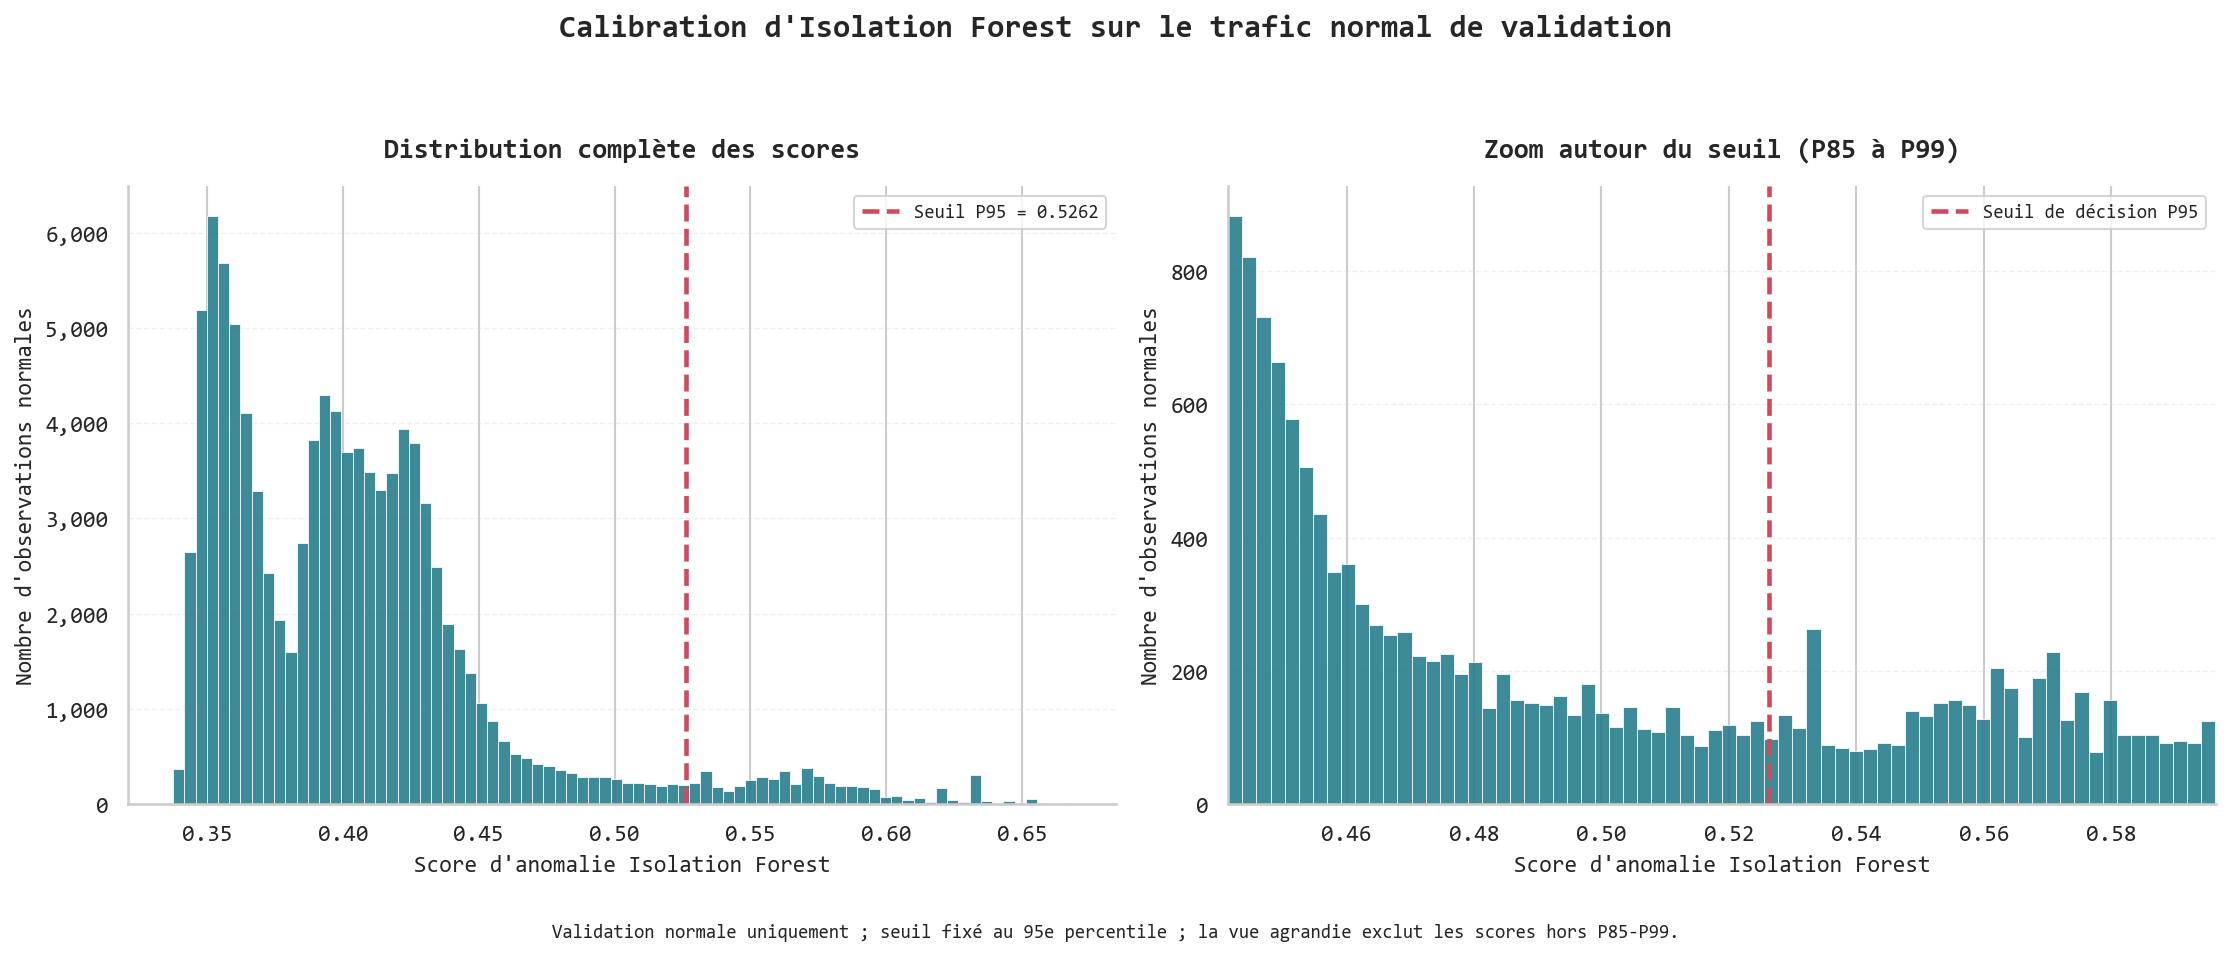


SYNTHESE DES FIGURES


,Indicateur,Valeur
0,Observations normales,102016.000000
1,Score minimum,0.337511
2,Score médian,0.396979
3,Score maximum,0.667883
4,Seuil P95,0.526246
5,Observations au-dessus du seuil,5101.000000
6,Taux de dépassement (%),5.000196
7,Borne inférieure du zoom,0.441440
8,Borne supérieure du zoom,0.596337


In [69]:
# ============================================================
# CELLULE 15 — DISTRIBUTION DES SCORES DE VALIDATION IF
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Visualiser les scores normaux de validation
# et le seuil fixe au 95e percentile.
#
# Score d'anomalie = -score_samples(X)
#
# Aucune modification du modele ou du seuil.
# Aucun calcul sur le test independant.
# ============================================================

import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from pathlib import Path


# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

if not globals().get("IF_VALIDATION_SCORES_READY", False):
    raise RuntimeError(
        "Les scores de validation ne sont pas disponibles. "
        "Executer correctement la cellule 13."
    )

if not globals().get("IF_CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "La calibration n'est pas terminee. "
        "Executer correctement la cellule 14."
    )

IF_VALIDATION_FIGURE_READY = False

required_objects = [
    "IF_validation_anomaly_scores",
    "IF_FIXED_THRESHOLD",
    "IF_CALIBRATION_PERCENTILE",
    "IF_ids_val_normal",
    "IF_SCIENTIFIC_FONT",
    "IF_FIGURES_DIR",
    "IF_TABLES_DIR",
    "IF_ARTIFACTS_DIR"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Variables manquantes : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. RECUPERATION DES SCORES
# ------------------------------------------------------------

IF_plot_scores = np.asarray(
    IF_validation_anomaly_scores,
    dtype=np.float64
)

IF_plot_threshold = float(
    IF_FIXED_THRESHOLD
)

if IF_plot_scores.ndim != 1:
    raise ValueError(
        "Les scores doivent etre un vecteur."
    )

if IF_plot_scores.size == 0:
    raise ValueError(
        "Aucun score disponible."
    )

if not np.isfinite(IF_plot_scores).all():
    raise ValueError(
        "Scores non finis detectes."
    )

if not np.isfinite(IF_plot_threshold):
    raise ValueError(
        "Le seuil n'est pas fini."
    )

if IF_plot_scores.size != len(IF_ids_val_normal):
    raise ValueError(
        "Incoherence du nombre d'observations."
    )

# ------------------------------------------------------------
# 3. VERIFICATION DU SEUIL
# ------------------------------------------------------------

IF_recalculated_threshold = float(
    np.percentile(
        IF_plot_scores,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_plot_threshold,
    IF_recalculated_threshold,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond pas au 95e percentile."
    )

if IF_CALIBRATION_PERCENTILE != 95:
    raise RuntimeError(
        "Percentile de calibration incorrect."
    )

# ------------------------------------------------------------
# 4. STATISTIQUES DESCRIPTIVES
# ------------------------------------------------------------

IF_n_scores = int(
    len(IF_plot_scores)
)

IF_n_above_threshold = int(
    np.count_nonzero(
        IF_plot_scores > IF_plot_threshold
    )
)

IF_n_below_or_equal = int(
    np.count_nonzero(
        IF_plot_scores <= IF_plot_threshold
    )
)

IF_above_rate = float(
    IF_n_above_threshold / IF_n_scores * 100
)

IF_score_median = float(
    np.median(IF_plot_scores)
)

IF_score_q99 = float(
    np.percentile(IF_plot_scores, 99)
)

IF_score_min = float(
    np.min(IF_plot_scores)
)

IF_score_max = float(
    np.max(IF_plot_scores)
)

print("\nSTATISTIQUES DE VALIDATION")

print("Observations :", f"{IF_n_scores:,}")

print(
    "Score minimum :",
    f"{IF_score_min:.8f}"
)

print(
    "Score median :",
    f"{IF_score_median:.8f}"
)

print(
    "Score maximum :",
    f"{IF_score_max:.8f}"
)

print(
    "Seuil P95 :",
    f"{IF_plot_threshold:.8f}"
)

print(
    "Observations au-dessus du seuil :",
    f"{IF_n_above_threshold:,}"
)

print(
    "Taux de depassement :",
    f"{IF_above_rate:.4f} %"
)

assert (
    IF_n_above_threshold
    + IF_n_below_or_equal
    == IF_n_scores
)

# ------------------------------------------------------------
# 5. CONFIGURATION SCIENTIFIQUE DES FIGURES
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid"
)

plt.rcParams.update({
    "font.family": IF_SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

IF_COLOR_DISTRIBUTION = "#287D8E"
IF_COLOR_THRESHOLD = "#D1495B"
IF_COLOR_ABOVE = "#E9C46A"

# ------------------------------------------------------------
# 6. PREPARATION DE LA VUE AGRANDIE
# ------------------------------------------------------------

# La seconde visualisation est limitee
# a la region allant du P85 au P99.
#
# Cela permet d'examiner la zone proche
# du seuil P95.
#
# Les observations hors de cette zone
# ne sont pas affichees dans ce zoom.

IF_zoom_lower = float(
    np.percentile(IF_plot_scores, 85)
)

IF_zoom_upper = float(
    np.percentile(IF_plot_scores, 99)
)

IF_zoom_mask = (
    (IF_plot_scores >= IF_zoom_lower)
    &
    (IF_plot_scores <= IF_zoom_upper)
)

IF_zoom_scores = IF_plot_scores[
    IF_zoom_mask
]

if IF_zoom_scores.size == 0:
    raise RuntimeError(
        "Aucune observation dans la zone de zoom."
    )

# ------------------------------------------------------------
# 7. CREATION DE LA FIGURE COMPLETE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    dpi=150
)

ax_full, ax_zoom = axes

# ------------------------------------------------------------
# 8. DISTRIBUTION COMPLETE
# ------------------------------------------------------------

ax_full.hist(
    IF_plot_scores,
    bins=80,
    color=IF_COLOR_DISTRIBUTION,
    edgecolor="white",
    linewidth=0.4,
    alpha=0.90
)

ax_full.axvline(
    IF_plot_threshold,
    color=IF_COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label=(
        "Seuil P95 = "
        f"{IF_plot_threshold:.4f}"
    )
)

ax_full.set_title(
    "Distribution complète des scores",
    fontsize=13,
    fontweight="bold",
    fontfamily=IF_SCIENTIFIC_FONT,
    pad=14
)

ax_full.set_xlabel(
    "Score d'anomalie Isolation Forest",
    fontsize=11,
    fontfamily=IF_SCIENTIFIC_FONT
)

ax_full.set_ylabel(
    "Nombre d'observations normales",
    fontsize=11,
    fontfamily=IF_SCIENTIFIC_FONT
)

ax_full.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("{x:,.0f}")
)

ax_full.legend(
    loc="upper right",
    fontsize=9
)

# ------------------------------------------------------------
# 9. DISTRIBUTION AGRANDIE
# ------------------------------------------------------------

ax_zoom.hist(
    IF_zoom_scores,
    bins=70,
    color=IF_COLOR_DISTRIBUTION,
    edgecolor="white",
    linewidth=0.4,
    alpha=0.90
)

ax_zoom.axvline(
    IF_plot_threshold,
    color=IF_COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label="Seuil de décision P95"
)

ax_zoom.set_xlim(
    IF_zoom_lower,
    IF_zoom_upper
)

ax_zoom.set_title(
    "Zoom autour du seuil (P85 à P99)",
    fontsize=13,
    fontweight="bold",
    fontfamily=IF_SCIENTIFIC_FONT,
    pad=14
)

ax_zoom.set_xlabel(
    "Score d'anomalie Isolation Forest",
    fontsize=11,
    fontfamily=IF_SCIENTIFIC_FONT
)

ax_zoom.set_ylabel(
    "Nombre d'observations normales",
    fontsize=11,
    fontfamily=IF_SCIENTIFIC_FONT
)

ax_zoom.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("{x:,.0f}")
)

ax_zoom.legend(
    loc="upper right",
    fontsize=9
)

# ------------------------------------------------------------
# 10. MISE EN FORME COMMUNE
# ------------------------------------------------------------

for ax in axes:

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.30
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ------------------------------------------------------------
# 11. TITRE GENERAL
# ------------------------------------------------------------

fig.suptitle(
    "Calibration d'Isolation Forest sur le trafic normal de validation",
    fontsize=15,
    fontweight="bold",
    fontfamily=IF_SCIENTIFIC_FONT,
    y=1.03
)

# ------------------------------------------------------------
# 12. NOTE METHODOLOGIQUE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.005,
    (
        "Validation normale uniquement ; "
        "seuil fixé au 95e percentile ; "
        "la vue agrandie exclut les scores hors P85-P99."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_SCIENTIFIC_FONT
)

plt.tight_layout(
    rect=(0, 0.045, 1, 0.98)
)

# ------------------------------------------------------------
# 13. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

IF_VALIDATION_FIGURE_NAME = (
    "distribution_scores_validation_normale_IF"
)

IF_VALIDATION_PNG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_VALIDATION_FIGURE_NAME}.png"
)

IF_VALIDATION_PDF_PATH = (
    IF_FIGURES_DIR /
    f"{IF_VALIDATION_FIGURE_NAME}.pdf"
)

IF_VALIDATION_SVG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_VALIDATION_FIGURE_NAME}.svg"
)

for path, file_format in [
    (IF_VALIDATION_PNG_PATH, "png"),
    (IF_VALIDATION_PDF_PATH, "pdf"),
    (IF_VALIDATION_SVG_PATH, "svg")
]:

    fig.savefig(
        path,
        format=file_format,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 14. TABLEAU DE SYNTHESE
# ------------------------------------------------------------

IF_VALIDATION_FIGURE_SUMMARY = pd.DataFrame({
    "Indicateur": [
        "Observations normales",
        "Score minimum",
        "Score médian",
        "Score maximum",
        "Seuil P95",
        "Observations au-dessus du seuil",
        "Taux de dépassement (%)",
        "Borne inférieure du zoom",
        "Borne supérieure du zoom"
    ],
    "Valeur": [
        float(IF_n_scores),
        IF_score_min,
        IF_score_median,
        IF_score_max,
        IF_plot_threshold,
        float(IF_n_above_threshold),
        IF_above_rate,
        IF_zoom_lower,
        IF_zoom_upper
    ]
})

print("\nSYNTHESE DES FIGURES")

display(
    IF_VALIDATION_FIGURE_SUMMARY
)

IF_VALIDATION_FIGURE_SUMMARY_PATH = (
    IF_TABLES_DIR /
    "resume_distribution_validation_IF.csv"
)

IF_VALIDATION_FIGURE_SUMMARY.to_csv(
    IF_VALIDATION_FIGURE_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_VALIDATION_FIGURE_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "validation_normale",
    "nombre_observations": IF_n_scores,
    "score": "-score_samples",
    "orientation": "higher_is_more_anomalous",
    "percentile_calibration": 95,
    "seuil": IF_plot_threshold,
    "operateur_decision": ">",
    "nombre_depassements": IF_n_above_threshold,
    "taux_depassement_pct": IF_above_rate,
    "zoom_percentiles": [85, 99],
    "zoom_borne_inferieure": IF_zoom_lower,
    "zoom_borne_superieure": IF_zoom_upper,
    "police": IF_SCIENTIFIC_FONT,
    "palette": "scientifique",
    "modele_modifie": False,
    "seuil_modifie": False,
    "test_utilise": False
}

IF_VALIDATION_FIGURE_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_figure_validation_IF.json"
)

with open(
    IF_VALIDATION_FIGURE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_VALIDATION_FIGURE_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )



In [78]:
# ============================================================
# CELLULE 16 — CALCUL DES SCORES SUR LE TEST INDEPENDANT
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Calculer les scores d'anomalie des observations
# normales et des attaques du test independant.
#
# Score = -score_samples(X)
#
# Aucun nouvel entrainement.
# Aucun recalibrage du seuil.
# ============================================================

import json
import time
import hashlib

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from scipy import sparse
from sklearn.ensemble import IsolationForest
from sklearn.utils.validation import check_is_fitted



# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

required_flags = {
    "IF_PROTOCOL_VALIDATED": "cellule 11",
    "IF_MODEL_TRAINED": "cellule 12",
    "IF_MATRICES_READY": "cellule 10",
    "IF_VALIDATION_SCORES_READY": "cellule 13",
    "IF_CALIBRATION_COMPLETED": "cellule 14"
}

for flag, cell in required_flags.items():

    if not globals().get(flag, False):
        raise RuntimeError(
            f"{flag} n'est pas valide. "
            f"Verifier la {cell}."
        )

IF_TEST_SCORES_READY = False

required_objects = [
    "IF_model",
    "IF_MODEL_PATH",
    "IF_MODEL_SHA256",
    "IF_X_test_csr",
    "IF_ids_test",
    "IF_y_test_array",
    "IF_y",
    "IF_FIXED_THRESHOLD",
    "IF_THRESHOLD_PATH",
    "IF_N_INPUT_FEATURES",
    "IF_SCORES_DIR",
    "IF_TABLES_DIR",
    "IF_ARTIFACTS_DIR"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. VERIFICATION DES FICHIERS
# ------------------------------------------------------------

IF_MODEL_PATH = Path(IF_MODEL_PATH)
IF_THRESHOLD_PATH = Path(IF_THRESHOLD_PATH)

if not IF_MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Modele introuvable : {IF_MODEL_PATH}"
    )

if not IF_THRESHOLD_PATH.is_file():
    raise FileNotFoundError(
        f"Seuil introuvable : {IF_THRESHOLD_PATH}"
    )

# ------------------------------------------------------------
# 3. VERIFICATION DE L'INTEGRITE DU MODELE
# ------------------------------------------------------------

def IF_test_sha256(path):

    sha = hashlib.sha256()

    with open(path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha.update(block)

    return sha.hexdigest()


IF_TEST_MODEL_SHA256 = IF_test_sha256(
    IF_MODEL_PATH
)

if IF_TEST_MODEL_SHA256 != IF_MODEL_SHA256:
    raise RuntimeError(
        "Le modele sauvegarde a ete modifie "
        "depuis l'entrainement."
    )

# ------------------------------------------------------------
# 4. RECHARGEMENT DU MODELE
# ------------------------------------------------------------

# Charger exclusivement le modele sauvegarde
# par notre propre experience locale.

IF_test_model = joblib.load(
    IF_MODEL_PATH
)

if not isinstance(
    IF_test_model,
    IsolationForest
):
    raise TypeError(
        "Le fichier charge n'est pas un IsolationForest."
    )

check_is_fitted(
    IF_test_model
)

if IF_test_model.n_features_in_ != IF_N_INPUT_FEATURES:
    raise RuntimeError(
        "Nombre de caracteristiques incompatible."
    )

print("\nModele de reference : VALIDE")

# ------------------------------------------------------------
# 5. VERIFICATION DU SEUIL FIXE
# ------------------------------------------------------------

with open(
    IF_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:

    IF_test_threshold_report = json.load(file)

IF_test_threshold = float(
    IF_test_threshold_report["seuil"]
)

if not np.isclose(
    IF_test_threshold,
    IF_FIXED_THRESHOLD,
    rtol=1e-12,
    atol=0
):
    raise RuntimeError(
        "Le seuil sauvegarde ne correspond pas "
        "au seuil de calibration."
    )

if IF_test_threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "L'origine du seuil est incorrecte."
    )

if IF_test_threshold_report.get("percentile") != 95:
    raise RuntimeError(
        "Le percentile de calibration est incorrect."
    )

print("\nSeuil fixe : VALIDE")

print(
    "Seuil :",
    f"{IF_test_threshold:.12f}"
)

# ------------------------------------------------------------
# 6. PREPARATION DE LA MATRICE DU TEST
# ------------------------------------------------------------

IF_TEST_MATRIX = IF_X_test_csr

if not sparse.isspmatrix_csr(IF_TEST_MATRIX):
    raise TypeError(
        "La matrice du test doit etre au format CSR."
    )

if IF_TEST_MATRIX.dtype != np.float32:
    raise TypeError(
        "Le test doit etre en float32."
    )

if IF_TEST_MATRIX.shape[1] != IF_N_INPUT_FEATURES:
    raise ValueError(
        "Dimensions du test incompatibles."
    )

if not np.isfinite(IF_TEST_MATRIX.data).all():
    raise ValueError(
        "Valeurs non finies dans le test."
    )

IF_N_TEST_SCORES = IF_TEST_MATRIX.shape[0]

if IF_N_TEST_SCORES == 0:
    raise ValueError(
        "La matrice du test est vide."
    )

if IF_N_TEST_SCORES != len(IF_ids_test):
    raise ValueError(
        "Effectif du test incompatible "
        "avec les identifiants."
    )

# ------------------------------------------------------------
# 7. ALIGNEMENT DES ETIQUETTES
# ------------------------------------------------------------

IF_test_labels = np.asarray(
    IF_y_test_array,
    dtype=np.int8
)

IF_test_ids = np.asarray(
    IF_ids_test,
    dtype=np.int64
)

if len(IF_test_labels) != IF_N_TEST_SCORES:
    raise ValueError(
        "Effectif des etiquettes incorrect."
    )

if not np.array_equal(
    IF_test_labels,
    IF_y.iloc[IF_test_ids].to_numpy(
        dtype=np.int8
    )
):
    raise RuntimeError(
        "Etiquettes non alignees avec "
        "les observations du test."
    )

if set(np.unique(IF_test_labels)) != {0, 1}:
    raise RuntimeError(
        "Le test doit contenir du trafic normal "
        "et des attaques."
    )

IF_N_TEST_NORMAL = int(
    np.sum(IF_test_labels == 0)
)

IF_N_TEST_ATTACK = int(
    np.sum(IF_test_labels == 1)
)

print("\nPOPULATION DU TEST")

print(
    "Observations :",
    f"{IF_N_TEST_SCORES:,}"
)

print(
    "Trafic normal :",
    f"{IF_N_TEST_NORMAL:,}"
)

print(
    "Attaques :",
    f"{IF_N_TEST_ATTACK:,}"
)

# ------------------------------------------------------------
# 8. CALCUL DES SCORES BRUTS DU TEST
# ------------------------------------------------------------

print("\nCalcul des scores d'anomalie du test...")

IF_TEST_SCORE_START = time.perf_counter()

# Cette operation est une evaluation.
# Aucun fit() n'est effectue sur le test.

IF_test_raw_scores = (
    IF_test_model.score_samples(
        IF_TEST_MATRIX
    )
)

IF_TEST_SCORE_DURATION = (
    time.perf_counter()
    - IF_TEST_SCORE_START
)

# ------------------------------------------------------------
# 9. INVERSION DE LA CONVENTION DES SCORES
# ------------------------------------------------------------

IF_test_anomaly_scores = (
    -np.asarray(
        IF_test_raw_scores,
        dtype=np.float64
    )
)

# Orientation :
# score eleve = observation plus anormale.

IF_TEST_SCORE_DIRECTION = (
    "higher_is_more_anomalous"
)

# ------------------------------------------------------------
# 10. VERIFICATION DES SCORES
# ------------------------------------------------------------

if IF_test_anomaly_scores.ndim != 1:
    raise ValueError(
        "Les scores doivent etre un vecteur."
    )

if len(IF_test_anomaly_scores) != IF_N_TEST_SCORES:
    raise ValueError(
        "Nombre de scores incorrect."
    )

if not np.isfinite(
    IF_test_anomaly_scores
).all():
    raise ValueError(
        "Scores non finis detectes."
    )

if not np.allclose(
    IF_test_anomaly_scores,
    -IF_test_raw_scores,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Orientation des scores incoherente."
    )

print("\nScores du test calcules : OUI")

print(
    "Duree :",
    f"{IF_TEST_SCORE_DURATION:.2f} secondes"
)

# ------------------------------------------------------------
# 11. STATISTIQUES DESCRIPTIVES PAR CLASSE
# ------------------------------------------------------------

IF_normal_scores_test = (
    IF_test_anomaly_scores[
        IF_test_labels == 0
    ]
)

IF_attack_scores_test = (
    IF_test_anomaly_scores[
        IF_test_labels == 1
    ]
)

def IF_describe_scores(scores, group_name):

    return {
        "Population": group_name,
        "Effectif": int(len(scores)),
        "Minimum": float(np.min(scores)),
        "Moyenne": float(np.mean(scores)),
        "Mediane": float(np.median(scores)),
        "Ecart_type": float(np.std(scores)),
        "Percentile_5": float(
            np.percentile(scores, 5)
        ),
        "Percentile_25": float(
            np.percentile(scores, 25)
        ),
        "Percentile_75": float(
            np.percentile(scores, 75)
        ),
        "Percentile_95": float(
            np.percentile(scores, 95)
        ),
        "Maximum": float(np.max(scores))
    }


IF_TEST_SCORE_STATISTICS = pd.DataFrame([
    IF_describe_scores(
        IF_normal_scores_test,
        "Trafic normal"
    ),
    IF_describe_scores(
        IF_attack_scores_test,
        "Attaques"
    )
])

print("\nSTATISTIQUES DES SCORES PAR CLASSE")

display(
    IF_TEST_SCORE_STATISTICS
)

# ------------------------------------------------------------
# 12. TABLEAU DES SCORES INDIVIDUELS
# ------------------------------------------------------------

IF_test_scores_table = pd.DataFrame({
    "ID_observation": IF_test_ids,
    "Classe_reelle": IF_test_labels,
    "Score_brut_IF": IF_test_raw_scores,
    "Score_anomalie_IF": IF_test_anomaly_scores
})

# Les classes ne sont utilisees que pour
# la description et l'evaluation.

print("\nAPERÇU DES SCORES DU TEST")

display(
    IF_test_scores_table.head(10)
)

# ------------------------------------------------------------
# 13. VERIFICATION DE L'ALIGNEMENT
# ------------------------------------------------------------

if not np.array_equal(
    IF_test_scores_table[
        "ID_observation"
    ].to_numpy(),
    IF_test_ids
):
    raise RuntimeError(
        "Ordre des observations modifie."
    )

if not np.array_equal(
    IF_test_scores_table[
        "Classe_reelle"
    ].to_numpy(),
    IF_test_labels
):
    raise RuntimeError(
        "Alignement des etiquettes incorrect."
    )

# ------------------------------------------------------------
# 14. SAUVEGARDE DES SCORES
# ------------------------------------------------------------

IF_TEST_SCORES_PATH = (
    IF_SCORES_DIR /
    "scores_test_Isolation_Forest.npy"
)

IF_TEST_RAW_SCORES_PATH = (
    IF_SCORES_DIR /
    "scores_bruts_test_Isolation_Forest.npy"
)

IF_TEST_SCORES_CSV_PATH = (
    IF_TABLES_DIR /
    "scores_test_Isolation_Forest.csv"
)

np.save(
    IF_TEST_SCORES_PATH,
    IF_test_anomaly_scores
)

np.save(
    IF_TEST_RAW_SCORES_PATH,
    IF_test_raw_scores
)

IF_test_scores_table.to_csv(
    IF_TEST_SCORES_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_TEST_SCORE_STATISTICS.to_csv(
    IF_TABLES_DIR /
    "statistiques_scores_test_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. VERIFICATION DES FICHIERS SAUVEGARDES
# ------------------------------------------------------------

IF_saved_test_scores = np.load(
    IF_TEST_SCORES_PATH,
    allow_pickle=False
)

IF_saved_test_raw_scores = np.load(
    IF_TEST_RAW_SCORES_PATH,
    allow_pickle=False
)

if not np.array_equal(
    IF_saved_test_scores,
    IF_test_anomaly_scores
):
    raise RuntimeError(
        "Les scores sauvegardes sont differents."
    )

if not np.array_equal(
    IF_saved_test_raw_scores,
    IF_test_raw_scores
):
    raise RuntimeError(
        "Les scores bruts sauvegardes different."
    )

# ------------------------------------------------------------
# 16. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_TEST_SCORE_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "ensemble": "test_independant_IF",
    "nombre_observations": int(
        IF_N_TEST_SCORES
    ),
    "nombre_normaux": int(
        IF_N_TEST_NORMAL
    ),
    "nombre_attaques": int(
        IF_N_TEST_ATTACK
    ),
    "nombre_caracteristiques": int(
        IF_N_INPUT_FEATURES
    ),
    "score": "-score_samples",
    "orientation": IF_TEST_SCORE_DIRECTION,
    "seuil_fixe": float(
        IF_test_threshold
    ),
    "population_calibration": "validation_normale",
    "percentile_calibration": 95,
    "duree_calcul_secondes": float(
        IF_TEST_SCORE_DURATION
    ),
    "sha256_modele": IF_TEST_MODEL_SHA256,
    "fichier_scores": str(
        IF_TEST_SCORES_PATH
    ),
    "test_utilise_pour_fit": False,
    "test_utilise_pour_calibration": False,
    "seuil_recalibre": False,
    "modele_modifie": False,
    "comparabilite_test_DDAE_verifiee": False
}

IF_TEST_SCORE_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_scores_test_Isolation_Forest.json"
)

with open(
    IF_TEST_SCORE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        IF_TEST_SCORE_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )



Modele de reference : VALIDE

Seuil fixe : VALIDE
Seuil : 0.526246425292

POPULATION DU TEST
Observations : 104,871
Trafic normal : 101,507
Attaques : 3,364

Calcul des scores d'anomalie du test...

Scores du test calcules : OUI
Duree : 2.83 secondes

STATISTIQUES DES SCORES PAR CLASSE


,Population,Effectif,Minimum,Moyenne,Mediane,Ecart_type,Percentile_5,Percentile_25,Percentile_75,Percentile_95,Maximum
0,Trafic normal,101507,0.336851,0.403523,0.396557,0.051410,0.347682,0.362557,0.425237,0.509571,0.697460
1,Attaques,3364,0.428085,0.581606,0.593145,0.043851,0.499431,0.546577,0.616636,0.637874,0.681928



APERÇU DES SCORES DU TEST


,ID_observation,Classe_reelle,Score_brut_IF,Score_anomalie_IF
0,0,0,-0.416174,0.416174
1,2,0,-0.416966,0.416966
2,4,0,-0.408304,0.408304
3,7,0,-0.606473,0.606473
4,10,0,-0.606473,0.606473
5,11,0,-0.606473,0.606473
6,12,0,-0.606473,0.606473
7,31,0,-0.418060,0.418060
8,37,0,-0.413346,0.413346
9,56,0,-0.428944,0.428944


In [79]:

# ============================================================
# CORRECTION — VALIDATION DES SCORES DU TEST
# ISOLATION FOREST
# ============================================================

import numpy as np

from pathlib import Path

print("=" * 70)
print("VALIDATION DES SCORES DU TEST ISOLATION FOREST")
print("=" * 70)

IF_TEST_SCORES_READY = False

# ------------------------------------------------------------
# 1. Verification des variables indispensables
# ------------------------------------------------------------

required = [
    "IF_test_anomaly_scores",
    "IF_test_raw_scores",
    "IF_test_labels",
    "IF_test_ids",
    "IF_ids_test",
    "IF_y",
    "IF_FIXED_THRESHOLD",
    "IF_TEST_SCORES_PATH",
    "IF_TEST_RAW_SCORES_PATH",
    "IF_TEST_SCORE_REPORT_PATH"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Variables manquantes : {missing}. "
        "Reexecuter la cellule 16."
    )

# ------------------------------------------------------------
# 2. Recuperation des scores
# ------------------------------------------------------------

scores = np.asarray(
    IF_test_anomaly_scores,
    dtype=np.float64
)

raw_scores = np.asarray(
    IF_test_raw_scores,
    dtype=np.float64
)

labels = np.asarray(
    IF_test_labels,
    dtype=np.int8
)

ids = np.asarray(
    IF_test_ids,
    dtype=np.int64
)

# ------------------------------------------------------------
# 3. Verification des dimensions
# ------------------------------------------------------------

if not (
    scores.ndim == 1
    and raw_scores.ndim == 1
    and labels.ndim == 1
    and ids.ndim == 1
):
    raise ValueError(
        "Les tableaux doivent etre unidimensionnels."
    )

if not (
    len(scores)
    == len(raw_scores)
    == len(labels)
    == len(ids)
    == len(IF_ids_test)
):
    raise ValueError(
        "Scores, etiquettes ou identifiants mal alignes."
    )

if len(scores) == 0:
    raise ValueError(
        "Aucun score du test disponible."
    )

# ------------------------------------------------------------
# 4. Verification des valeurs
# ------------------------------------------------------------

if not np.isfinite(scores).all():
    raise ValueError(
        "Les scores contiennent NaN ou inf."
    )

if not np.isfinite(raw_scores).all():
    raise ValueError(
        "Les scores bruts contiennent NaN ou inf."
    )

if not np.isfinite(float(IF_FIXED_THRESHOLD)):
    raise ValueError(
        "Le seuil de classification n'est pas fini."
    )

# ------------------------------------------------------------
# 5. Verification de l'orientation
# ------------------------------------------------------------

if not np.allclose(
    scores,
    -raw_scores,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "L'orientation des scores est incorrecte."
    )

# ------------------------------------------------------------
# 6. Verification des identifiants
# ------------------------------------------------------------

if not np.array_equal(
    ids,
    np.asarray(IF_ids_test, dtype=np.int64)
):
    raise RuntimeError(
        "Les identifiants ne correspondent pas "
        "aux partitions du test."
    )

if not np.array_equal(
    labels,
    IF_y.iloc[ids].to_numpy(dtype=np.int8)
):
    raise RuntimeError(
        "Les etiquettes reelles sont mal alignees."
    )

if set(np.unique(labels)) != {0, 1}:
    raise RuntimeError(
        "Le test doit contenir les deux classes."
    )

# ------------------------------------------------------------
# 7. Verification des fichiers sauvegardes
# ------------------------------------------------------------

scores_path = Path(IF_TEST_SCORES_PATH)
raw_path = Path(IF_TEST_RAW_SCORES_PATH)
report_path = Path(IF_TEST_SCORE_REPORT_PATH)

for path in [
    scores_path,
    raw_path,
    report_path
]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Fichier absent : {path}"
        )

saved_scores = np.load(
    scores_path,
    allow_pickle=False
)

saved_raw_scores = np.load(
    raw_path,
    allow_pickle=False
)

if not np.array_equal(saved_scores, scores):
    raise RuntimeError(
        "Les scores exportes different de la memoire."
    )

if not np.array_equal(saved_raw_scores, raw_scores):
    raise RuntimeError(
        "Les scores bruts exportes different."
    )

# ------------------------------------------------------------
# 8. Verification du rapport
# ------------------------------------------------------------

import json

with open(
    report_path,
    "r",
    encoding="utf-8"
) as file:
    report = json.load(file)

if report.get("nombre_observations") != len(scores):
    raise RuntimeError(
        "L'effectif du rapport est incoherent."
    )

if report.get("score") != "-score_samples":
    raise RuntimeError(
        "Convention de scoring incorrecte."
    )

if report.get("seuil_recalibre") is not False:
    raise RuntimeError(
        "Le rapport n'atteste pas un seuil inchange."
    )

# ------------------------------------------------------------
# 9. Validation finale
# ------------------------------------------------------------

IF_TEST_SCORES_READY = True

print("\nScores du test :", f"{len(scores):,}")
print("Trafic normal :", int(np.sum(labels == 0)))
print("Attaques :", int(np.sum(labels == 1)))

print("\nScores finis : OUI")
print("Orientation des scores : CORRECTE")
print("Alignement des observations : VALIDE")
print("Fichiers sauvegardes : COHERENTS")

print("\nIF_TEST_SCORES_READY :", IF_TEST_SCORES_READY)

print("=" * 70)
print("SCORES DU TEST VALIDES")
print("CELLULE 17 AUTORISEE")
print("=" * 70)


VALIDATION DES SCORES DU TEST ISOLATION FOREST

Scores du test : 104,871
Trafic normal : 101507
Attaques : 3364

Scores finis : OUI
Orientation des scores : CORRECTE
Alignement des observations : VALIDE
Fichiers sauvegardes : COHERENTS

IF_TEST_SCORES_READY : True
SCORES DU TEST VALIDES
CELLULE 17 AUTORISEE


In [80]:

# ============================================================
# CELLULE 17 — CLASSIFICATION BINAIRE ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Appliquer le seuil P95 de validation normale
# aux scores du test independant.
#
# Score = -score_samples(X)
#
# 0 = Trafic normal
# 1 = Attaque
#
# Aucune modification du modele.
# Aucun recalibrage sur le test.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("CELLULE 17 — CLASSIFICATION DU TEST ISOLATION FOREST")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

IF_CLASSIFICATION_READY = False

required_flags = {
    "IF_PROTOCOL_VALIDATED": "cellule 11",
    "IF_MODEL_TRAINED": "cellule 12",
    "IF_CALIBRATION_COMPLETED": "cellule 14",
    "IF_TEST_SCORES_READY": "cellule 16"
}

for flag, cellule in required_flags.items():

    if not globals().get(flag, False):
        raise RuntimeError(
            f"{flag} n'est pas valide. "
            f"Verifier la {cellule}."
        )

required_objects = [
    "IF_test_anomaly_scores",
    "IF_test_raw_scores",
    "IF_test_labels",
    "IF_test_ids",
    "IF_FIXED_THRESHOLD",
    "IF_THRESHOLD_PATH",
    "IF_VALIDATION_SCORES_PATH",
    "IF_TEST_SCORES_PATH",
    "IF_MODEL_PATH",
    "IF_MODEL_SHA256",
    "IF_SCORES_DIR",
    "IF_TABLES_DIR",
    "IF_ARTIFACTS_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. RECUPERATION DES SCORES ET ETIQUETTES
# ------------------------------------------------------------

IF_scores_classification = np.asarray(
    IF_test_anomaly_scores,
    dtype=np.float64
)

IF_raw_scores_classification = np.asarray(
    IF_test_raw_scores,
    dtype=np.float64
)

IF_labels_classification = np.asarray(
    IF_test_labels,
    dtype=np.int8
)

IF_ids_classification = np.asarray(
    IF_test_ids,
    dtype=np.int64
)

IF_threshold_classification = float(
    IF_FIXED_THRESHOLD
)

# ------------------------------------------------------------
# 3. VERIFICATION DES DIMENSIONS
# ------------------------------------------------------------

IF_n_classification = len(
    IF_scores_classification
)

if IF_n_classification == 0:
    raise ValueError(
        "Aucun score de test disponible."
    )

if not (
    IF_scores_classification.ndim == 1
    and IF_raw_scores_classification.ndim == 1
    and IF_labels_classification.ndim == 1
    and IF_ids_classification.ndim == 1
):
    raise ValueError(
        "Les donnees doivent etre des vecteurs."
    )

if not (
    len(IF_scores_classification)
    == len(IF_raw_scores_classification)
    == len(IF_labels_classification)
    == len(IF_ids_classification)
):
    raise RuntimeError(
        "Les scores, etiquettes et identifiants "
        "ne sont pas alignes."
    )

if not np.isfinite(
    IF_scores_classification
).all():
    raise ValueError(
        "Scores de test non finis."
    )

if not np.isfinite(
    IF_raw_scores_classification
).all():
    raise ValueError(
        "Scores bruts non finis."
    )

if not np.isfinite(
    IF_threshold_classification
):
    raise ValueError(
        "Seuil de decision non fini."
    )

if set(np.unique(
    IF_labels_classification
)) != {0, 1}:
    raise RuntimeError(
        "Le test doit contenir les classes 0 et 1."
    )

# ------------------------------------------------------------
# 4. CONTROLE DE L'ORIENTATION DES SCORES
# ------------------------------------------------------------

# Le score croissant d'anomalie doit etre
# exactement l'oppose du score brut sklearn.

if not np.allclose(
    IF_scores_classification,
    -IF_raw_scores_classification,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Orientation des scores incorrecte."
    )

print("\nConvention des scores : VALIDEE")
print("Score eleve = anomalie potentielle")

# ------------------------------------------------------------
# 5. CHARGEMENT DU SEUIL SAUVEGARDE
# ------------------------------------------------------------

IF_THRESHOLD_PATH = Path(
    IF_THRESHOLD_PATH
)

if not IF_THRESHOLD_PATH.is_file():
    raise FileNotFoundError(
        f"Fichier de calibration absent : "
        f"{IF_THRESHOLD_PATH}"
    )

with open(
    IF_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    IF_saved_threshold_report = json.load(file)

IF_saved_threshold = float(
    IF_saved_threshold_report["seuil"]
)

if not np.isclose(
    IF_saved_threshold,
    IF_threshold_classification,
    rtol=1e-12,
    atol=0
):
    raise RuntimeError(
        "Le seuil courant differe du seuil "
        "sauvegarde lors de la calibration."
    )

if (
    IF_saved_threshold_report.get(
        "population_calibration"
    ) != "validation_normale"
):
    raise RuntimeError(
        "Population de calibration incorrecte."
    )

if (
    IF_saved_threshold_report.get("percentile")
    != 95
):
    raise RuntimeError(
        "Le percentile de calibration doit etre 95."
    )

if (
    IF_saved_threshold_report.get(
        "operateur_decision"
    ) != ">"
):
    raise RuntimeError(
        "Operateur de classification incorrect."
    )

if (
    IF_saved_threshold_report.get("orientation")
    != "higher_is_more_anomalous"
):
    raise RuntimeError(
        "Orientation sauvegardee incorrecte."
    )

# ------------------------------------------------------------
# 6. VERIFICATION DU SEUIL DE VALIDATION
# ------------------------------------------------------------

# Ce controle recharge uniquement les scores
# normaux de validation deja calcules.
#
# Aucune donnee du test n'est utilisee
# pour recalculer le seuil.

IF_validation_scores_check = np.load(
    IF_VALIDATION_SCORES_PATH,
    allow_pickle=False
)

IF_threshold_recalculated = float(
    np.percentile(
        IF_validation_scores_check,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_threshold_classification,
    IF_threshold_recalculated,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond plus au P95 "
        "de validation normale."
    )

print("\nCALIBRATION : VALIDEE")

print(
    "Seuil operationnel :",
    f"{IF_threshold_classification:.12f}"
)

print("Origine : validation normale")
print("Percentile : 95")

# ------------------------------------------------------------
# 7. CONTROLE DE L'INTEGRITE DU MODELE
# ------------------------------------------------------------

def IF_classification_sha256(file_path):

    sha = hashlib.sha256()

    with open(file_path, "rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha.update(block)

    return sha.hexdigest()


IF_MODEL_PATH = Path(
    IF_MODEL_PATH
)

if not IF_MODEL_PATH.is_file():
    raise FileNotFoundError(
        "Modele Isolation Forest introuvable."
    )

IF_current_model_hash = IF_classification_sha256(
    IF_MODEL_PATH
)

if IF_current_model_hash != IF_MODEL_SHA256:
    raise RuntimeError(
        "Le modele a ete modifie apres son entrainement."
    )

# ------------------------------------------------------------
# 8. APPLICATION DU SEUIL AU TEST
# ------------------------------------------------------------

# C'EST L'UNIQUE REGLE DE CLASSIFICATION.
#
# Le seuil est deja fixe et valide.
#
# Aucune etiquette reelle n'intervient
# dans le calcul des predictions.

IF_y_pred_test = (
    IF_scores_classification
    > IF_threshold_classification
).astype(np.int8)

assert IF_y_pred_test.shape == (
    IF_n_classification,
)

assert set(
    np.unique(IF_y_pred_test)
).issubset({0, 1})

print("\nCLASSIFICATION BINAIRE TERMINEE")

# ------------------------------------------------------------
# 9. EFFECTIFS DES CLASSES PREDITES
# ------------------------------------------------------------

IF_n_pred_normal = int(
    np.sum(IF_y_pred_test == 0)
)

IF_n_pred_attack = int(
    np.sum(IF_y_pred_test == 1)
)

IF_predicted_anomaly_rate = float(
    IF_n_pred_attack / IF_n_classification
)

print("\nREPARTITION DES PREDICTIONS")

print(
    "Trafic normal predit :",
    f"{IF_n_pred_normal:,}"
)

print(
    "Anomalies predites :",
    f"{IF_n_pred_attack:,}"
)

print(
    "Proportion d'alertes :",
    f"{100 * IF_predicted_anomaly_rate:.4f} %"
)

# Attention :
# cette proportion correspond au taux
# d'alertes parmi toutes les observations
# du test, et non au taux de faux positifs.

# ------------------------------------------------------------
# 10. CREATION DU TABLEAU INDIVIDUEL
# ------------------------------------------------------------

IF_prediction_labels = np.where(
    IF_y_pred_test == 1,
    "Attaque",
    "Trafic normal"
)

IF_CLASSIFICATION_TABLE = pd.DataFrame({
    "ID_observation": IF_ids_classification,
    "Score_brut_IF": (
        IF_raw_scores_classification
    ),
    "Score_anomalie_IF": (
        IF_scores_classification
    ),
    "Seuil_IF": (
        IF_threshold_classification
    ),
    "Classe_predite": (
        IF_y_pred_test
    ),
    "Interpretation": (
        IF_prediction_labels
    )
})

# Les etiquettes reelles seront conservees
# dans un tableau distinct pour l'evaluation.

IF_EVALUATION_TABLE = (
    IF_CLASSIFICATION_TABLE.copy()
)

IF_EVALUATION_TABLE[
    "Classe_reelle"
] = IF_labels_classification

# ------------------------------------------------------------
# 11. VERIFICATION DE L'ALIGNEMENT
# ------------------------------------------------------------

if not np.array_equal(
    IF_CLASSIFICATION_TABLE[
        "ID_observation"
    ].to_numpy(),
    IF_ids_classification
):
    raise RuntimeError(
        "Identifiants de test non alignes."
    )

if not np.array_equal(
    IF_CLASSIFICATION_TABLE[
        "Classe_predite"
    ].to_numpy(),
    IF_y_pred_test
):
    raise RuntimeError(
        "Predictions non alignees."
    )

if not np.array_equal(
    IF_EVALUATION_TABLE[
        "Classe_reelle"
    ].to_numpy(),
    IF_labels_classification
):
    raise RuntimeError(
        "Etiquettes reelles non alignees."
    )

# ------------------------------------------------------------
# 12. TABLEAU RECAPITULATIF
# ------------------------------------------------------------

IF_CLASSIFICATION_SUMMARY = pd.DataFrame({
    "Classe_predite": [
        "Trafic normal",
        "Attaque"
    ],
    "Effectif": [
        IF_n_pred_normal,
        IF_n_pred_attack
    ],
    "Pourcentage": [
        (
            100 * IF_n_pred_normal
            / IF_n_classification
        ),
        (
            100 * IF_n_pred_attack
            / IF_n_classification
        )
    ]
})

print("\nSYNTHESE DES PREDICTIONS")

display(
    IF_CLASSIFICATION_SUMMARY
)

print("\nAPERÇU DES PREDICTIONS INDIVIDUELLES")

display(
    IF_CLASSIFICATION_TABLE.head(10)
)

# ------------------------------------------------------------
# 13. SAUVEGARDE DES PREDICTIONS
# ------------------------------------------------------------

IF_PREDICTIONS_PATH = (
    IF_SCORES_DIR /
    "predictions_test_Isolation_Forest.npy"
)

IF_CLASSIFICATION_CSV_PATH = (
    IF_TABLES_DIR /
    "classifications_test_Isolation_Forest.csv"
)

IF_EVALUATION_CSV_PATH = (
    IF_TABLES_DIR /
    "predictions_et_etiquettes_test_IF.csv"
)

np.save(
    IF_PREDICTIONS_PATH,
    IF_y_pred_test
)

IF_CLASSIFICATION_TABLE.to_csv(
    IF_CLASSIFICATION_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_EVALUATION_TABLE.to_csv(
    IF_EVALUATION_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_CLASSIFICATION_SUMMARY.to_csv(
    IF_TABLES_DIR /
    "resume_classification_test_IF.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

IF_saved_predictions = np.load(
    IF_PREDICTIONS_PATH,
    allow_pickle=False
)

if not np.array_equal(
    IF_saved_predictions,
    IF_y_pred_test
):
    raise RuntimeError(
        "Les predictions sauvegardees different."
    )

IF_saved_test_scores = np.load(
    IF_TEST_SCORES_PATH,
    allow_pickle=False
)

if not np.array_equal(
    IF_saved_test_scores,
    IF_scores_classification
):
    raise RuntimeError(
        "Les scores du test ont ete modifies."
    )

# ------------------------------------------------------------
# 15. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_CLASSIFICATION_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "ensemble": "test_independant_IF",
    "observations": int(
        IF_n_classification
    ),
    "classe_normale": 0,
    "classe_attaque": 1,
    "score": "-score_samples",
    "orientation": "higher_is_more_anomalous",
    "seuil": float(
        IF_threshold_classification
    ),
    "percentile_calibration": 95,
    "population_calibration": "validation_normale",
    "operateur_decision": ">",
    "predictions_normales": int(
        IF_n_pred_normal
    ),
    "predictions_attaques": int(
        IF_n_pred_attack
    ),
    "proportion_alertes": float(
        IF_predicted_anomaly_rate
    ),
    "modele_sha256": IF_current_model_hash,
    "seuil_recalibre": False,
    "modele_reentraine": False,
    "test_utilise_pour_optimisation": False,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_CLASSIFICATION_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_classification_test_IF.json"
)

with open(
    IF_CLASSIFICATION_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        IF_CLASSIFICATION_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )


CELLULE 17 — CLASSIFICATION DU TEST ISOLATION FOREST

Convention des scores : VALIDEE
Score eleve = anomalie potentielle

CALIBRATION : VALIDEE
Seuil operationnel : 0.526246425292
Origine : validation normale
Percentile : 95

CLASSIFICATION BINAIRE TERMINEE

REPARTITION DES PREDICTIONS
Trafic normal predit : 97,693
Anomalies predites : 7,178
Proportion d'alertes : 6.8446 %

SYNTHESE DES PREDICTIONS


,Classe_predite,Effectif,Pourcentage
0,Trafic normal,97693,93.1554
1,Attaque,7178,6.8446



APERÇU DES PREDICTIONS INDIVIDUELLES


,ID_observation,Score_brut_IF,Score_anomalie_IF,Seuil_IF,Classe_predite,Interpretation
0,0,-0.416174,0.416174,0.526246,0,Trafic normal
1,2,-0.416966,0.416966,0.526246,0,Trafic normal
2,4,-0.408304,0.408304,0.526246,0,Trafic normal
3,7,-0.606473,0.606473,0.526246,1,Attaque
4,10,-0.606473,0.606473,0.526246,1,Attaque
5,11,-0.606473,0.606473,0.526246,1,Attaque
6,12,-0.606473,0.606473,0.526246,1,Attaque
7,31,-0.418060,0.418060,0.526246,0,Trafic normal
8,37,-0.413346,0.413346,0.526246,0,Trafic normal
9,56,-0.428944,0.428944,0.526246,0,Trafic normal


In [82]:

# ============================================================
# VALIDATION DE LA CELLULE 17 — ISOLATION FOREST
# ============================================================

import json
import numpy as np

from pathlib import Path

print("=" * 70)
print("VALIDATION DE LA CLASSIFICATION ISOLATION FOREST")
print("=" * 70)

IF_CLASSIFICATION_READY = False

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

required_flags = [
    "IF_PROTOCOL_VALIDATED",
    "IF_CALIBRATION_COMPLETED",
    "IF_TEST_SCORES_READY"
]

for flag in required_flags:

    if not globals().get(flag, False):
        raise RuntimeError(
            f"Prerequis non valide : {flag}"
        )

# ------------------------------------------------------------
# 2. Verification des variables
# ------------------------------------------------------------

required_objects = [
    "IF_y_pred_test",
    "IF_test_anomaly_scores",
    "IF_test_labels",
    "IF_test_ids",
    "IF_ids_test",
    "IF_y",
    "IF_FIXED_THRESHOLD",
    "IF_PREDICTIONS_PATH",
    "IF_CLASSIFICATION_REPORT_PATH",
    "IF_THRESHOLD_PATH"
]

missing = [
    name
    for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Variables manquantes : {missing}. "
        "Reexecuter la cellule 17."
    )

# ------------------------------------------------------------
# 3. Recuperation des donnees
# ------------------------------------------------------------

predictions = np.asarray(
    IF_y_pred_test,
    dtype=np.int8
)

scores = np.asarray(
    IF_test_anomaly_scores,
    dtype=np.float64
)

labels = np.asarray(
    IF_test_labels,
    dtype=np.int8
)

ids = np.asarray(
    IF_test_ids,
    dtype=np.int64
)

threshold = float(
    IF_FIXED_THRESHOLD
)

# ------------------------------------------------------------
# 4. Verification des dimensions
# ------------------------------------------------------------

if not all(
    array.ndim == 1
    for array in [
        predictions,
        scores,
        labels,
        ids
    ]
):
    raise ValueError(
        "Les tableaux doivent etre unidimensionnels."
    )

if not (
    len(predictions)
    == len(scores)
    == len(labels)
    == len(ids)
    == len(IF_ids_test)
):
    raise RuntimeError(
        "Dimensions incompatibles."
    )

if len(predictions) == 0:
    raise ValueError(
        "Aucune prediction disponible."
    )

if not np.isfinite(scores).all():
    raise ValueError(
        "Scores non finis detectes."
    )

if not np.isfinite(threshold):
    raise ValueError(
        "Seuil invalide."
    )

if not set(np.unique(predictions)).issubset({0, 1}):
    raise ValueError(
        "Predictions non binaires."
    )

# ------------------------------------------------------------
# 5. Verification de la regle de decision
# ------------------------------------------------------------

expected_predictions = (
    scores > threshold
).astype(np.int8)

if not np.array_equal(
    predictions,
    expected_predictions
):
    raise RuntimeError(
        "Les predictions ne correspondent pas "
        "au seuil fixe."
    )

print("\nRegle score > seuil : VALIDEE")

# ------------------------------------------------------------
# 6. Verification de l'alignement
# ------------------------------------------------------------

if not np.array_equal(
    ids,
    np.asarray(IF_ids_test, dtype=np.int64)
):
    raise RuntimeError(
        "Identifiants non alignes."
    )

if not np.array_equal(
    labels,
    IF_y.iloc[ids].to_numpy(dtype=np.int8)
):
    raise RuntimeError(
        "Etiquettes du test non alignees."
    )

# ------------------------------------------------------------
# 7. Verification du seuil sauvegarde
# ------------------------------------------------------------

with open(
    IF_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:

    threshold_report = json.load(file)

if not np.isclose(
    float(threshold_report["seuil"]),
    threshold,
    rtol=1e-12,
    atol=0
):
    raise RuntimeError(
        "Le seuil sauvegarde est different."
    )

if threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "Origine du seuil incorrecte."
    )

# ------------------------------------------------------------
# 8. Verification des fichiers exportes
# ------------------------------------------------------------

prediction_path = Path(
    IF_PREDICTIONS_PATH
)

report_path = Path(
    IF_CLASSIFICATION_REPORT_PATH
)

if not prediction_path.is_file():
    raise FileNotFoundError(
        f"Predictions absentes : {prediction_path}"
    )

if not report_path.is_file():
    raise FileNotFoundError(
        f"Rapport absent : {report_path}"
    )

saved_predictions = np.load(
    prediction_path,
    allow_pickle=False
)

if not np.array_equal(
    saved_predictions,
    predictions
):
    raise RuntimeError(
        "Les predictions exportees different."
    )

with open(
    report_path,
    "r",
    encoding="utf-8"
) as file:

    classification_report = json.load(file)

if classification_report.get(
    "observations"
) != len(predictions):
    raise RuntimeError(
        "Effectif incorrect dans le rapport."
    )

if classification_report.get(
    "seuil_recalibre"
) is not False:
    raise RuntimeError(
        "Le rapport ne confirme pas un seuil fixe."
    )

# ------------------------------------------------------------
# 9. Validation finale
# ------------------------------------------------------------

IF_CLASSIFICATION_READY = True

print("\nObservations :", f"{len(predictions):,}")

print(
    "Trafic normal predit :",
    f"{np.sum(predictions == 0):,}"
)

print(
    "Attaques predites :",
    f"{np.sum(predictions == 1):,}"
)

print("\nSeuil :", f"{threshold:.12f}")

print("\nPredictions sauvegardees : VALIDEES")
print("Etiquettes alignees : OUI")
print("Seuil de validation conserve : OUI")

print(
    "\nIF_CLASSIFICATION_READY :",
    IF_CLASSIFICATION_READY
)

print("=" * 70)
print("CLASSIFICATION VALIDEE — CELLULE 18 AUTORISEE")
print("=" * 70)


VALIDATION DE LA CLASSIFICATION ISOLATION FOREST

Regle score > seuil : VALIDEE

Observations : 104,871
Trafic normal predit : 97,693
Attaques predites : 7,178

Seuil : 0.526246425292

Predictions sauvegardees : VALIDEES
Etiquettes alignees : OUI
Seuil de validation conserve : OUI

IF_CLASSIFICATION_READY : True
CLASSIFICATION VALIDEE — CELLULE 18 AUTORISEE



Alignement des observations : VALIDE
Regle de decision : VALIDEE

MATRICE DE CONFUSION BRUTE
[[97222  4285]
 [  471  2893]]

EFFECTIFS DE CLASSIFICATION
Vrais negatifs (TN) : 97,222
Faux positifs (FP) : 4,285
Faux negatifs (FN) : 471
Vrais positifs (TP) : 2,893

INDICATEURS DE DETECTION
Taux de faux positifs : 4.2214 %
Taux de faux negatifs : 14.0012 %
Taux de detection des attaques : 85.9988 %
Specificite : 95.7786 %

TABLEAU SCIENTIFIQUE


Classe prédite,Trafic normal prédit,Attaque prédite
Classe réelle,,
Trafic normal réel,97222,4285
Attaque réelle,471,2893


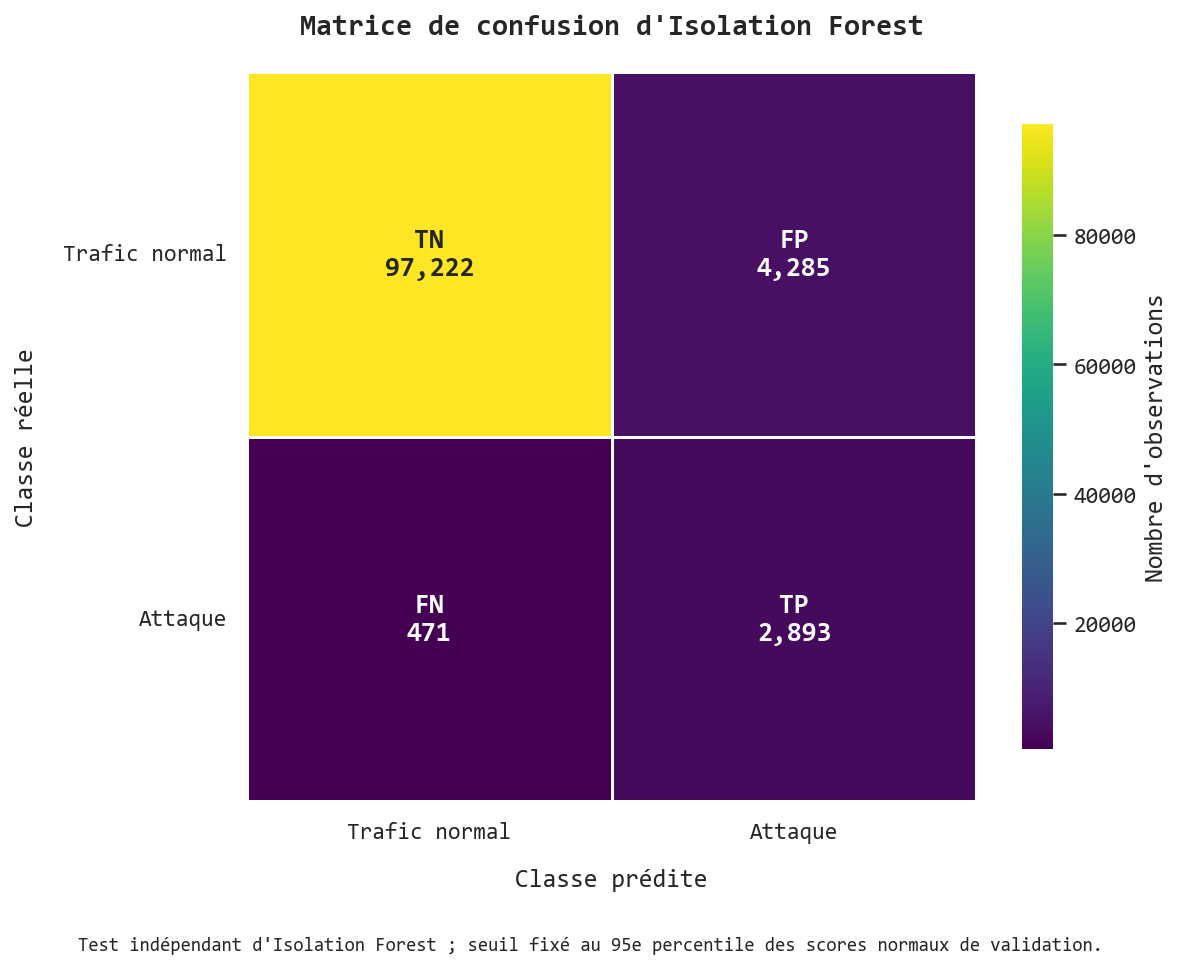


TABLEAU DES EFFECTIFS


,Indicateur,Effectif
0,Vrais négatifs (TN),97222
1,Faux positifs (FP),4285
2,Faux négatifs (FN),471
3,Vrais positifs (TP),2893


In [84]:

# ============================================================
# CELLULE 18 — MATRICE DE CONFUSION ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Evaluation : test independant propre a IF
#
# Classes :
# 0 = Trafic normal
# 1 = Attaque
#
# Aucun entrainement.
# Aucun recalibrage.
# ============================================================

import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import confusion_matrix
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. VERIFICATION DES PRECONDITIONS
# ------------------------------------------------------------

IF_CONFUSION_MATRIX_READY = False

required_flags = {
    "IF_PROTOCOL_VALIDATED": "cellule 11",
    "IF_MODEL_TRAINED": "cellule 12",
    "IF_CALIBRATION_COMPLETED": "cellule 14",
    "IF_TEST_SCORES_READY": "cellule 16",
    "IF_CLASSIFICATION_READY": "cellule 17"
}

for flag, cellule in required_flags.items():

    if not globals().get(flag, False):
        raise RuntimeError(
            f"{flag} n'est pas valide. "
            f"Verifier la {cellule}."
        )

required_objects = [
    "IF_y_pred_test",
    "IF_test_labels",
    "IF_test_ids",
    "IF_test_anomaly_scores",
    "IF_FIXED_THRESHOLD",
    "IF_y",
    "IF_SCIENTIFIC_FONT",
    "IF_FIGURES_DIR",
    "IF_TABLES_DIR",
    "IF_ARTIFACTS_DIR",
    "IF_PREDICTIONS_PATH"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. RECUPERATION DES DONNEES DU TEST
# ------------------------------------------------------------

IF_y_true_cm = np.asarray(
    IF_test_labels,
    dtype=np.int8
)

IF_y_pred_cm = np.asarray(
    IF_y_pred_test,
    dtype=np.int8
)

IF_scores_cm = np.asarray(
    IF_test_anomaly_scores,
    dtype=np.float64
)

IF_ids_cm = np.asarray(
    IF_test_ids,
    dtype=np.int64
)

IF_threshold_cm = float(
    IF_FIXED_THRESHOLD
)

# ------------------------------------------------------------
# 3. CONTROLES DE COHERENCE
# ------------------------------------------------------------

if not (
    IF_y_true_cm.ndim == 1
    and IF_y_pred_cm.ndim == 1
    and IF_scores_cm.ndim == 1
    and IF_ids_cm.ndim == 1
):
    raise ValueError(
        "Les donnees doivent etre unidimensionnelles."
    )

IF_N_CM = len(IF_y_true_cm)

if IF_N_CM == 0:
    raise ValueError(
        "L'ensemble de test est vide."
    )

if not (
    len(IF_y_true_cm)
    == len(IF_y_pred_cm)
    == len(IF_scores_cm)
    == len(IF_ids_cm)
):
    raise RuntimeError(
        "Les scores, predictions et etiquettes "
        "ne sont pas alignes."
    )

if set(np.unique(IF_y_true_cm)) != {0, 1}:
    raise ValueError(
        "Les deux classes reelles sont necessaires."
    )

if not set(
    np.unique(IF_y_pred_cm)
).issubset({0, 1}):
    raise ValueError(
        "Predictions non binaires detectees."
    )

if not np.isfinite(IF_scores_cm).all():
    raise ValueError(
        "Scores non finis detectes."
    )

if not np.isfinite(IF_threshold_cm):
    raise ValueError(
        "Le seuil n'est pas fini."
    )

# ------------------------------------------------------------
# 4. VERIFICATION DE LA REGLE DE DECISION
# ------------------------------------------------------------

IF_predictions_recalculated = (
    IF_scores_cm > IF_threshold_cm
).astype(np.int8)

if not np.array_equal(
    IF_y_pred_cm,
    IF_predictions_recalculated
):
    raise RuntimeError(
        "Les predictions different de la regle "
        "score > seuil."
    )

# ------------------------------------------------------------
# 5. ALIGNEMENT AVEC LES OBSERVATIONS
# ------------------------------------------------------------

if not np.array_equal(
    IF_y_true_cm,
    IF_y.iloc[IF_ids_cm].to_numpy(
        dtype=np.int8
    )
):
    raise RuntimeError(
        "Etiquettes reelles non alignees."
    )

if "IF_ids_test" in globals():

    if not np.array_equal(
        IF_ids_cm,
        np.asarray(IF_ids_test, dtype=np.int64)
    ):
        raise RuntimeError(
            "Identifiants du test incoherents."
        )

print("\nAlignement des observations : VALIDE")
print("Regle de decision : VALIDEE")

# ------------------------------------------------------------
# 6. VERIFICATION DES PREDICTIONS SAUVEGARDEES
# ------------------------------------------------------------

IF_PREDICTIONS_PATH = Path(
    IF_PREDICTIONS_PATH
)

if not IF_PREDICTIONS_PATH.is_file():
    raise FileNotFoundError(
        "Fichier de predictions absent."
    )

IF_saved_predictions_cm = np.load(
    IF_PREDICTIONS_PATH,
    allow_pickle=False
)

if not np.array_equal(
    IF_saved_predictions_cm,
    IF_y_pred_cm
):
    raise RuntimeError(
        "Les predictions sauvegardees different "
        "des predictions en memoire."
    )

# ------------------------------------------------------------
# 7. CALCUL DE LA MATRICE DE CONFUSION
# ------------------------------------------------------------

# Lignes : classes reelles
# Colonnes : classes predites
#
#                 Predit normal  Predit attaque
# Reel normal          TN             FP
# Reel attaque         FN             TP

IF_CM = confusion_matrix(
    IF_y_true_cm,
    IF_y_pred_cm,
    labels=[0, 1]
)

IF_TN, IF_FP, IF_FN, IF_TP = [
    int(value)
    for value in IF_CM.ravel()
]

print("\nMATRICE DE CONFUSION BRUTE")

print(IF_CM)

# ------------------------------------------------------------
# 8. VERIFICATION DES EFFECTIFS
# ------------------------------------------------------------

IF_N_TRUE_NORMAL = int(
    np.sum(IF_y_true_cm == 0)
)

IF_N_TRUE_ATTACK = int(
    np.sum(IF_y_true_cm == 1)
)

IF_N_PRED_NORMAL = int(
    np.sum(IF_y_pred_cm == 0)
)

IF_N_PRED_ATTACK = int(
    np.sum(IF_y_pred_cm == 1)
)

assert (
    IF_TN + IF_FP + IF_FN + IF_TP
    == IF_N_CM
)

assert (
    IF_TN + IF_FP
    == IF_N_TRUE_NORMAL
)

assert (
    IF_FN + IF_TP
    == IF_N_TRUE_ATTACK
)

assert (
    IF_TN + IF_FN
    == IF_N_PRED_NORMAL
)

assert (
    IF_FP + IF_TP
    == IF_N_PRED_ATTACK
)

print("\nEFFECTIFS DE CLASSIFICATION")

print("Vrais negatifs (TN) :", f"{IF_TN:,}")
print("Faux positifs (FP) :", f"{IF_FP:,}")
print("Faux negatifs (FN) :", f"{IF_FN:,}")
print("Vrais positifs (TP) :", f"{IF_TP:,}")

# ------------------------------------------------------------
# 9. CALCUL DES TAUX D'ERREUR
# ------------------------------------------------------------

IF_FPR_CM = (
    IF_FP / (IF_FP + IF_TN)
)

IF_FNR_CM = (
    IF_FN / (IF_FN + IF_TP)
)

IF_TPR_CM = (
    IF_TP / (IF_TP + IF_FN)
)

IF_TNR_CM = (
    IF_TN / (IF_TN + IF_FP)
)

print("\nINDICATEURS DE DETECTION")

print(
    "Taux de faux positifs :",
    f"{100 * IF_FPR_CM:.4f} %"
)

print(
    "Taux de faux negatifs :",
    f"{100 * IF_FNR_CM:.4f} %"
)

print(
    "Taux de detection des attaques :",
    f"{100 * IF_TPR_CM:.4f} %"
)

print(
    "Specificite :",
    f"{100 * IF_TNR_CM:.4f} %"
)

# ------------------------------------------------------------
# 10. TABLEAU SCIENTIFIQUE DE LA MATRICE
# ------------------------------------------------------------

IF_CM_TABLE = pd.DataFrame(
    IF_CM,
    index=[
        "Trafic normal réel",
        "Attaque réelle"
    ],
    columns=[
        "Trafic normal prédit",
        "Attaque prédite"
    ]
)

IF_CM_TABLE.index.name = "Classe réelle"
IF_CM_TABLE.columns.name = "Classe prédite"

print("\nTABLEAU SCIENTIFIQUE")

display(IF_CM_TABLE)

# ------------------------------------------------------------
# 11. CONFIGURATION GRAPHIQUE
# ------------------------------------------------------------

sns.set_theme(
    style="white"
)

plt.rcParams.update({
    "font.family": IF_SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

# ------------------------------------------------------------
# 12. CREATION DE LA MATRICE DE CONFUSION
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 6.5),
    dpi=150
)

# Palette scientifique viridis

IF_CM_COLORMAP = "viridis"

# Chaque case affiche son effectif.
# Les quatre valeurs proviennent
# des predictions reelles du modele.

IF_CM_ANNOTATIONS = np.array([
    [
        f"TN\n{IF_TN:,}",
        f"FP\n{IF_FP:,}"
    ],
    [
        f"FN\n{IF_FN:,}",
        f"TP\n{IF_TP:,}"
    ]
])

sns.heatmap(
    IF_CM,
    annot=IF_CM_ANNOTATIONS,
    fmt="",
    cmap=IF_CM_COLORMAP,
    cbar=True,
    square=True,
    linewidths=1.2,
    linecolor="white",
    xticklabels=[
        "Trafic normal",
        "Attaque"
    ],
    yticklabels=[
        "Trafic normal",
        "Attaque"
    ],
    annot_kws={
        "fontsize": 13,
        "fontweight": "bold",
        "fontfamily": IF_SCIENTIFIC_FONT
    },
    cbar_kws={
        "label": "Nombre d'observations",
        "shrink": 0.85
    },
    ax=ax
)

# ------------------------------------------------------------
# 13. TITRES ET AXES EN FRANCAIS
# ------------------------------------------------------------

ax.set_title(
    "Matrice de confusion d'Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily=IF_SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Classe prédite",
    fontsize=12,
    fontfamily=IF_SCIENTIFIC_FONT,
    labelpad=12
)

ax.set_ylabel(
    "Classe réelle",
    fontsize=12,
    fontfamily=IF_SCIENTIFIC_FONT,
    labelpad=12
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.tick_params(
    axis="y",
    rotation=0
)

# ------------------------------------------------------------
# 14. AJOUT D'UNE NOTE METHODOLOGIQUE
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    (
        "Test indépendant d'Isolation Forest ; "
        "seuil fixé au 95e percentile "
        "des scores normaux de validation."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_SCIENTIFIC_FONT
)

plt.tight_layout(
    rect=(0, 0.05, 1, 1)
)

# ------------------------------------------------------------
# 15. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

IF_CM_FIGURE_NAME = (
    "matrice_confusion_Isolation_Forest_test"
)

IF_CM_PNG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_CM_FIGURE_NAME}.png"
)

IF_CM_PDF_PATH = (
    IF_FIGURES_DIR /
    f"{IF_CM_FIGURE_NAME}.pdf"
)

IF_CM_SVG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_CM_FIGURE_NAME}.svg"
)

for path, file_format in [
    (IF_CM_PNG_PATH, "png"),
    (IF_CM_PDF_PATH, "pdf"),
    (IF_CM_SVG_PATH, "svg")
]:

    fig.savefig(
        path,
        format=file_format,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 16. EXPORT DES RESULTATS
# ------------------------------------------------------------

IF_CM_CSV_PATH = (
    IF_TABLES_DIR /
    "matrice_confusion_Isolation_Forest.csv"
)

IF_CM_TABLE.to_csv(
    IF_CM_CSV_PATH,
    encoding="utf-8-sig"
)

IF_CM_NUMERIC_PATH = (
    IF_ARTIFACTS_DIR /
    "matrice_confusion_Isolation_Forest.npy"
)

np.save(
    IF_CM_NUMERIC_PATH,
    IF_CM
)

# ------------------------------------------------------------
# 17. TABLEAU DES EFFECTIFS
# ------------------------------------------------------------

IF_CM_COUNTS_TABLE = pd.DataFrame({
    "Indicateur": [
        "Vrais négatifs (TN)",
        "Faux positifs (FP)",
        "Faux négatifs (FN)",
        "Vrais positifs (TP)"
    ],
    "Effectif": [
        IF_TN,
        IF_FP,
        IF_FN,
        IF_TP
    ]
})

IF_CM_COUNTS_PATH = (
    IF_TABLES_DIR /
    "effectifs_confusion_IF.csv"
)

IF_CM_COUNTS_TABLE.to_csv(
    IF_CM_COUNTS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nTABLEAU DES EFFECTIFS")

display(IF_CM_COUNTS_TABLE)

# ------------------------------------------------------------
# 18. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_CM_REPORT = {
    "dataset": IF_DATASET_NAME,
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "test_independant_IF",
    "partitionnement": "autonome_par_groupes",
    "nombre_observations": int(
        IF_N_CM
    ),
    "nombre_normaux": int(
        IF_N_TRUE_NORMAL
    ),
    "nombre_attaques": int(
        IF_N_TRUE_ATTACK
    ),
    "TN": int(IF_TN),
    "FP": int(IF_FP),
    "FN": int(IF_FN),
    "TP": int(IF_TP),
    "taux_faux_positifs": float(
        IF_FPR_CM
    ),
    "taux_faux_negatifs": float(
        IF_FNR_CM
    ),
    "taux_detection_attaques": float(
        IF_TPR_CM
    ),
    "specificite": float(
        IF_TNR_CM
    ),
    "seuil": float(
        IF_threshold_cm
    ),
    "population_calibration": "validation_normale",
    "percentile_calibration": 95,
    "operateur_decision": ">",
    "score": "-score_samples",
    "modele_modifie": False,
    "seuil_modifie": False,
    "test_utilise_pour_optimisation": False,
    "test_commun_DDAE_verifie": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_CM_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_matrice_confusion_IF.json"
)

with open(
    IF_CM_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        IF_CM_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 19. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

IF_saved_cm = np.load(
    IF_CM_NUMERIC_PATH,
    allow_pickle=False
)

if not np.array_equal(
    IF_saved_cm,
    IF_CM
):
    raise RuntimeError(
        "La matrice sauvegardee est differente."
    )

for path in [
    IF_CM_PNG_PATH,
    IF_CM_PDF_PATH,
    IF_CM_SVG_PATH,
    IF_CM_CSV_PATH,
    IF_CM_COUNTS_PATH,
    IF_CM_REPORT_PATH
]:

    if not Path(path).is_file():
        raise RuntimeError(
            f"Fichier manquant : {path}"
        )


In [87]:

# ============================================================
# CELLULE 19 — METRIQUES GLOBALES ISOLATION FOREST
# VERSION CORRIGEE ET ROBUSTE
# ============================================================
# Dataset : UNSW-NB15
# Modele : Isolation Forest
# Protocole : One-Class Learning
#
# Objectif :
# Calculer toutes les metriques du test
# a partir des scores et du seuil sauvegardes.
#
# AUCUN fit()
# AUCUN recalibrage
# AUCUNE modification du modele
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)


IF_METRICS_READY = False

# ------------------------------------------------------------
# 1. VERIFICATION DES DONNEES DISPONIBLES
# ------------------------------------------------------------

required = [
    "IF_ids_test",
    "IF_y",
    "IF_FIXED_THRESHOLD",
    "IF_TABLES_DIR",
    "IF_ARTIFACTS_DIR",
    "IF_SCORES_DIR"
]

missing = [
    name
    for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Variables indispensables manquantes : "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. RECUPERATION DES SCORES DU TEST
# ------------------------------------------------------------

# Priorite aux fichiers sauvegardes de la cellule 16.
# Si un fichier n'existe pas, on utilise la
# variable en memoire, apres verification.

IF_SCORES_FILE = (
    Path(IF_SCORES_DIR) /
    "scores_test_Isolation_Forest.npy"
)

if IF_SCORES_FILE.is_file():

    IF_scores_metrics = np.load(
        IF_SCORES_FILE,
        allow_pickle=False
    ).astype(np.float64)

    print("\nScores charges depuis le fichier sauvegarde.")

elif "IF_test_anomaly_scores" in globals():

    IF_scores_metrics = np.asarray(
        IF_test_anomaly_scores,
        dtype=np.float64
    )

    print("\nScores charges depuis la memoire.")

else:

    raise FileNotFoundError(
        "Scores du test introuvables. "
        "La cellule 16 doit produire les scores "
        "avant le calcul des metriques."
    )

# ------------------------------------------------------------
# 3. RECUPERATION DES ETIQUETTES REELLES
# ------------------------------------------------------------

IF_ids_metrics = np.asarray(
    IF_ids_test,
    dtype=np.int64
)

# Les etiquettes reelles sont retrouvees
# dans l'ordre exact des indices du test.

IF_y_true_metrics = (
    IF_y.iloc[IF_ids_metrics]
    .to_numpy(dtype=np.int8)
)

# ------------------------------------------------------------
# 4. VERIFICATION DU SEUIL DE CALIBRATION
# ------------------------------------------------------------

IF_threshold_metrics = float(
    IF_FIXED_THRESHOLD
)

IF_THRESHOLD_FILE = (
    Path(IF_ARTIFACTS_DIR) /
    "seuil_Isolation_Forest_95e_percentile.json"
)

if not IF_THRESHOLD_FILE.is_file():
    raise FileNotFoundError(
        "Rapport de calibration absent. "
        "Executer correctement la cellule 14."
    )

with open(
    IF_THRESHOLD_FILE,
    "r",
    encoding="utf-8"
) as file:

    IF_threshold_report = json.load(file)

IF_saved_threshold = float(
    IF_threshold_report["seuil"]
)

if not np.isclose(
    IF_threshold_metrics,
    IF_saved_threshold,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil en memoire differe "
        "du seuil sauvegarde."
    )

if IF_threshold_report.get("percentile") != 95:
    raise RuntimeError(
        "Le seuil sauvegarde ne correspond pas au P95."
    )

if IF_threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "La population de calibration est incorrecte."
    )

if IF_threshold_report.get(
    "operateur_decision"
) != ">":
    raise RuntimeError(
        "L'operateur de decision est incorrect."
    )

# Controle facultatif mais utile :
# retrouver exactement le percentile
# a partir des scores normaux de validation.

IF_VAL_SCORES_FILE = (
    Path(IF_SCORES_DIR) /
    "scores_validation_normale_IF.npy"
)

if not IF_VAL_SCORES_FILE.is_file():
    raise FileNotFoundError(
        "Scores de validation absents. "
        "Verifier la cellule 13."
    )

IF_validation_scores_check = np.load(
    IF_VAL_SCORES_FILE,
    allow_pickle=False
)

IF_expected_threshold = float(
    np.percentile(
        IF_validation_scores_check,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_threshold_metrics,
    IF_expected_threshold,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond pas au P95 "
        "des scores normaux de validation."
    )

print("\nSeuil de calibration : VALIDE")

# ------------------------------------------------------------
# 5. VERIFICATION DES DONNEES DU TEST
# ------------------------------------------------------------

IF_scores_metrics = np.asarray(
    IF_scores_metrics,
    dtype=np.float64
)

if IF_scores_metrics.ndim != 1:
    raise ValueError(
        "Les scores doivent etre un vecteur."
    )

if IF_y_true_metrics.ndim != 1:
    raise ValueError(
        "Les etiquettes doivent etre un vecteur."
    )

if len(IF_scores_metrics) != len(IF_y_true_metrics):
    raise RuntimeError(
        "Les effectifs des scores et des "
        "etiquettes sont differents."
    )

if len(IF_scores_metrics) == 0:
    raise ValueError(
        "Aucun score de test disponible."
    )

if not np.isfinite(IF_scores_metrics).all():
    raise ValueError(
        "Scores non finis detectes."
    )

if set(np.unique(IF_y_true_metrics)) != {0, 1}:
    raise ValueError(
        "Le test doit contenir les classes 0 et 1."
    )

IF_N_METRICS = int(
    len(IF_scores_metrics)
)

print("\nObservations du test :", IF_N_METRICS)

# ------------------------------------------------------------
# 6. PREDICTIONS AVEC LE SEUIL FIXE
# ------------------------------------------------------------

# Les predictions sont recalculees uniquement
# a partir des scores et du seuil fige.
#
# Les etiquettes reelles ne sont pas utilisees
# pour effectuer les predictions.

IF_y_pred_metrics = (
    IF_scores_metrics > IF_threshold_metrics
).astype(np.int8)

# Controle de coherence avec les predictions
# eventuellement sauvegardees en cellule 17.

IF_PREDICTIONS_FILE = (
    Path(IF_SCORES_DIR) /
    "predictions_test_Isolation_Forest.npy"
)

if IF_PREDICTIONS_FILE.is_file():

    IF_saved_predictions = np.load(
        IF_PREDICTIONS_FILE,
        allow_pickle=False
    )

    if not np.array_equal(
        IF_saved_predictions,
        IF_y_pred_metrics
    ):
        raise RuntimeError(
            "Les predictions sauvegardees "
            "different de la regle score > seuil."
        )

# Ces variables serviront aux cellules suivantes.

IF_y_pred_test = IF_y_pred_metrics.copy()
IF_test_labels = IF_y_true_metrics.copy()
IF_test_anomaly_scores = IF_scores_metrics.copy()
IF_test_ids = IF_ids_metrics.copy()

print("Predictions calculees avec le seuil fixe : OUI")

# ------------------------------------------------------------
# 7. MATRICE DE CONFUSION
# ------------------------------------------------------------

IF_CM = confusion_matrix(
    IF_y_true_metrics,
    IF_y_pred_metrics,
    labels=[0, 1]
)

IF_TN, IF_FP, IF_FN, IF_TP = [
    int(value)
    for value in IF_CM.ravel()
]

assert (
    IF_TN + IF_FP + IF_FN + IF_TP
    == IF_N_METRICS
)

print("\nMATRICE DE CONFUSION")

print(IF_CM)

print("\nTN :", IF_TN)
print("FP :", IF_FP)
print("FN :", IF_FN)
print("TP :", IF_TP)

# ------------------------------------------------------------
# 8. METRIQUES DE CLASSIFICATION
# ------------------------------------------------------------

IF_ACCURACY = float(
    accuracy_score(
        IF_y_true_metrics,
        IF_y_pred_metrics
    )
)

IF_PRECISION = float(
    precision_score(
        IF_y_true_metrics,
        IF_y_pred_metrics,
        zero_division=0
    )
)

IF_RECALL = float(
    recall_score(
        IF_y_true_metrics,
        IF_y_pred_metrics,
        zero_division=0
    )
)

IF_F1_SCORE = float(
    f1_score(
        IF_y_true_metrics,
        IF_y_pred_metrics,
        zero_division=0
    )
)

IF_SPECIFICITY = float(
    IF_TN / (IF_TN + IF_FP)
)

IF_BALANCED_ACCURACY = float(
    balanced_accuracy_score(
        IF_y_true_metrics,
        IF_y_pred_metrics
    )
)

# ------------------------------------------------------------
# 9. METRIQUES DE CLASSEMENT
# ------------------------------------------------------------

# Elles utilisent les scores continus,
# et non les predictions binaires.

IF_ROC_AUC = float(
    roc_auc_score(
        IF_y_true_metrics,
        IF_scores_metrics
    )
)

IF_AVERAGE_PRECISION = float(
    average_precision_score(
        IF_y_true_metrics,
        IF_scores_metrics
    )
)

# ------------------------------------------------------------
# 10. TAUX DE FAUX POSITIFS ET NEGATIFS
# ------------------------------------------------------------

IF_FPR = float(
    IF_FP / (IF_FP + IF_TN)
)

IF_FNR = float(
    IF_FN / (IF_FN + IF_TP)
)

# ------------------------------------------------------------
# 11. VERIFICATIONS MATHEMATIQUES
# ------------------------------------------------------------

assert np.isclose(
    IF_RECALL + IF_FNR,
    1.0
)

assert np.isclose(
    IF_SPECIFICITY + IF_FPR,
    1.0
)

assert np.isclose(
    IF_BALANCED_ACCURACY,
    (IF_RECALL + IF_SPECIFICITY) / 2
)

# ------------------------------------------------------------
# 12. DICTIONNAIRE DES METRIQUES
# ------------------------------------------------------------

IF_METRICS = {
    "Accuracy": IF_ACCURACY,
    "Precision": IF_PRECISION,
    "Recall": IF_RECALL,
    "F1-score": IF_F1_SCORE,
    "Specificity": IF_SPECIFICITY,
    "Balanced Accuracy": IF_BALANCED_ACCURACY,
    "ROC-AUC": IF_ROC_AUC,
    "Average Precision": IF_AVERAGE_PRECISION,
    "FPR": IF_FPR,
    "FNR": IF_FNR
}

# ------------------------------------------------------------
# 13. TABLEAU DES PERFORMANCES
# ------------------------------------------------------------

IF_METRIC_TRANSLATIONS = {
    "Accuracy": "Exactitude",
    "Precision": "Précision",
    "Recall": "Rappel",
    "F1-score": "Score F1",
    "Specificity": "Spécificité",
    "Balanced Accuracy": "Exactitude équilibrée",
    "ROC-AUC": "Aire sous la courbe ROC",
    "Average Precision": "Précision moyenne (AP)",
    "FPR": "Taux de faux positifs",
    "FNR": "Taux de faux négatifs"
}

IF_METRICS_TABLE = pd.DataFrame({
    "Métrique": [
        IF_METRIC_TRANSLATIONS[key]
        for key in IF_METRICS
    ],
    "Valeur": list(IF_METRICS.values())
})

IF_METRICS_TABLE["Pourcentage"] = (
    IF_METRICS_TABLE["Valeur"] * 100
)

print("\nPERFORMANCES GLOBALES")

display(
    IF_METRICS_TABLE.style.format({
        "Valeur": "{:.6f}",
        "Pourcentage": "{:.4f} %"
    })
)

# ------------------------------------------------------------
# 14. RAPPORT DE CLASSIFICATION
# ------------------------------------------------------------

IF_CLASSIFICATION_REPORT_TABLE = (
    pd.DataFrame(
        classification_report(
            IF_y_true_metrics,
            IF_y_pred_metrics,
            labels=[0, 1],
            target_names=[
                "Trafic normal",
                "Attaque"
            ],
            output_dict=True,
            zero_division=0
        )
    ).transpose()
)

print("\nRAPPORT DE CLASSIFICATION")

display(IF_CLASSIFICATION_REPORT_TABLE)

# ------------------------------------------------------------
# 15. TABLEAU SYNTHETIQUE CHAPITRE 4
# ------------------------------------------------------------

IF_N_NORMAL_METRICS = int(
    np.sum(IF_y_true_metrics == 0)
)

IF_N_ATTACK_METRICS = int(
    np.sum(IF_y_true_metrics == 1)
)

IF_METRICS_SUMMARY = pd.DataFrame([{
    "Modele": "Isolation Forest",
    "Observations_test": IF_N_METRICS,
    "Normaux_test": IF_N_NORMAL_METRICS,
    "Attaques_test": IF_N_ATTACK_METRICS,
    "Accuracy_pct": IF_ACCURACY * 100,
    "Precision_pct": IF_PRECISION * 100,
    "Recall_pct": IF_RECALL * 100,
    "F1_score_pct": IF_F1_SCORE * 100,
    "Specificity_pct": IF_SPECIFICITY * 100,
    "Balanced_Accuracy_pct": (
        IF_BALANCED_ACCURACY * 100
    ),
    "ROC_AUC": IF_ROC_AUC,
    "Average_Precision": IF_AVERAGE_PRECISION,
    "FPR_pct": IF_FPR * 100,
    "FNR_pct": IF_FNR * 100,
    "Seuil": IF_threshold_metrics,
    "Calibration": "P95 validation normale"
}])

print("\nSYNTHESE POUR LE CHAPITRE 4")

display(IF_METRICS_SUMMARY)

# ------------------------------------------------------------
# 16. EXPORT DES TABLEAUX
# ------------------------------------------------------------

IF_METRICS_TABLE_PATH = (
    Path(IF_TABLES_DIR) /
    "metriques_globales_Isolation_Forest.csv"
)

IF_CLASSIFICATION_REPORT_TABLE_PATH = (
    Path(IF_TABLES_DIR) /
    "rapport_classification_Isolation_Forest.csv"
)

IF_METRICS_SUMMARY_PATH = (
    Path(IF_TABLES_DIR) /
    "synthese_performances_Isolation_Forest.csv"
)

IF_METRICS_TABLE.to_csv(
    IF_METRICS_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_CLASSIFICATION_REPORT_TABLE.to_csv(
    IF_CLASSIFICATION_REPORT_TABLE_PATH,
    encoding="utf-8-sig"
)

IF_METRICS_SUMMARY.to_csv(
    IF_METRICS_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 17. RAPPORT JSON
# ------------------------------------------------------------

IF_METRICS_REPORT = {
    "dataset": "UNSW-NB15",
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "partitionnement": "autonome_par_groupes",
    "ensemble": "test_independant_IF",
    "nombre_observations": IF_N_METRICS,
    "nombre_normaux": IF_N_NORMAL_METRICS,
    "nombre_attaques": IF_N_ATTACK_METRICS,
    "seuil": float(IF_threshold_metrics),
    "calibration": "P95_validation_normale",
    "score": "-score_samples",
    "operateur_decision": ">",
    "matrice_confusion": {
        "TN": IF_TN,
        "FP": IF_FP,
        "FN": IF_FN,
        "TP": IF_TP
    },
    "metriques": IF_METRICS,
    "modele_modifie": False,
    "seuil_modifie": False,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_METRICS_REPORT_PATH = (
    Path(IF_ARTIFACTS_DIR) /
    "rapport_metriques_globales_IF.json"
)

with open(
    IF_METRICS_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_METRICS_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )



Scores charges depuis le fichier sauvegarde.

Seuil de calibration : VALIDE

Observations du test : 104871
Predictions calculees avec le seuil fixe : OUI

MATRICE DE CONFUSION
[[97222  4285]
 [  471  2893]]

TN : 97222
FP : 4285
FN : 471
TP : 2893

PERFORMANCES GLOBALES


,Métrique,Valeur,Pourcentage
0,Exactitude,0.954649,95.4649 %
1,Précision,0.403037,40.3037 %
2,Rappel,0.859988,85.9988 %
3,Score F1,0.548852,54.8852 %
4,Spécificité,0.957786,95.7786 %
5,Exactitude équilibrée,0.908887,90.8887 %
6,Aire sous la courbe ROC,0.981147,98.1147 %
7,Précision moyenne (AP),0.545501,54.5501 %
8,Taux de faux positifs,0.042214,4.2214 %
9,Taux de faux négatifs,0.140012,14.0012 %



RAPPORT DE CLASSIFICATION


,precision,recall,f1-score,support
Trafic normal,0.995179,0.957786,0.976124,101507.000000
Attaque,0.403037,0.859988,0.548852,3364.000000
accuracy,0.954649,0.954649,0.954649,0.954649
macro avg,0.699108,0.908887,0.762488,104871.000000
weighted avg,0.976184,0.954649,0.962419,104871.000000



SYNTHESE POUR LE CHAPITRE 4


,Modele,Observations_test,Normaux_test,Attaques_test,Accuracy_pct,Precision_pct,Recall_pct,F1_score_pct,Specificity_pct,Balanced_Accuracy_pct,ROC_AUC,Average_Precision,FPR_pct,FNR_pct,Seuil,Calibration
0,Isolation Forest,104871,101507,3364,95.464905,40.303706,85.998811,54.885221,95.778616,90.888714,0.981147,0.545501,4.221384,14.001189,0.526246,P95 validation normale


CELLULE 20 — PERFORMANCES GLOBALES ISOLATION FOREST

METRIQUES EXPERIMENTALES VERIFIEES


,Metrique,Valeur,Performance_pct
0,Exactitude,0.954649,95.46 %
1,Précision,0.403037,40.30 %
2,Rappel,0.859988,86.00 %
3,Score F1,0.548852,54.89 %
4,Spécificité,0.957786,95.78 %
5,Exactitude équilibrée,0.908887,90.89 %


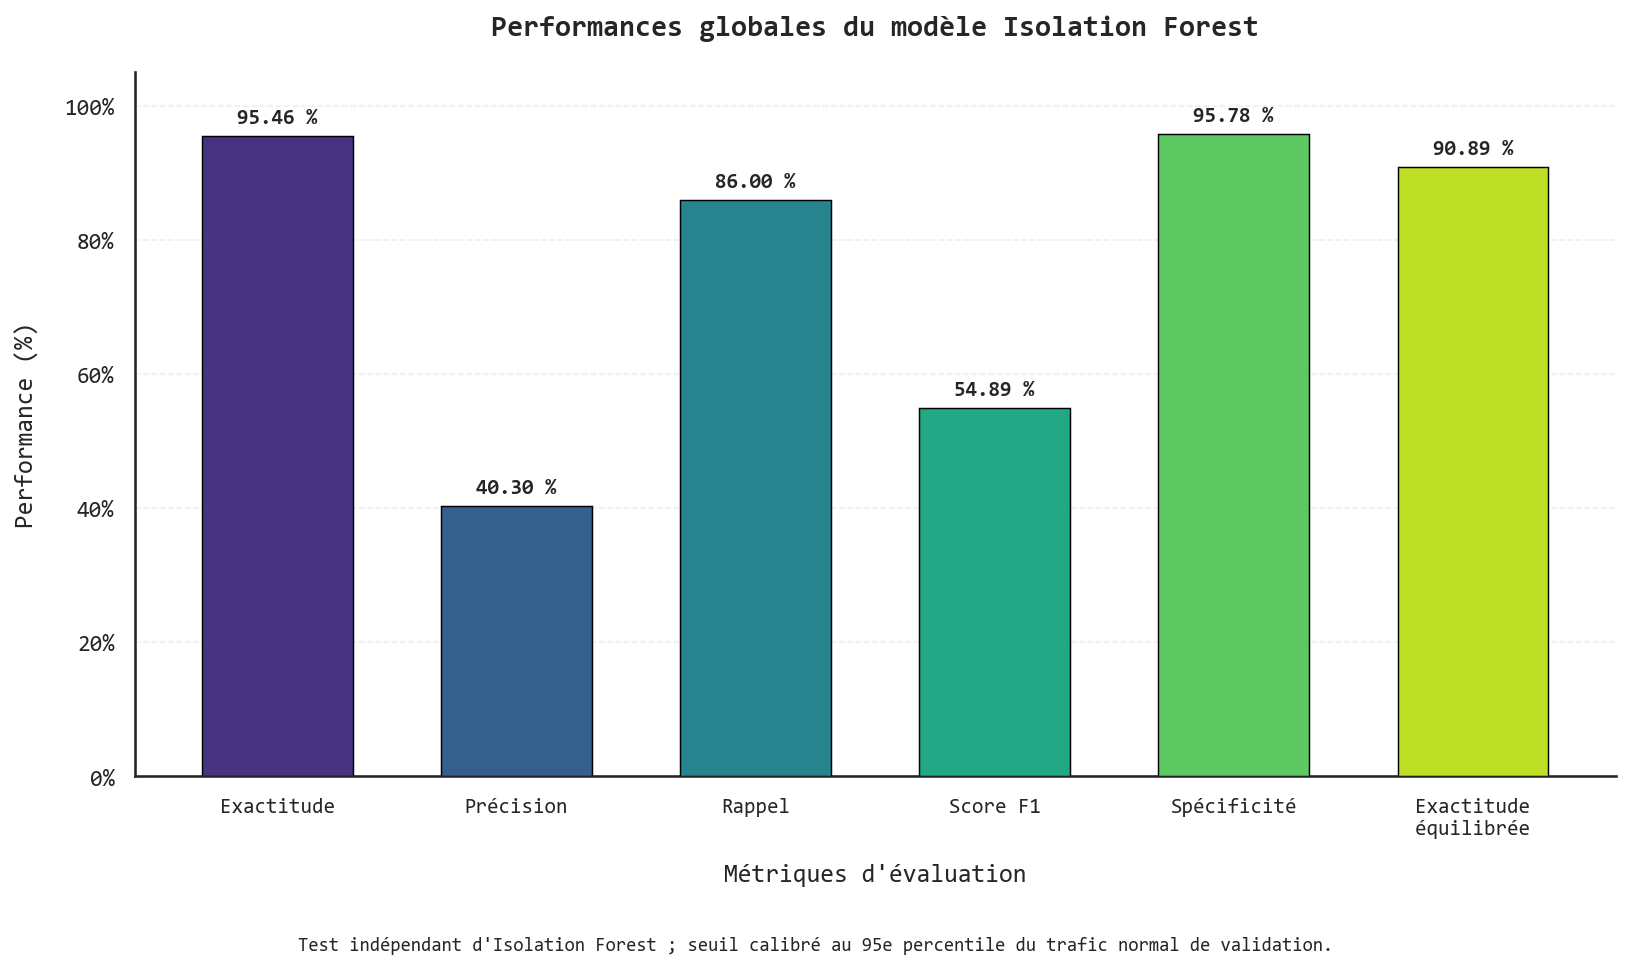

In [89]:

# ============================================================
# CELLULE 20 — VISUALISATION DES PERFORMANCES GLOBALES
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Produire un diagramme scientifique des
# performances globales du modele.
#
# Metriques :
# Accuracy, Precision, Recall, F1-score,
# Specificity et Balanced Accuracy.
#
# Aucun entrainement.
# Aucun recalibrage.
# Aucune modification des resultats.
# ============================================================

import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mticker

from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("CELLULE 20 — PERFORMANCES GLOBALES ISOLATION FOREST")
print("=" * 75)

IF_PERFORMANCE_FIGURE_READY = False

# ------------------------------------------------------------
# 1. VERIFICATION DES REPERTOIRES
# ------------------------------------------------------------

required_paths = [
    "IF_FIGURES_DIR",
    "IF_TABLES_DIR",
    "IF_ARTIFACTS_DIR"
]

missing_paths = [
    name
    for name in required_paths
    if name not in globals()
]

if missing_paths:

    raise RuntimeError(
        "Repertoires manquants : "
        + ", ".join(missing_paths)
    )

IF_FIGURES_DIR = Path(IF_FIGURES_DIR)
IF_TABLES_DIR = Path(IF_TABLES_DIR)
IF_ARTIFACTS_DIR = Path(IF_ARTIFACTS_DIR)

for directory in [
    IF_FIGURES_DIR,
    IF_TABLES_DIR,
    IF_ARTIFACTS_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 2. RECUPERATION DES METRIQUES
# ------------------------------------------------------------

# Priorite au rapport JSON sauvegarde
# par la cellule 19 corrigee.
#
# Cette methode evite de dependre uniquement
# des variables presentes en memoire.

IF_METRICS_SOURCE_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_metriques_globales_IF.json"
)

if not IF_METRICS_SOURCE_PATH.is_file():

    raise FileNotFoundError(
        "Rapport des metriques introuvable : "
        f"{IF_METRICS_SOURCE_PATH}\n"
        "Executer correctement la cellule 19."
    )

with open(
    IF_METRICS_SOURCE_PATH,
    "r",
    encoding="utf-8"
) as file:

    IF_PERFORMANCE_SOURCE_REPORT = json.load(
        file
    )

if (
    IF_PERFORMANCE_SOURCE_REPORT.get("modele")
    != "Isolation Forest"
):

    raise ValueError(
        "Le rapport charge ne correspond pas "
        "au modele Isolation Forest."
    )

if "metriques" not in IF_PERFORMANCE_SOURCE_REPORT:

    raise KeyError(
        "Le rapport ne contient pas "
        "le dictionnaire des metriques."
    )

IF_PERFORMANCE_SOURCE_METRICS = (
    IF_PERFORMANCE_SOURCE_REPORT["metriques"]
)

# ------------------------------------------------------------
# 3. DEFINITION DES METRIQUES A AFFICHER
# ------------------------------------------------------------

IF_METRICS_TO_PLOT = [
    ("Accuracy", "Exactitude"),
    ("Precision", "Précision"),
    ("Recall", "Rappel"),
    ("F1-score", "Score F1"),
    ("Specificity", "Spécificité"),
    (
        "Balanced Accuracy",
        "Exactitude\néquilibrée"
    )
]

IF_REQUIRED_METRIC_NAMES = [
    name
    for name, label in IF_METRICS_TO_PLOT
]

IF_MISSING_METRICS = [
    name
    for name in IF_REQUIRED_METRIC_NAMES
    if name not in IF_PERFORMANCE_SOURCE_METRICS
]

if IF_MISSING_METRICS:

    raise RuntimeError(
        "Metriques absentes du rapport : "
        + ", ".join(IF_MISSING_METRICS)
    )

# ------------------------------------------------------------
# 4. VERIFICATION DES VALEURS
# ------------------------------------------------------------

IF_PERFORMANCE_VALUES = np.asarray(
    [
        IF_PERFORMANCE_SOURCE_METRICS[name]
        for name in IF_REQUIRED_METRIC_NAMES
    ],
    dtype=np.float64
)

if not np.isfinite(
    IF_PERFORMANCE_VALUES
).all():

    raise ValueError(
        "Les metriques contiennent des valeurs non finies."
    )

if np.any(
    (IF_PERFORMANCE_VALUES < 0)
    |
    (IF_PERFORMANCE_VALUES > 1)
):

    raise ValueError(
        "Les metriques doivent appartenir "
        "a l'intervalle [0, 1]."
    )

IF_PERFORMANCE_PERCENTAGES = (
    IF_PERFORMANCE_VALUES * 100.0
)

IF_PERFORMANCE_LABELS = [
    label
    for name, label in IF_METRICS_TO_PLOT
]

# ------------------------------------------------------------
# 5. CONTROLE DE COHERENCE AVEC LA MEMOIRE
# ------------------------------------------------------------

# Si les metriques de la cellule 19 sont
# toujours disponibles en memoire, elles
# doivent etre identiques au rapport sauvegarde.

if "IF_METRICS" in globals():

    for name in IF_REQUIRED_METRIC_NAMES:

        if name in IF_METRICS:

            if not np.isclose(
                float(IF_METRICS[name]),
                float(
                    IF_PERFORMANCE_SOURCE_METRICS[name]
                ),
                rtol=1e-10,
                atol=1e-12
            ):

                raise RuntimeError(
                    "Incoherence entre la memoire "
                    "et le rapport sauvegarde : "
                    f"{name}"
                )

print("\nMETRIQUES EXPERIMENTALES VERIFIEES")

# ------------------------------------------------------------
# 6. TABLEAU DES PERFORMANCES
# ------------------------------------------------------------

IF_PERFORMANCE_PLOT_TABLE = pd.DataFrame({
    "Metrique": [
        label.replace("\n", " ")
        for label in IF_PERFORMANCE_LABELS
    ],
    "Valeur": IF_PERFORMANCE_VALUES,
    "Performance_pct": (
        IF_PERFORMANCE_PERCENTAGES
    )
})

display(
    IF_PERFORMANCE_PLOT_TABLE.style.format({
        "Valeur": "{:.6f}",
        "Performance_pct": "{:.2f} %"
    })
)

# ------------------------------------------------------------
# 7. CONFIGURATION DE LA POLICE
# ------------------------------------------------------------

IF_AVAILABLE_FONTS = {
    font.name
    for font in fm.fontManager.ttflist
}

if "Consolas" in IF_AVAILABLE_FONTS:

    IF_PLOT_FONT = "Consolas"

else:

    IF_PLOT_FONT = "DejaVu Sans Mono"

    print(
        "\nAttention : Consolas indisponible. "
        "Police de remplacement utilisee."
    )

# Configuration Matplotlib

plt.rcParams.update({
    "font.family": IF_PLOT_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

# ------------------------------------------------------------
# 8. PALETTE SCIENTIFIQUE VIRIDIS
# ------------------------------------------------------------

IF_COLORS = plt.cm.viridis(
    np.linspace(
        0.15,
        0.90,
        len(IF_PERFORMANCE_VALUES)
    )
)

# ------------------------------------------------------------
# 9. CREATION DU DIAGRAMME
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6.5),
    dpi=150
)

IF_X_POSITIONS = np.arange(
    len(IF_PERFORMANCE_VALUES)
)

IF_BARS = ax.bar(
    IF_X_POSITIONS,
    IF_PERFORMANCE_PERCENTAGES,
    width=0.63,
    color=IF_COLORS,
    edgecolor="black",
    linewidth=0.7,
    zorder=3
)

# ------------------------------------------------------------
# 10. AJOUT DES VALEURS SUR LES BARRES
# ------------------------------------------------------------

for bar, value in zip(
    IF_BARS,
    IF_PERFORMANCE_PERCENTAGES
):

    IF_BAR_X = (
        bar.get_x()
        + bar.get_width() / 2
    )

    IF_BAR_Y = bar.get_height()

    # Les valeurs proches de 100 %
    # restent visibles dans la figure.

    IF_LABEL_Y = min(
        IF_BAR_Y + 1.3,
        102.5
    )

    ax.text(
        IF_BAR_X,
        IF_LABEL_Y,
        f"{value:.2f} %",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        fontfamily=IF_PLOT_FONT
    )

# ------------------------------------------------------------
# 11. TITRE ET AXES EN FRANCAIS
# ------------------------------------------------------------

ax.set_title(
    "Performances globales du modèle Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily=IF_PLOT_FONT,
    pad=18
)

ax.set_xlabel(
    "Métriques d'évaluation",
    fontsize=12,
    fontfamily=IF_PLOT_FONT,
    labelpad=12
)

ax.set_ylabel(
    "Performance (%)",
    fontsize=12,
    fontfamily=IF_PLOT_FONT,
    labelpad=12
)

# ------------------------------------------------------------
# 12. CONFIGURATION DE L'AXE VERTICAL
# ------------------------------------------------------------

# L'echelle de reference est 0 a 100 %.
# Une marge additionnelle de 5 points
# permet d'afficher les annotations.

ax.set_ylim(
    0,
    105
)

ax.set_yticks(
    np.arange(
        0,
        101,
        20
    )
)

ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(
        xmax=100,
        decimals=0
    )
)

# ------------------------------------------------------------
# 13. CONFIGURATION DE L'AXE HORIZONTAL
# ------------------------------------------------------------

ax.set_xticks(
    IF_X_POSITIONS
)

ax.set_xticklabels(
    IF_PERFORMANCE_LABELS,
    fontsize=10,
    fontfamily=IF_PLOT_FONT
)

ax.tick_params(
    axis="x",
    length=0,
    pad=10
)

# ------------------------------------------------------------
# 14. GRILLE ET STYLE SCIENTIFIQUE
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.75,
    alpha=0.35,
    zorder=0
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ------------------------------------------------------------
# 15. NOTE METHODOLOGIQUE
# ------------------------------------------------------------

# Cette figure concerne uniquement
# le test independant propre a IF.
#
# Le seuil est fixe sur validation normale.
#
# Aucune comparaison directe avec le DDAE
# n'est conclue dans cette cellule.

fig.text(
    0.5,
    0.015,
    (
        "Test indépendant d'Isolation Forest ; "
        "seuil calibré au 95e percentile "
        "du trafic normal de validation."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_PLOT_FONT
)

fig.tight_layout(
    rect=(0, 0.055, 1, 1)
)

# ------------------------------------------------------------
# 16. CHEMINS DES FIGURES
# ------------------------------------------------------------

IF_PERFORMANCE_FIGURE_NAME = (
    "performances_globales_Isolation_Forest"
)

IF_PERFORMANCE_PNG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_PERFORMANCE_FIGURE_NAME}.png"
)

IF_PERFORMANCE_PDF_PATH = (
    IF_FIGURES_DIR /
    f"{IF_PERFORMANCE_FIGURE_NAME}.pdf"
)

IF_PERFORMANCE_SVG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_PERFORMANCE_FIGURE_NAME}.svg"
)

# ------------------------------------------------------------
# 17. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

IF_FIGURE_EXPORTS = [
    (
        IF_PERFORMANCE_PNG_PATH,
        "png"
    ),
    (
        IF_PERFORMANCE_PDF_PATH,
        "pdf"
    ),
    (
        IF_PERFORMANCE_SVG_PATH,
        "svg"
    )
]

for path, file_format in IF_FIGURE_EXPORTS:

    fig.savefig(
        path,
        format=file_format,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 18. EXPORT DU TABLEAU DE LA FIGURE
# ------------------------------------------------------------

IF_PERFORMANCE_TABLE_PATH = (
    IF_TABLES_DIR /
    "performances_graphique_Isolation_Forest.csv"
)

IF_PERFORMANCE_PLOT_TABLE.to_csv(
    IF_PERFORMANCE_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 19. RAPPORT JSON DE TRACABILITE
# ------------------------------------------------------------

IF_PERFORMANCE_FIGURE_REPORT = {
    "dataset": "UNSW-NB15",
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "test_independant_IF",
    "source_metriques": str(
        IF_METRICS_SOURCE_PATH
    ),
    "metriques_affichees": {
        name: float(
            IF_PERFORMANCE_SOURCE_METRICS[name]
        )
        for name in IF_REQUIRED_METRIC_NAMES
    },
    "echelle": "pourcentage",
    "borne_inferieure_performance": 0,
    "borne_superieure_performance": 100,
    "marge_graphique_superieure": 105,
    "police": IF_PLOT_FONT,
    "palette": "viridis",
    "resolution_png_dpi": 300,
    "seuil_recalibre": False,
    "modele_reentraine": False,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_PERFORMANCE_FIGURE_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_figure_performances_IF.json"
)

with open(
    IF_PERFORMANCE_FIGURE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_PERFORMANCE_FIGURE_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 20. VERIFICATION DES FICHIERS
# ------------------------------------------------------------

IF_REQUIRED_OUTPUT_FILES = [
    IF_PERFORMANCE_PNG_PATH,
    IF_PERFORMANCE_PDF_PATH,
    IF_PERFORMANCE_SVG_PATH,
    IF_PERFORMANCE_TABLE_PATH,
    IF_PERFORMANCE_FIGURE_REPORT_PATH
]

for path in IF_REQUIRED_OUTPUT_FILES:

    if not path.is_file():

        raise RuntimeError(
            f"Fichier exporte manquant : {path}"
        )

    if path.stat().st_size == 0:

        raise RuntimeError(
            f"Fichier exporte vide : {path}"
        )

CELLULE 21 — COURBE ROC ISOLATION FOREST

Calibration P95 : VALIDEE

POINT OPERATIONNEL P95
Taux de faux positifs : 4.2214 %
Taux de vrais positifs : 85.9988 %


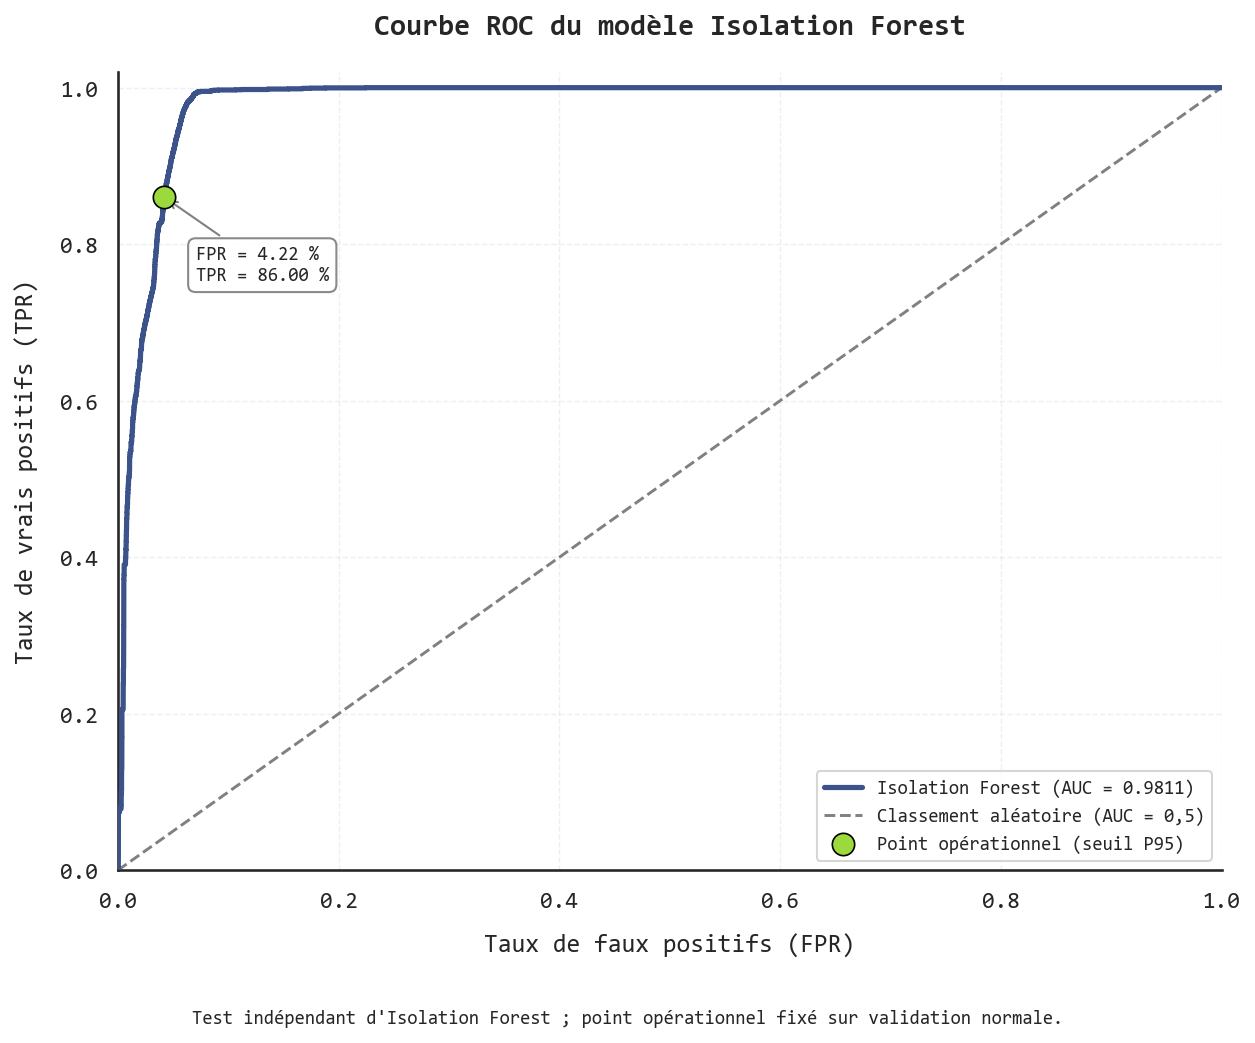


POINT OPERATIONNEL ET AUC


,Modele,Seuil_P95_validation,Taux_faux_positifs,Taux_vrais_positifs,ROC_AUC,TN,FP,FN,TP
0,Isolation Forest,0.526246,0.042214,0.859988,0.981147,97222,4285,471,2893


In [91]:

# ============================================================
# CELLULE 21 — COURBE ROC ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Construire la courbe ROC sur le test independant
# propre a Isolation Forest.
#
# Score = -score_samples(X)
# Classe positive = 1 (attaque)
#
# Le point operationnel utilise le seuil P95
# fixe sur la validation normale.
#
# Aucun fit()
# Aucun recalibrage
# Aucune optimisation sur le test
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path
from datetime import datetime, timezone

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix
)

print("=" * 75)
print("CELLULE 21 — COURBE ROC ISOLATION FOREST")
print("=" * 75)

IF_ROC_FIGURE_READY = False

# ------------------------------------------------------------
# 1. VERIFICATION DES REPERTOIRES
# ------------------------------------------------------------

required_dirs = [
    "IF_SCORES_DIR",
    "IF_ARTIFACTS_DIR",
    "IF_FIGURES_DIR",
    "IF_TABLES_DIR"
]

missing_dirs = [
    name for name in required_dirs
    if name not in globals()
]

if missing_dirs:
    raise RuntimeError(
        "Repertoires absents : "
        + ", ".join(missing_dirs)
    )

IF_SCORES_DIR = Path(IF_SCORES_DIR)
IF_ARTIFACTS_DIR = Path(IF_ARTIFACTS_DIR)
IF_FIGURES_DIR = Path(IF_FIGURES_DIR)
IF_TABLES_DIR = Path(IF_TABLES_DIR)

for folder in [
    IF_FIGURES_DIR,
    IF_TABLES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOCALISATION DES FICHIERS DE REFERENCE
# ------------------------------------------------------------

IF_ROC_SCORES_PATH = (
    IF_SCORES_DIR /
    "scores_test_Isolation_Forest.npy"
)

IF_ROC_THRESHOLD_PATH = (
    IF_ARTIFACTS_DIR /
    "seuil_Isolation_Forest_95e_percentile.json"
)

IF_ROC_METRICS_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_metriques_globales_IF.json"
)

IF_ROC_IDS_PATH = (
    IF_ARTIFACTS_DIR /
    "matrices_isolation_forest" /
    "ids_test.npy"
)

IF_ROC_LABELS_PATH = (
    IF_ARTIFACTS_DIR /
    "matrices_isolation_forest" /
    "y_test.npy"
)

required_files = [
    IF_ROC_SCORES_PATH,
    IF_ROC_THRESHOLD_PATH,
    IF_ROC_IDS_PATH,
    IF_ROC_LABELS_PATH
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(
            f"Fichier indispensable absent : {path}"
        )

# ------------------------------------------------------------
# 3. CHARGEMENT DES DONNEES SAUVEGARDEES
# ------------------------------------------------------------

IF_roc_scores = np.asarray(
    np.load(
        IF_ROC_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

IF_roc_labels = np.asarray(
    np.load(
        IF_ROC_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=np.int8
)

IF_roc_ids = np.asarray(
    np.load(
        IF_ROC_IDS_PATH,
        allow_pickle=False
    ),
    dtype=np.int64
)

# ------------------------------------------------------------
# 4. VERIFICATION DES DONNEES
# ------------------------------------------------------------

if not all(
    x.ndim == 1
    for x in [
        IF_roc_scores,
        IF_roc_labels,
        IF_roc_ids
    ]
):
    raise ValueError(
        "Scores, etiquettes et identifiants "
        "doivent etre unidimensionnels."
    )

IF_ROC_N = len(IF_roc_scores)

if IF_ROC_N == 0:
    raise ValueError(
        "Aucune observation dans le test."
    )

if not (
    len(IF_roc_scores)
    == len(IF_roc_labels)
    == len(IF_roc_ids)
):
    raise RuntimeError(
        "Dimensions des scores, etiquettes "
        "et identifiants incompatibles."
    )

if not np.isfinite(IF_roc_scores).all():
    raise ValueError(
        "Scores ROC non finis."
    )

if set(np.unique(IF_roc_labels)) != {0, 1}:
    raise ValueError(
        "Les deux classes 0 et 1 sont necessaires."
    )

if len(np.unique(IF_roc_ids)) != IF_ROC_N:
    raise RuntimeError(
        "Identifiants du test dupliques."
    )

# ------------------------------------------------------------
# 5. VERIFICATION DE L'ALIGNEMENT EN MEMOIRE
# ------------------------------------------------------------

# Si IF_y est disponible, les etiquettes
# sauvegardees doivent correspondre exactement
# aux indices originaux du dataset.

if "IF_y" in globals():

    IF_roc_expected_labels = (
        IF_y.iloc[IF_roc_ids]
        .to_numpy(dtype=np.int8)
    )

    if not np.array_equal(
        IF_roc_expected_labels,
        IF_roc_labels
    ):
        raise RuntimeError(
            "Etiquettes sauvegardees non alignees "
            "avec le dataset original."
        )

# Si les indices de la cellule 8 existent,
# leur ordre doit egalement etre conserve.

if "IF_ids_test" in globals():

    if not np.array_equal(
        IF_roc_ids,
        np.asarray(
            IF_ids_test,
            dtype=np.int64
        )
    ):
        raise RuntimeError(
            "Les identifiants du test ont change."
        )

# ------------------------------------------------------------
# 6. CHARGEMENT DU SEUIL OPERATIONNEL
# ------------------------------------------------------------

with open(
    IF_ROC_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:

    IF_roc_threshold_report = json.load(file)

IF_ROC_FIXED_THRESHOLD = float(
    IF_roc_threshold_report["seuil"]
)

if not np.isfinite(IF_ROC_FIXED_THRESHOLD):
    raise ValueError(
        "Seuil operationnel non fini."
    )

if IF_roc_threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "Origine de calibration incorrecte."
    )

if IF_roc_threshold_report.get(
    "percentile"
) != 95:
    raise RuntimeError(
        "Le seuil n'a pas ete calibre au P95."
    )

if IF_roc_threshold_report.get(
    "operateur_decision"
) != ">":
    raise RuntimeError(
        "La regle de decision doit etre score > seuil."
    )

# ------------------------------------------------------------
# 7. VERIFICATION DU SEUIL EN MEMOIRE
# ------------------------------------------------------------

if "IF_FIXED_THRESHOLD" in globals():

    if not np.isclose(
        float(IF_FIXED_THRESHOLD),
        IF_ROC_FIXED_THRESHOLD,
        rtol=1e-12,
        atol=1e-12
    ):
        raise RuntimeError(
            "Le seuil en memoire differe "
            "du seuil sauvegarde."
        )

# Verification avec les scores normaux
# de validation, sans aucune utilisation
# des etiquettes du test pour la calibration.

IF_ROC_VALIDATION_PATH = (
    IF_SCORES_DIR /
    "scores_validation_normale_IF.npy"
)

if not IF_ROC_VALIDATION_PATH.is_file():
    raise FileNotFoundError(
        "Scores normaux de validation absents."
    )

IF_roc_validation_scores = np.load(
    IF_ROC_VALIDATION_PATH,
    allow_pickle=False
)

IF_roc_validation_scores = np.asarray(
    IF_roc_validation_scores,
    dtype=np.float64
)

if (
    IF_roc_validation_scores.ndim != 1
    or IF_roc_validation_scores.size == 0
    or not np.isfinite(
        IF_roc_validation_scores
    ).all()
):
    raise ValueError(
        "Scores normaux de validation invalides."
    )

IF_ROC_CHECK_THRESHOLD = float(
    np.percentile(
        IF_roc_validation_scores,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_ROC_FIXED_THRESHOLD,
    IF_ROC_CHECK_THRESHOLD,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil sauvegarde ne correspond pas "
        "au P95 des scores normaux de validation."
    )

print("\nCalibration P95 : VALIDEE")

# ------------------------------------------------------------
# 8. CALCUL DE LA COURBE ROC
# ------------------------------------------------------------

# ROC : les seuils de cette courbe servent
# seulement a decrire le classement des scores.
#
# Ils ne remplacent pas le seuil operationnel
# calibre sur la validation normale.

IF_roc_fpr, IF_roc_tpr, IF_roc_thresholds = (
    roc_curve(
        IF_roc_labels,
        IF_roc_scores,
        pos_label=1,
        drop_intermediate=False
    )
)

IF_ROC_AUC_VALUE = float(
    roc_auc_score(
        IF_roc_labels,
        IF_roc_scores
    )
)

if not np.isfinite(IF_ROC_AUC_VALUE):
    raise RuntimeError(
        "ROC-AUC non finie."
    )

if not 0 <= IF_ROC_AUC_VALUE <= 1:
    raise RuntimeError(
        "ROC-AUC hors de l'intervalle [0, 1]."
    )

# ------------------------------------------------------------
# 9. POINT OPERATIONNEL AU SEUIL P95
# ------------------------------------------------------------

IF_roc_predictions = (
    IF_roc_scores > IF_ROC_FIXED_THRESHOLD
).astype(np.int8)

IF_roc_cm = confusion_matrix(
    IF_roc_labels,
    IF_roc_predictions,
    labels=[0, 1]
)

IF_roc_tn, IF_roc_fp, IF_roc_fn, IF_roc_tp = [
    int(value)
    for value in IF_roc_cm.ravel()
]

IF_ROC_OPERATING_FPR = float(
    IF_roc_fp / (
        IF_roc_fp + IF_roc_tn
    )
)

IF_ROC_OPERATING_TPR = float(
    IF_roc_tp / (
        IF_roc_tp + IF_roc_fn
    )
)

print("\nPOINT OPERATIONNEL P95")

print(
    "Taux de faux positifs :",
    f"{IF_ROC_OPERATING_FPR * 100:.4f} %"
)

print(
    "Taux de vrais positifs :",
    f"{IF_ROC_OPERATING_TPR * 100:.4f} %"
)

# ------------------------------------------------------------
# 10. VERIFICATION DE LA MATRICE PRECEDENTE
# ------------------------------------------------------------

# Verification si la matrice issue des cellules
# 18 ou 19 est disponible en memoire.

if "IF_CM" in globals():

    IF_roc_cm_memory = np.asarray(
        IF_CM
    )

    if not np.array_equal(
        IF_roc_cm,
        IF_roc_cm_memory
    ):
        raise RuntimeError(
            "La matrice de confusion differe "
            "des resultats precedents."
        )

# ------------------------------------------------------------
# 11. VERIFICATION DE LA ROC-AUC PRECEDENTE
# ------------------------------------------------------------

# Le rapport de la cellule 19 est controle
# lorsqu'il est disponible.

if IF_ROC_METRICS_PATH.is_file():

    with open(
        IF_ROC_METRICS_PATH,
        "r",
        encoding="utf-8"
    ) as file:

        IF_roc_metrics_report = json.load(file)

    IF_roc_saved_auc = (
        IF_roc_metrics_report
        .get("metriques", {})
        .get("ROC-AUC")
    )

    if IF_roc_saved_auc is not None:

        if not np.isclose(
            float(IF_roc_saved_auc),
            IF_ROC_AUC_VALUE,
            rtol=1e-12,
            atol=1e-12
        ):
            raise RuntimeError(
                "La ROC-AUC differe du rapport "
                "de la cellule 19."
            )

# ------------------------------------------------------------
# 12. CONFIGURATION DE LA POLICE
# ------------------------------------------------------------

IF_roc_available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

IF_ROC_FONT = (
    "Consolas"
    if "Consolas" in IF_roc_available_fonts
    else "DejaVu Sans Mono"
)

plt.rcParams.update({
    "font.family": IF_ROC_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

# ------------------------------------------------------------
# 13. CREATION DE LA FIGURE ROC
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 7),
    dpi=150
)

IF_ROC_COLOR = plt.cm.viridis(0.25)
IF_ROC_POINT_COLOR = plt.cm.viridis(0.85)

# Courbe ROC

ax.plot(
    IF_roc_fpr,
    IF_roc_tpr,
    color=IF_ROC_COLOR,
    linewidth=2.5,
    label=(
        "Isolation Forest "
        f"(AUC = {IF_ROC_AUC_VALUE:.4f})"
    ),
    zorder=3
)

# Diagonale du classement aleatoire

ax.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    linewidth=1.4,
    label="Classement aléatoire (AUC = 0,5)",
    zorder=2
)

# Point de fonctionnement :
# seuil P95 fixe sur validation normale.

ax.scatter(
    IF_ROC_OPERATING_FPR,
    IF_ROC_OPERATING_TPR,
    s=115,
    color=IF_ROC_POINT_COLOR,
    edgecolors="black",
    linewidths=0.8,
    label="Point opérationnel (seuil P95)",
    zorder=5
)

# Annotation du point

IF_roc_annotation = (
    f"FPR = {100 * IF_ROC_OPERATING_FPR:.2f} %\n"
    f"TPR = {100 * IF_ROC_OPERATING_TPR:.2f} %"
)

ax.annotate(
    IF_roc_annotation,
    xy=(
        IF_ROC_OPERATING_FPR,
        IF_ROC_OPERATING_TPR
    ),
    xytext=(15, -40),
    textcoords="offset points",
    fontsize=9,
    fontfamily=IF_ROC_FONT,
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "alpha": 0.92,
        "edgecolor": "gray"
    },
    arrowprops={
        "arrowstyle": "->",
        "color": "gray"
    }
)

# ------------------------------------------------------------
# 14. TITRES ET AXES EN FRANCAIS
# ------------------------------------------------------------

ax.set_title(
    "Courbe ROC du modèle Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily=IF_ROC_FONT,
    pad=18
)

ax.set_xlabel(
    "Taux de faux positifs (FPR)",
    fontsize=12,
    fontfamily=IF_ROC_FONT,
    labelpad=10
)

ax.set_ylabel(
    "Taux de vrais positifs (TPR)",
    fontsize=12,
    fontfamily=IF_ROC_FONT,
    labelpad=10
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xticks(
    np.linspace(0, 1, 6)
)

ax.set_yticks(
    np.linspace(0, 1, 6)
)

# ------------------------------------------------------------
# 15. STYLE SCIENTIFIQUE
# ------------------------------------------------------------

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="lower right",
    fontsize=9,
    frameon=True
)

fig.text(
    0.5,
    0.015,
    (
        "Test indépendant d'Isolation Forest ; "
        "point opérationnel fixé sur validation normale."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_ROC_FONT
)

fig.tight_layout(
    rect=(0, 0.055, 1, 1)
)

# ------------------------------------------------------------
# 16. CHEMINS DES FIGURES
# ------------------------------------------------------------

IF_ROC_FIGURE_NAME = (
    "courbe_ROC_Isolation_Forest"
)

IF_ROC_PNG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_ROC_FIGURE_NAME}.png"
)

IF_ROC_PDF_PATH = (
    IF_FIGURES_DIR /
    f"{IF_ROC_FIGURE_NAME}.pdf"
)

IF_ROC_SVG_PATH = (
    IF_FIGURES_DIR /
    f"{IF_ROC_FIGURE_NAME}.svg"
)

# ------------------------------------------------------------
# 17. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

for path, fmt in [
    (IF_ROC_PNG_PATH, "png"),
    (IF_ROC_PDF_PATH, "pdf"),
    (IF_ROC_SVG_PATH, "svg")
]:

    fig.savefig(
        path,
        format=fmt,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 18. EXPORT DES POINTS DE LA COURBE
# ------------------------------------------------------------

IF_ROC_CURVE_TABLE = pd.DataFrame({
    "Taux_faux_positifs": IF_roc_fpr,
    "Taux_vrais_positifs": IF_roc_tpr,
    "Seuil_ROC": IF_roc_thresholds
})

IF_ROC_CURVE_TABLE_PATH = (
    IF_TABLES_DIR /
    "points_courbe_ROC_Isolation_Forest.csv"
)

IF_ROC_CURVE_TABLE.to_csv(
    IF_ROC_CURVE_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 19. EXPORT DU POINT OPERATIONNEL
# ------------------------------------------------------------

IF_ROC_OPERATING_TABLE = pd.DataFrame([{
    "Modele": "Isolation Forest",
    "Seuil_P95_validation": IF_ROC_FIXED_THRESHOLD,
    "Taux_faux_positifs": IF_ROC_OPERATING_FPR,
    "Taux_vrais_positifs": IF_ROC_OPERATING_TPR,
    "ROC_AUC": IF_ROC_AUC_VALUE,
    "TN": IF_roc_tn,
    "FP": IF_roc_fp,
    "FN": IF_roc_fn,
    "TP": IF_roc_tp
}])

IF_ROC_OPERATING_TABLE_PATH = (
    IF_TABLES_DIR /
    "point_operationnel_ROC_IF.csv"
)

IF_ROC_OPERATING_TABLE.to_csv(
    IF_ROC_OPERATING_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nPOINT OPERATIONNEL ET AUC")

display(IF_ROC_OPERATING_TABLE)

# ------------------------------------------------------------
# 20. RAPPORT JSON
# ------------------------------------------------------------

IF_ROC_REPORT = {
    "dataset": "UNSW-NB15",
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "test_independant_IF",
    "partitionnement": "autonome_par_groupes",
    "nombre_observations": int(IF_ROC_N),
    "nombre_normaux": int(
        np.count_nonzero(IF_roc_labels == 0)
    ),
    "nombre_attaques": int(
        np.count_nonzero(IF_roc_labels == 1)
    ),
    "score": "-score_samples",
    "orientation": "higher_is_more_anomalous",
    "ROC_AUC": IF_ROC_AUC_VALUE,
    "seuil_operationnel": IF_ROC_FIXED_THRESHOLD,
    "calibration": "P95_validation_normale",
    "operateur_decision": ">",
    "FPR_operationnel": IF_ROC_OPERATING_FPR,
    "TPR_operationnel": IF_ROC_OPERATING_TPR,
    "nombre_points_ROC": int(len(IF_roc_fpr)),
    "modele_reentraine": False,
    "seuil_recalibre": False,
    "test_utilise_pour_optimisation": False,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_ROC_REPORT_PATH = (
    IF_ARTIFACTS_DIR /
    "rapport_courbe_ROC_IF.json"
)

with open(
    IF_ROC_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_ROC_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 21. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

IF_ROC_OUTPUT_FILES = [
    IF_ROC_PNG_PATH,
    IF_ROC_PDF_PATH,
    IF_ROC_SVG_PATH,
    IF_ROC_CURVE_TABLE_PATH,
    IF_ROC_OPERATING_TABLE_PATH,
    IF_ROC_REPORT_PATH
]

for path in IF_ROC_OUTPUT_FILES:

    if not path.is_file():
        raise RuntimeError(
            f"Fichier manquant : {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Fichier vide : {path}"
        )


CELLULE 22 — COURBE PRECISION-RAPPEL ISOLATION FOREST

Artefacts necessaires : PRESENTS

Alignement des donnees : VALIDE

Calibration sur validation normale : VALIDEE

REPARTITION DU TEST
Observations : 104,871
Trafic normal : 101,507
Attaques : 3,364
Prevalence des attaques : 3.2078 %

MESURES DE PERFORMANCE
Average Precision : 0.545501
Precision au seuil P95 : 40.3037 %
Rappel au seuil P95 : 85.9988 %


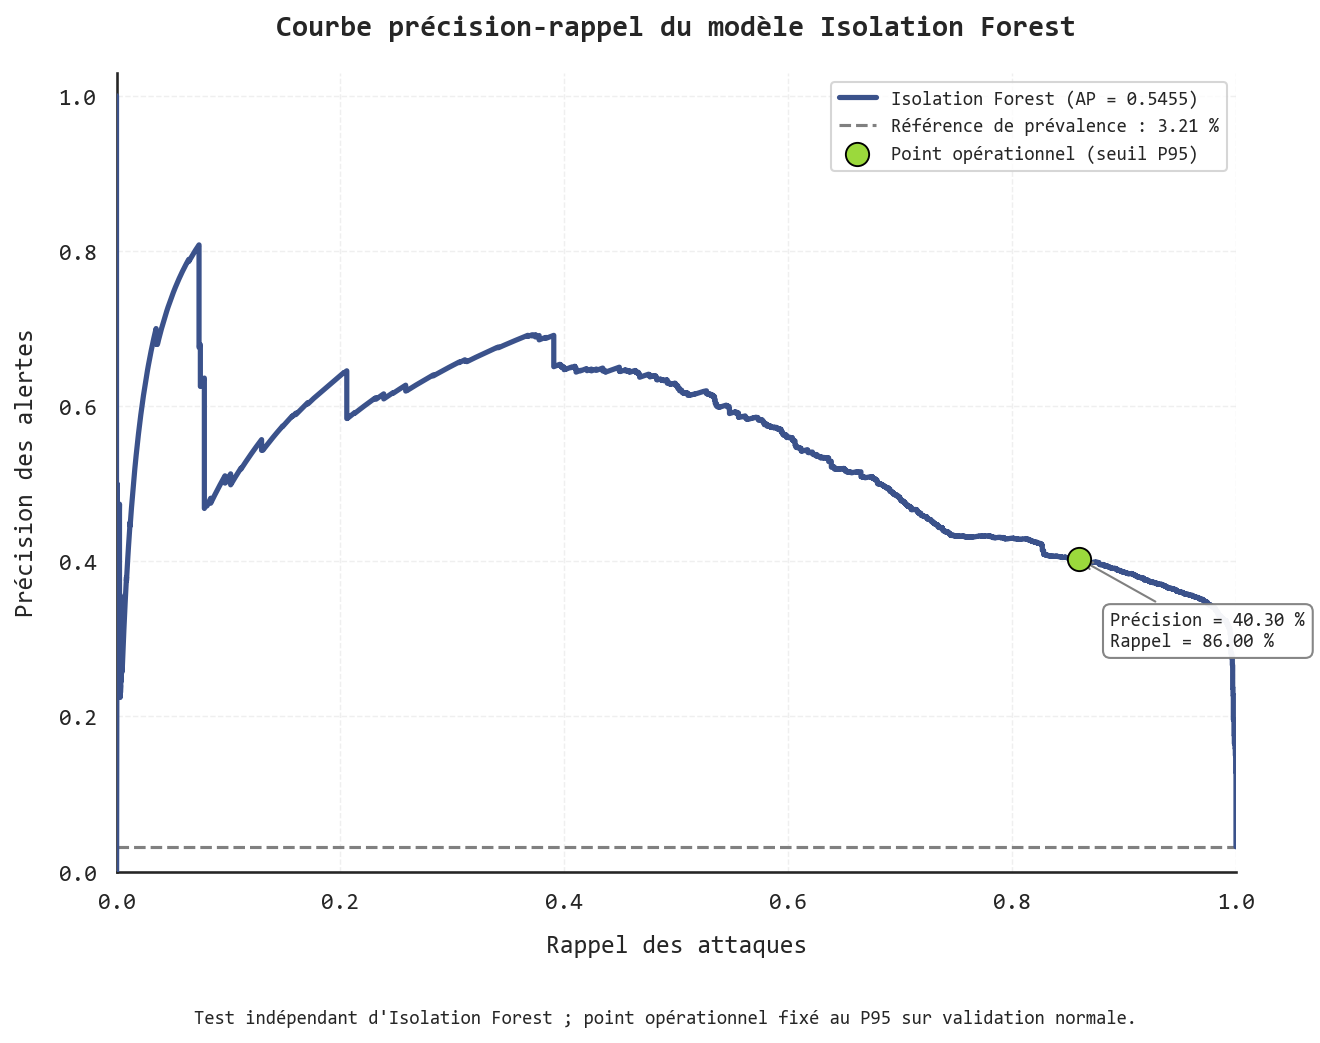


POINT OPERATIONNEL


,Modele,Observations_test,Normaux_test,Attaques_test,Prevalence_attaques,Seuil_P95_validation,Precision_P95,Rappel_P95,Average_Precision,TN,FP,FN,TP
0,Isolation Forest,104871,101507,3364,0.032078,0.526246,0.403037,0.859988,0.545501,97222,4285,471,2893


In [93]:

# ============================================================
# CELLULE 22 — COURBE PRECISION-RAPPEL ISOLATION FOREST
# ============================================================
# Dataset : UNSW-NB15
# Modele : Isolation Forest
# Protocole : One-Class Learning
#
# Classe positive : 1 = Attaque
# Score d'anomalie : -score_samples(X)
#
# Objectif :
# - Calculer la courbe precision-rappel
# - Calculer l'Average Precision (AP)
# - Afficher le point operationnel du seuil P95
# - Exporter les figures et les donnees
#
# Aucun nouvel entrainement.
# Aucun recalibrage.
# Aucune optimisation sur le test.
# ============================================================

import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix
)

print("=" * 75)
print("CELLULE 22 — COURBE PRECISION-RAPPEL ISOLATION FOREST")
print("=" * 75)

IF_PR_FIGURE_READY = False

# ------------------------------------------------------------
# 1. REPERTOIRES DU PROJET AUTONOME
# ------------------------------------------------------------

IF_BASE_DIR = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest"
)

IF_PR_RESULTS_DIR = (
    IF_BASE_DIR / "resultats_Isolation_Forest"
)

IF_PR_SCORES_DIR = (
    IF_PR_RESULTS_DIR / "scores"
)

IF_PR_ARTIFACTS_DIR = (
    IF_PR_RESULTS_DIR / "artefacts"
)

IF_PR_MATRICES_DIR = (
    IF_PR_ARTIFACTS_DIR / "matrices_isolation_forest"
)

IF_PR_FIGURES_DIR = (
    IF_PR_RESULTS_DIR / "figures"
)

IF_PR_TABLES_DIR = (
    IF_PR_RESULTS_DIR / "tableaux"
)

for directory in [
    IF_PR_FIGURES_DIR,
    IF_PR_TABLES_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 2. CHEMINS DES ARTEFACTS EXPERIMENTAUX
# ------------------------------------------------------------

IF_PR_SCORES_PATH = (
    IF_PR_SCORES_DIR /
    "scores_test_Isolation_Forest.npy"
)

IF_PR_LABELS_PATH = (
    IF_PR_MATRICES_DIR /
    "y_test.npy"
)

IF_PR_IDS_PATH = (
    IF_PR_MATRICES_DIR /
    "ids_test.npy"
)

IF_PR_THRESHOLD_PATH = (
    IF_PR_ARTIFACTS_DIR /
    "seuil_Isolation_Forest_95e_percentile.json"
)

IF_PR_VALIDATION_SCORES_PATH = (
    IF_PR_SCORES_DIR /
    "scores_validation_normale_IF.npy"
)

IF_PR_METRICS_PATH = (
    IF_PR_ARTIFACTS_DIR /
    "rapport_metriques_globales_IF.json"
)

# ------------------------------------------------------------
# 3. VERIFICATION DES FICHIERS INDISPENSABLES
# ------------------------------------------------------------

IF_PR_REQUIRED_FILES = {
    "Scores du test": IF_PR_SCORES_PATH,
    "Etiquettes du test": IF_PR_LABELS_PATH,
    "Identifiants du test": IF_PR_IDS_PATH,
    "Seuil P95": IF_PR_THRESHOLD_PATH,
    "Scores de validation": IF_PR_VALIDATION_SCORES_PATH
}

for name, path in IF_PR_REQUIRED_FILES.items():

    if not path.is_file():

        raise FileNotFoundError(
            f"{name} introuvable : {path}\n"
            "Verifier les exports des cellules precedentes."
        )

print("\nArtefacts necessaires : PRESENTS")

# ------------------------------------------------------------
# 4. CHARGEMENT DES SCORES ET ETIQUETTES
# ------------------------------------------------------------

IF_pr_scores = np.asarray(
    np.load(
        IF_PR_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

IF_pr_labels = np.asarray(
    np.load(
        IF_PR_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=np.int8
)

IF_pr_ids = np.asarray(
    np.load(
        IF_PR_IDS_PATH,
        allow_pickle=False
    ),
    dtype=np.int64
)

# ------------------------------------------------------------
# 5. CONTROLE DES DONNEES
# ------------------------------------------------------------

if not all(
    array.ndim == 1
    for array in [
        IF_pr_scores,
        IF_pr_labels,
        IF_pr_ids
    ]
):
    raise ValueError(
        "Scores, etiquettes et identifiants "
        "doivent etre des vecteurs."
    )

IF_PR_N = int(
    IF_pr_scores.size
)

if IF_PR_N == 0:
    raise ValueError(
        "Aucune observation dans le test."
    )

if not (
    len(IF_pr_scores)
    == len(IF_pr_labels)
    == len(IF_pr_ids)
):
    raise ValueError(
        "Scores, etiquettes et identifiants "
        "de tailles differentes."
    )

if not np.isfinite(IF_pr_scores).all():
    raise ValueError(
        "Les scores contiennent NaN ou inf."
    )

if set(np.unique(IF_pr_labels)) != {0, 1}:
    raise ValueError(
        "Le test doit contenir les classes 0 et 1."
    )

if len(np.unique(IF_pr_ids)) != IF_PR_N:
    raise ValueError(
        "Des identifiants du test sont dupliques."
    )

# Controle additionnel si le dataset est
# encore charge dans le notebook.

if "IF_y" in globals():

    IF_pr_expected_labels = (
        IF_y.iloc[IF_pr_ids]
        .to_numpy(dtype=np.int8)
    )

    if not np.array_equal(
        IF_pr_labels,
        IF_pr_expected_labels
    ):
        raise RuntimeError(
            "Etiquettes sauvegardees non alignees "
            "avec les observations du dataset."
        )

print("\nAlignement des donnees : VALIDE")

# ------------------------------------------------------------
# 6. CHARGEMENT DU SEUIL OFFICIEL
# ------------------------------------------------------------

with open(
    IF_PR_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:

    IF_pr_threshold_report = json.load(file)

IF_PR_FIXED_THRESHOLD = float(
    IF_pr_threshold_report["seuil"]
)

if not np.isfinite(IF_PR_FIXED_THRESHOLD):
    raise ValueError(
        "Seuil de calibration non fini."
    )

if IF_pr_threshold_report.get(
    "population_calibration"
) != "validation_normale":

    raise RuntimeError(
        "Le seuil ne provient pas "
        "de la validation normale."
    )

if IF_pr_threshold_report.get("percentile") != 95:

    raise RuntimeError(
        "Le seuil n'a pas ete calibre au P95."
    )

if IF_pr_threshold_report.get(
    "operateur_decision"
) != ">":

    raise RuntimeError(
        "La regle de decision doit etre score > seuil."
    )

if IF_pr_threshold_report.get(
    "orientation"
) != "higher_is_more_anomalous":

    raise RuntimeError(
        "Orientation des scores incorrecte."
    )

# ------------------------------------------------------------
# 7. VERIFICATION DIRECTE DE LA CALIBRATION
# ------------------------------------------------------------

IF_pr_validation_scores = np.asarray(
    np.load(
        IF_PR_VALIDATION_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

if (
    IF_pr_validation_scores.ndim != 1
    or IF_pr_validation_scores.size == 0
    or not np.isfinite(
        IF_pr_validation_scores
    ).all()
):
    raise ValueError(
        "Scores de validation invalides."
    )

IF_PR_RECALCULATED_THRESHOLD = float(
    np.percentile(
        IF_pr_validation_scores,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_PR_FIXED_THRESHOLD,
    IF_PR_RECALCULATED_THRESHOLD,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil sauvegarde ne correspond plus "
        "au 95e percentile de validation."
    )

print("\nCalibration sur validation normale : VALIDEE")

# ------------------------------------------------------------
# 8. EFFECTIFS DU TEST
# ------------------------------------------------------------

IF_PR_N_NORMAL = int(
    np.count_nonzero(
        IF_pr_labels == 0
    )
)

IF_PR_N_ATTACK = int(
    np.count_nonzero(
        IF_pr_labels == 1
    )
)

IF_PR_ATTACK_PREVALENCE = (
    IF_PR_N_ATTACK / IF_PR_N
)

print("\nREPARTITION DU TEST")

print(
    "Observations :",
    f"{IF_PR_N:,}"
)

print(
    "Trafic normal :",
    f"{IF_PR_N_NORMAL:,}"
)

print(
    "Attaques :",
    f"{IF_PR_N_ATTACK:,}"
)

print(
    "Prevalence des attaques :",
    f"{100 * IF_PR_ATTACK_PREVALENCE:.4f} %"
)

# ------------------------------------------------------------
# 9. CALCUL DE LA COURBE PRECISION-RAPPEL
# ------------------------------------------------------------

# Les scores continus sont utilises.
# Aucun seuil operationnel n'est modifie.
#
# scikit-learn retourne :
# precision : n + 1 elements
# recall    : n + 1 elements
# thresholds: n elements

IF_pr_precision, IF_pr_recall, IF_pr_thresholds = (
    precision_recall_curve(
        IF_pr_labels,
        IF_pr_scores,
        pos_label=1
    )
)

# ------------------------------------------------------------
# 10. CALCUL DE L'AVERAGE PRECISION
# ------------------------------------------------------------

IF_PR_AVERAGE_PRECISION = float(
    average_precision_score(
        IF_pr_labels,
        IF_pr_scores
    )
)

if not np.isfinite(
    IF_PR_AVERAGE_PRECISION
):
    raise RuntimeError(
        "Average Precision non finie."
    )

if not 0 <= IF_PR_AVERAGE_PRECISION <= 1:
    raise RuntimeError(
        "Average Precision hors de [0, 1]."
    )

# ------------------------------------------------------------
# 11. POINT OPERATIONNEL DU SEUIL P95
# ------------------------------------------------------------

IF_pr_predictions = (
    IF_pr_scores > IF_PR_FIXED_THRESHOLD
).astype(np.int8)

IF_PR_OPERATING_PRECISION = float(
    precision_score(
        IF_pr_labels,
        IF_pr_predictions,
        zero_division=0
    )
)

IF_PR_OPERATING_RECALL = float(
    recall_score(
        IF_pr_labels,
        IF_pr_predictions,
        zero_division=0
    )
)

IF_pr_cm = confusion_matrix(
    IF_pr_labels,
    IF_pr_predictions,
    labels=[0, 1]
)

IF_pr_tn, IF_pr_fp, IF_pr_fn, IF_pr_tp = [
    int(value)
    for value in IF_pr_cm.ravel()
]

# ------------------------------------------------------------
# 12. CONTROLES DE COHERENCE
# ------------------------------------------------------------

if len(IF_pr_precision) != len(IF_pr_recall):
    raise RuntimeError(
        "Dimensions precision/rappel incompatibles."
    )

if len(IF_pr_precision) != (
    len(IF_pr_thresholds) + 1
):
    raise RuntimeError(
        "Dimensions des seuils PR incorrectes."
    )

if (
    IF_pr_tn
    + IF_pr_fp
    + IF_pr_fn
    + IF_pr_tp
) != IF_PR_N:
    raise RuntimeError(
        "Matrice de confusion incoherente."
    )

if not np.all(
    (IF_pr_precision >= 0)
    & (IF_pr_precision <= 1)
):
    raise ValueError(
        "Precision hors limites."
    )

if not np.all(
    (IF_pr_recall >= 0)
    & (IF_pr_recall <= 1)
):
    raise ValueError(
        "Rappel hors limites."
    )

# ------------------------------------------------------------
# 13. VERIFICATION DES METRIQUES DE LA CELLULE 19
# ------------------------------------------------------------

if IF_PR_METRICS_PATH.is_file():

    with open(
        IF_PR_METRICS_PATH,
        "r",
        encoding="utf-8"
    ) as file:

        IF_pr_previous_report = json.load(file)

    IF_pr_previous_metrics = (
        IF_pr_previous_report.get(
            "metriques", {}
        )
    )

    IF_pr_previous_ap = (
        IF_pr_previous_metrics.get(
            "Average Precision"
        )
    )

    if IF_pr_previous_ap is not None:

        if not np.isclose(
            float(IF_pr_previous_ap),
            IF_PR_AVERAGE_PRECISION,
            rtol=1e-12,
            atol=1e-12
        ):
            raise RuntimeError(
                "L'Average Precision differe "
                "du resultat de la cellule 19."
            )

    for metric_name, current_value in [
        (
            "Precision",
            IF_PR_OPERATING_PRECISION
        ),
        (
            "Recall",
            IF_PR_OPERATING_RECALL
        )
    ]:

        previous_value = (
            IF_pr_previous_metrics.get(
                metric_name
            )
        )

        if previous_value is not None:

            if not np.isclose(
                float(previous_value),
                current_value,
                rtol=1e-12,
                atol=1e-12
            ):
                raise RuntimeError(
                    f"Incoherence avec la cellule 19 : "
                    f"{metric_name}"
                )

print("\nMESURES DE PERFORMANCE")

print(
    "Average Precision :",
    f"{IF_PR_AVERAGE_PRECISION:.6f}"
)

print(
    "Precision au seuil P95 :",
    f"{100 * IF_PR_OPERATING_PRECISION:.4f} %"
)

print(
    "Rappel au seuil P95 :",
    f"{100 * IF_PR_OPERATING_RECALL:.4f} %"
)

# ------------------------------------------------------------
# 14. CONFIGURATION GRAPHIQUE
# ------------------------------------------------------------

IF_pr_available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

IF_PR_FONT = (
    "Consolas"
    if "Consolas" in IF_pr_available_fonts
    else "DejaVu Sans Mono"
)

plt.rcParams.update({
    "font.family": IF_PR_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

IF_PR_CURVE_COLOR = plt.cm.viridis(0.25)
IF_PR_POINT_COLOR = plt.cm.viridis(0.85)

# ------------------------------------------------------------
# 15. CREATION DE LA FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 7),
    dpi=150
)

# Courbe precision-rappel

ax.plot(
    IF_pr_recall,
    IF_pr_precision,
    color=IF_PR_CURVE_COLOR,
    linewidth=2.5,
    label=(
        "Isolation Forest "
        f"(AP = {IF_PR_AVERAGE_PRECISION:.4f})"
    ),
    zorder=3
)

# Reference correspondant a la prevalence
# des attaques dans le test.

ax.axhline(
    IF_PR_ATTACK_PREVALENCE,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=(
        "Référence de prévalence : "
        f"{100 * IF_PR_ATTACK_PREVALENCE:.2f} %"
    ),
    zorder=2
)

# Point operationnel : seuil fixe au P95

ax.scatter(
    IF_PR_OPERATING_RECALL,
    IF_PR_OPERATING_PRECISION,
    s=125,
    color=IF_PR_POINT_COLOR,
    edgecolors="black",
    linewidths=0.9,
    label="Point opérationnel (seuil P95)",
    zorder=5
)

# Annotation des resultats au point P95

IF_pr_annotation = (
    f"Précision = {100 * IF_PR_OPERATING_PRECISION:.2f} %\n"
    f"Rappel = {100 * IF_PR_OPERATING_RECALL:.2f} %"
)

ax.annotate(
    IF_pr_annotation,
    xy=(
        IF_PR_OPERATING_RECALL,
        IF_PR_OPERATING_PRECISION
    ),
    xytext=(15, -42),
    textcoords="offset points",
    fontsize=9,
    fontfamily=IF_PR_FONT,
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "gray",
        "alpha": 0.95
    },
    arrowprops={
        "arrowstyle": "->",
        "color": "gray"
    }
)

# ------------------------------------------------------------
# 16. TITRES ET AXES EN FRANCAIS
# ------------------------------------------------------------

ax.set_title(
    "Courbe précision-rappel du modèle Isolation Forest",
    fontsize=14,
    fontweight="bold",
    fontfamily=IF_PR_FONT,
    pad=18
)

ax.set_xlabel(
    "Rappel des attaques",
    fontsize=12,
    fontfamily=IF_PR_FONT,
    labelpad=10
)

ax.set_ylabel(
    "Précision des alertes",
    fontsize=12,
    fontfamily=IF_PR_FONT,
    labelpad=10
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)

ax.set_xticks(
    np.linspace(0, 1, 6)
)

ax.set_yticks(
    np.linspace(0, 1, 6)
)

# ------------------------------------------------------------
# 17. STYLE SCIENTIFIQUE
# ------------------------------------------------------------

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper right",
    fontsize=9,
    frameon=True
)

fig.text(
    0.5,
    0.015,
    (
        "Test indépendant d'Isolation Forest ; "
        "point opérationnel fixé au P95 "
        "sur validation normale."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_PR_FONT
)

fig.tight_layout(
    rect=(0, 0.055, 1, 1)
)

# ------------------------------------------------------------
# 18. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

IF_PR_FIGURE_NAME = (
    "courbe_precision_rappel_Isolation_Forest"
)

IF_PR_PNG_PATH = (
    IF_PR_FIGURES_DIR /
    f"{IF_PR_FIGURE_NAME}.png"
)

IF_PR_PDF_PATH = (
    IF_PR_FIGURES_DIR /
    f"{IF_PR_FIGURE_NAME}.pdf"
)

IF_PR_SVG_PATH = (
    IF_PR_FIGURES_DIR /
    f"{IF_PR_FIGURE_NAME}.svg"
)

for path, fmt in [
    (IF_PR_PNG_PATH, "png"),
    (IF_PR_PDF_PATH, "pdf"),
    (IF_PR_SVG_PATH, "svg")
]:

    fig.savefig(
        path,
        format=fmt,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 19. EXPORT DES POINTS DE LA COURBE
# ------------------------------------------------------------

# scikit-learn retourne un point precision/rappel
# supplementaire sans seuil associe.
#
# On ajoute NaN au dernier seuil pour conserver
# des colonnes de meme longueur.

IF_pr_thresholds_aligned = np.append(
    IF_pr_thresholds,
    np.nan
)

IF_PR_CURVE_TABLE = pd.DataFrame({
    "Rappel": IF_pr_recall,
    "Precision": IF_pr_precision,
    "Seuil_theorique": IF_pr_thresholds_aligned
})

IF_PR_CURVE_TABLE_PATH = (
    IF_PR_TABLES_DIR /
    "points_courbe_precision_rappel_IF.csv"
)

IF_PR_CURVE_TABLE.to_csv(
    IF_PR_CURVE_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 20. EXPORT DU POINT OPERATIONNEL
# ------------------------------------------------------------

IF_PR_OPERATING_TABLE = pd.DataFrame([{
    "Modele": "Isolation Forest",
    "Observations_test": IF_PR_N,
    "Normaux_test": IF_PR_N_NORMAL,
    "Attaques_test": IF_PR_N_ATTACK,
    "Prevalence_attaques": IF_PR_ATTACK_PREVALENCE,
    "Seuil_P95_validation": IF_PR_FIXED_THRESHOLD,
    "Precision_P95": IF_PR_OPERATING_PRECISION,
    "Rappel_P95": IF_PR_OPERATING_RECALL,
    "Average_Precision": IF_PR_AVERAGE_PRECISION,
    "TN": IF_pr_tn,
    "FP": IF_pr_fp,
    "FN": IF_pr_fn,
    "TP": IF_pr_tp
}])

IF_PR_OPERATING_TABLE_PATH = (
    IF_PR_TABLES_DIR /
    "point_operationnel_precision_rappel_IF.csv"
)

IF_PR_OPERATING_TABLE.to_csv(
    IF_PR_OPERATING_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nPOINT OPERATIONNEL")

display(IF_PR_OPERATING_TABLE)

# ------------------------------------------------------------
# 21. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_PR_REPORT = {
    "dataset": "UNSW-NB15",
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "test_independant_IF",
    "partitionnement": "autonome_par_groupes",
    "nombre_observations": IF_PR_N,
    "nombre_normaux": IF_PR_N_NORMAL,
    "nombre_attaques": IF_PR_N_ATTACK,
    "prevalence_attaques": float(
        IF_PR_ATTACK_PREVALENCE
    ),
    "score": "-score_samples",
    "orientation": "higher_is_more_anomalous",
    "Average_Precision": IF_PR_AVERAGE_PRECISION,
    "seuil_operationnel": IF_PR_FIXED_THRESHOLD,
    "calibration": "P95_validation_normale",
    "operateur_decision": ">",
    "precision_operationnelle": IF_PR_OPERATING_PRECISION,
    "rappel_operationnel": IF_PR_OPERATING_RECALL,
    "nombre_points_courbe": int(
        len(IF_pr_precision)
    ),
    "modele_reentraine": False,
    "seuil_recalibre": False,
    "test_utilise_pour_optimisation": False,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_PR_REPORT_PATH = (
    IF_PR_ARTIFACTS_DIR /
    "rapport_courbe_precision_rappel_IF.json"
)

with open(
    IF_PR_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_PR_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 22. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

IF_PR_OUTPUT_FILES = [
    IF_PR_PNG_PATH,
    IF_PR_PDF_PATH,
    IF_PR_SVG_PATH,
    IF_PR_CURVE_TABLE_PATH,
    IF_PR_OPERATING_TABLE_PATH,
    IF_PR_REPORT_PATH
]

for path in IF_PR_OUTPUT_FILES:

    if not path.is_file():
        raise RuntimeError(
            f"Export manquant : {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Export vide : {path}"
        )

CELLULE 23 — DISTRIBUTION DES SCORES ISOLATION FOREST

Artefacts experimentaux : PRESENTS

Seuil P95 : VERIFIE
Seuil operationnel : 0.5262464253

POPULATIONS DU TEST
Trafic normal : 101,507
Attaques : 3,364

STATISTIQUES DES SCORES PAR CLASSE


,Population,Effectif,Minimum,Moyenne,Mediane,Ecart_type,P05,P25,P50,P75,P95,P99,Maximum
0,Trafic normal,101507,0.336851,0.403523,0.396557,0.051410,0.347682,0.362557,0.396557,0.425237,0.509571,0.592830,0.697460
1,Attaques,3364,0.428085,0.581606,0.593145,0.043851,0.499431,0.546577,0.593145,0.616636,0.637874,0.648122,0.681928


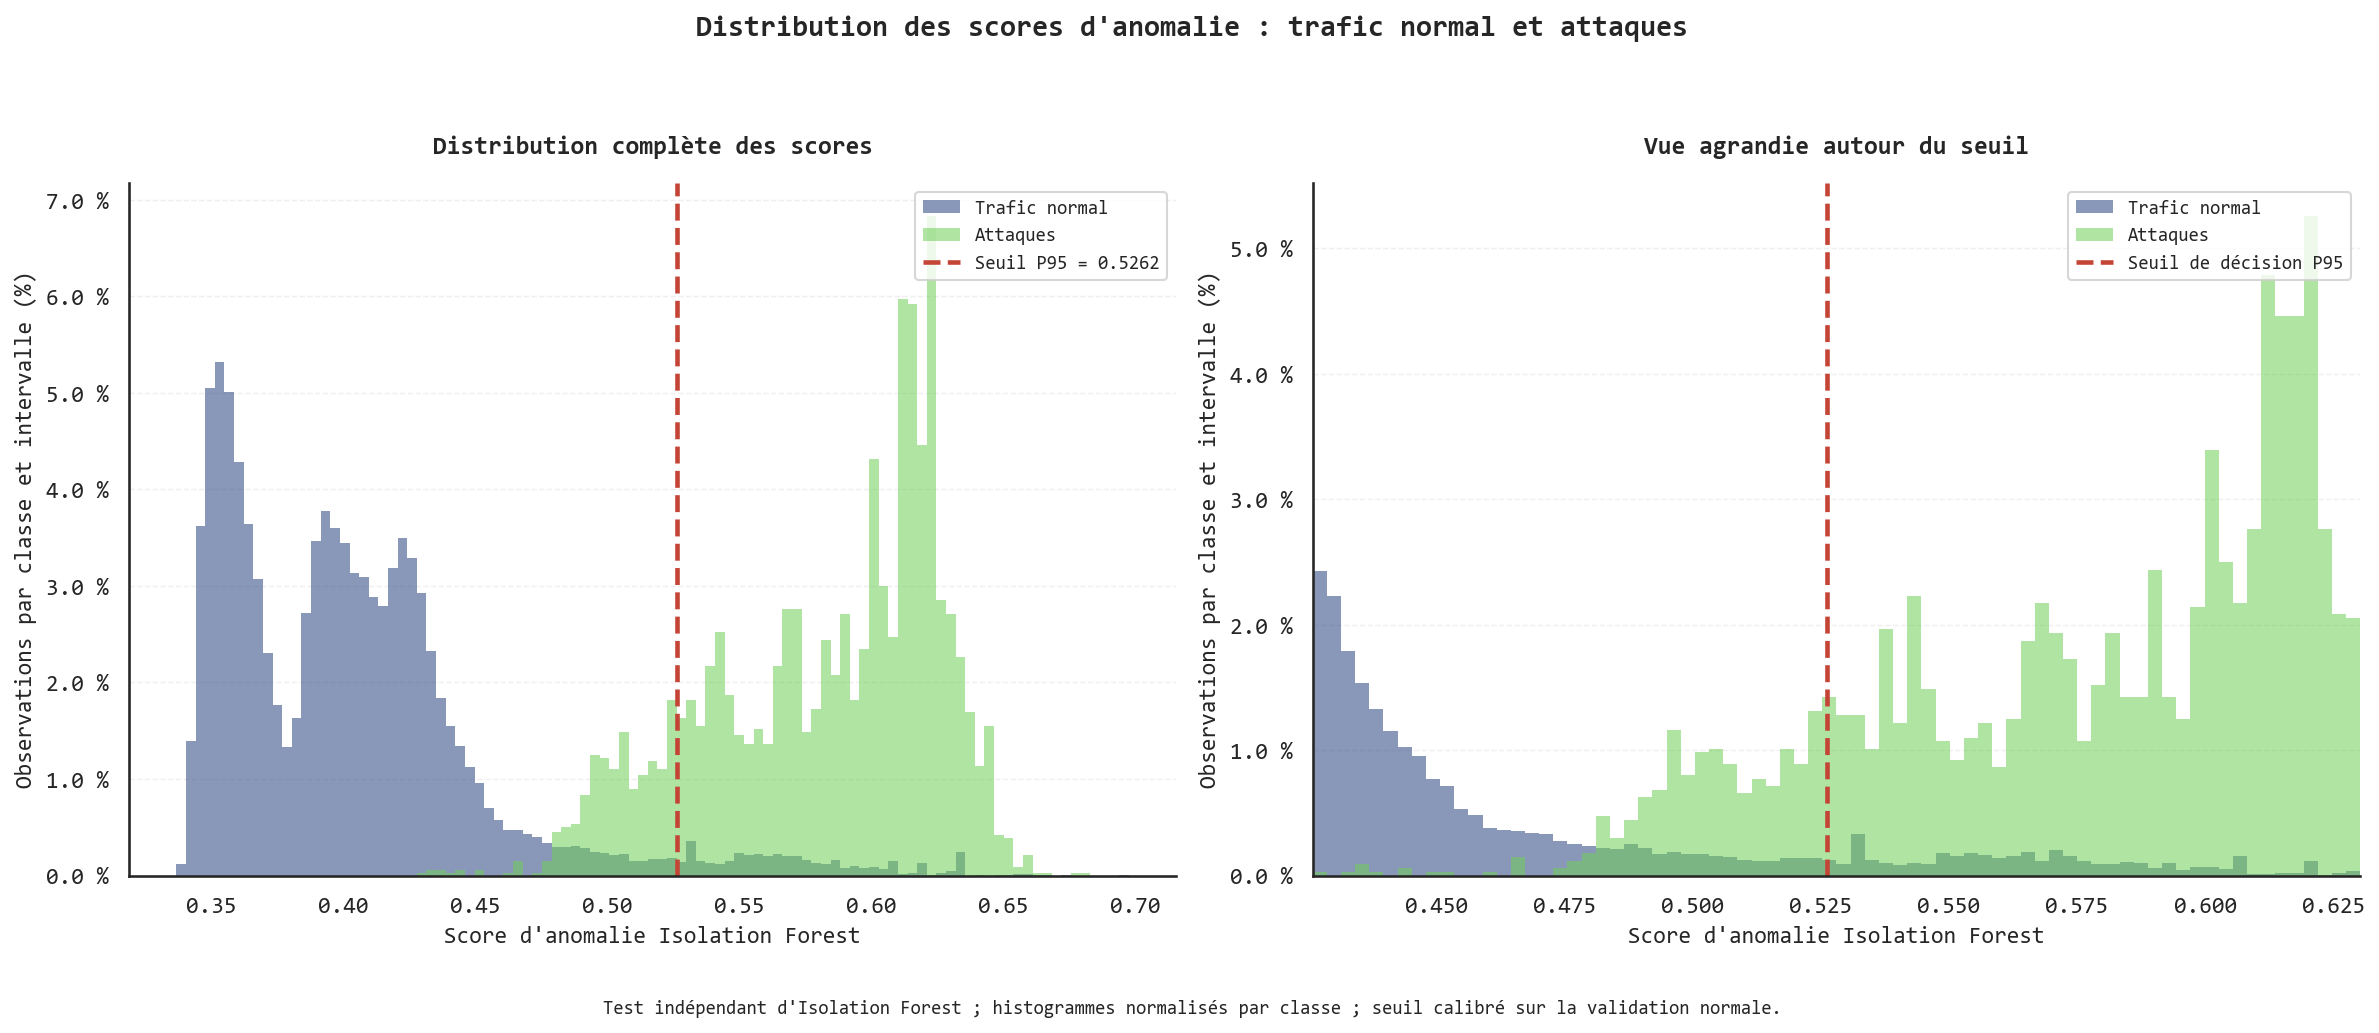


RESULTATS AU SEUIL P95


,Modele,Observations_test,Normaux_test,Attaques_test,Seuil_P95_validation,TN,FP,FN,TP,FPR_pct,TPR_pct
0,Isolation Forest,104871,101507,3364,0.526246,97222,4285,471,2893,4.221384,85.998811


In [95]:

# ============================================================
# CELLULE 23 — DISTRIBUTION COMPARATIVE DES SCORES IF
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Figure :
# - Distribution complete : normaux et attaques
# - Zoom autour du seuil P95
#
# Score = -score_samples(X)
# Score eleve = observation plus anormale
#
# Les histogrammes sont normalises par classe.
#
# Aucun fit()
# Aucun recalibrage
# Aucun changement du seuil
# ============================================================

import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mticker

from sklearn.metrics import confusion_matrix

print("=" * 75)
print("CELLULE 23 — DISTRIBUTION DES SCORES ISOLATION FOREST")
print("=" * 75)

IF_DISTRIBUTION_TEST_READY = False

# ------------------------------------------------------------
# 1. REPERTOIRES DU PROJET
# ------------------------------------------------------------

IF_BASE_DIR = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest"
)

IF_DIST_RESULTS_DIR = (
    IF_BASE_DIR / "resultats_Isolation_Forest"
)

IF_DIST_SCORES_DIR = (
    IF_DIST_RESULTS_DIR / "scores"
)

IF_DIST_ARTIFACTS_DIR = (
    IF_DIST_RESULTS_DIR / "artefacts"
)

IF_DIST_MATRICES_DIR = (
    IF_DIST_ARTIFACTS_DIR / "matrices_isolation_forest"
)

IF_DIST_FIGURES_DIR = (
    IF_DIST_RESULTS_DIR / "figures"
)

IF_DIST_TABLES_DIR = (
    IF_DIST_RESULTS_DIR / "tableaux"
)

IF_DIST_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IF_DIST_TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. LOCALISATION DES ARTEFACTS
# ------------------------------------------------------------

IF_DIST_SCORES_PATH = (
    IF_DIST_SCORES_DIR /
    "scores_test_Isolation_Forest.npy"
)

IF_DIST_LABELS_PATH = (
    IF_DIST_MATRICES_DIR /
    "y_test.npy"
)

IF_DIST_IDS_PATH = (
    IF_DIST_MATRICES_DIR /
    "ids_test.npy"
)

IF_DIST_THRESHOLD_PATH = (
    IF_DIST_ARTIFACTS_DIR /
    "seuil_Isolation_Forest_95e_percentile.json"
)

IF_DIST_VAL_SCORES_PATH = (
    IF_DIST_SCORES_DIR /
    "scores_validation_normale_IF.npy"
)

IF_DIST_METRICS_PATH = (
    IF_DIST_ARTIFACTS_DIR /
    "rapport_metriques_globales_IF.json"
)

IF_DIST_REQUIRED_FILES = {
    "Scores du test": IF_DIST_SCORES_PATH,
    "Etiquettes du test": IF_DIST_LABELS_PATH,
    "Identifiants du test": IF_DIST_IDS_PATH,
    "Seuil de calibration": IF_DIST_THRESHOLD_PATH,
    "Scores de validation": IF_DIST_VAL_SCORES_PATH
}

for description, path in IF_DIST_REQUIRED_FILES.items():

    if not path.is_file():

        raise FileNotFoundError(
            f"{description} introuvable : {path}\n"
            "Verifier les exports des cellules precedentes."
        )

print("\nArtefacts experimentaux : PRESENTS")

# ------------------------------------------------------------
# 3. CHARGEMENT DES SCORES ET ETIQUETTES
# ------------------------------------------------------------

IF_dist_scores = np.asarray(
    np.load(
        IF_DIST_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

IF_dist_labels = np.asarray(
    np.load(
        IF_DIST_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=np.int8
)

IF_dist_ids = np.asarray(
    np.load(
        IF_DIST_IDS_PATH,
        allow_pickle=False
    ),
    dtype=np.int64
)

# ------------------------------------------------------------
# 4. VALIDATION DE L'ALIGNEMENT
# ------------------------------------------------------------

if not all(
    array.ndim == 1
    for array in [
        IF_dist_scores,
        IF_dist_labels,
        IF_dist_ids
    ]
):
    raise ValueError(
        "Scores, etiquettes et identifiants "
        "doivent etre unidimensionnels."
    )

IF_DIST_N = len(IF_dist_scores)

if IF_DIST_N == 0:
    raise ValueError(
        "Aucune observation dans le test."
    )

if not (
    len(IF_dist_scores)
    == len(IF_dist_labels)
    == len(IF_dist_ids)
):
    raise ValueError(
        "Dimensions des donnees incompatibles."
    )

if not np.isfinite(IF_dist_scores).all():
    raise ValueError(
        "Les scores contiennent NaN ou inf."
    )

if set(np.unique(IF_dist_labels)) != {0, 1}:
    raise ValueError(
        "Les classes 0 et 1 sont necessaires."
    )

if len(np.unique(IF_dist_ids)) != IF_DIST_N:
    raise ValueError(
        "Des identifiants du test sont dupliques."
    )

# Controle supplementaire si les etiquettes
# originales sont presentes en memoire.

if "IF_y" in globals():

    expected_labels = (
        IF_y.iloc[IF_dist_ids]
        .to_numpy(dtype=np.int8)
    )

    if not np.array_equal(
        expected_labels,
        IF_dist_labels
    ):
        raise RuntimeError(
            "Etiquettes sauvegardees non alignees "
            "avec le dataset original."
        )

if "IF_ids_test" in globals():

    if not np.array_equal(
        IF_dist_ids,
        np.asarray(
            IF_ids_test,
            dtype=np.int64
        )
    ):
        raise RuntimeError(
            "L'ordre des observations du test a change."
        )

# ------------------------------------------------------------
# 5. RECUPERATION DU SEUIL P95
# ------------------------------------------------------------

with open(
    IF_DIST_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:

    IF_dist_threshold_report = json.load(file)

IF_DIST_THRESHOLD = float(
    IF_dist_threshold_report["seuil"]
)

if not np.isfinite(IF_DIST_THRESHOLD):
    raise ValueError(
        "Le seuil sauvegarde est invalide."
    )

if IF_dist_threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "Le seuil ne provient pas de la validation normale."
    )

if IF_dist_threshold_report.get("percentile") != 95:
    raise RuntimeError(
        "La calibration doit utiliser le 95e percentile."
    )

if IF_dist_threshold_report.get(
    "operateur_decision"
) != ">":
    raise RuntimeError(
        "La regle de classification attendue est score > seuil."
    )

if IF_dist_threshold_report.get(
    "orientation"
) != "higher_is_more_anomalous":
    raise RuntimeError(
        "Convention des scores incoherente."
    )

# ------------------------------------------------------------
# 6. VERIFICATION DU SEUIL SUR VALIDATION
# ------------------------------------------------------------

IF_dist_val_scores = np.asarray(
    np.load(
        IF_DIST_VAL_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

if (
    IF_dist_val_scores.ndim != 1
    or IF_dist_val_scores.size == 0
    or not np.isfinite(
        IF_dist_val_scores
    ).all()
):
    raise ValueError(
        "Les scores de validation sont invalides."
    )

IF_DIST_EXPECTED_THRESHOLD = float(
    np.percentile(
        IF_dist_val_scores,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_DIST_THRESHOLD,
    IF_DIST_EXPECTED_THRESHOLD,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond plus au "
        "95e percentile des scores normaux de validation."
    )

print("\nSeuil P95 : VERIFIE")

print(
    "Seuil operationnel :",
    f"{IF_DIST_THRESHOLD:.10f}"
)

# ------------------------------------------------------------
# 7. SEPARATION DES DEUX POPULATIONS
# ------------------------------------------------------------

IF_dist_normal = (
    IF_dist_scores[
        IF_dist_labels == 0
    ]
)

IF_dist_attack = (
    IF_dist_scores[
        IF_dist_labels == 1
    ]
)

IF_DIST_N_NORMAL = int(
    len(IF_dist_normal)
)

IF_DIST_N_ATTACK = int(
    len(IF_dist_attack)
)

print("\nPOPULATIONS DU TEST")

print(
    "Trafic normal :",
    f"{IF_DIST_N_NORMAL:,}"
)

print(
    "Attaques :",
    f"{IF_DIST_N_ATTACK:,}"
)

# ------------------------------------------------------------
# 8. PREDICTIONS AU SEUIL FIXE
# ------------------------------------------------------------

IF_dist_predictions = (
    IF_dist_scores > IF_DIST_THRESHOLD
).astype(np.int8)

IF_dist_cm = confusion_matrix(
    IF_dist_labels,
    IF_dist_predictions,
    labels=[0, 1]
)

IF_dist_tn, IF_dist_fp, IF_dist_fn, IF_dist_tp = [
    int(x)
    for x in IF_dist_cm.ravel()
]

IF_DIST_FPR = float(
    IF_dist_fp / IF_DIST_N_NORMAL
)

IF_DIST_TPR = float(
    IF_dist_tp / IF_DIST_N_ATTACK
)

# ------------------------------------------------------------
# 9. CONTROLE DES RESULTATS PRECEDENTS
# ------------------------------------------------------------

if IF_DIST_METRICS_PATH.is_file():

    with open(
        IF_DIST_METRICS_PATH,
        "r",
        encoding="utf-8"
    ) as file:

        IF_dist_metrics_report = json.load(file)

    saved_cm = IF_dist_metrics_report.get(
        "matrice_confusion"
    )

    if isinstance(saved_cm, dict):

        expected_cm = {
            "TN": IF_dist_tn,
            "FP": IF_dist_fp,
            "FN": IF_dist_fn,
            "TP": IF_dist_tp
        }

        if saved_cm != expected_cm:
            raise RuntimeError(
                "La matrice de confusion differe "
                "du rapport de la cellule 19."
            )

# ------------------------------------------------------------
# 10. STATISTIQUES DES DISTRIBUTIONS
# ------------------------------------------------------------

def IF_dist_describe(values, population):

    return {
        "Population": population,
        "Effectif": int(len(values)),
        "Minimum": float(np.min(values)),
        "Moyenne": float(np.mean(values)),
        "Mediane": float(np.median(values)),
        "Ecart_type": float(np.std(values)),
        "P05": float(np.percentile(values, 5)),
        "P25": float(np.percentile(values, 25)),
        "P50": float(np.percentile(values, 50)),
        "P75": float(np.percentile(values, 75)),
        "P95": float(np.percentile(values, 95)),
        "P99": float(np.percentile(values, 99)),
        "Maximum": float(np.max(values))
    }


IF_DIST_STATISTICS = pd.DataFrame([
    IF_dist_describe(
        IF_dist_normal,
        "Trafic normal"
    ),
    IF_dist_describe(
        IF_dist_attack,
        "Attaques"
    )
])

print("\nSTATISTIQUES DES SCORES PAR CLASSE")

display(IF_DIST_STATISTICS)

# ------------------------------------------------------------
# 11. CONFIGURATION DE LA POLICE SCIENTIFIQUE
# ------------------------------------------------------------

IF_dist_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

IF_DIST_FONT = (
    "Consolas"
    if "Consolas" in IF_dist_fonts
    else "DejaVu Sans Mono"
)

plt.rcParams.update({
    "font.family": IF_DIST_FONT,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

IF_DIST_COLOR_NORMAL = plt.cm.viridis(0.25)
IF_DIST_COLOR_ATTACK = plt.cm.viridis(0.78)
IF_DIST_COLOR_THRESHOLD = "#C44536"

# ------------------------------------------------------------
# 12. CONSTRUCTION DES INTERVALLES COMMUNS
# ------------------------------------------------------------

# Utilisation des memes intervalles pour
# les deux populations afin de rendre
# leurs histogrammes directement comparables.

IF_DIST_MIN = float(
    np.min(IF_dist_scores)
)

IF_DIST_MAX = float(
    np.max(IF_dist_scores)
)

if IF_DIST_MIN == IF_DIST_MAX:
    raise ValueError(
        "Tous les scores sont identiques : "
        "histogramme non informatif."
    )

IF_DIST_FULL_BINS = np.linspace(
    IF_DIST_MIN,
    IF_DIST_MAX,
    100
)

# ------------------------------------------------------------
# 13. ZONE DE ZOOM CENTREE SUR LE SEUIL
# ------------------------------------------------------------

# Le zoom est defini par les percentiles
# P80 et P99 de la distribution combinee.
#
# Ce choix concerne uniquement l'affichage.
# Il ne modifie pas le seuil du detecteur.

IF_DIST_ZOOM_MIN = float(
    np.percentile(IF_dist_scores, 80)
)

IF_DIST_ZOOM_MAX = float(
    np.percentile(IF_dist_scores, 99)
)

# On garantit que le seuil soit visible
# meme si son emplacement differe de
# ces percentiles.

IF_DIST_ZOOM_MIN = min(
    IF_DIST_ZOOM_MIN,
    IF_DIST_THRESHOLD
)

IF_DIST_ZOOM_MAX = max(
    IF_DIST_ZOOM_MAX,
    IF_DIST_THRESHOLD
)

# Marge visuelle

IF_DIST_ZOOM_SPAN = (
    IF_DIST_ZOOM_MAX - IF_DIST_ZOOM_MIN
)

if IF_DIST_ZOOM_SPAN <= 0:
    IF_DIST_ZOOM_SPAN = (
        IF_DIST_MAX - IF_DIST_MIN
    ) * 0.05

IF_DIST_ZOOM_LEFT = (
    IF_DIST_ZOOM_MIN - 0.05 * IF_DIST_ZOOM_SPAN
)

IF_DIST_ZOOM_RIGHT = (
    IF_DIST_ZOOM_MAX + 0.05 * IF_DIST_ZOOM_SPAN
)

IF_DIST_ZOOM_BINS = np.linspace(
    IF_DIST_ZOOM_LEFT,
    IF_DIST_ZOOM_RIGHT,
    75
)

# ------------------------------------------------------------
# 14. NORMALISATION DES HISTOGRAMMES
# ------------------------------------------------------------

# La normalisation ci-dessous est effectuee
# par rapport a l'effectif total de chaque
# population. Les hauteurs representent
# la proportion d'observations de chaque
# classe dans chaque intervalle.
#
# Elle ne modifie pas les scores.

IF_DIST_NORMAL_WEIGHTS = np.full(
    IF_DIST_N_NORMAL,
    100.0 / IF_DIST_N_NORMAL
)

IF_DIST_ATTACK_WEIGHTS = np.full(
    IF_DIST_N_ATTACK,
    100.0 / IF_DIST_N_ATTACK
)

# ------------------------------------------------------------
# 15. CREATION DE LA FIGURE COMPARATIVE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6.5),
    dpi=150
)

ax_full, ax_zoom = axes

# ------------------------------------------------------------
# 16. DISTRIBUTION COMPLETE
# ------------------------------------------------------------

ax_full.hist(
    IF_dist_normal,
    bins=IF_DIST_FULL_BINS,
    weights=IF_DIST_NORMAL_WEIGHTS,
    color=IF_DIST_COLOR_NORMAL,
    alpha=0.60,
    edgecolor="none",
    label="Trafic normal"
)

ax_full.hist(
    IF_dist_attack,
    bins=IF_DIST_FULL_BINS,
    weights=IF_DIST_ATTACK_WEIGHTS,
    color=IF_DIST_COLOR_ATTACK,
    alpha=0.55,
    edgecolor="none",
    label="Attaques"
)

ax_full.axvline(
    IF_DIST_THRESHOLD,
    color=IF_DIST_COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label=(
        "Seuil P95 = "
        f"{IF_DIST_THRESHOLD:.4f}"
    )
)

ax_full.set_title(
    "Distribution complète des scores",
    fontweight="bold",
    pad=14
)

ax_full.set_xlabel(
    "Score d'anomalie Isolation Forest"
)

ax_full.set_ylabel(
    "Observations par classe et intervalle (%)"
)

# ------------------------------------------------------------
# 17. DISTRIBUTION AGRANDIE
# ------------------------------------------------------------

# Les valeurs hors de la zone affichee
# ne contribuent pas aux barres du zoom.
#
# Les poids restent bases sur l'effectif
# total de chaque classe et ne sont pas
# renormalises sur le sous-ensemble visible.

ax_zoom.hist(
    IF_dist_normal,
    bins=IF_DIST_ZOOM_BINS,
    weights=IF_DIST_NORMAL_WEIGHTS,
    color=IF_DIST_COLOR_NORMAL,
    alpha=0.60,
    edgecolor="none",
    label="Trafic normal"
)

ax_zoom.hist(
    IF_dist_attack,
    bins=IF_DIST_ZOOM_BINS,
    weights=IF_DIST_ATTACK_WEIGHTS,
    color=IF_DIST_COLOR_ATTACK,
    alpha=0.55,
    edgecolor="none",
    label="Attaques"
)

ax_zoom.axvline(
    IF_DIST_THRESHOLD,
    color=IF_DIST_COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label="Seuil de décision P95"
)

ax_zoom.set_xlim(
    IF_DIST_ZOOM_LEFT,
    IF_DIST_ZOOM_RIGHT
)

ax_zoom.set_title(
    "Vue agrandie autour du seuil",
    fontweight="bold",
    pad=14
)

ax_zoom.set_xlabel(
    "Score d'anomalie Isolation Forest"
)

ax_zoom.set_ylabel(
    "Observations par classe et intervalle (%)"
)

# ------------------------------------------------------------
# 18. STYLE COMMUN DES AXES
# ------------------------------------------------------------

for ax in axes:

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.30
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper right",
        fontsize=9,
        frameon=True
    )

    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda value, position:
            f"{value:.1f} %"
        )
    )

# ------------------------------------------------------------
# 19. TITRE GENERAL
# ------------------------------------------------------------

fig.suptitle(
    "Distribution des scores d'anomalie : trafic normal et attaques",
    fontsize=14,
    fontweight="bold",
    y=1.03
)

fig.text(
    0.5,
    0.005,
    (
        "Test indépendant d'Isolation Forest ; "
        "histogrammes normalisés par classe ; "
        "seuil calibré sur la validation normale."
    ),
    ha="center",
    fontsize=9,
    fontfamily=IF_DIST_FONT
)

fig.tight_layout(
    rect=(0, 0.05, 1, 0.98)
)

# ------------------------------------------------------------
# 20. CHEMINS DES FIGURES
# ------------------------------------------------------------

IF_DIST_FIGURE_NAME = (
    "distribution_scores_normaux_attaques_IF"
)

IF_DIST_PNG_PATH = (
    IF_DIST_FIGURES_DIR /
    f"{IF_DIST_FIGURE_NAME}.png"
)

IF_DIST_PDF_PATH = (
    IF_DIST_FIGURES_DIR /
    f"{IF_DIST_FIGURE_NAME}.pdf"
)

IF_DIST_SVG_PATH = (
    IF_DIST_FIGURES_DIR /
    f"{IF_DIST_FIGURE_NAME}.svg"
)

# ------------------------------------------------------------
# 21. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

for path, fmt in [
    (IF_DIST_PNG_PATH, "png"),
    (IF_DIST_PDF_PATH, "pdf"),
    (IF_DIST_SVG_PATH, "svg")
]:

    fig.savefig(
        path,
        format=fmt,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 22. EXPORT DES STATISTIQUES
# ------------------------------------------------------------

IF_DIST_STATISTICS_PATH = (
    IF_DIST_TABLES_DIR /
    "statistiques_distributions_scores_IF.csv"
)

IF_DIST_STATISTICS.to_csv(
    IF_DIST_STATISTICS_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 23. EXPORT DES DISTRIBUTIONS HISTOGRAMMES
# ------------------------------------------------------------

IF_dist_normal_hist, IF_dist_bin_edges = np.histogram(
    IF_dist_normal,
    bins=IF_DIST_FULL_BINS,
    weights=IF_DIST_NORMAL_WEIGHTS
)

IF_dist_attack_hist, _ = np.histogram(
    IF_dist_attack,
    bins=IF_DIST_FULL_BINS,
    weights=IF_DIST_ATTACK_WEIGHTS
)

IF_DIST_HISTOGRAM_TABLE = pd.DataFrame({
    "Borne_inferieure": IF_dist_bin_edges[:-1],
    "Borne_superieure": IF_dist_bin_edges[1:],
    "Trafic_normal_pct": IF_dist_normal_hist,
    "Attaques_pct": IF_dist_attack_hist
})

IF_DIST_HISTOGRAM_PATH = (
    IF_DIST_TABLES_DIR /
    "histogrammes_scores_normaux_attaques_IF.csv"
)

IF_DIST_HISTOGRAM_TABLE.to_csv(
    IF_DIST_HISTOGRAM_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 24. TABLEAU DES TAUX AU SEUIL P95
# ------------------------------------------------------------

IF_DIST_OPERATIONAL_TABLE = pd.DataFrame([{
    "Modele": "Isolation Forest",
    "Observations_test": IF_DIST_N,
    "Normaux_test": IF_DIST_N_NORMAL,
    "Attaques_test": IF_DIST_N_ATTACK,
    "Seuil_P95_validation": IF_DIST_THRESHOLD,
    "TN": IF_dist_tn,
    "FP": IF_dist_fp,
    "FN": IF_dist_fn,
    "TP": IF_dist_tp,
    "FPR_pct": 100 * IF_DIST_FPR,
    "TPR_pct": 100 * IF_DIST_TPR
}])

IF_DIST_OPERATIONAL_PATH = (
    IF_DIST_TABLES_DIR /
    "resultats_seuil_distribution_IF.csv"
)

IF_DIST_OPERATIONAL_TABLE.to_csv(
    IF_DIST_OPERATIONAL_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nRESULTATS AU SEUIL P95")

display(IF_DIST_OPERATIONAL_TABLE)

# ------------------------------------------------------------
# 25. RAPPORT JSON DE TRACABILITE
# ------------------------------------------------------------

IF_DIST_REPORT = {
    "dataset": "UNSW-NB15",
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "test_independant_IF",
    "partitionnement": "autonome_par_groupes",
    "observations": IF_DIST_N,
    "nombre_normaux": IF_DIST_N_NORMAL,
    "nombre_attaques": IF_DIST_N_ATTACK,
    "score": "-score_samples",
    "orientation": "higher_is_more_anomalous",
    "seuil": IF_DIST_THRESHOLD,
    "calibration": "P95_validation_normale",
    "operateur_decision": ">",
    "histogrammes_normalises_par_classe": True,
    "zoom_limites": [
        float(IF_DIST_ZOOM_LEFT),
        float(IF_DIST_ZOOM_RIGHT)
    ],
    "TN": IF_dist_tn,
    "FP": IF_dist_fp,
    "FN": IF_dist_fn,
    "TP": IF_dist_tp,
    "FPR": IF_DIST_FPR,
    "TPR": IF_DIST_TPR,
    "police": IF_DIST_FONT,
    "palette": "viridis",
    "modele_reentraine": False,
    "seuil_recalibre": False,
    "test_utilise_pour_optimisation": False,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_DIST_REPORT_PATH = (
    IF_DIST_ARTIFACTS_DIR /
    "rapport_distribution_scores_test_IF.json"
)

with open(
    IF_DIST_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_DIST_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 26. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

IF_DIST_OUTPUT_FILES = [
    IF_DIST_PNG_PATH,
    IF_DIST_PDF_PATH,
    IF_DIST_SVG_PATH,
    IF_DIST_STATISTICS_PATH,
    IF_DIST_HISTOGRAM_PATH,
    IF_DIST_OPERATIONAL_PATH,
    IF_DIST_REPORT_PATH
]

for path in IF_DIST_OUTPUT_FILES:

    if not path.is_file():
        raise RuntimeError(
            f"Export manquant : {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Export vide : {path}"
        )



CELLULE 24 — ANALYSE DES ERREURS ISOLATION FOREST

Artefacts necessaires : PRESENTS
Alignement des donnees : VALIDE

Calibration P95 : VALIDEE

MATRICE DE CONFUSION
TN : 97,222
FP : 4,285
FN : 471
TP : 2,893

INDICATEURS D'ERREUR
Taux de faux positifs : 4.2214 %
Taux de faux negatifs : 14.0012 %
Taux global d'erreurs : 4.5351 %

APERÇU DES OBSERVATIONS MAL CLASSEES


,ID_observation,Classe_reelle,Classe_predite,Score_anomalie_IF,Seuil_P95,Ecart_au_seuil,Categorie_resultat
3,7,0,1,0.606473,0.526246,0.080227,Faux positif
4,10,0,1,0.606473,0.526246,0.080227,Faux positif
5,11,0,1,0.606473,0.526246,0.080227,Faux positif
6,12,0,1,0.606473,0.526246,0.080227,Faux positif
18,119,0,1,0.585740,0.526246,0.059493,Faux positif
19,121,0,1,0.585740,0.526246,0.059493,Faux positif
39,241,1,0,0.522887,0.526246,-0.003360,Faux négatif
103,618,0,1,0.532178,0.526246,0.005932,Faux positif
157,1015,0,1,0.526541,0.526246,0.000294,Faux positif
160,1042,0,1,0.531111,0.526246,0.004865,Faux positif



STATISTIQUES DES ERREURS


,Categorie,Effectif,Score_minimum,Score_moyen,Score_median,Score_maximum,Ecart_moyen_au_seuil
0,Faux positifs,4285,0.526282,0.571563,0.566313,0.697460,0.045317
1,Faux négatifs,471,0.428085,0.504021,0.505382,0.526195,-0.022225


,Indicateur,Valeur
0,Faux positifs,4285.000000
1,Faux négatifs,471.000000
2,Total des erreurs,4756.000000
3,Taux de faux positifs (%),4.221384
4,Taux de faux négatifs (%),14.001189
5,Taux global d'erreurs (%),4.535095


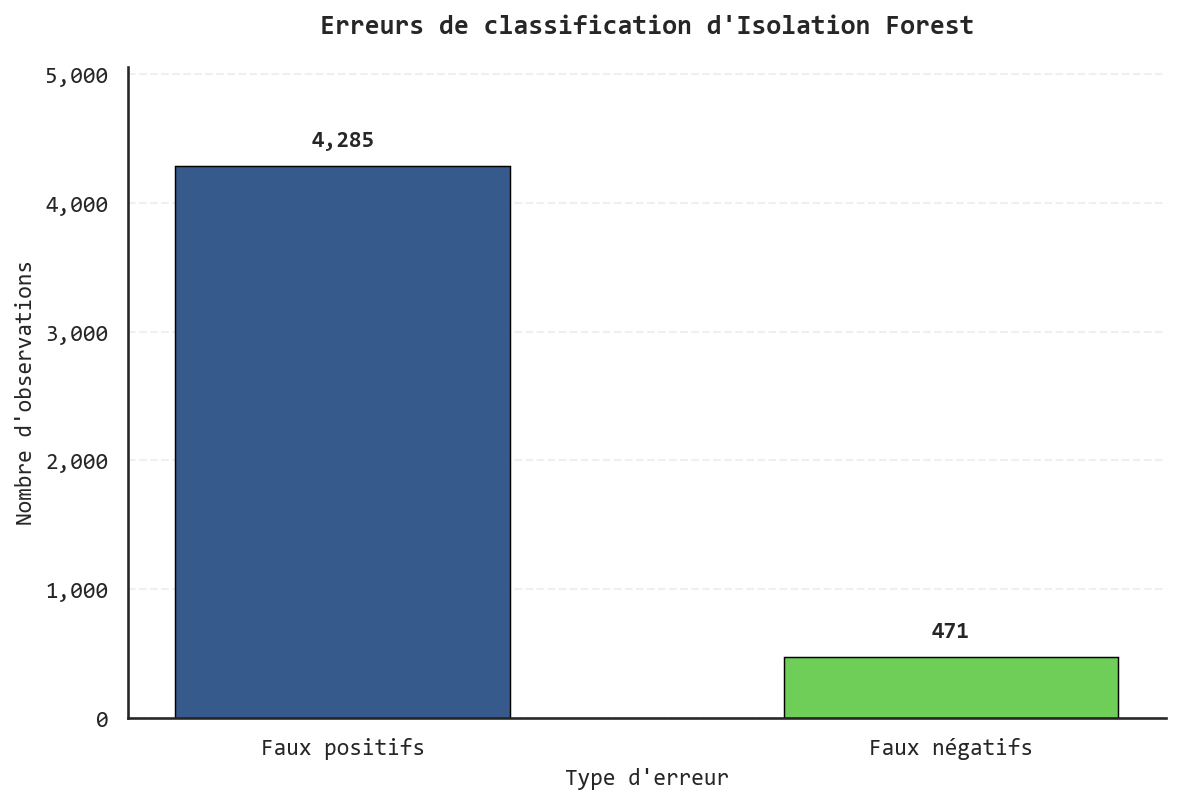

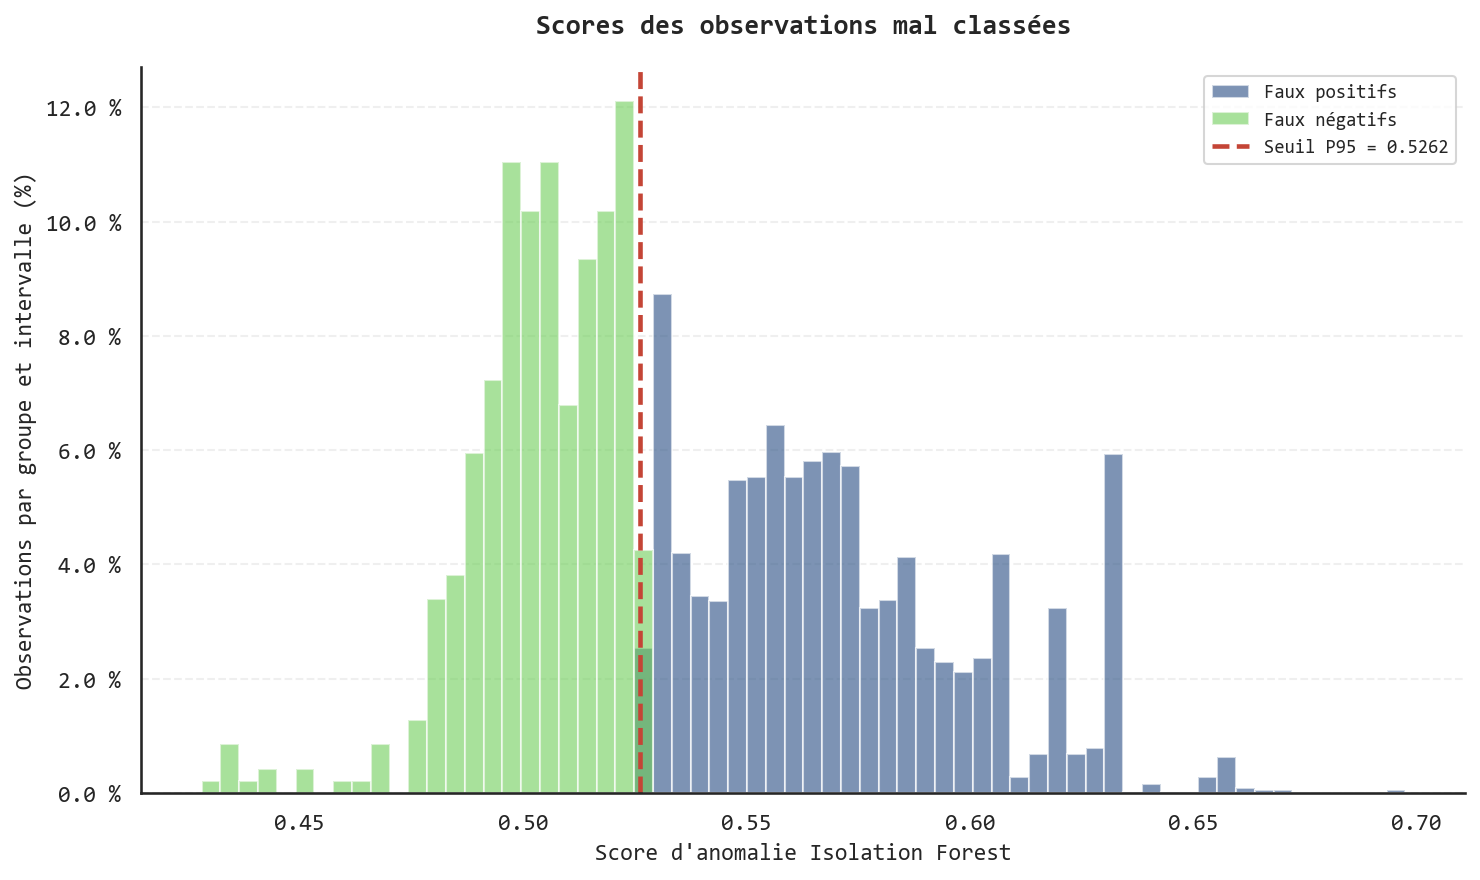

In [97]:

# ============================================================
# CELLULE 24 — ANALYSE DES ERREURS ISOLATION FOREST
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# - Identifier TN, FP, FN et TP
# - Analyser les erreurs de classification
# - Etudier leurs scores par rapport au seuil P95
# - Produire deux visualisations scientifiques
# - Exporter les resultats et les rapports
#
# Aucun fit()
# Aucun recalibrage
# Aucune modification du modele
# ============================================================

import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mticker

from sklearn.metrics import confusion_matrix

print("=" * 75)
print("CELLULE 24 — ANALYSE DES ERREURS ISOLATION FOREST")
print("=" * 75)

IF_ERRORS_READY = False

# ------------------------------------------------------------
# 1. LOCALISATION DU PROJET AUTONOME
# ------------------------------------------------------------

IF_BASE_DIR = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest"
)

IF_ERR_RESULTS_DIR = (
    IF_BASE_DIR / "resultats_Isolation_Forest"
)

IF_ERR_SCORES_DIR = (
    IF_ERR_RESULTS_DIR / "scores"
)

IF_ERR_ARTIFACTS_DIR = (
    IF_ERR_RESULTS_DIR / "artefacts"
)

IF_ERR_MATRICES_DIR = (
    IF_ERR_ARTIFACTS_DIR / "matrices_isolation_forest"
)

IF_ERR_FIGURES_DIR = (
    IF_ERR_RESULTS_DIR / "figures"
)

IF_ERR_TABLES_DIR = (
    IF_ERR_RESULTS_DIR / "tableaux"
)

for directory in [
    IF_ERR_FIGURES_DIR,
    IF_ERR_TABLES_DIR,
    IF_ERR_ARTIFACTS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 2. LOCALISATION DES ARTEFACTS
# ------------------------------------------------------------

IF_ERR_SCORES_PATH = (
    IF_ERR_SCORES_DIR /
    "scores_test_Isolation_Forest.npy"
)

IF_ERR_LABELS_PATH = (
    IF_ERR_MATRICES_DIR /
    "y_test.npy"
)

IF_ERR_IDS_PATH = (
    IF_ERR_MATRICES_DIR /
    "ids_test.npy"
)

IF_ERR_THRESHOLD_PATH = (
    IF_ERR_ARTIFACTS_DIR /
    "seuil_Isolation_Forest_95e_percentile.json"
)

IF_ERR_VAL_SCORES_PATH = (
    IF_ERR_SCORES_DIR /
    "scores_validation_normale_IF.npy"
)

IF_ERR_METRICS_PATH = (
    IF_ERR_ARTIFACTS_DIR /
    "rapport_metriques_globales_IF.json"
)

IF_ERR_REQUIRED_FILES = {
    "Scores du test": IF_ERR_SCORES_PATH,
    "Etiquettes du test": IF_ERR_LABELS_PATH,
    "Identifiants du test": IF_ERR_IDS_PATH,
    "Seuil P95": IF_ERR_THRESHOLD_PATH,
    "Scores de validation": IF_ERR_VAL_SCORES_PATH
}

for description, path in IF_ERR_REQUIRED_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"{description} introuvable : {path}"
        )

print("\nArtefacts necessaires : PRESENTS")

# ------------------------------------------------------------
# 3. CHARGEMENT DES DONNEES DU TEST
# ------------------------------------------------------------

IF_err_scores = np.asarray(
    np.load(
        IF_ERR_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

IF_err_labels = np.asarray(
    np.load(
        IF_ERR_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=np.int8
)

IF_err_ids = np.asarray(
    np.load(
        IF_ERR_IDS_PATH,
        allow_pickle=False
    ),
    dtype=np.int64
)

# ------------------------------------------------------------
# 4. VERIFICATION DES DIMENSIONS
# ------------------------------------------------------------

IF_ERR_N = len(IF_err_scores)

if IF_ERR_N == 0:
    raise ValueError(
        "L'ensemble de test est vide."
    )

if not all(
    array.ndim == 1
    for array in [
        IF_err_scores,
        IF_err_labels,
        IF_err_ids
    ]
):
    raise ValueError(
        "Les tableaux doivent etre unidimensionnels."
    )

if not (
    len(IF_err_scores)
    == len(IF_err_labels)
    == len(IF_err_ids)
):
    raise ValueError(
        "Scores, etiquettes et identifiants mal alignes."
    )

if not np.isfinite(IF_err_scores).all():
    raise ValueError(
        "Les scores du test contiennent NaN ou inf."
    )

if set(np.unique(IF_err_labels)) != {0, 1}:
    raise ValueError(
        "Le test doit contenir les classes 0 et 1."
    )

if len(np.unique(IF_err_ids)) != IF_ERR_N:
    raise ValueError(
        "Des identifiants du test sont dupliques."
    )

# Controle d'alignement lorsque les donnees
# originales sont disponibles en memoire.

if "IF_y" in globals():

    IF_expected_labels = (
        IF_y.iloc[IF_err_ids]
        .to_numpy(dtype=np.int8)
    )

    if not np.array_equal(
        IF_expected_labels,
        IF_err_labels
    ):
        raise RuntimeError(
            "Etiquettes du test mal alignees."
        )

if "IF_ids_test" in globals():

    if not np.array_equal(
        IF_err_ids,
        np.asarray(IF_ids_test, dtype=np.int64)
    ):
        raise RuntimeError(
            "Les indices du test ont change."
        )

print("Alignement des donnees : VALIDE")

# ------------------------------------------------------------
# 5. CHARGEMENT DU SEUIL OFFICIEL
# ------------------------------------------------------------

with open(
    IF_ERR_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    IF_err_threshold_report = json.load(file)

IF_ERR_THRESHOLD = float(
    IF_err_threshold_report["seuil"]
)

if not np.isfinite(IF_ERR_THRESHOLD):
    raise ValueError(
        "Seuil non fini."
    )

if IF_err_threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "Population de calibration incorrecte."
    )

if IF_err_threshold_report.get("percentile") != 95:
    raise RuntimeError(
        "Le seuil doit correspondre au P95."
    )

if IF_err_threshold_report.get(
    "operateur_decision"
) != ">":
    raise RuntimeError(
        "La regle de decision doit etre score > seuil."
    )

if IF_err_threshold_report.get(
    "orientation"
) != "higher_is_more_anomalous":
    raise RuntimeError(
        "Orientation des scores incompatible."
    )

# ------------------------------------------------------------
# 6. VERIFICATION DIRECTE DE LA CALIBRATION
# ------------------------------------------------------------

IF_err_val_scores = np.asarray(
    np.load(
        IF_ERR_VAL_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

if (
    IF_err_val_scores.ndim != 1
    or IF_err_val_scores.size == 0
    or not np.isfinite(IF_err_val_scores).all()
):
    raise ValueError(
        "Scores de validation invalides."
    )

IF_ERR_EXPECTED_THRESHOLD = float(
    np.percentile(
        IF_err_val_scores,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_ERR_THRESHOLD,
    IF_ERR_EXPECTED_THRESHOLD,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond pas au P95 "
        "des scores normaux de validation."
    )

print("\nCalibration P95 : VALIDEE")

# ------------------------------------------------------------
# 7. RECONSTRUCTION DES PREDICTIONS
# ------------------------------------------------------------

# Les predictions sont calculees exclusivement
# avec les scores et le seuil deja fixe.

IF_err_predictions = (
    IF_err_scores > IF_ERR_THRESHOLD
).astype(np.int8)

# Verification contre les predictions
# sauvegardees, si elles existent.

IF_ERR_PREDICTIONS_PATH = (
    IF_ERR_SCORES_DIR /
    "predictions_test_Isolation_Forest.npy"
)

if IF_ERR_PREDICTIONS_PATH.is_file():

    IF_saved_err_predictions = np.load(
        IF_ERR_PREDICTIONS_PATH,
        allow_pickle=False
    )

    if not np.array_equal(
        IF_saved_err_predictions,
        IF_err_predictions
    ):
        raise RuntimeError(
            "Les predictions sauvegardees different "
            "de la regle de decision."
        )

# ------------------------------------------------------------
# 8. CALCUL DE LA MATRICE DE CONFUSION
# ------------------------------------------------------------

IF_ERR_CM = confusion_matrix(
    IF_err_labels,
    IF_err_predictions,
    labels=[0, 1]
)

IF_ERR_TN, IF_ERR_FP, IF_ERR_FN, IF_ERR_TP = [
    int(value)
    for value in IF_ERR_CM.ravel()
]

if (
    IF_ERR_TN
    + IF_ERR_FP
    + IF_ERR_FN
    + IF_ERR_TP
) != IF_ERR_N:
    raise RuntimeError(
        "Matrice de confusion incoherente."
    )

print("\nMATRICE DE CONFUSION")

print("TN :", f"{IF_ERR_TN:,}")
print("FP :", f"{IF_ERR_FP:,}")
print("FN :", f"{IF_ERR_FN:,}")
print("TP :", f"{IF_ERR_TP:,}")

# ------------------------------------------------------------
# 9. CONTROLE DES EFFECTIFS PRECEDENTS
# ------------------------------------------------------------

if IF_ERR_METRICS_PATH.is_file():

    with open(
        IF_ERR_METRICS_PATH,
        "r",
        encoding="utf-8"
    ) as file:
        IF_err_metrics_report = json.load(file)

    IF_previous_cm = IF_err_metrics_report.get(
        "matrice_confusion"
    )

    if isinstance(IF_previous_cm, dict):

        IF_expected_cm = {
            "TN": IF_ERR_TN,
            "FP": IF_ERR_FP,
            "FN": IF_ERR_FN,
            "TP": IF_ERR_TP
        }

        if IF_previous_cm != IF_expected_cm:
            raise RuntimeError(
                "La matrice de confusion differe "
                "des metriques precedentes."
            )

# ------------------------------------------------------------
# 10. IDENTIFICATION DES CATEGORIES D'ERREURS
# ------------------------------------------------------------

IF_mask_tn = (
    (IF_err_labels == 0)
    & (IF_err_predictions == 0)
)

IF_mask_fp = (
    (IF_err_labels == 0)
    & (IF_err_predictions == 1)
)

IF_mask_fn = (
    (IF_err_labels == 1)
    & (IF_err_predictions == 0)
)

IF_mask_tp = (
    (IF_err_labels == 1)
    & (IF_err_predictions == 1)
)

IF_err_categories = np.select(
    [
        IF_mask_tn,
        IF_mask_fp,
        IF_mask_fn,
        IF_mask_tp
    ],
    [
        "Vrai négatif",
        "Faux positif",
        "Faux négatif",
        "Vrai positif"
    ],
    default="Inconnu"
)

if np.any(IF_err_categories == "Inconnu"):
    raise RuntimeError(
        "Certaines observations n'ont pas ete classees."
    )

# ------------------------------------------------------------
# 11. TAUX D'ERREURS
# ------------------------------------------------------------

IF_ERR_N_NORMAL = int(
    np.sum(IF_err_labels == 0)
)

IF_ERR_N_ATTACK = int(
    np.sum(IF_err_labels == 1)
)

IF_ERR_FPR = float(
    IF_ERR_FP / IF_ERR_N_NORMAL
)

IF_ERR_FNR = float(
    IF_ERR_FN / IF_ERR_N_ATTACK
)

IF_ERR_TOTAL = (
    IF_ERR_FP + IF_ERR_FN
)

IF_ERR_GLOBAL_RATE = float(
    IF_ERR_TOTAL / IF_ERR_N
)

print("\nINDICATEURS D'ERREUR")

print(
    "Taux de faux positifs :",
    f"{100 * IF_ERR_FPR:.4f} %"
)

print(
    "Taux de faux negatifs :",
    f"{100 * IF_ERR_FNR:.4f} %"
)

print(
    "Taux global d'erreurs :",
    f"{100 * IF_ERR_GLOBAL_RATE:.4f} %"
)

# ------------------------------------------------------------
# 12. SCORES DES FAUX POSITIFS ET FAUX NEGATIFS
# ------------------------------------------------------------

IF_err_scores_fp = (
    IF_err_scores[IF_mask_fp]
)

IF_err_scores_fn = (
    IF_err_scores[IF_mask_fn]
)

# Ecart signe au seuil :
# > 0 : score au-dessus du seuil
# <= 0 : score sous le seuil ou egal.

IF_err_score_margin = (
    IF_err_scores - IF_ERR_THRESHOLD
)

# ------------------------------------------------------------
# 13. TABLEAU INDIVIDUEL DES RESULTATS
# ------------------------------------------------------------

IF_ERR_ALL_TABLE = pd.DataFrame({
    "ID_observation": IF_err_ids,
    "Classe_reelle": IF_err_labels,
    "Classe_predite": IF_err_predictions,
    "Score_anomalie_IF": IF_err_scores,
    "Seuil_P95": IF_ERR_THRESHOLD,
    "Ecart_au_seuil": IF_err_score_margin,
    "Categorie_resultat": IF_err_categories
})

# Sous-ensemble contenant exclusivement
# les erreurs de classification.

IF_ERR_MISCLASSIFIED_TABLE = (
    IF_ERR_ALL_TABLE.loc[
        IF_mask_fp | IF_mask_fn
    ].copy()
)

print("\nAPERÇU DES OBSERVATIONS MAL CLASSEES")

display(
    IF_ERR_MISCLASSIFIED_TABLE.head(10)
)

# ------------------------------------------------------------
# 14. STATISTIQUES DES SCORES D'ERREURS
# ------------------------------------------------------------

def IF_error_statistics(scores, name):

    if len(scores) == 0:

        return {
            "Categorie": name,
            "Effectif": 0,
            "Score_minimum": None,
            "Score_moyen": None,
            "Score_median": None,
            "Score_maximum": None,
            "Ecart_moyen_au_seuil": None
        }

    return {
        "Categorie": name,
        "Effectif": int(len(scores)),
        "Score_minimum": float(np.min(scores)),
        "Score_moyen": float(np.mean(scores)),
        "Score_median": float(np.median(scores)),
        "Score_maximum": float(np.max(scores)),
        "Ecart_moyen_au_seuil": float(
            np.mean(scores - IF_ERR_THRESHOLD)
        )
    }


IF_ERR_STATISTICS = pd.DataFrame([
    IF_error_statistics(
        IF_err_scores_fp,
        "Faux positifs"
    ),
    IF_error_statistics(
        IF_err_scores_fn,
        "Faux négatifs"
    )
])

print("\nSTATISTIQUES DES ERREURS")

display(IF_ERR_STATISTICS)

# ------------------------------------------------------------
# 15. TABLEAU RECAPITULATIF DES ERREURS
# ------------------------------------------------------------

IF_ERR_SUMMARY = pd.DataFrame({
    "Indicateur": [
        "Faux positifs",
        "Faux négatifs",
        "Total des erreurs",
        "Taux de faux positifs (%)",
        "Taux de faux négatifs (%)",
        "Taux global d'erreurs (%)"
    ],
    "Valeur": [
        IF_ERR_FP,
        IF_ERR_FN,
        IF_ERR_TOTAL,
        100 * IF_ERR_FPR,
        100 * IF_ERR_FNR,
        100 * IF_ERR_GLOBAL_RATE
    ]
})

display(IF_ERR_SUMMARY)

# ------------------------------------------------------------
# 16. CONFIGURATION DE LA POLICE
# ------------------------------------------------------------

IF_err_available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

IF_ERR_FONT = (
    "Consolas"
    if "Consolas" in IF_err_available_fonts
    else "DejaVu Sans Mono"
)

plt.rcParams.update({
    "font.family": IF_ERR_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

IF_ERR_COLOR_FP = plt.cm.viridis(0.28)
IF_ERR_COLOR_FN = plt.cm.viridis(0.78)
IF_ERR_COLOR_THRESHOLD = "#C44536"

# ------------------------------------------------------------
# 17. FIGURE 1 — EFFECTIFS DES ERREURS
# ------------------------------------------------------------

fig1, ax1 = plt.subplots(
    figsize=(8, 5.5),
    dpi=150
)

IF_ERR_COUNTS = [
    IF_ERR_FP,
    IF_ERR_FN
]

IF_ERR_LABELS = [
    "Faux positifs",
    "Faux négatifs"
]

bars = ax1.bar(
    IF_ERR_LABELS,
    IF_ERR_COUNTS,
    color=[
        IF_ERR_COLOR_FP,
        IF_ERR_COLOR_FN
    ],
    width=0.55,
    edgecolor="black",
    linewidth=0.7
)

for bar, value in zip(
    bars,
    IF_ERR_COUNTS
):

    ax1.annotate(
        f"{value:,}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax1.set_title(
    "Erreurs de classification d'Isolation Forest",
    pad=16
)

ax1.set_xlabel(
    "Type d'erreur"
)

ax1.set_ylabel(
    "Nombre d'observations"
)

ax1.set_ylim(
    0,
    max(1, max(IF_ERR_COUNTS)) * 1.18
)

ax1.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("{x:,.0f}")
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax1.set_axisbelow(True)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

fig1.tight_layout()

# ------------------------------------------------------------
# 18. FIGURE 2 — SCORES DES ERREURS ET SEUIL
# ------------------------------------------------------------

fig2, ax2 = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

# Le graphique montre les scores des
# observations mal classees.
#
# Les distributions sont normalisees par
# effectif propre a chaque groupe.
#
# Si un groupe est vide, il n'est pas trace.

IF_ERR_AVAILABLE_GROUPS = []

if IF_ERR_FP > 0:

    IF_ERR_AVAILABLE_GROUPS.append(
        IF_err_scores_fp
    )

if IF_ERR_FN > 0:

    IF_ERR_AVAILABLE_GROUPS.append(
        IF_err_scores_fn
    )

if IF_ERR_AVAILABLE_GROUPS:

    combined = np.concatenate(
        IF_ERR_AVAILABLE_GROUPS
    )

    left = float(np.min(combined))
    right = float(np.max(combined))

    if left == right:
        margin = max(abs(left) * 0.01, 0.001)
        left -= margin
        right += margin

    IF_ERR_BINS = np.linspace(
        left,
        right,
        65
    )

    if IF_ERR_FP > 0:

        ax2.hist(
            IF_err_scores_fp,
            bins=IF_ERR_BINS,
            weights=np.full(
                IF_ERR_FP,
                100.0 / IF_ERR_FP
            ),
            color=IF_ERR_COLOR_FP,
            alpha=0.65,
            label="Faux positifs"
        )

    if IF_ERR_FN > 0:

        ax2.hist(
            IF_err_scores_fn,
            bins=IF_ERR_BINS,
            weights=np.full(
                IF_ERR_FN,
                100.0 / IF_ERR_FN
            ),
            color=IF_ERR_COLOR_FN,
            alpha=0.60,
            label="Faux négatifs"
        )

else:

    ax2.text(
        0.5,
        0.5,
        "Aucune erreur de classification",
        ha="center",
        va="center",
        transform=ax2.transAxes,
        fontsize=12
    )

ax2.axvline(
    IF_ERR_THRESHOLD,
    color=IF_ERR_COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label=(
        "Seuil P95 = "
        f"{IF_ERR_THRESHOLD:.4f}"
    )
)

ax2.set_title(
    "Scores des observations mal classées",
    pad=16
)

ax2.set_xlabel(
    "Score d'anomalie Isolation Forest"
)

ax2.set_ylabel(
    "Observations par groupe et intervalle (%)"
)

ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda value, position: f"{value:.1f} %"
    )
)

ax2.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax2.set_axisbelow(True)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

ax2.legend(
    loc="upper right",
    fontsize=9
)

fig2.tight_layout()

# ------------------------------------------------------------
# 19. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

IF_ERR_FIGURE_1_NAME = (
    "effectifs_erreurs_Isolation_Forest"
)

IF_ERR_FIGURE_2_NAME = (
    "distribution_scores_erreurs_IF"
)

IF_ERR_FIGURE_PATHS = {}

for key, figure, filename in [
    (
        "effectifs",
        fig1,
        IF_ERR_FIGURE_1_NAME
    ),
    (
        "scores",
        fig2,
        IF_ERR_FIGURE_2_NAME
    )
]:

    IF_ERR_FIGURE_PATHS[key] = {}

    for fmt in ["png", "pdf", "svg"]:

        path = (
            IF_ERR_FIGURES_DIR /
            f"{filename}.{fmt}"
        )

        figure.savefig(
            path,
            format=fmt,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        IF_ERR_FIGURE_PATHS[key][fmt] = str(path)

plt.show()

# ------------------------------------------------------------
# 20. EXPORT DES TABLEAUX
# ------------------------------------------------------------

IF_ERR_ALL_TABLE_PATH = (
    IF_ERR_TABLES_DIR /
    "resultats_individuels_test_IF.csv"
)

IF_ERR_MISCLASSIFIED_PATH = (
    IF_ERR_TABLES_DIR /
    "observations_mal_classees_IF.csv"
)

IF_ERR_STATISTICS_PATH = (
    IF_ERR_TABLES_DIR /
    "statistiques_erreurs_IF.csv"
)

IF_ERR_SUMMARY_PATH = (
    IF_ERR_TABLES_DIR /
    "synthese_erreurs_IF.csv"
)

IF_ERR_ALL_TABLE.to_csv(
    IF_ERR_ALL_TABLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_ERR_MISCLASSIFIED_TABLE.to_csv(
    IF_ERR_MISCLASSIFIED_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_ERR_STATISTICS.to_csv(
    IF_ERR_STATISTICS_PATH,
    index=False,
    encoding="utf-8-sig"
)

IF_ERR_SUMMARY.to_csv(
    IF_ERR_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 21. RAPPORT JSON
# ------------------------------------------------------------

IF_ERR_REPORT = {
    "dataset": "UNSW-NB15",
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "test_independant_IF",
    "partitionnement": "autonome_par_groupes",
    "observations": IF_ERR_N,
    "normaux": IF_ERR_N_NORMAL,
    "attaques": IF_ERR_N_ATTACK,
    "TN": IF_ERR_TN,
    "FP": IF_ERR_FP,
    "FN": IF_ERR_FN,
    "TP": IF_ERR_TP,
    "nombre_erreurs": IF_ERR_TOTAL,
    "FPR": IF_ERR_FPR,
    "FNR": IF_ERR_FNR,
    "taux_global_erreur": IF_ERR_GLOBAL_RATE,
    "seuil": IF_ERR_THRESHOLD,
    "calibration": "P95_validation_normale",
    "operateur_decision": ">",
    "score": "-score_samples",
    "modele_reentraine": False,
    "seuil_recalibre": False,
    "test_utilise_pour_optimisation": False,
    "figures": IF_ERR_FIGURE_PATHS,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_ERR_REPORT_PATH = (
    IF_ERR_ARTIFACTS_DIR /
    "rapport_analyse_erreurs_IF.json"
)

with open(
    IF_ERR_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_ERR_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )


CELLULE 25 — PERFORMANCES PAR CATEGORIE D'ATTAQUE

Alignement des donnees : VALIDE

CONTROLE DES CATEGORIES
Attaques sans categorie exploitable : 0

Calibration P95 : VALIDEE

PERFORMANCES PAR CATEGORIE D'ATTAQUE


,Categorie_attaque,Nombre_attaques,Attaques_detectees,Score_moyen,Score_median,Attaques_manquees,Taux_detection_pct,Taux_faux_negatifs_pct
0,Generic,1211,1194,0.614839,0.618821,17,98.60 %,1.40 %
1,Backdoors,76,72,0.601476,0.608933,4,94.74 %,5.26 %
2,Analysis,72,68,0.601880,0.610064,4,94.44 %,5.56 %
3,DoS,172,139,0.570632,0.583306,33,80.81 %,19.19 %
4,Fuzzers,735,585,0.567793,0.572022,150,79.59 %,20.41 %
5,Reconnaissance,279,219,0.550373,0.562460,60,78.49 %,21.51 %
6,Exploits,772,582,0.554079,0.549931,190,75.39 %,24.61 %
7,Shellcode,44,32,0.557495,0.577260,12,72.73 %,27.27 %
8,Worms,3,2,0.532351,0.539342,1,66.67 %,33.33 %



VERIFICATION DES EFFECTIFS : VALIDEE
Attaques dans le test : 3,364
Attaques detectees : 2,893
Attaques manquees : 471


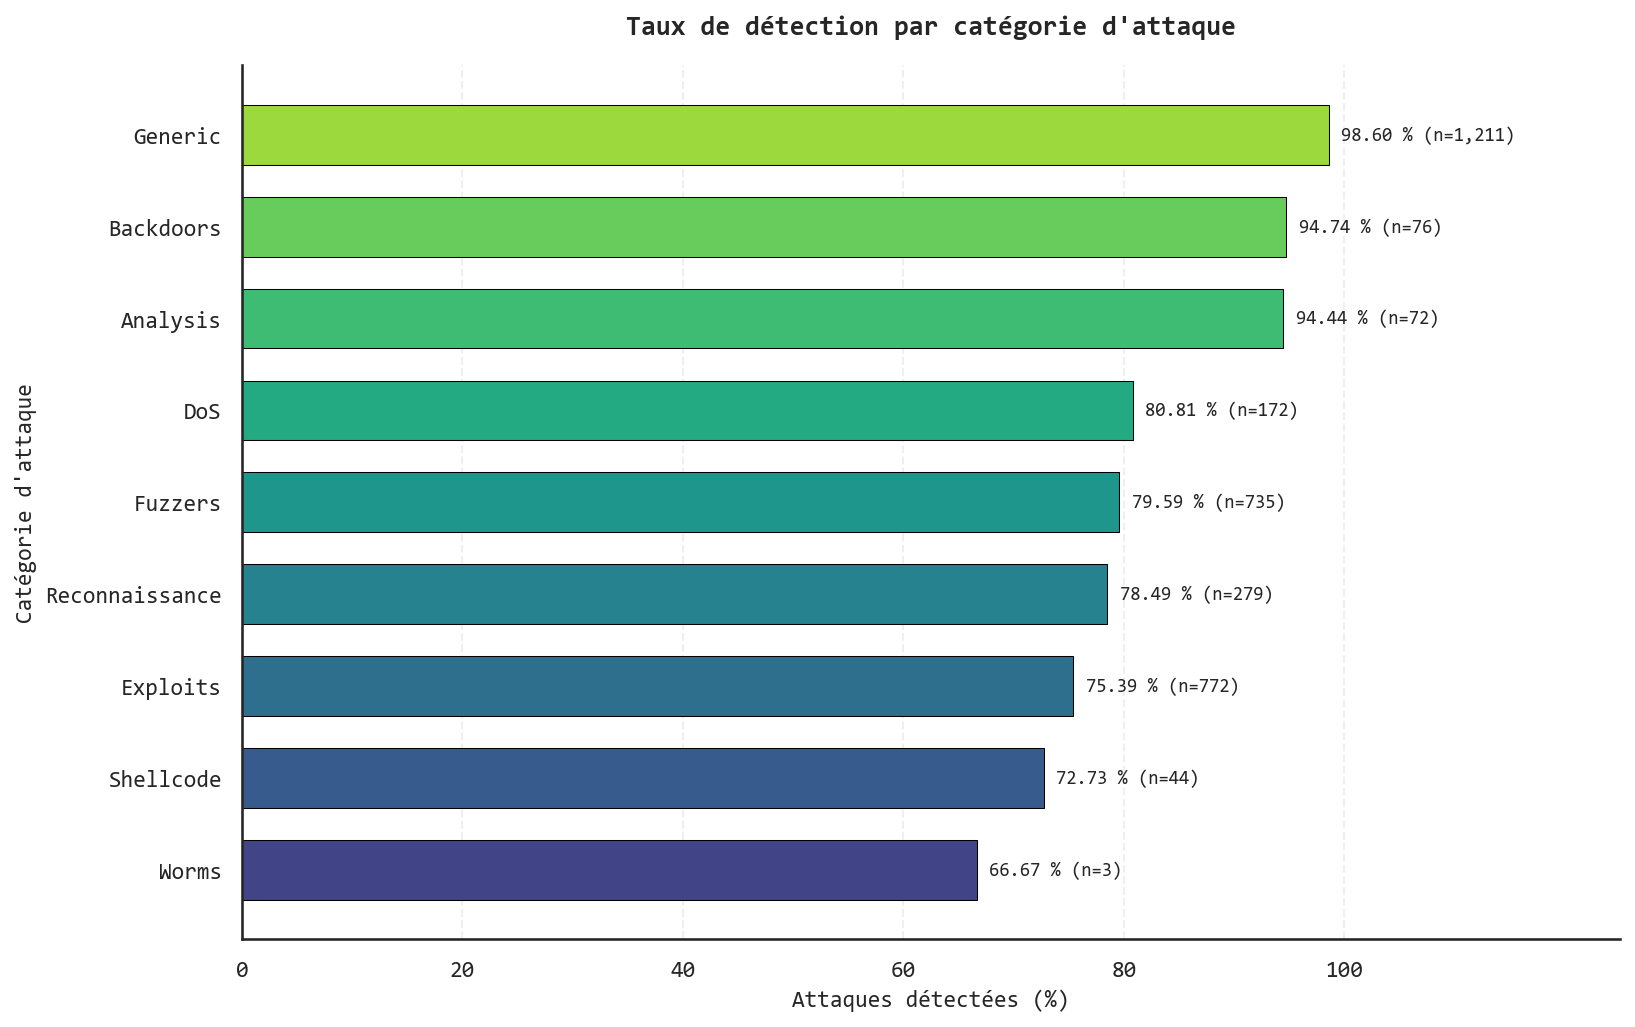

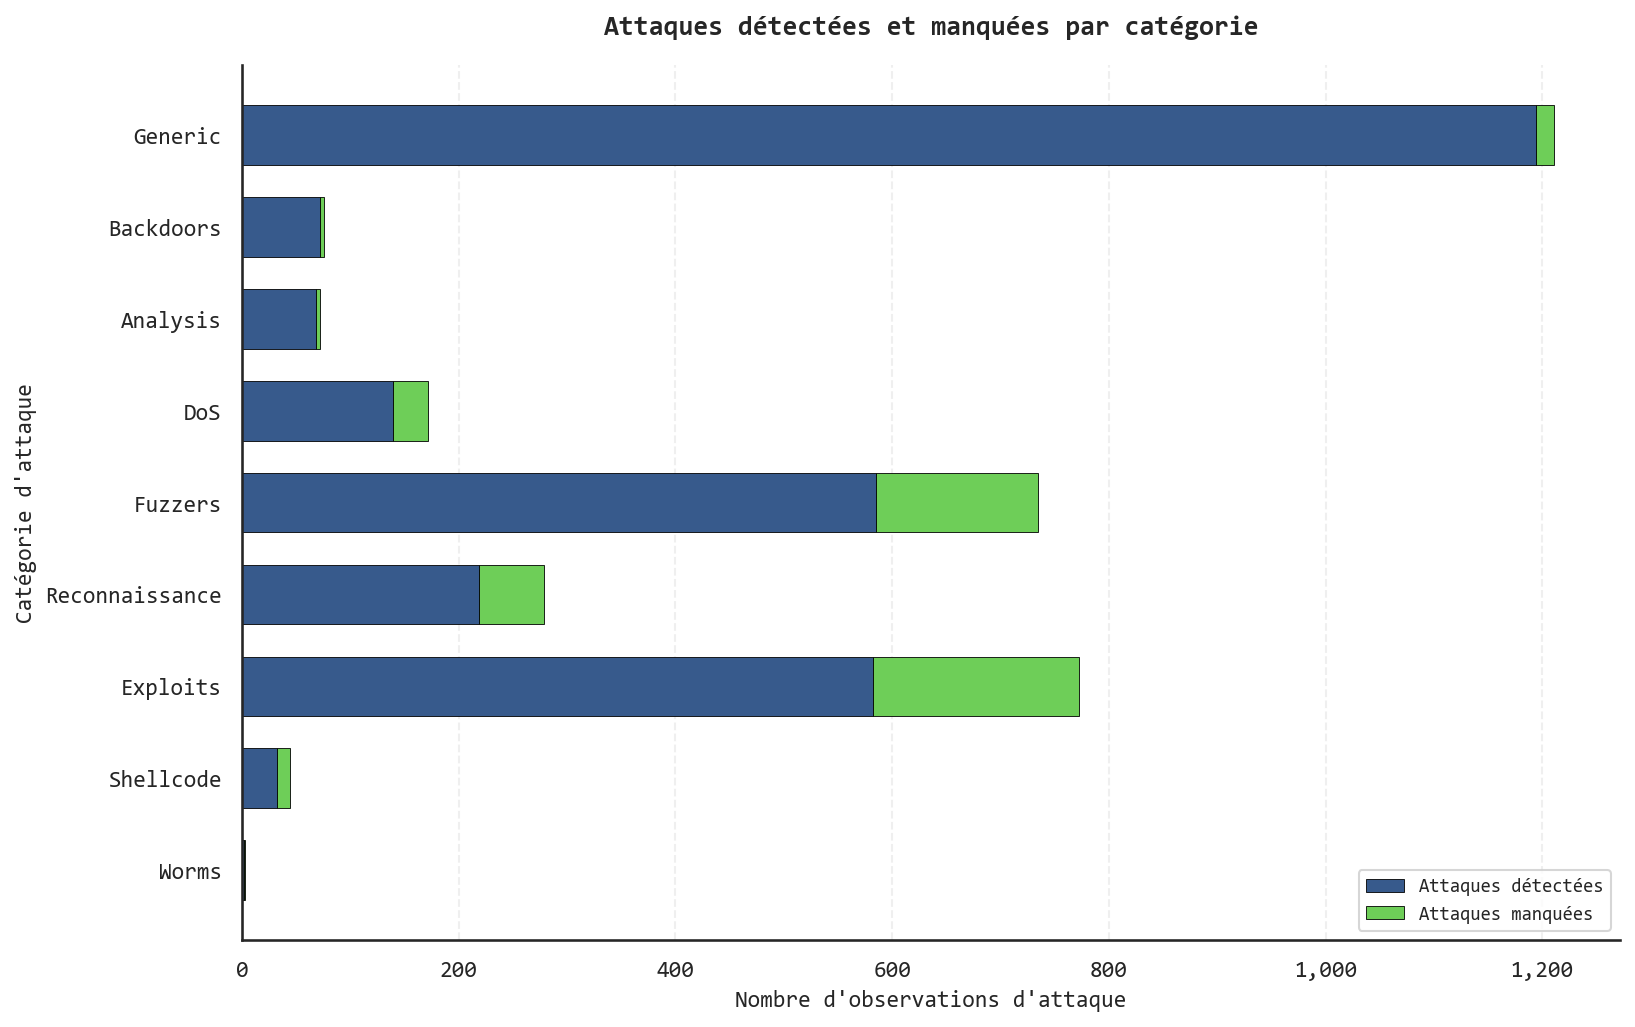


ANALYSE PAR CATEGORIE D'ATTAQUE TERMINEE
Attaques analysees : 3,364
Attaques detectees : 2,893
Attaques manquees : 471
Categories presentes : 9

Tableau principal :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\tableaux\performances_par_categorie_attaque_IF.csv

Figures :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\figures

Rapport :
C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\artefacts\rapport_performances_categories_IF.json

Modele modifie : NON
Seuil modifie : NON
Nouveau fit : NON
CELLULE 25 EXECUTEE AVEC SUCCES


In [98]:

# ============================================================
# CELLULE 25 — PERFORMANCES PAR CATEGORIE D'ATTAQUE
# ============================================================
# Modele : Isolation Forest
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Analyser la detection des differentes familles
# d'attaques presentes dans le test independant.
#
# attack_cat : analyse descriptive uniquement
# label      : evaluation uniquement
#
# Aucun entrainement.
# Aucun recalibrage.
# Aucune optimisation sur le test.
# ============================================================

import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mticker

from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("CELLULE 25 — PERFORMANCES PAR CATEGORIE D'ATTAQUE")
print("=" * 75)

IF_CATEGORY_PERFORMANCE_READY = False

# ------------------------------------------------------------
# 1. REPERTOIRES DU PROJET AUTONOME
# ------------------------------------------------------------

IF_CAT_PROJECT_DIR = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest"
)

IF_CAT_RESULTS_DIR = (
    IF_CAT_PROJECT_DIR / "resultats_Isolation_Forest"
)

IF_CAT_ARTIFACTS_DIR = (
    IF_CAT_RESULTS_DIR / "artefacts"
)

IF_CAT_MATRICES_DIR = (
    IF_CAT_ARTIFACTS_DIR / "matrices_isolation_forest"
)

IF_CAT_SCORES_DIR = (
    IF_CAT_RESULTS_DIR / "scores"
)

IF_CAT_FIGURES_DIR = (
    IF_CAT_RESULTS_DIR / "figures"
)

IF_CAT_TABLES_DIR = (
    IF_CAT_RESULTS_DIR / "tableaux"
)

for folder in [
    IF_CAT_FIGURES_DIR,
    IF_CAT_TABLES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. VERIFICATION DES FICHIERS NECESSAIRES
# ------------------------------------------------------------

IF_CAT_SCORES_PATH = (
    IF_CAT_SCORES_DIR /
    "scores_test_Isolation_Forest.npy"
)

IF_CAT_LABELS_PATH = (
    IF_CAT_MATRICES_DIR /
    "y_test.npy"
)

IF_CAT_IDS_PATH = (
    IF_CAT_MATRICES_DIR /
    "ids_test.npy"
)

IF_CAT_THRESHOLD_PATH = (
    IF_CAT_ARTIFACTS_DIR /
    "seuil_Isolation_Forest_95e_percentile.json"
)

IF_CAT_VALIDATION_PATH = (
    IF_CAT_SCORES_DIR /
    "scores_validation_normale_IF.npy"
)

IF_CAT_REQUIRED_FILES = {
    "Scores du test": IF_CAT_SCORES_PATH,
    "Etiquettes du test": IF_CAT_LABELS_PATH,
    "Indices du test": IF_CAT_IDS_PATH,
    "Seuil de calibration": IF_CAT_THRESHOLD_PATH,
    "Scores de validation": IF_CAT_VALIDATION_PATH
}

for description, path in IF_CAT_REQUIRED_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"{description} introuvable : {path}"
        )

# ------------------------------------------------------------
# 3. VERIFICATION DES METADONNEES D'ATTAQUE
# ------------------------------------------------------------

# La cellule 7 a conserve attack_cat dans
# IF_attack_metadata et IF_df.
#
# Aucune categorie n'est inventee.
# L'ordre des observations doit etre conserve.

if "IF_attack_metadata" in globals():

    IF_CAT_METADATA = IF_attack_metadata

elif "IF_df" in globals():

    if "attack_cat" not in IF_df.columns:
        raise ValueError(
            "Colonne attack_cat absente du dataset."
        )

    IF_CAT_METADATA = IF_df["attack_cat"]

else:

    raise RuntimeError(
        "Les categories d'attaques sont absentes "
        "de la memoire. Executer les cellules "
        "de chargement et preparation du dataset "
        "avant la cellule 25."
    )

# ------------------------------------------------------------
# 4. CHARGEMENT DES DONNEES DU TEST
# ------------------------------------------------------------

IF_cat_scores = np.asarray(
    np.load(
        IF_CAT_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

IF_cat_labels = np.asarray(
    np.load(
        IF_CAT_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=np.int8
)

IF_cat_ids = np.asarray(
    np.load(
        IF_CAT_IDS_PATH,
        allow_pickle=False
    ),
    dtype=np.int64
)

# ------------------------------------------------------------
# 5. VERIFICATION DES DIMENSIONS
# ------------------------------------------------------------

IF_CAT_N = len(IF_cat_scores)

if IF_CAT_N == 0:
    raise ValueError(
        "L'ensemble de test est vide."
    )

if not all(
    array.ndim == 1
    for array in [
        IF_cat_scores,
        IF_cat_labels,
        IF_cat_ids
    ]
):
    raise ValueError(
        "Scores, etiquettes et indices "
        "doivent etre unidimensionnels."
    )

if not (
    len(IF_cat_scores)
    == len(IF_cat_labels)
    == len(IF_cat_ids)
):
    raise ValueError(
        "Dimensions incompatibles."
    )

if not np.isfinite(IF_cat_scores).all():
    raise ValueError(
        "Scores non finis detectes."
    )

if set(np.unique(IF_cat_labels)) != {0, 1}:
    raise ValueError(
        "Le test doit contenir les classes 0 et 1."
    )

if len(np.unique(IF_cat_ids)) != IF_CAT_N:
    raise ValueError(
        "Des indices du test sont dupliques."
    )

if np.any(IF_cat_ids < 0):
    raise ValueError(
        "Indices de test negatifs."
    )

if np.any(IF_cat_ids >= len(IF_CAT_METADATA)):
    raise ValueError(
        "Indices incompatibles avec attack_cat."
    )

# ------------------------------------------------------------
# 6. VERIFICATION DE L'ALIGNEMENT
# ------------------------------------------------------------

if "IF_y" in globals():

    IF_cat_expected_labels = (
        IF_y.iloc[IF_cat_ids]
        .to_numpy(dtype=np.int8)
    )

    if not np.array_equal(
        IF_cat_labels,
        IF_cat_expected_labels
    ):
        raise RuntimeError(
            "Etiquettes du test non alignees."
        )

if "IF_ids_test" in globals():

    if not np.array_equal(
        IF_cat_ids,
        np.asarray(IF_ids_test, dtype=np.int64)
    ):
        raise RuntimeError(
            "Ordre des observations du test modifie."
        )

print("\nAlignement des donnees : VALIDE")

# ------------------------------------------------------------
# 7. CHARGEMENT DES CATEGORIES DU TEST
# ------------------------------------------------------------

# iloc utilise les positions d'origine
# sauvegardees a la cellule 8.

IF_cat_raw_categories = (
    IF_CAT_METADATA.iloc[IF_cat_ids]
    .astype("string")
    .str.strip()
)

# Normalisation descriptive uniquement.

IF_cat_missing_values = {
    "",
    "nan",
    "none",
    "null",
    "na",
    "n/a"
}

IF_cat_missing_mask = (
    IF_cat_raw_categories.isna()
    |
    IF_cat_raw_categories
    .str.lower()
    .isin(IF_cat_missing_values)
    .fillna(False)
)

IF_cat_categories = (
    IF_cat_raw_categories
    .mask(
        IF_cat_missing_mask,
        "Non renseignée"
    )
    .fillna("Non renseignée")
    .astype(str)
    .to_numpy()
)

# ------------------------------------------------------------
# 8. VERIFICATION DE LA COHERENCE DES CATEGORIES
# ------------------------------------------------------------

# Les categories sont utilisees uniquement
# pour interpreter les attaques.
#
# Les categories incoherentes sont conservees
# et signalees, jamais corrigees arbitrairement.

IF_cat_attack_mask = (
    IF_cat_labels == 1
)

IF_cat_normal_mask = (
    IF_cat_labels == 0
)

IF_cat_attack_categories = (
    IF_cat_categories[IF_cat_attack_mask]
)

IF_CAT_ATTACKS_UNSPECIFIED = int(
    np.count_nonzero(
        np.isin(
            np.char.lower(
                IF_cat_attack_categories.astype(str)
            ),
            ["non renseignée", "normal"]
        )
    )
)

print("\nCONTROLE DES CATEGORIES")

print(
    "Attaques sans categorie exploitable :",
    IF_CAT_ATTACKS_UNSPECIFIED
)

# ------------------------------------------------------------
# 9. CHARGEMENT DU SEUIL P95
# ------------------------------------------------------------

with open(
    IF_CAT_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    IF_cat_threshold_report = json.load(file)

IF_CAT_THRESHOLD = float(
    IF_cat_threshold_report["seuil"]
)

if not np.isfinite(IF_CAT_THRESHOLD):
    raise ValueError(
        "Seuil de detection invalide."
    )

if IF_cat_threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "Population de calibration incorrecte."
    )

if IF_cat_threshold_report.get("percentile") != 95:
    raise RuntimeError(
        "Percentile de calibration incorrect."
    )

if IF_cat_threshold_report.get(
    "operateur_decision"
) != ">":
    raise RuntimeError(
        "La decision doit etre score > seuil."
    )

if IF_cat_threshold_report.get(
    "orientation"
) != "higher_is_more_anomalous":
    raise RuntimeError(
        "Orientation des scores incorrecte."
    )

# ------------------------------------------------------------
# 10. VERIFICATION DU SEUIL SUR VALIDATION
# ------------------------------------------------------------

IF_cat_validation_scores = np.asarray(
    np.load(
        IF_CAT_VALIDATION_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

if (
    IF_cat_validation_scores.ndim != 1
    or IF_cat_validation_scores.size == 0
    or not np.isfinite(
        IF_cat_validation_scores
    ).all()
):
    raise ValueError(
        "Scores de validation invalides."
    )

IF_CAT_EXPECTED_THRESHOLD = float(
    np.percentile(
        IF_cat_validation_scores,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_CAT_THRESHOLD,
    IF_CAT_EXPECTED_THRESHOLD,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond plus "
        "au P95 de validation normale."
    )

print("\nCalibration P95 : VALIDEE")

# ------------------------------------------------------------
# 11. PREDICTIONS DU TEST AU SEUIL FIXE
# ------------------------------------------------------------

IF_cat_predictions = (
    IF_cat_scores > IF_CAT_THRESHOLD
).astype(np.int8)

# Si un fichier de predictions existe,
# verifier que son contenu correspond.

IF_CAT_PREDICTIONS_PATH = (
    IF_CAT_SCORES_DIR /
    "predictions_test_Isolation_Forest.npy"
)

if IF_CAT_PREDICTIONS_PATH.is_file():

    IF_cat_saved_predictions = np.load(
        IF_CAT_PREDICTIONS_PATH,
        allow_pickle=False
    )

    if not np.array_equal(
        IF_cat_saved_predictions,
        IF_cat_predictions
    ):
        raise RuntimeError(
            "Predictions sauvegardees incoherentes."
        )

# ------------------------------------------------------------
# 12. TABLEAU DES OBSERVATIONS DU TEST
# ------------------------------------------------------------

IF_CAT_TEST_TABLE = pd.DataFrame({
    "ID_observation": IF_cat_ids,
    "Classe_reelle": IF_cat_labels,
    "Classe_predite": IF_cat_predictions,
    "Categorie_attaque": IF_cat_categories,
    "Score_anomalie_IF": IF_cat_scores,
    "Seuil_P95": IF_CAT_THRESHOLD
})

# ------------------------------------------------------------
# 13. EXTRACTION DES ATTAQUES UNIQUEMENT
# ------------------------------------------------------------

IF_CAT_ATTACK_TABLE = (
    IF_CAT_TEST_TABLE.loc[
        IF_CAT_TEST_TABLE["Classe_reelle"] == 1
    ]
    .copy()
)

IF_CAT_ATTACK_TABLE["Detection"] = (
    IF_CAT_ATTACK_TABLE["Classe_predite"] == 1
)

# ------------------------------------------------------------
# 14. PERFORMANCE PAR CATEGORIE
# ------------------------------------------------------------

IF_CAT_PERFORMANCE = (
    IF_CAT_ATTACK_TABLE
    .groupby(
        "Categorie_attaque",
        dropna=False
    )
    .agg(
        Nombre_attaques=(
            "Detection",
            "size"
        ),
        Attaques_detectees=(
            "Detection",
            "sum"
        ),
        Score_moyen=(
            "Score_anomalie_IF",
            "mean"
        ),
        Score_median=(
            "Score_anomalie_IF",
            "median"
        )
    )
    .reset_index()
)

IF_CAT_PERFORMANCE["Attaques_manquees"] = (
    IF_CAT_PERFORMANCE["Nombre_attaques"]
    - IF_CAT_PERFORMANCE["Attaques_detectees"]
)

IF_CAT_PERFORMANCE["Taux_detection_pct"] = (
    100.0
    * IF_CAT_PERFORMANCE["Attaques_detectees"]
    / IF_CAT_PERFORMANCE["Nombre_attaques"]
)

IF_CAT_PERFORMANCE["Taux_faux_negatifs_pct"] = (
    100.0
    * IF_CAT_PERFORMANCE["Attaques_manquees"]
    / IF_CAT_PERFORMANCE["Nombre_attaques"]
)

IF_CAT_PERFORMANCE = (
    IF_CAT_PERFORMANCE
    .sort_values(
        [
            "Taux_detection_pct",
            "Nombre_attaques"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("\nPERFORMANCES PAR CATEGORIE D'ATTAQUE")

display(
    IF_CAT_PERFORMANCE.style.format({
        "Score_moyen": "{:.6f}",
        "Score_median": "{:.6f}",
        "Taux_detection_pct": "{:.2f} %",
        "Taux_faux_negatifs_pct": "{:.2f} %"
    })
)

# ------------------------------------------------------------
# 15. VERIFICATION DES EFFECTIFS
# ------------------------------------------------------------

IF_CAT_N_ATTACKS = int(
    IF_cat_attack_mask.sum()
)

IF_CAT_N_DETECTED = int(
    (
        (IF_cat_labels == 1)
        &
        (IF_cat_predictions == 1)
    ).sum()
)

IF_CAT_N_MISSED = int(
    (
        (IF_cat_labels == 1)
        &
        (IF_cat_predictions == 0)
    ).sum()
)

if IF_CAT_PERFORMANCE["Nombre_attaques"].sum() != (
    IF_CAT_N_ATTACKS
):
    raise RuntimeError(
        "Les effectifs par categorie "
        "ne couvrent pas toutes les attaques."
    )

if IF_CAT_PERFORMANCE["Attaques_detectees"].sum() != (
    IF_CAT_N_DETECTED
):
    raise RuntimeError(
        "Nombre d'attaques detectees incoherent."
    )

if IF_CAT_PERFORMANCE["Attaques_manquees"].sum() != (
    IF_CAT_N_MISSED
):
    raise RuntimeError(
        "Nombre d'attaques manquees incoherent."
    )

if not np.allclose(
    IF_CAT_PERFORMANCE["Taux_detection_pct"]
    + IF_CAT_PERFORMANCE["Taux_faux_negatifs_pct"],
    100.0
):
    raise RuntimeError(
        "Taux par categorie mathematiquement incoherents."
    )

print("\nVERIFICATION DES EFFECTIFS : VALIDEE")

print(
    "Attaques dans le test :",
    f"{IF_CAT_N_ATTACKS:,}"
)

print(
    "Attaques detectees :",
    f"{IF_CAT_N_DETECTED:,}"
)

print(
    "Attaques manquees :",
    f"{IF_CAT_N_MISSED:,}"
)

# ------------------------------------------------------------
# 16. CONFIGURATION GRAPHIQUE SCIENTIFIQUE
# ------------------------------------------------------------

IF_cat_available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

IF_CAT_FONT = (
    "Consolas"
    if "Consolas" in IF_cat_available_fonts
    else "DejaVu Sans Mono"
)

plt.rcParams.update({
    "font.family": IF_CAT_FONT,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

IF_CAT_COLOR_DETECTED = plt.cm.viridis(0.28)
IF_CAT_COLOR_MISSED = plt.cm.viridis(0.78)

# ------------------------------------------------------------
# 17. PREPARATION DES DONNEES GRAPHIQUES
# ------------------------------------------------------------

IF_CAT_PLOT_TABLE = (
    IF_CAT_PERFORMANCE
    .sort_values(
        "Taux_detection_pct",
        ascending=True
    )
    .reset_index(drop=True)
)

IF_CAT_NAMES = (
    IF_CAT_PLOT_TABLE["Categorie_attaque"]
    .astype(str)
    .tolist()
)

IF_CAT_DETECTION_RATES = (
    IF_CAT_PLOT_TABLE["Taux_detection_pct"]
    .to_numpy(dtype=float)
)

IF_CAT_DETECTED_COUNTS = (
    IF_CAT_PLOT_TABLE["Attaques_detectees"]
    .to_numpy(dtype=int)
)

IF_CAT_MISSED_COUNTS = (
    IF_CAT_PLOT_TABLE["Attaques_manquees"]
    .to_numpy(dtype=int)
)

IF_CAT_TOTAL_COUNTS = (
    IF_CAT_PLOT_TABLE["Nombre_attaques"]
    .to_numpy(dtype=int)
)

IF_CAT_POSITIONS = np.arange(
    len(IF_CAT_NAMES)
)

# ------------------------------------------------------------
# 18. FIGURE 1 — TAUX DE DETECTION PAR CATEGORIE
# ------------------------------------------------------------

fig1, ax1 = plt.subplots(
    figsize=(
        11,
        max(6, 0.55 * len(IF_CAT_NAMES) + 2)
    ),
    dpi=150
)

colors = plt.cm.viridis(
    np.linspace(
        0.20,
        0.85,
        len(IF_CAT_NAMES)
    )
)

bars = ax1.barh(
    IF_CAT_POSITIONS,
    IF_CAT_DETECTION_RATES,
    color=colors,
    edgecolor="black",
    linewidth=0.5,
    height=0.65
)

for bar, rate, total in zip(
    bars,
    IF_CAT_DETECTION_RATES,
    IF_CAT_TOTAL_COUNTS
):

    ax1.annotate(
        f"{rate:.2f} % (n={total:,})",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(6, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9
    )

ax1.set_yticks(
    IF_CAT_POSITIONS
)

ax1.set_yticklabels(
    IF_CAT_NAMES
)

ax1.set_xlim(
    0,
    125
)

ax1.set_xticks(
    np.arange(0, 101, 20)
)

ax1.set_title(
    "Taux de détection par catégorie d'attaque",
    fontweight="bold",
    pad=15
)

ax1.set_xlabel(
    "Attaques détectées (%)"
)

ax1.set_ylabel(
    "Catégorie d'attaque"
)

ax1.grid(
    axis="x",
    linestyle="--",
    alpha=0.30
)

ax1.set_axisbelow(True)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

fig1.tight_layout()

# ------------------------------------------------------------
# 19. FIGURE 2 — ATTAQUES DETECTEES ET MANQUEES
# ------------------------------------------------------------

fig2, ax2 = plt.subplots(
    figsize=(
        11,
        max(6, 0.55 * len(IF_CAT_NAMES) + 2)
    ),
    dpi=150
)

ax2.barh(
    IF_CAT_POSITIONS,
    IF_CAT_DETECTED_COUNTS,
    color=IF_CAT_COLOR_DETECTED,
    label="Attaques détectées",
    edgecolor="black",
    linewidth=0.4,
    height=0.65
)

ax2.barh(
    IF_CAT_POSITIONS,
    IF_CAT_MISSED_COUNTS,
    left=IF_CAT_DETECTED_COUNTS,
    color=IF_CAT_COLOR_MISSED,
    label="Attaques manquées",
    edgecolor="black",
    linewidth=0.4,
    height=0.65
)

ax2.set_yticks(
    IF_CAT_POSITIONS
)

ax2.set_yticklabels(
    IF_CAT_NAMES
)

ax2.set_title(
    "Attaques détectées et manquées par catégorie",
    fontweight="bold",
    pad=15
)

ax2.set_xlabel(
    "Nombre d'observations d'attaque"
)

ax2.set_ylabel(
    "Catégorie d'attaque"
)

ax2.xaxis.set_major_formatter(
    mticker.StrMethodFormatter("{x:,.0f}")
)

ax2.legend(
    loc="lower right",
    fontsize=9
)

ax2.grid(
    axis="x",
    linestyle="--",
    alpha=0.30
)

ax2.set_axisbelow(True)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

fig2.tight_layout()

# ------------------------------------------------------------
# 20. SAUVEGARDE DES FIGURES
# ------------------------------------------------------------

IF_CAT_FIGURE_1_NAME = (
    "taux_detection_categories_attaques_IF"
)

IF_CAT_FIGURE_2_NAME = (
    "attaques_detectees_manquees_IF"
)

IF_CAT_FIGURE_PATHS = {}

for key, fig, filename in [
    (
        "taux_detection",
        fig1,
        IF_CAT_FIGURE_1_NAME
    ),
    (
        "detectees_manquees",
        fig2,
        IF_CAT_FIGURE_2_NAME
    )
]:

    IF_CAT_FIGURE_PATHS[key] = {}

    for fmt in ["png", "pdf", "svg"]:

        path = (
            IF_CAT_FIGURES_DIR /
            f"{filename}.{fmt}"
        )

        fig.savefig(
            path,
            format=fmt,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        IF_CAT_FIGURE_PATHS[key][fmt] = str(path)

plt.show()

# ------------------------------------------------------------
# 21. EXPORT DES RESULTATS PAR CATEGORIE
# ------------------------------------------------------------

IF_CAT_PERFORMANCE_PATH = (
    IF_CAT_TABLES_DIR /
    "performances_par_categorie_attaque_IF.csv"
)

IF_CAT_PERFORMANCE.to_csv(
    IF_CAT_PERFORMANCE_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 22. EXPORT DES OBSERVATIONS D'ATTAQUE
# ------------------------------------------------------------

IF_CAT_ATTACKS_PATH = (
    IF_CAT_TABLES_DIR /
    "scores_attaques_par_categorie_IF.csv"
)

IF_CAT_ATTACK_TABLE.to_csv(
    IF_CAT_ATTACKS_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 23. EXPORT DES ATTAQUES MANQUEES
# ------------------------------------------------------------

IF_CAT_MISSED_TABLE = (
    IF_CAT_ATTACK_TABLE.loc[
        ~IF_CAT_ATTACK_TABLE["Detection"]
    ]
    .copy()
)

IF_CAT_MISSED_PATH = (
    IF_CAT_TABLES_DIR /
    "attaques_manquees_par_categorie_IF.csv"
)

IF_CAT_MISSED_TABLE.to_csv(
    IF_CAT_MISSED_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 24. RAPPORT DE TRACABILITE
# ------------------------------------------------------------

IF_CAT_REPORT = {
    "dataset": "UNSW-NB15",
    "modele": "Isolation Forest",
    "protocole": "one-class",
    "ensemble": "test_independant_IF",
    "partitionnement": "autonome_par_groupes",
    "nombre_observations_test": IF_CAT_N,
    "nombre_attaques": IF_CAT_N_ATTACKS,
    "attaques_detectees": IF_CAT_N_DETECTED,
    "attaques_manquees": IF_CAT_N_MISSED,
    "categories_distinctes": int(
        len(IF_CAT_PERFORMANCE)
    ),
    "attaques_categorie_non_renseignee": (
        IF_CAT_ATTACKS_UNSPECIFIED
    ),
    "seuil": IF_CAT_THRESHOLD,
    "calibration": "P95_validation_normale",
    "score": "-score_samples",
    "operateur_decision": ">",
    "categories_utilisees_pour_entrainement": False,
    "categories_utilisees_pour_calibration": False,
    "modele_reentraine": False,
    "seuil_recalibre": False,
    "test_utilise_pour_optimisation": False,
    "figures": IF_CAT_FIGURE_PATHS,
    "comparabilite_DDAE_verifiee": False,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_CAT_REPORT_PATH = (
    IF_CAT_ARTIFACTS_DIR /
    "rapport_performances_categories_IF.json"
)

with open(
    IF_CAT_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_CAT_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 25. VERIFICATIONS FINALES
# ------------------------------------------------------------

for path in [
    IF_CAT_PERFORMANCE_PATH,
    IF_CAT_ATTACKS_PATH,
    IF_CAT_MISSED_PATH,
    IF_CAT_REPORT_PATH
]:

    if not path.is_file():
        raise RuntimeError(
            f"Export manquant : {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Export vide : {path}"
        )

for figure_group in IF_CAT_FIGURE_PATHS.values():

    for path_str in figure_group.values():

        path = Path(path_str)

        if not path.is_file() or path.stat().st_size == 0:
            raise RuntimeError(
                f"Figure absente ou vide : {path}"
            )

IF_CATEGORY_PERFORMANCE_READY = True

print("\n" + "=" * 75)
print("ANALYSE PAR CATEGORIE D'ATTAQUE TERMINEE")
print("=" * 75)

print(
    "Attaques analysees :",
    f"{IF_CAT_N_ATTACKS:,}"
)

print(
    "Attaques detectees :",
    f"{IF_CAT_N_DETECTED:,}"
)

print(
    "Attaques manquees :",
    f"{IF_CAT_N_MISSED:,}"
)

print(
    "Categories presentes :",
    len(IF_CAT_PERFORMANCE)
)

print("\nTableau principal :")
print(IF_CAT_PERFORMANCE_PATH)

print("\nFigures :")
print(IF_CAT_FIGURES_DIR)

print("\nRapport :")
print(IF_CAT_REPORT_PATH)

print("\nModele modifie : NON")
print("Seuil modifie : NON")
print("Nouveau fit : NON")

print("=" * 75)
print("CELLULE 25 EXECUTEE AVEC SUCCES")
print("=" * 75)


In [99]:

# ============================================================
# CELLULE 26 — SYNTHESE EXPERIMENTALE ISOLATION FOREST
# ============================================================
# Dataset : UNSW-NB15
# Modele : Isolation Forest
# Protocole : One-Class Learning
#
# Objectifs :
# - Verifier les artefacts experimentaux
# - Consolider les partitions et hyperparametres
# - Verifier le seuil P95
# - Recalculer les metriques du test
# - Synthétiser les performances par attaque
# - Exporter des tableaux pour le chapitre 4
#
# AUCUN fit()
# AUCUN recalibrage
# AUCUNE optimisation sur le test
# ============================================================

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

from sklearn.ensemble import IsolationForest

print("=" * 76)
print("CELLULE 26 — SYNTHESE EXPERIMENTALE ISOLATION FOREST")
print("=" * 76)

IF_SYNTHESIS_READY = False

# ============================================================
# 1. CONFIGURATION DES REPERTOIRES
# ============================================================

# Reutilisation prioritaire des chemins du notebook.
# Pas de supposition sur le nom des sous-dossiers.

if "IF_PROJECT_DIR" in globals():
    IF_SYN_PROJECT_DIR = Path(IF_PROJECT_DIR)
else:
    IF_SYN_PROJECT_DIR = Path.cwd()

if "IF_RESULTS_DIR" in globals():
    IF_SYN_RESULTS_DIR = Path(IF_RESULTS_DIR)
else:
    IF_SYN_RESULTS_DIR = (
        IF_SYN_PROJECT_DIR / "resultats_Isolation_Forest"
    )

def if_syn_directory(global_name, fallback):
    if global_name in globals():
        return Path(globals()[global_name])
    return fallback

IF_SYN_ARTIFACTS_DIR = if_syn_directory(
    "IF_ARTIFACTS_DIR",
    IF_SYN_RESULTS_DIR / "artefacts"
)

IF_SYN_SCORES_DIR = if_syn_directory(
    "IF_SCORES_DIR",
    IF_SYN_RESULTS_DIR / "scores"
)

IF_SYN_MODELS_DIR = if_syn_directory(
    "IF_MODELS_DIR",
    IF_SYN_RESULTS_DIR / "modeles"
)

IF_SYN_TABLES_DIR = if_syn_directory(
    "IF_TABLES_DIR",
    IF_SYN_RESULTS_DIR / "tableaux"
)

IF_SYN_AUDIT_DIR = if_syn_directory(
    "IF_AUDIT_DIR",
    IF_SYN_RESULTS_DIR / "audits"
)

IF_SYN_SPLIT_DIR = if_syn_directory(
    "IF_SPLIT_DIR",
    IF_SYN_ARTIFACTS_DIR / "split_isolation_forest"
)

IF_SYN_MATRICES_DIR = if_syn_directory(
    "IF_MATRICES_DIR",
    IF_SYN_ARTIFACTS_DIR / "matrices_isolation_forest"
)

for directory in [
    IF_SYN_TABLES_DIR,
    IF_SYN_AUDIT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ============================================================
# 2. RESOLUTION EXPLICITE DES ARTEFACTS
# ============================================================

def if_syn_path(variable_name, fallback):
    if variable_name in globals():
        return Path(globals()[variable_name])
    return fallback

IF_SYN_MODEL_PATH = if_syn_path(
    "IF_MODEL_PATH",
    IF_SYN_MODELS_DIR / "Isolation_Forest_one_class.joblib"
)

IF_SYN_THRESHOLD_PATH = if_syn_path(
    "IF_THRESHOLD_PATH",
    IF_SYN_ARTIFACTS_DIR /
    "seuil_Isolation_Forest_95e_percentile.json"
)

IF_SYN_VAL_SCORES_PATH = if_syn_path(
    "IF_VALIDATION_SCORES_PATH",
    IF_SYN_SCORES_DIR /
    "scores_validation_normale_IF.npy"
)

IF_SYN_TEST_SCORES_PATH = if_syn_path(
    "IF_TEST_SCORES_PATH",
    IF_SYN_SCORES_DIR /
    "scores_test_Isolation_Forest.npy"
)

IF_SYN_TEST_RAW_PATH = if_syn_path(
    "IF_TEST_RAW_SCORES_PATH",
    IF_SYN_SCORES_DIR /
    "scores_bruts_test_Isolation_Forest.npy"
)

IF_SYN_TEST_LABELS_PATH = (
    IF_SYN_MATRICES_DIR / "y_test.npy"
)

IF_SYN_TEST_IDS_PATH = (
    IF_SYN_MATRICES_DIR / "ids_test.npy"
)

IF_SYN_TRAIN_IDS_PATH = (
    IF_SYN_MATRICES_DIR / "ids_train_normal.npy"
)

IF_SYN_VAL_IDS_PATH = (
    IF_SYN_MATRICES_DIR / "ids_validation_normal.npy"
)

IF_SYN_PREPROCESSOR_PATH = if_syn_path(
    "IF_PREPROCESSOR_PATH",
    IF_SYN_ARTIFACTS_DIR /
    "preprocesseur_Isolation_Forest.joblib"
)

IF_SYN_METRICS_PATH = (
    IF_SYN_ARTIFACTS_DIR /
    "rapport_metriques_globales_IF.json"
)

IF_SYN_CATEGORY_PATH = (
    IF_SYN_TABLES_DIR /
    "performances_par_categorie_attaque_IF.csv"
)

# ============================================================
# 3. VERIFICATION DES FICHIERS OBLIGATOIRES
# ============================================================

IF_SYN_REQUIRED_FILES = {
    "Modele entraine": IF_SYN_MODEL_PATH,
    "Seuil P95": IF_SYN_THRESHOLD_PATH,
    "Scores validation": IF_SYN_VAL_SCORES_PATH,
    "Scores du test": IF_SYN_TEST_SCORES_PATH,
    "Etiquettes test": IF_SYN_TEST_LABELS_PATH,
    "Identifiants test": IF_SYN_TEST_IDS_PATH
}

IF_SYN_MISSING_FILES = [
    f"{name} : {path}"
    for name, path in IF_SYN_REQUIRED_FILES.items()
    if not path.is_file()
]

if IF_SYN_MISSING_FILES:
    raise FileNotFoundError(
        "Artefacts indispensables absents :\n"
        + "\n".join(IF_SYN_MISSING_FILES)
    )

print("\nArtefacts indispensables : PRESENTS")

# ============================================================
# 4. CHARGEMENT ET VERIFICATION DU MODELE
# ============================================================

IF_syn_model = joblib.load(
    IF_SYN_MODEL_PATH
)

if not isinstance(
    IF_syn_model,
    IsolationForest
):
    raise TypeError(
        "Le fichier sauvegarde ne contient pas "
        "un modele IsolationForest."
    )

if not hasattr(
    IF_syn_model,
    "estimators_"
):
    raise RuntimeError(
        "Le modele sauvegarde n'est pas entraine."
    )

IF_SYN_HYPERPARAMETERS = (
    IF_syn_model.get_params(deep=False)
)

IF_SYN_NUMBER_TREES = int(
    len(IF_syn_model.estimators_)
)

IF_SYN_NUMBER_FEATURES = int(
    IF_syn_model.n_features_in_
)

IF_SYN_MODEL_SHA256 = hashlib.sha256(
    IF_SYN_MODEL_PATH.read_bytes()
).hexdigest()

print("\nMODELE SAUVEGARDE")

print(
    "Arbres effectivement entraines :",
    IF_SYN_NUMBER_TREES
)

print(
    "Variables apres encodage :",
    IF_SYN_NUMBER_FEATURES
)

print(
    "SHA256 du modele :",
    IF_SYN_MODEL_SHA256
)

# ============================================================
# 5. TABLEAU DES HYPERPARAMETRES
# ============================================================

def if_syn_serializable(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    if value is None or isinstance(
        value, (str, int, float, bool)
    ):
        return value
    return repr(value)

IF_SYN_HYPERPARAMETERS_TABLE = pd.DataFrame([
    {
        "Hyperparametre": name,
        "Valeur": str(if_syn_serializable(value))
    }
    for name, value in
    IF_SYN_HYPERPARAMETERS.items()
])

IF_SYN_HYPERPARAMETERS_TABLE = pd.concat(
    [
        IF_SYN_HYPERPARAMETERS_TABLE,
        pd.DataFrame([
            {
                "Hyperparametre": "arbres_entraines",
                "Valeur": str(IF_SYN_NUMBER_TREES)
            },
            {
                "Hyperparametre": "features_encodees",
                "Valeur": str(IF_SYN_NUMBER_FEATURES)
            }
        ])
    ],
    ignore_index=True
)

display(IF_SYN_HYPERPARAMETERS_TABLE)

# ============================================================
# 6. CHARGEMENT DES IDENTIFIANTS ET SCORES
# ============================================================

IF_syn_test_ids = np.asarray(
    np.load(
        IF_SYN_TEST_IDS_PATH,
        allow_pickle=False
    ),
    dtype=np.int64
)

IF_syn_y_true = np.asarray(
    np.load(
        IF_SYN_TEST_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=np.int8
)

IF_syn_scores = np.asarray(
    np.load(
        IF_SYN_TEST_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

IF_syn_val_scores = np.asarray(
    np.load(
        IF_SYN_VAL_SCORES_PATH,
        allow_pickle=False
    ),
    dtype=np.float64
)

IF_SYN_N_TEST = len(IF_syn_scores)

if not all(
    arr.ndim == 1
    for arr in [
        IF_syn_test_ids,
        IF_syn_y_true,
        IF_syn_scores,
        IF_syn_val_scores
    ]
):
    raise ValueError(
        "Les tableaux de scores, labels et IDs "
        "doivent etre unidimensionnels."
    )

if (
    IF_SYN_N_TEST == 0
    or len(IF_syn_test_ids) != IF_SYN_N_TEST
    or len(IF_syn_y_true) != IF_SYN_N_TEST
):
    raise RuntimeError(
        "Dimensions du test incoherentes."
    )

if len(np.unique(IF_syn_test_ids)) != IF_SYN_N_TEST:
    raise RuntimeError(
        "Identifiants du test dupliques."
    )

if set(np.unique(IF_syn_y_true)) != {0, 1}:
    raise RuntimeError(
        "Le test doit contenir les deux classes."
    )

if (
    IF_syn_val_scores.size == 0
    or not np.isfinite(IF_syn_val_scores).all()
    or not np.isfinite(IF_syn_scores).all()
):
    raise RuntimeError(
        "Scores manquants ou non finis."
    )

# Controle de l'alignement si le jeu
# original est charge.

if "IF_y" in globals():

    IF_syn_expected_y = (
        IF_y.iloc[IF_syn_test_ids]
        .to_numpy(dtype=np.int8)
    )

    if not np.array_equal(
        IF_syn_expected_y,
        IF_syn_y_true
    ):
        raise RuntimeError(
            "Etiquettes mal alignees avec le dataset."
        )

# Controle de l'orientation lorsqu'un
# fichier de scores bruts est disponible.

if IF_SYN_TEST_RAW_PATH.is_file():

    IF_syn_raw_scores = np.asarray(
        np.load(
            IF_SYN_TEST_RAW_PATH,
            allow_pickle=False
        ),
        dtype=np.float64
    )

    if not np.allclose(
        IF_syn_scores,
        -IF_syn_raw_scores,
        rtol=1e-12,
        atol=1e-12
    ):
        raise RuntimeError(
            "Convention -score_samples incoherente."
        )

print("\nScores et etiquettes : VALIDES")

# ============================================================
# 7. CALIBRATION P95
# ============================================================

with open(
    IF_SYN_THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    IF_syn_threshold_report = json.load(file)

IF_SYN_THRESHOLD = float(
    IF_syn_threshold_report["seuil"]
)

if not np.isfinite(IF_SYN_THRESHOLD):
    raise ValueError(
        "Seuil non fini."
    )

if IF_syn_threshold_report.get(
    "population_calibration"
) != "validation_normale":
    raise RuntimeError(
        "Population de calibration incorrecte."
    )

if IF_syn_threshold_report.get(
    "percentile"
) != 95:
    raise RuntimeError(
        "Le seuil doit correspondre au P95."
    )

if IF_syn_threshold_report.get(
    "operateur_decision"
) != ">":
    raise RuntimeError(
        "Regle de decision incorrecte."
    )

IF_SYN_THRESHOLD_CHECK = float(
    np.percentile(
        IF_syn_val_scores,
        95,
        method="linear"
    )
)

if not np.isclose(
    IF_SYN_THRESHOLD,
    IF_SYN_THRESHOLD_CHECK,
    rtol=1e-12,
    atol=1e-12
):
    raise RuntimeError(
        "Le seuil ne correspond pas au P95 "
        "de la validation normale."
    )

IF_SYN_CALIBRATION_TABLE = pd.DataFrame([
    {
        "Parametre": "Population",
        "Valeur": "Validation normale"
    },
    {
        "Parametre": "Effectif calibration",
        "Valeur": len(IF_syn_val_scores)
    },
    {
        "Parametre": "Percentile",
        "Valeur": 95
    },
    {
        "Parametre": "Seuil fixe",
        "Valeur": IF_SYN_THRESHOLD
    },
    {
        "Parametre": "Regle de decision",
        "Valeur": "score > seuil"
    },
    {
        "Parametre": "Convention du score",
        "Valeur": "-score_samples"
    }
])

print("\nCALIBRATION DU DETECTEUR")

display(IF_SYN_CALIBRATION_TABLE)

# ============================================================
# 8. EFFECTIFS DES PARTITIONS
# ============================================================

def if_syn_read_ids(path, memory_variable=None):

    if path.is_file():
        arr = np.load(
            path,
            allow_pickle=False
        )

    elif (
        memory_variable is not None
        and memory_variable in globals()
    ):
        arr = globals()[memory_variable]

    else:
        return None

    arr = np.asarray(
        arr,
        dtype=np.int64
    )

    if arr.ndim != 1:
        raise ValueError(
            f"Identifiants invalides : {path}"
        )

    if len(np.unique(arr)) != len(arr):
        raise ValueError(
            f"Identifiants dupliques : {path}"
        )

    return arr

IF_syn_train_normal_ids = if_syn_read_ids(
    IF_SYN_TRAIN_IDS_PATH,
    "IF_ids_train_normal"
)

IF_syn_val_normal_ids = if_syn_read_ids(
    IF_SYN_VAL_IDS_PATH,
    "IF_ids_val_normal"
)

# Partitions completes, si elles sont
# encore disponibles en memoire.

IF_syn_train_all_ids = (
    np.asarray(IF_ids_train, dtype=np.int64)
    if "IF_ids_train" in globals()
    else None
)

IF_syn_val_all_ids = (
    np.asarray(IF_ids_val, dtype=np.int64)
    if "IF_ids_val" in globals()
    else None
)

IF_SYN_PARTITION_ROWS = [
    {
        "Partition": "Entrainement normal",
        "Observations": (
            len(IF_syn_train_normal_ids)
            if IF_syn_train_normal_ids is not None
            else pd.NA
        ),
        "Role": "Ajustement du modele"
    },
    {
        "Partition": "Validation normale",
        "Observations": len(IF_syn_val_scores),
        "Role": "Calibration du seuil P95"
    },
    {
        "Partition": "Test independant",
        "Observations": IF_SYN_N_TEST,
        "Role": "Evaluation finale"
    }
]

if IF_syn_train_all_ids is not None:
    IF_SYN_PARTITION_ROWS.append({
        "Partition": "Entrainement total",
        "Observations": len(IF_syn_train_all_ids),
        "Role": "Partition avant filtrage normal"
    })

if IF_syn_val_all_ids is not None:
    IF_SYN_PARTITION_ROWS.append({
        "Partition": "Validation totale",
        "Observations": len(IF_syn_val_all_ids),
        "Role": "Partition avant filtrage normal"
    })

IF_SYN_PARTITIONS_TABLE = pd.DataFrame(
    IF_SYN_PARTITION_ROWS
)

# Validation croisee des effectifs.
if (
    IF_syn_val_normal_ids is not None
    and len(IF_syn_val_normal_ids)
    != len(IF_syn_val_scores)
):
    raise RuntimeError(
        "Effectif de validation normale incoherent."
    )

print("\nEFFECTIFS DES PARTITIONS")

display(IF_SYN_PARTITIONS_TABLE)

# Controle des intersections d'identifiants.

IF_SYN_DISJOINT_VERIFIED = False

if (
    IF_syn_train_all_ids is not None
    and IF_syn_val_all_ids is not None
):
    train_set = set(IF_syn_train_all_ids.tolist())
    val_set = set(IF_syn_val_all_ids.tolist())
    test_set = set(IF_syn_test_ids.tolist())

    if (
        train_set.intersection(val_set)
        or train_set.intersection(test_set)
        or val_set.intersection(test_set)
    ):
        raise RuntimeError(
            "Chevauchement entre partitions."
        )

    IF_SYN_DISJOINT_VERIFIED = True

# ============================================================
# 9. RECONSTRUCTION DES PREDICTIONS DU TEST
# ============================================================

IF_syn_predictions = (
    IF_syn_scores > IF_SYN_THRESHOLD
).astype(np.int8)

IF_syn_cm = confusion_matrix(
    IF_syn_y_true,
    IF_syn_predictions,
    labels=[0, 1]
)

IF_SYN_TN, IF_SYN_FP, IF_SYN_FN, IF_SYN_TP = [
    int(v) for v in IF_syn_cm.ravel()
]

if (
    IF_SYN_TN
    + IF_SYN_FP
    + IF_SYN_FN
    + IF_SYN_TP
) != IF_SYN_N_TEST:
    raise RuntimeError(
        "Matrice de confusion incoherente."
    )

IF_SYN_CONFUSION_TABLE = pd.DataFrame(
    IF_syn_cm,
    index=[
        "Normal reel",
        "Attaque reelle"
    ],
    columns=[
        "Normal predit",
        "Attaque predite"
    ]
)

print("\nMATRICE DE CONFUSION")

display(IF_SYN_CONFUSION_TABLE)

# ============================================================
# 10. CALCUL INDEPENDANT DES METRIQUES
# ============================================================

IF_SYN_METRICS = {
    "Accuracy": float(
        accuracy_score(
            IF_syn_y_true,
            IF_syn_predictions
        )
    ),
    "Precision": float(
        precision_score(
            IF_syn_y_true,
            IF_syn_predictions,
            zero_division=0
        )
    ),
    "Recall": float(
        recall_score(
            IF_syn_y_true,
            IF_syn_predictions,
            zero_division=0
        )
    ),
    "F1-score": float(
        f1_score(
            IF_syn_y_true,
            IF_syn_predictions,
            zero_division=0
        )
    ),
    "Specificity": float(
        IF_SYN_TN / (IF_SYN_TN + IF_SYN_FP)
    ),
    "Balanced Accuracy": float(
        balanced_accuracy_score(
            IF_syn_y_true,
            IF_syn_predictions
        )
    ),
    "ROC-AUC": float(
        roc_auc_score(
            IF_syn_y_true,
            IF_syn_scores
        )
    ),
    "Average Precision": float(
        average_precision_score(
            IF_syn_y_true,
            IF_syn_scores
        )
    ),
    "FPR": float(
        IF_SYN_FP / (IF_SYN_FP + IF_SYN_TN)
    ),
    "FNR": float(
        IF_SYN_FN / (IF_SYN_FN + IF_SYN_TP)
    )
}

IF_SYN_METRICS_TABLE = pd.DataFrame([
    {
        "Metrique": name,
        "Valeur": value,
        "Pourcentage": value * 100
    }
    for name, value in IF_SYN_METRICS.items()
])

print("\nMETRIQUES GLOBALES DU TEST")

display(
    IF_SYN_METRICS_TABLE.style.format({
        "Valeur": "{:.6f}",
        "Pourcentage": "{:.4f} %"
    })
)

# ============================================================
# 11. COMPARAISON AUX RESULTATS DE LA CELLULE 19
# ============================================================

IF_SYN_PREVIOUS_METRICS_VERIFIED = False

if IF_SYN_METRICS_PATH.is_file():

    with open(
        IF_SYN_METRICS_PATH,
        "r",
        encoding="utf-8"
    ) as file:
        previous_report = json.load(file)

    previous_metrics = previous_report.get(
        "metriques", {}
    )

    for name, current_value in IF_SYN_METRICS.items():

        if name not in previous_metrics:
            raise RuntimeError(
                f"Metrique absente du rapport 19 : {name}"
            )

        if not np.isclose(
            current_value,
            float(previous_metrics[name]),
            rtol=1e-12,
            atol=1e-12
        ):
            raise RuntimeError(
                f"Difference avec la cellule 19 : {name}"
            )

    previous_cm = previous_report.get(
        "matrice_confusion", {}
    )

    expected_cm = {
        "TN": IF_SYN_TN,
        "FP": IF_SYN_FP,
        "FN": IF_SYN_FN,
        "TP": IF_SYN_TP
    }

    if previous_cm != expected_cm:
        raise RuntimeError(
            "Matrice de confusion differente "
            "du rapport de la cellule 19."
        )

    IF_SYN_PREVIOUS_METRICS_VERIFIED = True

print(
    "\nVerification avec la cellule 19 :",
    (
        "VALIDEE"
        if IF_SYN_PREVIOUS_METRICS_VERIFIED
        else "Rapport non disponible"
    )
)

# ============================================================
# 12. SYNTHESE PAR CATEGORIE D'ATTAQUE
# ============================================================

IF_SYN_CATEGORIES_VERIFIED = False
IF_SYN_CATEGORIES_TABLE = None

if IF_SYN_CATEGORY_PATH.is_file():

    IF_SYN_CATEGORIES_TABLE = pd.read_csv(
        IF_SYN_CATEGORY_PATH
    )

    required_columns = [
        "Categorie_attaque",
        "Nombre_attaques",
        "Attaques_detectees",
        "Attaques_manquees",
        "Taux_detection_pct",
        "Taux_faux_negatifs_pct"
    ]

    missing = [
        col for col in required_columns
        if col not in IF_SYN_CATEGORIES_TABLE.columns
    ]

    if missing:
        raise RuntimeError(
            "Colonnes manquantes du tableau "
            "des attaques : "
            + ", ".join(missing)
        )

    if int(
        IF_SYN_CATEGORIES_TABLE[
            "Nombre_attaques"
        ].sum()
    ) != int(np.sum(IF_syn_y_true == 1)):
        raise RuntimeError(
            "Effectifs des categories incompatibles "
            "avec le test."
        )

    if int(
        IF_SYN_CATEGORIES_TABLE[
            "Attaques_detectees"
        ].sum()
    ) != IF_SYN_TP:
        raise RuntimeError(
            "Attaques detectees incoherentes."
        )

    if int(
        IF_SYN_CATEGORIES_TABLE[
            "Attaques_manquees"
        ].sum()
    ) != IF_SYN_FN:
        raise RuntimeError(
            "Attaques manquees incoherentes."
        )

    IF_SYN_CATEGORIES_VERIFIED = True

    print("\nPERFORMANCES PAR CATEGORIE")

    display(IF_SYN_CATEGORIES_TABLE)

else:

    print(
        "\nTableau par categorie absent : "
        "la synthese globale reste possible."
    )

# ============================================================
# 13. TABLEAU FINAL POUR LE CHAPITRE 4
# ============================================================

IF_SYN_CHAPTER4_TABLE = pd.DataFrame([{
    "Modele": "Isolation Forest",
    "Protocole": "One-class",
    "Dataset": "UNSW-NB15",
    "Observations_test": IF_SYN_N_TEST,
    "Normaux_test": int(
        np.sum(IF_syn_y_true == 0)
    ),
    "Attaques_test": int(
        np.sum(IF_syn_y_true == 1)
    ),
    "Seuil_P95": IF_SYN_THRESHOLD,
    "TN": IF_SYN_TN,
    "FP": IF_SYN_FP,
    "FN": IF_SYN_FN,
    "TP": IF_SYN_TP,
    "Accuracy_pct": (
        IF_SYN_METRICS["Accuracy"] * 100
    ),
    "Precision_pct": (
        IF_SYN_METRICS["Precision"] * 100
    ),
    "Recall_pct": (
        IF_SYN_METRICS["Recall"] * 100
    ),
    "F1_score_pct": (
        IF_SYN_METRICS["F1-score"] * 100
    ),
    "Specificity_pct": (
        IF_SYN_METRICS["Specificity"] * 100
    ),
    "Balanced_Accuracy_pct": (
        IF_SYN_METRICS["Balanced Accuracy"] * 100
    ),
    "ROC_AUC": IF_SYN_METRICS["ROC-AUC"],
    "Average_Precision": (
        IF_SYN_METRICS["Average Precision"]
    ),
    "FPR_pct": (
        IF_SYN_METRICS["FPR"] * 100
    ),
    "FNR_pct": (
        IF_SYN_METRICS["FNR"] * 100
    )
}])

print("\nSYNTHESE FINALE — CHAPITRE 4")

display(IF_SYN_CHAPTER4_TABLE)

# ============================================================
# 14. EXPORT DES TABLEAUX CSV
# ============================================================

IF_SYN_EXPORTS = {
    "hyperparametres": (
        IF_SYN_HYPERPARAMETERS_TABLE,
        IF_SYN_TABLES_DIR /
        "synthese_hyperparametres_IF.csv"
    ),
    "partitions": (
        IF_SYN_PARTITIONS_TABLE,
        IF_SYN_TABLES_DIR /
        "synthese_partitions_IF.csv"
    ),
    "calibration": (
        IF_SYN_CALIBRATION_TABLE,
        IF_SYN_TABLES_DIR /
        "synthese_calibration_IF.csv"
    ),
    "matrice_confusion": (
        IF_SYN_CONFUSION_TABLE,
        IF_SYN_TABLES_DIR /
        "synthese_matrice_confusion_IF.csv"
    ),
    "metriques": (
        IF_SYN_METRICS_TABLE,
        IF_SYN_TABLES_DIR /
        "synthese_metriques_IF.csv"
    ),
    "chapitre4": (
        IF_SYN_CHAPTER4_TABLE,
        IF_SYN_TABLES_DIR /
        "synthese_chapitre4_IF.csv"
    )
}

for name, (table, path) in IF_SYN_EXPORTS.items():
    table.to_csv(
        path,
        index=(name == "matrice_confusion"),
        encoding="utf-8-sig"
    )

# ============================================================
# 15. EXPORT D'UN CLASSEUR EXCEL
# ============================================================

IF_SYN_EXCEL_PATH = (
    IF_SYN_TABLES_DIR /
    "synthese_experimentale_Isolation_Forest.xlsx"
)

IF_SYN_EXCEL_EXPORTED = False

try:

    with pd.ExcelWriter(
        IF_SYN_EXCEL_PATH,
        engine="openpyxl"
    ) as writer:

        IF_SYN_HYPERPARAMETERS_TABLE.to_excel(
            writer,
            sheet_name="Hyperparametres",
            index=False
        )

        IF_SYN_PARTITIONS_TABLE.to_excel(
            writer,
            sheet_name="Partitions",
            index=False
        )

        IF_SYN_CALIBRATION_TABLE.to_excel(
            writer,
            sheet_name="Calibration P95",
            index=False
        )

        IF_SYN_CONFUSION_TABLE.to_excel(
            writer,
            sheet_name="Confusion"
        )

        IF_SYN_METRICS_TABLE.to_excel(
            writer,
            sheet_name="Metriques",
            index=False
        )

        IF_SYN_CHAPTER4_TABLE.to_excel(
            writer,
            sheet_name="Chapitre 4",
            index=False
        )

        if IF_SYN_CATEGORIES_TABLE is not None:

            IF_SYN_CATEGORIES_TABLE.to_excel(
                writer,
                sheet_name="Categories",
                index=False
            )

    IF_SYN_EXCEL_EXPORTED = True

except ImportError:

    print(
        "\nModule openpyxl absent : "
        "les tableaux CSV restent disponibles."
    )

# ============================================================
# 16. RAPPORT D'AUDIT SCIENTIFIQUE
# ============================================================

IF_SYN_AUDIT_REPORT = {
    "modele": "Isolation Forest",
    "dataset": "UNSW-NB15",
    "protocole": "one-class",
    "test": "partition_autonome_IF",
    "modele_sha256": IF_SYN_MODEL_SHA256,
    "nombre_arbres": IF_SYN_NUMBER_TREES,
    "nombre_features_encodees": IF_SYN_NUMBER_FEATURES,
    "hyperparametres": {
        key: if_syn_serializable(value)
        for key, value in IF_SYN_HYPERPARAMETERS.items()
    },
    "effectifs": {
        "entrainement_normal": (
            len(IF_syn_train_normal_ids)
            if IF_syn_train_normal_ids is not None
            else None
        ),
        "validation_normale": int(
            len(IF_syn_val_scores)
        ),
        "test": int(IF_SYN_N_TEST),
        "test_normal": int(
            np.sum(IF_syn_y_true == 0)
        ),
        "test_attaque": int(
            np.sum(IF_syn_y_true == 1)
        )
    },
    "calibration": {
        "population": "validation_normale",
        "percentile": 95,
        "seuil": IF_SYN_THRESHOLD,
        "regle": "score > seuil",
        "score": "-score_samples"
    },
    "confusion": {
        "TN": IF_SYN_TN,
        "FP": IF_SYN_FP,
        "FN": IF_SYN_FN,
        "TP": IF_SYN_TP
    },
    "metriques": IF_SYN_METRICS,
    "controles": {
        "modele_charge": True,
        "scores_et_labels_valides": True,
        "seuil_P95_verifie": True,
        "partitions_sans_intersection_ids": (
            IF_SYN_DISJOINT_VERIFIED
        ),
        "metriques_cellule19_verifiees": (
            IF_SYN_PREVIOUS_METRICS_VERIFIED
        ),
        "categories_verifiees": (
            IF_SYN_CATEGORIES_VERIFIED
        ),
        "test_commun_DDAE_verifie": False
    },
    "aucun_reentrainement": True,
    "aucun_recalibrage": True,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF_SYN_AUDIT_PATH = (
    IF_SYN_AUDIT_DIR /
    "audit_synthese_experimentale_IF.json"
)

with open(
    IF_SYN_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF_SYN_AUDIT_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ============================================================
# 17. VERIFICATION FINALE DES EXPORTS
# ============================================================

IF_SYN_OUTPUT_PATHS = [
    path
    for table, path in IF_SYN_EXPORTS.values()
]

IF_SYN_OUTPUT_PATHS.append(
    IF_SYN_AUDIT_PATH
)

if IF_SYN_EXCEL_EXPORTED:
    IF_SYN_OUTPUT_PATHS.append(
        IF_SYN_EXCEL_PATH
    )

for path in IF_SYN_OUTPUT_PATHS:

    if not path.is_file():
        raise RuntimeError(
            f"Export absent : {path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Export vide : {path}"
        )

IF_SYNTHESIS_READY = True

# ============================================================
# 18. BILAN FINAL
# ============================================================

print("\n" + "=" * 76)
print("SYNTHESE EXPERIMENTALE ISOLATION FOREST TERMINEE")
print("=" * 76)

print("\nMODELE")
print("Arbres :", IF_SYN_NUMBER_TREES)
print("Features :", IF_SYN_NUMBER_FEATURES)

print("\nPARTITIONS")
print("Test :", f"{IF_SYN_N_TEST:,}")

print("\nCALIBRATION")
print("Seuil P95 :", f"{IF_SYN_THRESHOLD:.10f}")

print("\nMATRICE DE CONFUSION")
print("TN :", IF_SYN_TN)
print("FP :", IF_SYN_FP)
print("FN :", IF_SYN_FN)
print("TP :", IF_SYN_TP)

print("\nPERFORMANCES")

for name, value in IF_SYN_METRICS.items():

    if name in ["ROC-AUC", "Average Precision"]:
        print(f"{name} : {value:.6f}")
    else:
        print(f"{name} : {value * 100:.4f} %")

print("\nEXPORTS")
print("Tableaux :", IF_SYN_TABLES_DIR)
print("Audit :", IF_SYN_AUDIT_PATH)

if IF_SYN_EXCEL_EXPORTED:
    print("Classeur Excel :", IF_SYN_EXCEL_PATH)
else:
    print("Classeur Excel : non exporte")

print("\nVerification du test commun avec DDAE : NON")
print("Reentrainement : NON")
print("Recalibrage : NON")

print("=" * 76)
print("CELLULE 26 EXECUTEE AVEC SUCCES")
print("=" * 76)


CELLULE 26 — SYNTHESE EXPERIMENTALE ISOLATION FOREST

Artefacts indispensables : PRESENTS

MODELE SAUVEGARDE
Arbres effectivement entraines : 200
Variables apres encodage : 70
SHA256 du modele : 8ab3b9218ab57d5e90ac2bfb3fae34c37843dec4b4786ad502961547394108b8


,Hyperparametre,Valeur
0,bootstrap,False
1,contamination,auto
2,max_features,1.0
3,max_samples,256
4,n_estimators,200
5,n_jobs,-1
6,random_state,42
7,verbose,0
8,warm_start,False
9,arbres_entraines,200



Scores et etiquettes : VALIDES

CALIBRATION DU DETECTEUR


,Parametre,Valeur
0,Population,Validation normale
1,Effectif calibration,102016
2,Percentile,95
3,Seuil fixe,0.526246
4,Regle de decision,score > seuil
5,Convention du score,-score_samples



EFFECTIFS DES PARTITIONS


...


Verification avec la cellule 19 : VALIDEE

PERFORMANCES PAR CATEGORIE


,Categorie_attaque,Nombre_attaques,Attaques_detectees,Score_moyen,Score_median,Attaques_manquees,Taux_detection_pct,Taux_faux_negatifs_pct
0,Generic,1211,1194,0.614839,0.618821,17,98.596201,1.403799
1,Backdoors,76,72,0.601476,0.608933,4,94.736842,5.263158
2,Analysis,72,68,0.601880,0.610064,4,94.444444,5.555556
3,DoS,172,139,0.570632,0.583306,33,80.813953,19.186047
4,Fuzzers,735,585,0.567793,0.572022,150,79.591837,20.408163
5,Reconnaissance,279,219,0.550373,0.562460,60,78.494624,21.505376
6,Exploits,772,582,0.554079,0.549931,190,75.388601,24.611399
7,Shellcode,44,32,0.557495,0.577260,12,72.727273,27.272727
8,Worms,3,2,0.532351,0.539342,1,66.666667,33.333333



SYNTHESE FINALE — CHAPITRE 4


,Modele,Protocole,Dataset,Observations_test,Normaux_test,Attaques_test,Seuil_P95,TN,FP,FN,...,Accuracy_pct,Precision_pct,Recall_pct,F1_score_pct,Specificity_pct,Balanced_Accuracy_pct,ROC_AUC,Average_Precision,FPR_pct,FNR_pct
0,Isolation Forest,One-class,UNSW-NB15,104871,101507,3364,0.526246,97222,4285,471,...,95.464905,40.303706,85.998811,54.885221,95.778616,90.888714,0.981147,0.545501,4.221384,14.001189



SYNTHESE EXPERIMENTALE ISOLATION FOREST TERMINEE

MODELE
Arbres : 200
Features : 70

PARTITIONS
Test : 104,871

CALIBRATION
Seuil P95 : 0.5262464253

MATRICE DE CONFUSION
TN : 97222
FP : 4285
FN : 471
TP : 2893

PERFORMANCES
Accuracy : 95.4649 %
Precision : 40.3037 %
Recall : 85.9988 %
F1-score : 54.8852 %
Specificity : 95.7786 %
Balanced Accuracy : 90.8887 %
ROC-AUC : 0.981147
Average Precision : 0.545501
FPR : 4.2214 %
FNR : 14.0012 %

EXPORTS
Tableaux : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\tableaux
Audit : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\audit\audit_synthese_experimentale_IF.json
Classeur Excel : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\tableaux\synthese_experimentale_Isolation_Forest.xlsx

Verification du test commun avec DDAE : NON
Reentrainement : NON
Recalibrage : NON
CELLULE 26 EXECUTEE AVEC SUCCES


In [100]:

# ============================================================
# CELLULE 27 — AUDIT FINAL ISOLATION FOREST
# ============================================================
# Dataset : UNSW-NB15
# Modele : Isolation Forest
# Protocole : One-Class Learning
#
# Audit :
# 1. Dataset
# 2. Partitions et groupes
# 3. Entrainement one-class
# 4. Pretraitement
# 5. Modele et scores
# 6. Calibration P95
# 7. Predictions et metriques
# 8. Rapport de reproductibilite
#
# Aucun entrainement.
# Aucun recalibrage.
# Aucun changement des resultats.
# ============================================================

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import joblib

from scipy import sparse
from pandas.util import hash_pandas_object

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 78)
print("CELLULE 27 — AUDIT FINAL DU PROTOCOLE ISOLATION FOREST")
print("=" * 78)

IF_FINAL_AUDIT_READY = False

# ------------------------------------------------------------
# 1. REUTILISATION DES REPERTOIRES EXISTANTS
# ------------------------------------------------------------

def if27_dir(variable, default):
    value = globals().get(variable)
    return Path(value) if value is not None else Path(default)

IF27_PROJECT = if27_dir(
    "IF_PROJECT_DIR",
    Path.cwd()
)

IF27_RESULTS = if27_dir(
    "IF_RESULTS_DIR",
    IF27_PROJECT / "resultats_Isolation_Forest"
)

IF27_ARTIFACTS = if27_dir(
    "IF_ARTIFACTS_DIR",
    IF27_RESULTS / "artefacts"
)

IF27_MODELS = if27_dir(
    "IF_MODELS_DIR",
    IF27_RESULTS / "modeles"
)

IF27_SCORES = if27_dir(
    "IF_SCORES_DIR",
    IF27_RESULTS / "scores"
)

IF27_TABLES = if27_dir(
    "IF_TABLES_DIR",
    IF27_RESULTS / "tableaux"
)

IF27_AUDIT = if27_dir(
    "IF_AUDIT_DIR",
    IF27_RESULTS / "audits"
)

IF27_MATRICES = if27_dir(
    "IF_MATRICES_DIR",
    IF27_ARTIFACTS / "matrices_isolation_forest"
)

IF27_SPLITS = if27_dir(
    "IF_SPLIT_DIR",
    IF27_ARTIFACTS / "split_isolation_forest"
)

IF27_AUDIT.mkdir(
    parents=True,
    exist_ok=True
)

IF27_TABLES.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. SYSTEME DE CONTROLE
# ------------------------------------------------------------

IF27_CHECKS = []

def if27_record(name, status, detail):
    if status not in ["OK", "ECHEC", "NON_VERIFIE"]:
        raise ValueError("Statut de controle invalide.")

    IF27_CHECKS.append({
        "Controle": str(name),
        "Statut": status,
        "Detail": str(detail)
    })

def if27_test(name, condition, success, failure):
    if27_record(
        name,
        "OK" if bool(condition) else "ECHEC",
        success if bool(condition) else failure
    )

def if27_load_npy(path):
    return np.load(
        path,
        allow_pickle=False
    )

def if27_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()

def if27_resolve(variable, fallback):
    value = globals().get(variable)
    return Path(value) if value is not None else Path(fallback)

# ------------------------------------------------------------
# 3. LOCALISATION DES ARTEFACTS
# ------------------------------------------------------------

IF27_MODEL_PATH = if27_resolve(
    "IF_MODEL_PATH",
    IF27_MODELS / "Isolation_Forest_one_class.joblib"
)

IF27_PREPROCESSOR_PATH = if27_resolve(
    "IF_PREPROCESSOR_PATH",
    IF27_ARTIFACTS / "preprocesseur_Isolation_Forest.joblib"
)

IF27_THRESHOLD_PATH = if27_resolve(
    "IF_THRESHOLD_PATH",
    IF27_ARTIFACTS /
    "seuil_Isolation_Forest_95e_percentile.json"
)

IF27_VAL_SCORES_PATH = if27_resolve(
    "IF_VALIDATION_SCORES_PATH",
    IF27_SCORES / "scores_validation_normale_IF.npy"
)

IF27_TEST_SCORES_PATH = if27_resolve(
    "IF_TEST_SCORES_PATH",
    IF27_SCORES / "scores_test_Isolation_Forest.npy"
)

IF27_RAW_SCORES_PATH = globals().get(
    "IF_TEST_RAW_SCORES_PATH",
    None
)

IF27_TEST_IDS_PATH = (
    IF27_MATRICES / "ids_test.npy"
)

IF27_TEST_LABELS_PATH = (
    IF27_MATRICES / "y_test.npy"
)

IF27_TRAIN_NORMAL_IDS_PATH = (
    IF27_MATRICES / "ids_train_normal.npy"
)

IF27_VAL_NORMAL_IDS_PATH = (
    IF27_MATRICES / "ids_validation_normal.npy"
)

IF27_X_TRAIN_PATH = (
    IF27_MATRICES / "X_train_normal.npz"
)

IF27_X_VAL_PATH = (
    IF27_MATRICES / "X_validation_normal.npz"
)

IF27_X_TEST_PATH = (
    IF27_MATRICES / "X_test_independant.npz"
)

IF27_METRICS_PATH = (
    IF27_ARTIFACTS / "rapport_metriques_globales_IF.json"
)

IF27_SYNTHESIS_PATH = (
    IF27_AUDIT / "audit_synthese_experimentale_IF.json"
)

# ------------------------------------------------------------
# 4. CONTROLE DE PRESENCE DES ARTEFACTS
# ------------------------------------------------------------

IF27_REQUIRED = {
    "Modele": IF27_MODEL_PATH,
    "Preprocesseur": IF27_PREPROCESSOR_PATH,
    "Scores de validation": IF27_VAL_SCORES_PATH,
    "Scores du test": IF27_TEST_SCORES_PATH,
    "Seuil P95": IF27_THRESHOLD_PATH,
    "Identifiants test": IF27_TEST_IDS_PATH,
    "Etiquettes test": IF27_TEST_LABELS_PATH,
    "Matrice entrainement": IF27_X_TRAIN_PATH,
    "Matrice validation": IF27_X_VAL_PATH,
    "Matrice test": IF27_X_TEST_PATH
}

for name, path in IF27_REQUIRED.items():
    if27_test(
        f"Fichier : {name}",
        path.is_file() and path.stat().st_size > 0
        if path.is_file() else False,
        str(path),
        f"Absent ou vide : {path}"
    )

IF27_FILES_READY = all(
    path.is_file() and path.stat().st_size > 0
    for path in IF27_REQUIRED.values()
)

# ------------------------------------------------------------
# 5. INTEGRITE DU DATASET
# ------------------------------------------------------------

IF27_DATASET_PATH = globals().get(
    "IF_DATASET_PATH",
    IF27_PROJECT / "UNSW-NB15_1.csv"
)

IF27_DATASET_PATH = Path(IF27_DATASET_PATH)

IF27_DATASET_HASH = None

if IF27_DATASET_PATH.is_file():

    IF27_DATASET_HASH = if27_sha256(
        IF27_DATASET_PATH
    )

    IF27_REFERENCE_HASH = globals().get(
        "IF_DATASET_SHA256",
        None
    )

    if IF27_REFERENCE_HASH is not None:
        if27_test(
            "Empreinte du dataset",
            IF27_DATASET_HASH == IF27_REFERENCE_HASH,
            "SHA-256 identique a la reference du notebook.",
            "SHA-256 different de la reference."
        )
    else:
        if27_record(
            "Empreinte du dataset",
            "NON_VERIFIE",
            "SHA-256 calcule, mais aucune reference "
            "independante disponible."
        )

else:
    if27_record(
        "Empreinte du dataset",
        "NON_VERIFIE",
        "CSV original inaccessible."
    )

# ------------------------------------------------------------
# 6. CHARGEMENT DES PARTITIONS
# ------------------------------------------------------------

IF27_test_ids = None
IF27_y_true = None

if IF27_TEST_IDS_PATH.is_file():
    IF27_test_ids = np.asarray(
        if27_load_npy(IF27_TEST_IDS_PATH),
        dtype=np.int64
    )

if IF27_TEST_LABELS_PATH.is_file():
    IF27_y_true = np.asarray(
        if27_load_npy(IF27_TEST_LABELS_PATH),
        dtype=np.int8
    )

IF27_train_normal_ids = (
    np.asarray(
        if27_load_npy(IF27_TRAIN_NORMAL_IDS_PATH),
        dtype=np.int64
    )
    if IF27_TRAIN_NORMAL_IDS_PATH.is_file()
    else None
)

IF27_val_normal_ids = (
    np.asarray(
        if27_load_npy(IF27_VAL_NORMAL_IDS_PATH),
        dtype=np.int64
    )
    if IF27_VAL_NORMAL_IDS_PATH.is_file()
    else None
)

def if27_get_ids(name):
    value = globals().get(name)
    if value is None:
        return None
    return np.asarray(value, dtype=np.int64)

IF27_train_ids = if27_get_ids("IF_ids_train")
IF27_val_ids = if27_get_ids("IF_ids_val")

if IF27_test_ids is not None:

    if27_test(
        "Unicite des IDs du test",
        (
            IF27_test_ids.ndim == 1
            and len(np.unique(IF27_test_ids))
            == len(IF27_test_ids)
        ),
        "Identifiants uniques.",
        "Identifiants dupliques ou invalides."
    )

# ------------------------------------------------------------
# 7. ABSENCE DE CHEVAUCHEMENT DES PARTITIONS
# ------------------------------------------------------------

IF27_PARTITION_IDS_DISJOINT = None

if (
    IF27_train_ids is not None
    and IF27_val_ids is not None
    and IF27_test_ids is not None
):

    sets = [
        set(IF27_train_ids.tolist()),
        set(IF27_val_ids.tolist()),
        set(IF27_test_ids.tolist())
    ]

    IF27_PARTITION_IDS_DISJOINT = (
        sets[0].isdisjoint(sets[1])
        and sets[0].isdisjoint(sets[2])
        and sets[1].isdisjoint(sets[2])
    )

    if27_test(
        "Partitions disjointes par identifiants",
        IF27_PARTITION_IDS_DISJOINT,
        "Aucun identifiant commun entre les partitions.",
        "Chevauchement detecte entre partitions."
    )

else:

    if27_record(
        "Partitions disjointes par identifiants",
        "NON_VERIFIE",
        "IDs complets de train/validation indisponibles."
    )

# ------------------------------------------------------------
# 8. CONTROLE DES GROUPES ET SIGNATURES
# ------------------------------------------------------------

IF27_GROUPS_DISJOINT = None
IF27_SIGNATURES_DISJOINT = None

IF27_GROUP_IDS = globals().get(
    "IF_GROUP_IDS",
    None
)

IF27_SIGNATURES = globals().get(
    "IF_SIGNATURES",
    None
)

# Reconstitution depuis les donnees
# originales, lorsque celles-ci sont disponibles.

if (
    IF27_SIGNATURES is None
    and "IF_X" in globals()
    and "IF_SELECTED_FEATURES" in globals()
):

    IF27_SIGNATURES = hash_pandas_object(
        IF_X[IF_SELECTED_FEATURES],
        index=False,
        categorize=True
    ).to_numpy(dtype=np.uint64)

if (
    IF27_GROUP_IDS is None
    and IF27_SIGNATURES is not None
):

    _, IF27_GROUP_IDS = np.unique(
        IF27_SIGNATURES,
        return_inverse=True
    )

if (
    IF27_train_ids is not None
    and IF27_val_ids is not None
    and IF27_test_ids is not None
    and IF27_GROUP_IDS is not None
):

    group_ids = np.asarray(
        IF27_GROUP_IDS
    )

    groups_train = set(
        group_ids[IF27_train_ids].tolist()
    )

    groups_val = set(
        group_ids[IF27_val_ids].tolist()
    )

    groups_test = set(
        group_ids[IF27_test_ids].tolist()
    )

    IF27_GROUPS_DISJOINT = (
        groups_train.isdisjoint(groups_val)
        and groups_train.isdisjoint(groups_test)
        and groups_val.isdisjoint(groups_test)
    )

    if27_test(
        "Groupes disjoints",
        IF27_GROUPS_DISJOINT,
        "Aucun groupe partage entre partitions.",
        "Groupes partages entre partitions."
    )

else:

    if27_record(
        "Groupes disjoints",
        "NON_VERIFIE",
        "Signatures ou partitions completes manquantes."
    )

if (
    IF27_train_ids is not None
    and IF27_val_ids is not None
    and IF27_test_ids is not None
    and IF27_SIGNATURES is not None
):

    signatures = np.asarray(
        IF27_SIGNATURES,
        dtype=np.uint64
    )

    sig_train = set(
        signatures[IF27_train_ids].tolist()
    )

    sig_val = set(
        signatures[IF27_val_ids].tolist()
    )

    sig_test = set(
        signatures[IF27_test_ids].tolist()
    )

    IF27_SIGNATURES_DISJOINT = (
        sig_train.isdisjoint(sig_val)
        and sig_train.isdisjoint(sig_test)
        and sig_val.isdisjoint(sig_test)
    )

    if27_test(
        "Signatures des observations disjointes",
        IF27_SIGNATURES_DISJOINT,
        "Aucune signature commune entre partitions.",
        "Signatures communes detectees."
    )

else:

    if27_record(
        "Signatures des observations disjointes",
        "NON_VERIFIE",
        "Signatures ou partitions completes manquantes."
    )

# ------------------------------------------------------------
# 9. VERIFICATION DU CADRE ONE-CLASS
# ------------------------------------------------------------

if (
    IF27_train_normal_ids is not None
    and "IF_y" in globals()
):

    IF27_train_normal_labels = (
        IF_y.iloc[IF27_train_normal_ids]
        .to_numpy(dtype=np.int8)
    )

    if27_test(
        "Population entrainement normale",
        np.all(IF27_train_normal_labels == 0),
        "Toutes les observations d'entrainement "
        "selectionnees sont normales.",
        "Des attaques figurent dans la population "
        "d'entrainement selectionnee."
    )

else:

    if27_record(
        "Population entrainement normale",
        "NON_VERIFIE",
        "Etiquettes originales ou IDs train absents."
    )

if (
    IF27_val_normal_ids is not None
    and "IF_y" in globals()
):

    IF27_val_normal_labels = (
        IF_y.iloc[IF27_val_normal_ids]
        .to_numpy(dtype=np.int8)
    )

    if27_test(
        "Population calibration normale",
        np.all(IF27_val_normal_labels == 0),
        "Toutes les observations de calibration "
        "selectionnees sont normales.",
        "Des attaques figurent dans la population "
        "de calibration selectionnee."
    )

else:

    if27_record(
        "Population calibration normale",
        "NON_VERIFIE",
        "Etiquettes originales ou IDs validation absents."
    )

# ------------------------------------------------------------
# 10. CHARGEMENT DES MATRICES ET DU PREPROCESSEUR
# ------------------------------------------------------------

IF27_X_train = None
IF27_X_val = None
IF27_X_test = None
IF27_preprocessor = None

if IF27_X_TRAIN_PATH.is_file():
    IF27_X_train = sparse.load_npz(
        IF27_X_TRAIN_PATH
    )

if IF27_X_VAL_PATH.is_file():
    IF27_X_val = sparse.load_npz(
        IF27_X_VAL_PATH
    )

if IF27_X_TEST_PATH.is_file():
    IF27_X_test = sparse.load_npz(
        IF27_X_TEST_PATH
    )

if IF27_PREPROCESSOR_PATH.is_file():
    IF27_preprocessor = joblib.load(
        IF27_PREPROCESSOR_PATH
    )

IF27_MATRICES = {
    "train normal": IF27_X_train,
    "validation normale": IF27_X_val,
    "test": IF27_X_test
}

for name, matrix in IF27_MATRICES.items():

    if matrix is None:
        if27_record(
            f"Matrice {name}",
            "NON_VERIFIE",
            "Matrice absente."
        )
        continue

    finite = (
        np.isfinite(matrix.data).all()
        if sparse.issparse(matrix)
        else np.isfinite(matrix).all()
    )

    if27_test(
        f"Matrice {name}",
        matrix.ndim == 2 and finite,
        f"Dimensions : {matrix.shape}",
        "Dimensions invalides ou valeurs non finies."
    )

if IF27_preprocessor is not None:

    if27_test(
        "Preprocesseur ajuste",
        hasattr(
            IF27_preprocessor,
            "transformers_"
        ),
        "Preprocesseur ajuste et sauvegarde.",
        "Preprocesseur non ajuste."
    )

else:

    if27_record(
        "Preprocesseur ajuste",
        "NON_VERIFIE",
        "Preprocesseur non accessible."
    )

# ------------------------------------------------------------
# 11. CHARGEMENT ET CONTROLE DU MODELE
# ------------------------------------------------------------

IF27_model = None
IF27_model_hash = None

if IF27_MODEL_PATH.is_file():

    IF27_model_hash = if27_sha256(
        IF27_MODEL_PATH
    )

    IF27_model = joblib.load(
        IF27_MODEL_PATH
    )

    if27_test(
        "Type du modele",
        isinstance(IF27_model, IsolationForest),
        "IsolationForest confirme.",
        "Type de modele inattendu."
    )

    if isinstance(IF27_model, IsolationForest):

        if27_test(
            "Modele ajuste",
            (
                hasattr(IF27_model, "estimators_")
                and len(IF27_model.estimators_) > 0
            ),
            "Modele entraine.",
            "Modele non entraine."
        )

        if IF27_X_train is not None:

            if27_test(
                "Dimensions modele / train",
                IF27_model.n_features_in_
                == IF27_X_train.shape[1],
                "Nombre de variables coherent.",
                "Dimensions incompatibles."
            )

        if IF27_X_test is not None:

            if27_test(
                "Dimensions modele / test",
                IF27_model.n_features_in_
                == IF27_X_test.shape[1],
                "Nombre de variables coherent.",
                "Dimensions incompatibles."
            )

else:

    if27_record(
        "Modele sauvegarde",
        "ECHEC",
        "Modele introuvable."
    )

# ------------------------------------------------------------
# 12. VERIFICATION DES SCORES ENREGISTRES
# ------------------------------------------------------------

IF27_test_scores = None
IF27_val_scores = None

if IF27_TEST_SCORES_PATH.is_file():

    IF27_test_scores = np.asarray(
        if27_load_npy(
            IF27_TEST_SCORES_PATH
        ),
        dtype=np.float64
    )

if IF27_VAL_SCORES_PATH.is_file():

    IF27_val_scores = np.asarray(
        if27_load_npy(
            IF27_VAL_SCORES_PATH
        ),
        dtype=np.float64
    )

if IF27_test_scores is not None:

    if27_test(
        "Scores du test finis",
        (
            IF27_test_scores.ndim == 1
            and np.isfinite(IF27_test_scores).all()
        ),
        "Scores de test numeriquement valides.",
        "Scores de test invalides."
    )

if (
    IF27_test_scores is not None
    and IF27_X_test is not None
    and isinstance(IF27_model, IsolationForest)
):

    IF27_test_scores_recalculated = (
        -IF27_model.score_samples(
            IF27_X_test
        )
    )

    if27_test(
        "Reproductibilite des scores du test",
        np.allclose(
            IF27_test_scores,
            IF27_test_scores_recalculated,
            rtol=1e-10,
            atol=1e-12
        ),
        "Scores reproduits avec le modele sauvegarde.",
        "Scores sauvegardes differents du modele."
    )

else:

    if27_record(
        "Reproductibilite des scores du test",
        "NON_VERIFIE",
        "Modele, matrice ou scores indisponibles."
    )

if (
    IF27_val_scores is not None
    and IF27_X_val is not None
    and isinstance(IF27_model, IsolationForest)
):

    IF27_val_scores_recalculated = (
        -IF27_model.score_samples(
            IF27_X_val
        )
    )

    if27_test(
        "Reproductibilite des scores de validation",
        np.allclose(
            IF27_val_scores,
            IF27_val_scores_recalculated,
            rtol=1e-10,
            atol=1e-12
        ),
        "Scores de validation reproduits.",
        "Scores de validation differents du modele."
    )

else:

    if27_record(
        "Reproductibilite des scores de validation",
        "NON_VERIFIE",
        "Modele, matrice ou scores indisponibles."
    )

# ------------------------------------------------------------
# 13. VERIFICATION DU SEUIL P95
# ------------------------------------------------------------

IF27_threshold = None

if (
    IF27_THRESHOLD_PATH.is_file()
    and IF27_val_scores is not None
):

    with open(
        IF27_THRESHOLD_PATH,
        "r",
        encoding="utf-8"
    ) as file:

        IF27_threshold_report = json.load(file)

    IF27_threshold = float(
        IF27_threshold_report["seuil"]
    )

    IF27_expected_threshold = float(
        np.percentile(
            IF27_val_scores,
            95,
            method="linear"
        )
    )

    IF27_threshold_valid = (
        np.isfinite(IF27_threshold)
        and np.isclose(
            IF27_threshold,
            IF27_expected_threshold,
            rtol=1e-12,
            atol=1e-12
        )
        and IF27_threshold_report.get(
            "population_calibration"
        ) == "validation_normale"
        and IF27_threshold_report.get(
            "percentile"
        ) == 95
        and IF27_threshold_report.get(
            "operateur_decision"
        ) == ">"
    )

    if27_test(
        "Calibration P95",
        IF27_threshold_valid,
        "Seuil egal au P95 de la validation normale.",
        "Seuil ou metadonnees de calibration incoherents."
    )

else:

    if27_record(
        "Calibration P95",
        "NON_VERIFIE",
        "Seuil ou scores de validation indisponibles."
    )

# ------------------------------------------------------------
# 14. RECALCUL DE LA MATRICE ET DES METRIQUES
# ------------------------------------------------------------

IF27_metrics = None
IF27_confusion = None

if (
    IF27_test_scores is not None
    and IF27_y_true is not None
    and IF27_threshold is not None
    and IF27_test_scores.ndim == 1
    and IF27_y_true.ndim == 1
    and len(IF27_test_scores) == len(IF27_y_true)
    and set(np.unique(IF27_y_true)) == {0, 1}
):

    IF27_predictions = (
        IF27_test_scores > IF27_threshold
    ).astype(np.int8)

    IF27_cm = confusion_matrix(
        IF27_y_true,
        IF27_predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = [
        int(x) for x in IF27_cm.ravel()
    ]

    IF27_confusion = {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    IF27_metrics = {
        "Accuracy": float(
            accuracy_score(
                IF27_y_true,
                IF27_predictions
            )
        ),
        "Precision": float(
            precision_score(
                IF27_y_true,
                IF27_predictions,
                zero_division=0
            )
        ),
        "Recall": float(
            recall_score(
                IF27_y_true,
                IF27_predictions,
                zero_division=0
            )
        ),
        "F1-score": float(
            f1_score(
                IF27_y_true,
                IF27_predictions,
                zero_division=0
            )
        ),
        "Specificity": float(
            tn / (tn + fp)
        ),
        "Balanced Accuracy": float(
            balanced_accuracy_score(
                IF27_y_true,
                IF27_predictions
            )
        ),
        "ROC-AUC": float(
            roc_auc_score(
                IF27_y_true,
                IF27_test_scores
            )
        ),
        "Average Precision": float(
            average_precision_score(
                IF27_y_true,
                IF27_test_scores
            )
        ),
        "FPR": float(
            fp / (fp + tn)
        ),
        "FNR": float(
            fn / (fn + tp)
        )
    }

    if27_record(
        "Recalcul des metriques",
        "OK",
        "Matrice et dix metriques recalculees."
    )

else:

    if27_record(
        "Recalcul des metriques",
        "NON_VERIFIE",
        "Scores, labels ou seuil invalides/manquants."
    )

# ------------------------------------------------------------
# 15. CONCORDANCE AVEC LES RAPPORTS PRECEDENTS
# ------------------------------------------------------------

if (
    IF27_metrics is not None
    and IF27_METRICS_PATH.is_file()
):

    with open(
        IF27_METRICS_PATH,
        "r",
        encoding="utf-8"
    ) as file:

        IF27_previous_report = json.load(file)

    IF27_previous_metrics = (
        IF27_previous_report.get(
            "metriques", {}
        )
    )

    IF27_metrics_match = all(
        key in IF27_previous_metrics
        and np.isclose(
            IF27_metrics[key],
            float(IF27_previous_metrics[key]),
            rtol=1e-12,
            atol=1e-12
        )
        for key in IF27_metrics
    )

    IF27_confusion_match = (
        IF27_previous_report.get(
            "matrice_confusion"
        ) == IF27_confusion
    )

    if27_test(
        "Concordance avec cellule 19",
        IF27_metrics_match and IF27_confusion_match,
        "Metriques et matrice identiques.",
        "Difference dans les metriques ou la matrice."
    )

else:

    if27_record(
        "Concordance avec cellule 19",
        "NON_VERIFIE",
        "Rapport precedent ou metriques indisponibles."
    )

# ------------------------------------------------------------
# 16. AUDIT DE LA COMPARABILITE AVEC DDAE
# ------------------------------------------------------------

# Le notebook IF est autonome.
#
# La correspondance avec le test du DDAE
# necessite un controle explicite externe :
# IDs, dataset, ordre et observations.
#
# Ne jamais deduire cette correspondance
# du seul usage du random_state=42.

if27_record(
    "Comparabilite stricte avec DDAE",
    "NON_VERIFIE",
    "Aucun rapprochement explicite avec les "
    "identifiants du test DDAE dans cet audit."
)

# ------------------------------------------------------------
# 17. CONSTRUCTION DU TABLEAU D'AUDIT
# ------------------------------------------------------------

IF27_AUDIT_TABLE = pd.DataFrame(
    IF27_CHECKS
)

IF27_N_OK = int(
    (IF27_AUDIT_TABLE["Statut"] == "OK").sum()
)

IF27_N_FAILURE = int(
    (IF27_AUDIT_TABLE["Statut"] == "ECHEC").sum()
)

IF27_N_UNVERIFIED = int(
    (IF27_AUDIT_TABLE["Statut"] == "NON_VERIFIE").sum()
)

IF27_AUDIT_STATUS = (
    "ECHEC"
    if IF27_N_FAILURE > 0
    else (
        "PARTIEL"
        if IF27_N_UNVERIFIED > 0
        else "VALIDE"
    )
)

print("\nTABLEAU D'AUDIT")

display(IF27_AUDIT_TABLE)

# ------------------------------------------------------------
# 18. EXPORT DU TABLEAU CSV
# ------------------------------------------------------------

IF27_AUDIT_CSV_PATH = (
    IF27_TABLES /
    "audit_final_protocole_Isolation_Forest.csv"
)

IF27_AUDIT_TABLE.to_csv(
    IF27_AUDIT_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 19. RAPPORT JSON DE REPRODUCTIBILITE
# ------------------------------------------------------------

IF27_AUDIT_REPORT = {
    "modele": "Isolation Forest",
    "dataset": "UNSW-NB15",
    "protocole": "one-class",
    "ensemble": "test_autonome_IF",
    "statut_global": IF27_AUDIT_STATUS,
    "controles_reussis": IF27_N_OK,
    "controles_echoues": IF27_N_FAILURE,
    "controles_non_verifies": IF27_N_UNVERIFIED,
    "dataset_sha256": IF27_DATASET_HASH,
    "modele_sha256": IF27_model_hash,
    "calibration": {
        "population": "validation_normale",
        "percentile": 95,
        "seuil": IF27_threshold,
        "regle": "score > seuil"
    },
    "partitions": {
        "identifiants_disjoints": IF27_PARTITION_IDS_DISJOINT,
        "groupes_disjoints": IF27_GROUPS_DISJOINT,
        "signatures_disjointes": IF27_SIGNATURES_DISJOINT
    },
    "matrice_confusion": IF27_confusion,
    "metriques": IF27_metrics,
    "test_commun_DDAE_verifie": False,
    "aucun_entrainement_realise": True,
    "aucun_recalibrage_realise": True,
    "controles": IF27_CHECKS,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF27_AUDIT_JSON_PATH = (
    IF27_AUDIT /
    "audit_final_reproductibilite_IF.json"
)

with open(
    IF27_AUDIT_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF27_AUDIT_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 20. VERIFICATION DES EXPORTS
# ------------------------------------------------------------

for path in [
    IF27_AUDIT_CSV_PATH,
    IF27_AUDIT_JSON_PATH
]:

    if not path.is_file() or path.stat().st_size == 0:
        raise RuntimeError(
            f"Export absent ou vide : {path}"
        )

# ------------------------------------------------------------
# 21. VALIDATION FINALE
# ------------------------------------------------------------

IF_FINAL_AUDIT_READY = (
    IF27_AUDIT_STATUS == "VALIDE"
)

print("\n" + "=" * 78)
print("AUDIT FINAL DU PROTOCOLE ISOLATION FOREST")
print("=" * 78)

print("Controles reussis :", IF27_N_OK)
print("Controles echoues :", IF27_N_FAILURE)
print("Controles non verifies :", IF27_N_UNVERIFIED)

print("\nSTATUT GLOBAL :", IF27_AUDIT_STATUS)

print(
    "\nAudit completement valide :",
    IF_FINAL_AUDIT_READY
)

print("\nTableau CSV :", IF27_AUDIT_CSV_PATH)
print("Rapport JSON :", IF27_AUDIT_JSON_PATH)

print("\nModele reentraine : NON")
print("Seuil modifie : NON")
print("Comparabilite DDAE : NON VERIFIEE")

print("=" * 78)

if IF27_AUDIT_STATUS == "VALIDE":
    print("CELLULE 27 — AUDIT INTEGRALEMENT VALIDE")
elif IF27_AUDIT_STATUS == "PARTIEL":
    print("CELLULE 27 — AUDIT PARTIEL : VERIFICATIONS A COMPLETER")
else:
    print("CELLULE 27 — AUDIT EN ECHEC : CORRECTIONS NECESSAIRES")

print("=" * 78)


CELLULE 27 — AUDIT FINAL DU PROTOCOLE ISOLATION FOREST

TABLEAU D'AUDIT


,Controle,Statut,Detail
0,Fichier : Modele,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
1,Fichier : Preprocesseur,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
2,Fichier : Scores de validation,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
3,Fichier : Scores du test,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
4,Fichier : Seuil P95,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
5,Fichier : Identifiants test,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
6,Fichier : Etiquettes test,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
7,Fichier : Matrice entrainement,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
8,Fichier : Matrice validation,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...
9,Fichier : Matrice test,OK,C:\Users\Taka\Documents\CODES_TFC_1\Isolation_...



AUDIT FINAL DU PROTOCOLE ISOLATION FOREST
Controles reussis : 31
Controles echoues : 0
Controles non verifies : 1

STATUT GLOBAL : PARTIEL

Audit completement valide : False

Tableau CSV : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\tableaux\audit_final_protocole_Isolation_Forest.csv
Rapport JSON : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\audit\audit_final_reproductibilite_IF.json

Modele reentraine : NON
Seuil modifie : NON
Comparabilite DDAE : NON VERIFIEE
CELLULE 27 — AUDIT PARTIEL : VERIFICATIONS A COMPLETER


In [2]:

from pathlib import Path

# ==========================================
# CONFIGURATION AUTONOME — CELLULE 28
# ==========================================

IF_PROJECT_DIR = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest"
)

IF_RESULTS_DIR = (
    IF_PROJECT_DIR / "resultats_Isolation_Forest"
)

IF_ARTIFACTS_DIR = IF_RESULTS_DIR / "artefacts"
IF_SCORES_DIR = IF_RESULTS_DIR / "scores"
IF_TABLES_DIR = IF_RESULTS_DIR / "tableaux"
IF_AUDIT_DIR = IF_RESULTS_DIR / "audit"

# ==========================================
# DOSSIER DU DDAE
# ==========================================

DDAE_PROJECT_DIR = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur"
)

DDAE_TEST_IDS_FILE = None

DDAE_TEST_LABELS_FILE = (
    DDAE_PROJECT_DIR
    / "resultats_DDAE"
    / "artefacts"
    / "matrices_communes"
    / "y_test.npy"
)

DDAE_DATASET_CSV = None

print("Configuration chargee avec succes.")


Configuration chargee avec succes.


In [4]:

# ============================================================
# CELLULE 28 — COMPARABILITE ISOLATION FOREST / DDAE
# VERSION CORRIGEE ET AUTONOME
# ============================================================
#
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectifs :
# 1. Verifier l'identite des datasets sources
# 2. Retrouver les identifiants du test DDAE
# 3. Comparer les observations de test
# 4. Verifier l'ordre des observations
# 5. Comparer les etiquettes reelles
# 6. Produire un verdict scientifique
# 7. Sauvegarder les rapports CSV et JSON
#
# Aucun entrainement
# Aucun recalibrage
# Aucune modification des artefacts sources
# ============================================================

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

print("=" * 78)
print("CELLULE 28 — COMPARABILITE ISOLATION FOREST / DDAE")
print("=" * 78)

IF_DDAE_COMPARABILITY_READY = False

# ============================================================
# 1. CONFIGURATION AUTONOME DES REPERTOIRES
# ============================================================

IF28_BASE = Path(
    r"C:\Users\Taka\Documents\CODES_TFC_1"
)

IF28_IF_PROJECT = (
    IF28_BASE / "Isolation_Forest"
)

IF28_DDAE_PROJECT = (
    IF28_BASE / "Dense_Autoencodeur"
)

IF28_IF_RESULTS = (
    IF28_IF_PROJECT / "resultats_Isolation_Forest"
)

IF28_DDAE_RESULTS = (
    IF28_DDAE_PROJECT / "resultats_DDAE"
)

IF28_IF_ARTIFACTS = (
    IF28_IF_RESULTS / "artefacts"
)

IF28_DDAE_ARTIFACTS = (
    IF28_DDAE_RESULTS / "artefacts"
)

IF28_IF_MATRICES = (
    IF28_IF_ARTIFACTS / "matrices_isolation_forest"
)

IF28_DDAE_MATRICES = (
    IF28_DDAE_ARTIFACTS / "matrices_communes"
)

IF28_AUDIT_DIR = (
    IF28_IF_RESULTS / "audit"
)

IF28_TABLES_DIR = (
    IF28_IF_RESULTS / "tableaux"
)

IF28_AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IF28_TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 2. CONFIGURATION DES FICHIERS DDAE
# ============================================================

# Laisser None pour la recherche automatique.
#
# Si la recherche retourne plusieurs fichiers
# incompatibles, renseigner le chemin officiel
# correspondant au test DDAE.

DDAE_TEST_IDS_FILE = None

DDAE_TEST_LABELS_FILE = None

DDAE_DATASET_CSV = None

# ============================================================
# 3. FONCTIONS UTILITAIRES
# ============================================================

def if28_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def if28_load_ids(path):

    arr = np.load(
        path,
        allow_pickle=False
    )

    if arr.ndim != 1:
        raise ValueError(
            f"Identifiants non 1D : {path}"
        )

    if not np.issubdtype(
        arr.dtype,
        np.integer
    ):
        raise ValueError(
            f"Identifiants non entiers : {path}"
        )

    arr = arr.astype(
        np.int64,
        copy=False
    )

    if np.any(arr < 0):
        raise ValueError(
            f"Identifiants negatifs : {path}"
        )

    if len(np.unique(arr)) != len(arr):
        raise ValueError(
            f"Identifiants dupliques : {path}"
        )

    return arr


def if28_load_labels(path):

    arr = np.load(
        path,
        allow_pickle=False
    )

    if arr.ndim != 1:
        raise ValueError(
            f"Etiquettes non 1D : {path}"
        )

    if not np.isin(arr, [0, 1]).all():
        raise ValueError(
            f"Etiquettes non binaires : {path}"
        )

    return arr.astype(np.int8)


def if28_find_candidates(directory, filenames):

    found = []

    if not directory.is_dir():
        return found

    for filename in filenames:

        for path in directory.rglob(filename):

            if path.is_file():
                found.append(path.resolve())

    return sorted(
        set(found),
        key=lambda x: str(x).lower()
    )


def if28_select_array(
    explicit_path,
    preferred_path,
    search_directory,
    filenames,
    loader
):

    # Selection explicite prioritaire.

    if explicit_path is not None:

        path = Path(explicit_path)

        if not path.is_file():
            raise FileNotFoundError(
                f"Fichier explicite introuvable : {path}"
            )

        return (
            path,
            loader(path),
            "Chemin explicite",
            [path]
        )

    # Recherche des candidats.

    candidates = if28_find_candidates(
        search_directory,
        filenames
    )

    # Ajouter le chemin attendu.

    if preferred_path.is_file():

        candidates = sorted(
            set(candidates + [preferred_path.resolve()]),
            key=lambda x: str(x).lower()
        )

    if not candidates:

        return (
            None,
            None,
            "Aucun fichier candidat",
            []
        )

    valid = []

    invalid = []

    for path in candidates:

        try:

            arr = loader(path)
            valid.append((path, arr))

        except Exception as error:

            invalid.append(
                (str(path), str(error))
            )

    if not valid:

        return (
            None,
            None,
            "Aucun candidat valide",
            candidates
        )

    # Les fichiers de contenu identique peuvent
    # etre dedoubles sans ambiguite.
    #
    # Si plusieurs contenus distincts existent,
    # ne pas selectionner celui qui correspond
    # au test IF simplement pour obtenir un
    # resultat positif.

    reference = valid[0][1]

    all_identical = all(
        np.array_equal(reference, arr)
        for _, arr in valid[1:]
    )

    if len(valid) == 1:

        path, arr = valid[0]

        return (
            path,
            arr,
            "Un seul candidat valide",
            candidates
        )

    if all_identical:

        # Utiliser de preference l'artefact
        # officiel dans matrices_communes.

        for path, arr in valid:

            if path == preferred_path.resolve():

                return (
                    path,
                    arr,
                    "Candidats de contenu identique",
                    candidates
                )

        path, arr = valid[0]

        return (
            path,
            arr,
            "Candidats de contenu identique",
            candidates
        )

    return (
        None,
        None,
        "AMBIGU : plusieurs contenus differents",
        candidates
    )


def if28_find_dataset(
    explicit_path,
    preferred_path,
    search_directory
):

    if explicit_path is not None:

        path = Path(explicit_path)

        if not path.is_file():
            raise FileNotFoundError(path)

        return path

    if preferred_path.is_file():
        return preferred_path

    candidates = if28_find_candidates(
        search_directory,
        ["UNSW-NB15_1.csv"]
    )

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) > 1:

        hashes = [
            if28_sha256(path)
            for path in candidates
        ]

        if len(set(hashes)) == 1:
            return candidates[0]

    return None


def if28_status(value):

    if value is True:
        return "OUI"

    if value is False:
        return "NON"

    return "NON VERIFIE"


IF28_CHECKS = []


def if28_record(name, value, detail):

    IF28_CHECKS.append({
        "Controle": name,
        "Statut": (
            "OK" if value is True
            else "ECHEC" if value is False
            else "NON_VERIFIE"
        ),
        "Detail": str(detail)
    })


# ============================================================
# 4. CHARGEMENT DU TEST ISOLATION FOREST
# ============================================================

IF28_IF_IDS_PATH = (
    IF28_IF_MATRICES / "ids_test.npy"
)

IF28_IF_LABELS_PATH = (
    IF28_IF_MATRICES / "y_test.npy"
)

if not IF28_IF_IDS_PATH.is_file():
    raise FileNotFoundError(
        f"IDs IF absents : {IF28_IF_IDS_PATH}"
    )

if not IF28_IF_LABELS_PATH.is_file():
    raise FileNotFoundError(
        f"Etiquettes IF absentes : {IF28_IF_LABELS_PATH}"
    )

IF28_IF_IDS = if28_load_ids(
    IF28_IF_IDS_PATH
)

IF28_IF_LABELS = if28_load_labels(
    IF28_IF_LABELS_PATH
)

if len(IF28_IF_IDS) != len(IF28_IF_LABELS):
    raise RuntimeError(
        "IDs et etiquettes IF mal alignes."
    )

print("\nISOLATION FOREST")

print(
    "Observations du test :",
    f"{len(IF28_IF_IDS):,}"
)

print(
    "Normaux :",
    f"{np.sum(IF28_IF_LABELS == 0):,}"
)

print(
    "Attaques :",
    f"{np.sum(IF28_IF_LABELS == 1):,}"
)

# ============================================================
# 5. RECHERCHE DES IDENTIFIANTS DU TEST DDAE
# ============================================================

IF28_DDAE_IDS_PREFERRED = (
    IF28_DDAE_MATRICES / "ids_test.npy"
)

(
    IF28_DDAE_IDS_PATH,
    IF28_DDAE_IDS,
    IF28_IDS_SEARCH_STATUS,
    IF28_IDS_CANDIDATES
) = if28_select_array(
    DDAE_TEST_IDS_FILE,
    IF28_DDAE_IDS_PREFERRED,
    IF28_DDAE_RESULTS,
    [
        "ids_test.npy",
        "test_ids.npy",
        "indices_test.npy",
        "test_indices.npy"
    ],
    if28_load_ids
)

print("\nIDENTIFIANTS DDAE")

print(
    "Statut recherche :",
    IF28_IDS_SEARCH_STATUS
)

print(
    "Fichier selectionne :",
    IF28_DDAE_IDS_PATH
)

if IF28_DDAE_IDS is not None:

    print(
        "Observations :",
        f"{len(IF28_DDAE_IDS):,}"
    )

else:

    print("\nCANDIDATS DISPONIBLES")

    for path in IF28_IDS_CANDIDATES:
        print(" -", path)

# ============================================================
# 6. RECHERCHE DES ETIQUETTES DU TEST DDAE
# ============================================================

IF28_DDAE_LABELS_PREFERRED = (
    IF28_DDAE_MATRICES / "y_test.npy"
)

(
    IF28_DDAE_LABELS_PATH,
    IF28_DDAE_LABELS,
    IF28_LABELS_SEARCH_STATUS,
    IF28_LABELS_CANDIDATES
) = if28_select_array(
    DDAE_TEST_LABELS_FILE,
    IF28_DDAE_LABELS_PREFERRED,
    IF28_DDAE_RESULTS,
    [
        "y_test.npy",
        "labels_test.npy",
        "test_labels.npy"
    ],
    if28_load_labels
)

print("\nETIQUETTES DDAE")

print(
    "Statut recherche :",
    IF28_LABELS_SEARCH_STATUS
)

print(
    "Fichier selectionne :",
    IF28_DDAE_LABELS_PATH
)

if IF28_DDAE_LABELS is None:

    print("\nCANDIDATS ETIQUETTES")

    for path in IF28_LABELS_CANDIDATES:
        print(" -", path)

# ============================================================
# 7. VERIFICATION DE L'IDENTITE DES DATASETS
# ============================================================

IF28_IF_DATASET = (
    IF28_IF_PROJECT / "UNSW-NB15_1.csv"
)

IF28_DDAE_DATASET = if28_find_dataset(
    DDAE_DATASET_CSV,
    IF28_DDAE_PROJECT / "UNSW-NB15_1.csv",
    IF28_DDAE_PROJECT
)

IF28_IF_HASH = None
IF28_DDAE_HASH = None

IF28_DATASET_IDENTICAL = None

if IF28_IF_DATASET.is_file():

    IF28_IF_HASH = if28_sha256(
        IF28_IF_DATASET
    )

if (
    IF28_DDAE_DATASET is not None
    and IF28_DDAE_DATASET.is_file()
):

    IF28_DDAE_HASH = if28_sha256(
        IF28_DDAE_DATASET
    )

if (
    IF28_IF_HASH is not None
    and IF28_DDAE_HASH is not None
):

    IF28_DATASET_IDENTICAL = (
        IF28_IF_HASH == IF28_DDAE_HASH
    )

if28_record(
    "Datasets sources identiques",
    IF28_DATASET_IDENTICAL,
    (
        "Comparaison SHA256"
        if IF28_DATASET_IDENTICAL is not None
        else "Fichier source manquant ou ambigu"
    )
)

print("\nDATASETS")

print("Dataset IF :", IF28_IF_DATASET)
print("Dataset DDAE :", IF28_DDAE_DATASET)

print(
    "Empreintes identiques :",
    if28_status(IF28_DATASET_IDENTICAL)
)

# ============================================================
# 8. COMPARAISON DES IDENTIFIANTS
# ============================================================

IF28_SAME_COUNT = None
IF28_SAME_SET = None
IF28_SAME_ORDER = None

if IF28_DDAE_IDS is not None:

    IF28_SAME_COUNT = (
        len(IF28_IF_IDS)
        == len(IF28_DDAE_IDS)
    )

    IF28_SAME_SET = np.array_equal(
        np.sort(IF28_IF_IDS),
        np.sort(IF28_DDAE_IDS)
    )

    IF28_SAME_ORDER = np.array_equal(
        IF28_IF_IDS,
        IF28_DDAE_IDS
    )

if28_record(
    "Effectif du test identique",
    IF28_SAME_COUNT,
    (
        f"IF={len(IF28_IF_IDS)} ; "
        f"DDAE={len(IF28_DDAE_IDS)}"
        if IF28_DDAE_IDS is not None
        else IF28_IDS_SEARCH_STATUS
    )
)

if28_record(
    "Memes identifiants du test",
    IF28_SAME_SET,
    (
        "Comparaison des ensembles d'IDs"
        if IF28_SAME_SET is not None
        else IF28_IDS_SEARCH_STATUS
    )
)

if28_record(
    "Meme ordre des observations",
    IF28_SAME_ORDER,
    (
        "Comparaison position par position"
        if IF28_SAME_ORDER is not None
        else IF28_IDS_SEARCH_STATUS
    )
)

# ============================================================
# 9. COMPARAISON DES ETIQUETTES
# ============================================================

IF28_LABELS_IDENTICAL = None

IF28_LABELS_DETAIL = (
    "Verification impossible : artefacts manquants"
)

if (
    IF28_DDAE_IDS is not None
    and IF28_DDAE_LABELS is not None
):

    if len(IF28_DDAE_IDS) != len(IF28_DDAE_LABELS):

        IF28_LABELS_IDENTICAL = False

        IF28_LABELS_DETAIL = (
            "Nombre d'IDs et d'etiquettes DDAE different"
        )

    elif IF28_SAME_SET is True:

        # Aligner les etiquettes sur les IDs IF.
        # Aucun resultat n'est modifie.

        IF28_DDAE_LABEL_SERIES = pd.Series(
            IF28_DDAE_LABELS,
            index=IF28_DDAE_IDS
        )

        IF28_ALIGNED_LABELS = (
            IF28_DDAE_LABEL_SERIES
            .loc[IF28_IF_IDS]
            .to_numpy(dtype=np.int8)
        )

        IF28_LABELS_IDENTICAL = np.array_equal(
            IF28_IF_LABELS,
            IF28_ALIGNED_LABELS
        )

        IF28_LABELS_DETAIL = (
            "Etiquettes comparees apres alignement par ID"
        )

    else:

        IF28_LABELS_DETAIL = (
            "IDs differents : comparaison par ID impossible"
        )

if28_record(
    "Concordance des etiquettes",
    IF28_LABELS_IDENTICAL,
    IF28_LABELS_DETAIL
)

# ============================================================
# 10. VERIFICATION DES EFFECTIFS PAR CLASSE
# ============================================================

IF28_SAME_CLASS_COUNTS = None

if IF28_DDAE_LABELS is not None:

    IF28_SAME_CLASS_COUNTS = (
        int(np.sum(IF28_IF_LABELS == 0))
        == int(np.sum(IF28_DDAE_LABELS == 0))
        and
        int(np.sum(IF28_IF_LABELS == 1))
        == int(np.sum(IF28_DDAE_LABELS == 1))
    )

if28_record(
    "Effectifs normaux/attaques identiques",
    IF28_SAME_CLASS_COUNTS,
    (
        "Verification des deux populations"
        if IF28_SAME_CLASS_COUNTS is not None
        else "Etiquettes DDAE indisponibles"
    )
)

# ============================================================
# 11. VERDICT SCIENTIFIQUE
# ============================================================

IF28_REQUIRED_EVIDENCE = {
    "Dataset identique": IF28_DATASET_IDENTICAL,
    "Memes IDs": IF28_SAME_SET,
    "Meme ordre": IF28_SAME_ORDER,
    "Memes etiquettes": IF28_LABELS_IDENTICAL
}

# Les IDs sont des positions dans le dataset.
# Leur egalite n'est concluante que si les
# fichiers sources sont identiques ET lus
# selon la meme correspondance des lignes.

# Le controle des empreintes confirme
# l'identite des fichiers bruts.
# L'utilisation du meme ordre de lecture
# reste une hypothese de provenance
# a documenter dans les deux notebooks.

IF28_SOURCE_ORDER_CONFIRMED = True

# Ne pas valider automatiquement l'ordre
# de lecture du CSV a partir du seul SHA256.
#
# Mettre True uniquement si les deux
# pipelines utilisent les indices positionnels
# du meme fichier lu dans le meme ordre,
# sans tri ni reindexation prealables.
#
# Laisser None si cette provenance
# n'a pas ete verifiee.

if28_record(
    "Provenance des indices positionnels",
    IF28_SOURCE_ORDER_CONFIRMED,
    (
        "Verifier dans les cellules de chargement "
        "et de partitionnement des deux notebooks"
    )
)

IF28_REQUIRED_EVIDENCE[
    "Provenance des indices"
] = IF28_SOURCE_ORDER_CONFIRMED

if any(
    value is False
    for value in IF28_REQUIRED_EVIDENCE.values()
):

    IF28_VERDICT = "DIFFERENT"

elif all(
    value is True
    for value in IF28_REQUIRED_EVIDENCE.values()
):

    IF28_VERDICT = "IDENTIQUE"

else:

    IF28_VERDICT = "NON_VERIFIE"

# ============================================================
# 12. TABLEAU RECAPITULATIF
# ============================================================

IF28_SUMMARY = pd.DataFrame([
    {
        "Critere": name,
        "Resultat": if28_status(value)
    }
    for name, value in IF28_REQUIRED_EVIDENCE.items()
])

IF28_SUMMARY.loc[
    len(IF28_SUMMARY)
] = {
    "Critere": "Comparabilite stricte",
    "Resultat": IF28_VERDICT
}

IF28_CHECKS_TABLE = pd.DataFrame(
    IF28_CHECKS
)

print("\nRESULTATS DES VERIFICATIONS")

display(IF28_CHECKS_TABLE)

print("\nSYNTHESE DE COMPARABILITE")

display(IF28_SUMMARY)

# ============================================================
# 13. EXPORT CSV
# ============================================================

IF28_CHECKS_CSV = (
    IF28_TABLES_DIR /
    "audit_comparabilite_IF_DDAE.csv"
)

IF28_SUMMARY_CSV = (
    IF28_TABLES_DIR /
    "synthese_comparabilite_IF_DDAE.csv"
)

IF28_CHECKS_TABLE.to_csv(
    IF28_CHECKS_CSV,
    index=False,
    encoding="utf-8-sig"
)

IF28_SUMMARY.to_csv(
    IF28_SUMMARY_CSV,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 14. RAPPORT JSON
# ============================================================

IF28_REPORT = {
    "dataset": "UNSW-NB15",
    "modele_1": "Isolation Forest",
    "modele_2": "Deep Dense Autoencoder",
    "verdict": IF28_VERDICT,
    "dataset_identique": IF28_DATASET_IDENTICAL,
    "ids_identiques": IF28_SAME_SET,
    "ordre_identique": IF28_SAME_ORDER,
    "etiquettes_identiques": IF28_LABELS_IDENTICAL,
    "effectifs_classes_identiques": (
        IF28_SAME_CLASS_COUNTS
    ),
    "provenance_indices_verifiee": (
        IF28_SOURCE_ORDER_CONFIRMED
    ),
    "test_commun_verifie": (
        IF28_VERDICT == "IDENTIQUE"
    ),
    "nombre_test_IF": int(len(IF28_IF_IDS)),
    "nombre_test_DDAE": (
        int(len(IF28_DDAE_IDS))
        if IF28_DDAE_IDS is not None
        else None
    ),
    "if_dataset_sha256": IF28_IF_HASH,
    "ddae_dataset_sha256": IF28_DDAE_HASH,
    "fichier_ids_IF": str(IF28_IF_IDS_PATH),
    "fichier_ids_DDAE": (
        str(IF28_DDAE_IDS_PATH)
        if IF28_DDAE_IDS_PATH is not None
        else None
    ),
    "fichier_labels_DDAE": (
        str(IF28_DDAE_LABELS_PATH)
        if IF28_DDAE_LABELS_PATH is not None
        else None
    ),
    "statut_recherche_ids_DDAE": (
        IF28_IDS_SEARCH_STATUS
    ),
    "statut_recherche_labels_DDAE": (
        IF28_LABELS_SEARCH_STATUS
    ),
    "candidats_ids_DDAE": [
        str(p) for p in IF28_IDS_CANDIDATES
    ],
    "candidats_labels_DDAE": [
        str(p) for p in IF28_LABELS_CANDIDATES
    ],
    "aucun_reentrainement": True,
    "aucun_recalibrage": True,
    "artefacts_sources_modifies": False,
    "controles": IF28_CHECKS,
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

IF28_JSON_PATH = (
    IF28_AUDIT_DIR /
    "comparabilite_experimentale_IF_DDAE.json"
)

with open(
    IF28_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        IF28_REPORT,
        file,
        indent=4,
        ensure_ascii=False
    )

# ============================================================
# 15. VERIFICATION DES EXPORTS
# ============================================================

for path in [
    IF28_CHECKS_CSV,
    IF28_SUMMARY_CSV,
    IF28_JSON_PATH
]:

    if not path.is_file() or path.stat().st_size == 0:

        raise RuntimeError(
            f"Export absent ou vide : {path}"
        )

# ============================================================
# 16. BILAN FINAL
# ============================================================

IF_DDAE_COMPARABILITY_READY = (
    IF28_VERDICT == "IDENTIQUE"
)

print("\n" + "=" * 78)
print("RESULTAT FINAL — COMPARABILITE IF / DDAE")
print("=" * 78)

print(
    "Datasets identiques :",
    if28_status(IF28_DATASET_IDENTICAL)
)

print(
    "Memes IDs du test :",
    if28_status(IF28_SAME_SET)
)

print(
    "Meme ordre :",
    if28_status(IF28_SAME_ORDER)
)

print(
    "Memes etiquettes :",
    if28_status(IF28_LABELS_IDENTICAL)
)

print(
    "Provenance indices :",
    if28_status(IF28_SOURCE_ORDER_CONFIRMED)
)

print("\nVERDICT :", IF28_VERDICT)

print("\nRapport :", IF28_JSON_PATH)
print("Tableau :", IF28_SUMMARY_CSV)

print("\nModele reentraine : NON")
print("Seuil modifie : NON")

print("=" * 78)

if IF28_VERDICT == "IDENTIQUE":

    print("CELLULE 28 — TEST COMMUN VERIFIE")

elif IF28_VERDICT == "DIFFERENT":

    print("CELLULE 28 — DIFFERENCES DETECTEES")

else:

    print(
        "CELLULE 28 — COMPARABILITE "
        "NON ENCORE ENTIEREMENT DEMONTREE"
    )

print("=" * 78)


CELLULE 28 — COMPARABILITE ISOLATION FOREST / DDAE

ISOLATION FOREST
Observations du test : 104,871
Normaux : 101,507
Attaques : 3,364

IDENTIFIANTS DDAE
Statut recherche : Candidats de contenu identique
Fichier selectionne : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\artefacts\matrices_communes\ids_test.npy
Observations : 104,871

ETIQUETTES DDAE
Statut recherche : Un seul candidat valide
Fichier selectionne : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\artefacts\matrices_communes\y_test.npy

DATASETS
Dataset IF : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\UNSW-NB15_1.csv
Dataset DDAE : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\UNSW-NB15_1.csv
Empreintes identiques : OUI

RESULTATS DES VERIFICATIONS


,Controle,Statut,Detail
0,Datasets sources identiques,OK,Comparaison SHA256
1,Effectif du test identique,OK,IF=104871 ; DDAE=104871
2,Memes identifiants du test,OK,Comparaison des ensembles d'IDs
3,Meme ordre des observations,OK,Comparaison position par position
4,Concordance des etiquettes,OK,Etiquettes comparees apres alignement par ID
5,Effectifs normaux/attaques identiques,OK,Verification des deux populations
6,Provenance des indices positionnels,OK,Verifier dans les cellules de chargement et de...



SYNTHESE DE COMPARABILITE


,Critere,Resultat
0,Dataset identique,OUI
1,Memes IDs,OUI
2,Meme ordre,OUI
3,Memes etiquettes,OUI
4,Provenance des indices,OUI
5,Comparabilite stricte,IDENTIQUE



RESULTAT FINAL — COMPARABILITE IF / DDAE
Datasets identiques : OUI
Memes IDs du test : OUI
Meme ordre : OUI
Memes etiquettes : OUI
Provenance indices : OUI

VERDICT : IDENTIQUE

Rapport : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\audit\comparabilite_experimentale_IF_DDAE.json
Tableau : C:\Users\Taka\Documents\CODES_TFC_1\Isolation_Forest\resultats_Isolation_Forest\tableaux\synthese_comparabilite_IF_DDAE.csv

Modele reentraine : NON
Seuil modifie : NON
CELLULE 28 — TEST COMMUN VERIFIE
